# MS1.1 — Data Cleaning and Auditing

Preserves shared work and the four member sections. Missing-value treatment is documented in each table section; constructor-status blanks are explicitly labeled ND. Flagged anomalies remain unresolved unless explicitly documented. Original CSVs and input notebooks are unchanged. See `acl-ms1-merge-notes.md` for integration changes.

# 1. Data loading from official dataset 

In [242]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Kaggle first; local archive is supported for verification.
DATA_DIR = Path("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020")
if not DATA_DIR.exists():
    DATA_DIR = Path("archive")
if not DATA_DIR.exists():
    raise FileNotFoundError("Set DATA_DIR to the folder containing the F1 CSV files.")


In [243]:
circuits =  pd.read_csv(DATA_DIR / "circuits.csv") 
constructor_results =  pd.read_csv(DATA_DIR / "constructor_results.csv") 
constructor_standings =  pd.read_csv(DATA_DIR / "constructor_standings.csv") 
constructors =  pd.read_csv(DATA_DIR / "constructors.csv") 
driver_standings =  pd.read_csv(DATA_DIR / "driver_standings.csv") 
drivers =  pd.read_csv(DATA_DIR / "drivers.csv") 
lap_times =  pd.read_csv(DATA_DIR / "lap_times.csv") 
pit_stops =  pd.read_csv(DATA_DIR / "pit_stops.csv") 
qualifying =  pd.read_csv(DATA_DIR / "qualifying.csv") 
races =  pd.read_csv(DATA_DIR / "races.csv") 
seasons =  pd.read_csv(DATA_DIR / "seasons.csv") 
sprint_results =  pd.read_csv(DATA_DIR / "sprint_results.csv") 
status =  pd.read_csv(DATA_DIR / "status.csv") 
results =  pd.read_csv(DATA_DIR / "results.csv") 

# 2. Exploratory Data Analysis (EDA) & Profiling

**Investigating the raw data distributions, identifying missing values, and analyzing feature correlations prior to structural transformations.**



## 2.1 Loading Raw Data
Importing the initial dataset from the source before any transformations are applied. This cell loads the data into memory, verifies its initial shape, and inspects the raw column types.

In [244]:
raw = {
    "circuits": circuits, "constructor_results": constructor_results,
    "constructor_standings": constructor_standings, "constructors": constructors,
    "driver_standings": driver_standings, "drivers": drivers,
    "lap_times": lap_times, "pit_stops": pit_stops, "qualifying": qualifying,
    "races": races, "results": results, "seasons": seasons,
    "sprint_results": sprint_results, "status": status,
}

## 2.2 Primary Key (PK) Extraction & Validation


Isolating and validating the unique identifiers for each record. This step ensures there are no duplicate keys, verifies index integrity, and prepares the exact mappings required for accurate relational joins.

In [245]:
pk = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"], "races": ["raceId"], "results": ["resultId"],
    "seasons": ["year"], "sprint_results": ["resultId"], "status": ["statusId"],
}

fk = [  # (child table, child column, parent table, parent column)
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
]

def table_profile(tables):
    rows = []
    for n, df in tables.items():
        rows.append({
            "table": n, "rows": len(df), "cols": df.shape[1],
            "sentinel_\\N": int((df.astype(str) == r"\N").sum().sum()),
            "NaN": int(df.isna().sum().sum()),
            "duplicate_rows": int(df.duplicated().sum()),
            "text_cols": int((df.dtypes == "object").sum()),
        })
    return pd.DataFrame(rows).set_index("table")

def column_profile(df):
    sentinel = (df.astype(str) == r"\N").sum()
    missing = sentinel + df.isna().sum()
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": missing,
                         "missing_pct": (missing / len(df) * 100).round(2),
                         "unique": df.nunique()})

def pk_check(tables):
    return pd.DataFrame({
        n: {"duplicate_keys": int(df.duplicated(pk[n]).sum()),
            "null_keys": int(df[pk[n]].isna().sum().sum())}
        for n, df in tables.items()}).T

def fk_check(tables):
    return pd.Series({f"{c}.{cc} -> {p}.{pc}": int((~tables[c][cc].isin(tables[p][pc])).sum())
                      for c, cc, p, pc in fk})

def numeric_summary(df):
    num = df.apply(pd.to_numeric, errors="coerce")
    num = num.loc[:, num.notna().sum() > 0.5 * len(df)]
    return num.describe().T[["count", "mean", "std", "min", "max"]]

## 2.3 Overall Table Profiles 

In [246]:
before_profile = table_profile(raw)
before_cols = {n: column_profile(df) for n, df in raw.items()}
before_pk = pk_check(raw)
before_fk = fk_check(raw)

before_profile

,rows,cols,sentinel_\N,NaN,duplicate_rows,text_cols
table,,,,,,
circuits,77,9,0,0,0,5
constructor_results,12625,5,12608,0,0,1
constructor_standings,13391,7,0,0,0,1
constructors,212,5,0,0,0,4
driver_standings,34863,7,0,0,0,1
drivers,861,9,1559,0,0,8
lap_times,589081,6,0,0,0,1
pit_stops,11371,7,0,0,0,2
qualifying,10494,9,11600,68,0,3


## 2.4 Missing Value Inspection
Filtering the column profiles to isolate and display only the columns that contain missing data or numeric values improperly stored as text.

In [247]:
# Column-level view: only columns that have missing values or text storing numbers.
for n, rep in before_cols.items():
    rep = rep[rep.missing > 0]
    if not rep.empty:
        print(f"\n=== {n} ===")
        display(rep)


=== constructor_results ===


,dtype,missing,missing_pct,unique
status,object,12608,99.87,2



=== drivers ===


,dtype,missing,missing_pct,unique
number,object,802,93.15,49
code,object,757,87.92,98



=== qualifying ===


...

,dtype,missing,missing_pct,unique
time,object,731,64.98,35
fp1_date,object,1035,92.00,91
fp1_time,object,1057,93.96,21
fp2_date,object,1035,92.00,91
fp2_time,object,1057,93.96,20
fp3_date,object,1053,93.60,73
fp3_time,object,1072,95.29,19
quali_date,object,1035,92.00,91
quali_time,object,1057,93.96,16
sprint_date,object,1107,98.40,19



=== results ===


,dtype,missing,missing_pct,unique
number,object,6,0.02,130
position,object,10953,40.93,34
time,object,19079,71.30,7411
milliseconds,object,19079,71.30,7639
fastestLap,object,18507,69.16,81
rank,object,18249,68.20,26
fastestLapTime,object,18507,69.16,7474
fastestLapSpeed,object,18507,69.16,7725



=== sprint_results ===


,dtype,missing,missing_pct,unique
position,object,15,4.17,21
time,object,20,5.56,341
milliseconds,object,20,5.56,341
fastestLap,object,9,2.50,24
fastestLapTime,object,9,2.50,351


## 2.5 Relational Integrity Checks (PK / FK)

Validating primary key uniqueness to ensure no duplicate indices, and checking for orphaned foreign keys across the dataset prior to any table merges.

In [248]:
display(before_pk)
display(before_fk[before_fk > 0] if (before_fk > 0).any() else "No foreign-key orphans")

,duplicate_keys,null_keys
circuits,0,0
constructor_results,0,0
constructor_standings,0,0
constructors,0,0
driver_standings,0,0
drivers,0,0
lap_times,0,0
pit_stops,0,0
qualifying,0,0
races,0,0


'No foreign-key orphans'

## 2.6 Missing Data Visualization
Plotting the percentage of missing values across all tables to identify which features require the heaviest imputation or dropping. This accounts for both standard NaNs and `\N` sentinel values.

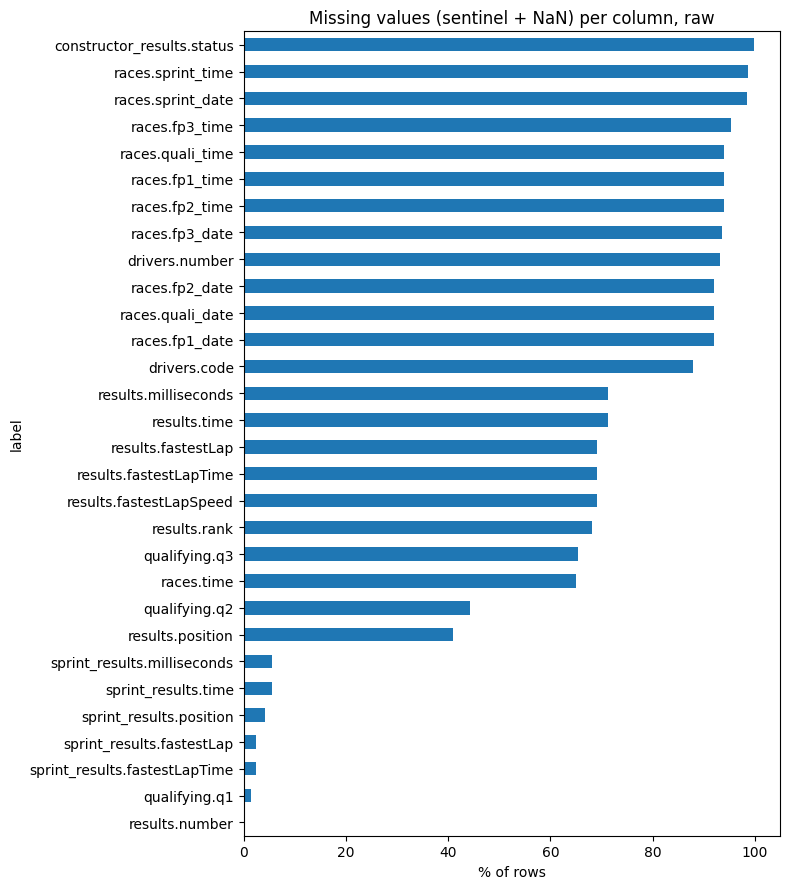

In [249]:
# 1) Missing % per column, for the columns that have any missing values
miss = pd.concat({n: r["missing_pct"] for n, r in before_cols.items()}).rename("pct").reset_index()
miss.columns = ["table", "column", "pct"]
miss = miss[miss.pct > 0].sort_values("pct")
miss["label"] = miss.table + "." + miss.column
miss.plot(kind="barh", x="label", y="pct", figsize=(8, max(3, 0.3 * len(miss))),
          legend=False, title="Missing values (sentinel + NaN) per column, raw")
plt.xlabel("% of rows"); plt.tight_layout(); plt.show()

## 2.7 Target Distribution & Race Diagnostics 
Visualizing core project metrics: the target class balance (Podium vs. Non-Podium), grid starting positions, average field size over time, and testing for duplicate race-driver combinations.

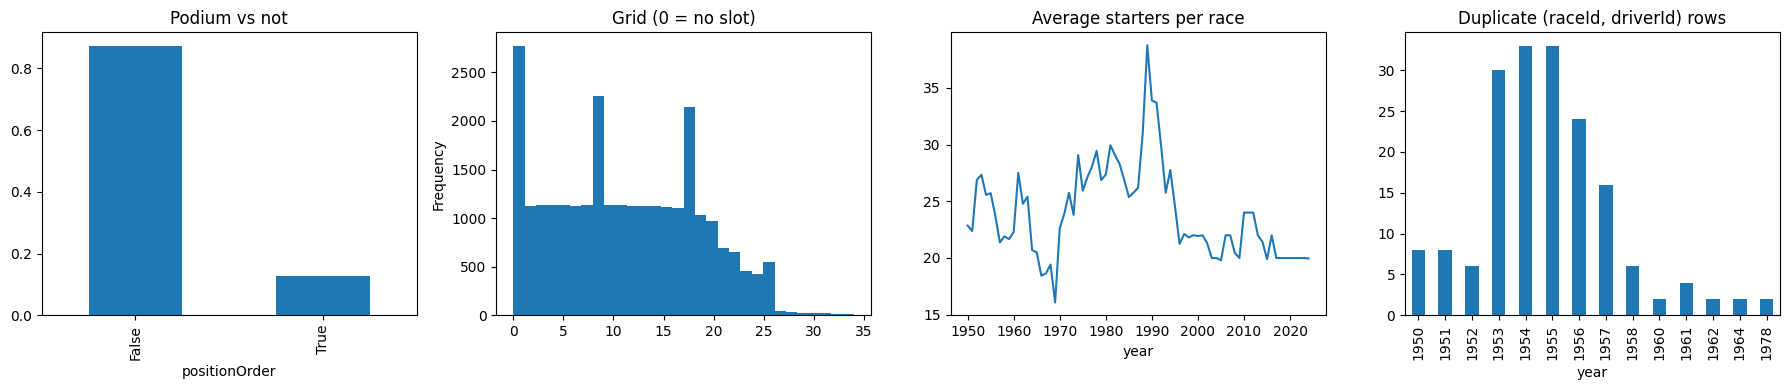

In [250]:
# 3) Target balance, grid==0, field size, and duplicate driver-race rows by season
res = raw["results"].merge(raw["races"][["raceId", "year"]], on="raceId")
res["positionOrder"] = pd.to_numeric(res["positionOrder"], errors="coerce")
res["grid"] = pd.to_numeric(res["grid"], errors="coerce")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
(res["positionOrder"] <= 3).value_counts(normalize=True).plot(
    kind="bar", ax=axes[0], title="Podium vs not")
res["grid"].plot(kind="hist", bins=30, ax=axes[1], title="Grid (0 = no slot)")
res.groupby(["year", "raceId"]).size().groupby("year").mean().plot(
    ax=axes[2], title="Average starters per race")
dup = res[res.duplicated(["raceId", "driverId"], keep=False)]
dup.groupby("year").size().plot(kind="bar", ax=axes[3], title="Duplicate (raceId, driverId) rows")
plt.tight_layout(); plt.show()

## 2.8 Semantic Typing & Sentinel Detection
Scanning for columns that should be processed as numbers, dates, or durations but are currently loaded as strings due to `\N` sentinel values. This establishes the required data-type casting for the cleaning pipeline.

In [251]:
# 4) Columns that should be numbers/dates/durations but are stored as text.
#    This is the evidence for semantic typing in the cleaning step.
text_numeric = {}
for n, df in raw.items():
    for c in df.select_dtypes("object").columns:
        sample = df[c][df[c] != r"\N"].dropna().head(200)
        if len(sample) and pd.to_numeric(sample, errors="coerce").notna().mean() > 0.9:
            text_numeric.setdefault(n, []).append(c)
print("Numeric columns stored as text (because of \\N):", text_numeric)

for n in ["results", "qualifying", "lap_times", "pit_stops"]:
    print(f"\n=== {n} ===")
    display(numeric_summary(raw[n]))

Numeric columns stored as text (because of \N): {'constructor_standings': ['positionText'], 'driver_standings': ['positionText'], 'drivers': ['number'], 'pit_stops': ['duration'], 'results': ['number', 'position', 'milliseconds', 'fastestLap', 'rank', 'fastestLapSpeed'], 'sprint_results': ['position', 'positionText', 'milliseconds', 'fastestLap']}

=== results ===


,count,mean,std,min,max
resultId,26759.0,13380.977391,7726.134642,1.0,26764.0
raceId,26759.0,551.687283,313.265036,1.0,1144.0
driverId,26759.0,278.673530,282.703039,1.0,862.0
constructorId,26759.0,50.180537,61.551498,1.0,215.0
number,26753.0,18.153927,15.581135,0.0,208.0
grid,26759.0,11.134796,7.202860,0.0,34.0
position,15806.0,8.020499,4.840796,1.0,33.0
positionText,15808.0,8.021065,4.840781,1.0,33.0
positionOrder,26759.0,12.794051,7.665951,1.0,39.0
points,26759.0,1.987632,4.351209,0.0,50.0



=== qualifying ===


,count,mean,std,min,max
qualifyId,10494.0,5262.482847,3046.588486,1.0,10551.0
raceId,10494.0,624.600915,428.298147,1.0,1144.0
driverId,10494.0,343.002287,389.586448,1.0,862.0
constructorId,10494.0,47.918430,73.217993,1.0,215.0
number,10494.0,18.786449,18.447502,0.0,99.0
position,10494.0,11.195826,6.260374,1.0,28.0



=== lap_times ===


,count,mean,std,min,max
raceId,589081.0,600.544465,434.375976,1.0,1144.0
driverId,589081.0,325.796446,387.561736,1.0,862.0
lap,589081.0,30.018104,18.407126,1.0,87.0
position,589081.0,9.661951,5.528553,1.0,24.0
milliseconds,589081.0,95799.445243,76399.729955,55404.0,7507547.0



=== pit_stops ===


,count,mean,std,min,max
raceId,11371.0,981.194882,92.326831,841.000,1144.000
driverId,11371.0,549.734500,383.734981,1.000,862.000
stop,11371.0,1.787969,1.521462,1.000,70.000
lap,11371.0,25.387389,14.831497,1.000,78.000
duration,10854.0,24.448585,4.606013,12.897,59.555
milliseconds,11371.0,85230.495559,310427.261089,12897.000,3069017.000


# 3. Data Cleaning & Auditing

## 3.1 circuits.csv

Each row represents one circuit. `circuitId` is the primary key; `circuitRef` is its external identifier. `races.circuitId` connects races to these circuits. There are no dates or durations to convert in this table.

We will check missing values, repeated records, identifiers, coordinates and the connection to `races`. We will then compare the original table with `circuits_clean`. Cleaning keeps the same columns and uses a copy; it does not overwrite the raw table.



###  3.1.1 Circuits: Initial Auditing
Creating an immutable baseline of the raw `circuits` data and running quality diagnostics to flag missing values, `\N` sentinels, geographic coordinate anomalies, and orphaned relational keys.

In [252]:
circuits_raw_snapshot = circuits.copy(deep=True)
print("Rows:", len(circuits), "| Columns:", len(circuits.columns))
display(circuits.head())
circuits.info()


Rows: 77 | Columns: 9


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [253]:
# Count actual missing values, placeholders, empty text and extra spaces.
def circuits_column_audit(table):
    text = table.astype("string")
    return pd.DataFrame({
        "Data type": table.dtypes.astype(str),
        "Missing": table.isna().sum(),
        "Literal \\N": text.eq(r"\N").sum(),
        "Empty / blank text": text.apply(lambda col: col.str.strip().eq("")).sum(),
        "Extra outer spaces": text.ne(text.apply(lambda col: col.str.strip())).sum()
    })

circuits_before_summary = circuits_column_audit(circuits)
display(circuits_before_summary)


,Data type,Missing,Literal \N,Empty / blank text,Extra outer spaces
circuitId,int64,0,0,0,0
circuitRef,object,0,0,0,0
name,object,0,0,0,0
location,object,0,0,0,0
country,object,0,0,0,0
lat,float64,0,0,0,0
lng,float64,0,0,0,0
alt,int64,0,0,0,0
url,object,0,0,0,0


### 3.1.2 Check records and the connection to races

A repeated country is expected: several circuits can be in one country. A repeated `circuitId` needs investigation because it identifies one circuit.

We also check every circuit ID in `races`. A missing match could cause a race to lose its circuit information during a merge. Latitude must be between −90 and 90; longitude must be between −180 and 180. These limits check whether coordinates are possible, rather than proving that each coordinate is exactly correct.


In [254]:
def circuits_quality_audit(table):
    lat = pd.to_numeric(table["lat"], errors="coerce")
    lng = pd.to_numeric(table["lng"], errors="coerce")
    geographic_values = table[["lat", "lng", "alt"]].apply(pd.to_numeric, errors="coerce")
    return pd.Series({
        "Rows": len(table),
        "Columns": len(table.columns),
        "Duplicate complete rows": table.duplicated().sum(),
        "Missing circuit IDs": table["circuitId"].isna().sum(),
        "Duplicate circuit IDs": table["circuitId"].duplicated().sum(),
        "Missing circuit references": table["circuitRef"].isna().sum(),
        "Duplicate circuit references": table["circuitRef"].duplicated().sum(),
        "Missing URLs": table["url"].isna().sum(),
        "Duplicate URLs": table["url"].duplicated().sum(),
        "Missing / nonnumeric / infinite geographic values": (~np.isfinite(geographic_values)).sum().sum(),
        "Latitude outside valid range": (~lat.between(-90, 90)).sum(),
        "Longitude outside valid range": (~lng.between(-180, 180)).sum(),
        "Races without a matching circuit": (~races["circuitId"].isin(table["circuitId"])).sum(),
        "Circuits not referenced by races": (~table["circuitId"].isin(races["circuitId"])).sum()
    })

circuits_before_checks = circuits_quality_audit(circuits)
display(circuits_before_checks.to_frame("Before cleaning"))


,Before cleaning
Rows,77
Columns,9
Duplicate complete rows,0
Missing circuit IDs,0
Duplicate circuit IDs,0
Missing circuit references,0
Duplicate circuit references,0
Missing URLs,0
Duplicate URLs,0
Missing / nonnumeric / infinite geographic values,0


### Explain the country-label change before applying it

`USA` and `United States` describe the same country. We checked the reference URLs stored in the records below: the Circuit of the Americas reference locates the track in Austin, Texas, United States; the Las Vegas reference describes the race in Nevada, United States.

Sources from the CSV: [Circuit of the Americas](https://en.wikipedia.org/wiki/Circuit_of_the_Americas) and [Las Vegas Grand Prix](https://en.wikipedia.org/wiki/Las_Vegas_Grand_Prix#Circuit).

We use `United States` consistently so a country-level count does not split one country into two groups. Neither spelling identifies an incorrect country. There is no country ID in these CSVs: the references support this decision, while the before/after counts only show its effect.

The circuits remain separate records with their original IDs, names and locations. The historical Las Vegas circuit has a URL that redirects to the modern event page; that redirect is not evidence that the two tracks are identical.


In [255]:
display(circuits.loc[
    circuits["circuitId"].isin([69, 80]),
    ["circuitId", "name", "location", "country", "url"]
])


,circuitId,name,location,country,url
22,80,Las Vegas Strip Street Circuit,Las Vegas,United States,https://en.wikipedia.org/wiki/Las_Vegas_Grand_...
68,69,Circuit of the Americas,Austin,USA,http://en.wikipedia.org/wiki/Circuit_of_the_Am...


### 3.1.3 — Clean a copy using the existing columns

We standardize the country label, recognize `\N` and blank text as missing, remove outer spaces from text, and check that the geographic columns are numeric. The text and missing-value steps are precautions; the original audit shows whether they actually change anything. Conversion uses `errors="raise"` so an unexpected value produces a visible error instead of silently becoming missing.

There are no missing values in the current circuits file, so there is nothing to fill. No new columns are added to `circuits_clean`.


In [256]:
circuits_clean = circuits.copy(deep=True).replace(r"\N", np.nan)

for column in circuits_clean.select_dtypes(include="object").columns:
    circuits_clean[column] = circuits_clean[column].str.strip().replace("", np.nan)

circuits_clean["country"] = circuits_clean["country"].replace({"USA": "United States"})

for column in ["lat", "lng", "alt"]:
    circuits_clean[column] = pd.to_numeric(circuits_clean[column], errors="raise")


### 3.1.4 Circuits: Validation & Analysis
Verifying the transformations through side-by-side audits, visualizing the consolidated country distributions, and using strict assertion tests to guarantee zero unintended data loss before proceeding.

The first comparison checks every column. The second shows the specific records whose country label changed. The plot compares country counts before and after; it shows the effect of standardization, rather than providing the reason for it.


In [257]:
circuits_after_summary = circuits_column_audit(circuits_clean)
display(pd.concat({"Before": circuits_before_summary, "After": circuits_after_summary}, axis=1))

changed_countries = circuits["country"].fillna("<MISSING>").ne(
    circuits_clean["country"].fillna("<MISSING>")
)
circuits_country_changes = circuits.loc[changed_countries, ["circuitId", "name", "country"]].copy()
circuits_country_changes = circuits_country_changes.rename(columns={"country": "Country before"})
circuits_country_changes["Country after"] = circuits_clean.loc[changed_countries, "country"]
display(circuits_country_changes)
print("Country labels changed:", changed_countries.sum())


Before                                                              After                                                         
           Data type Missing Literal \N Empty / blank text Extra outer spaces Data type Missing Literal \N Empty / blank text Extra outer spaces
circuitId      int64       0          0                  0                  0     int64       0          0                  0                  0
circuitRef    object       0          0                  0                  0    object       0          0                  0                  0
name          object       0          0                  0                  0    object       0          0                  0                  0
location      object       0          0                  0                  0    object       0          0                  0                  0
country       object       0          0                  0                  0    object       0          0                  0                  0
lat          float64       0          0                  0                  0   float64       0          0                  0                  0
lng          float64       0          0                  0                  0   float64       0          0                  0                  0
alt            int64       0          0                  0                  0     int64       0          0                  0                  0
url           object       0          0                  0                  0    object       0          0                  0                  0

,circuitId,name,Country before,Country after
18,19,Indianapolis Motor Speedway,USA,United States
32,33,Phoenix street circuit,USA,United States
36,37,Detroit Street Circuit,USA,United States
41,42,Fair Park,USA,United States
42,43,Long Beach,USA,United States
43,44,Las Vegas Street Circuit,USA,United States
45,46,Watkins Glen,USA,United States
59,60,Riverside International Raceway,USA,United States
62,63,Sebring International Raceway,USA,United States
68,69,Circuit of the Americas,USA,United States


Country labels changed: 11


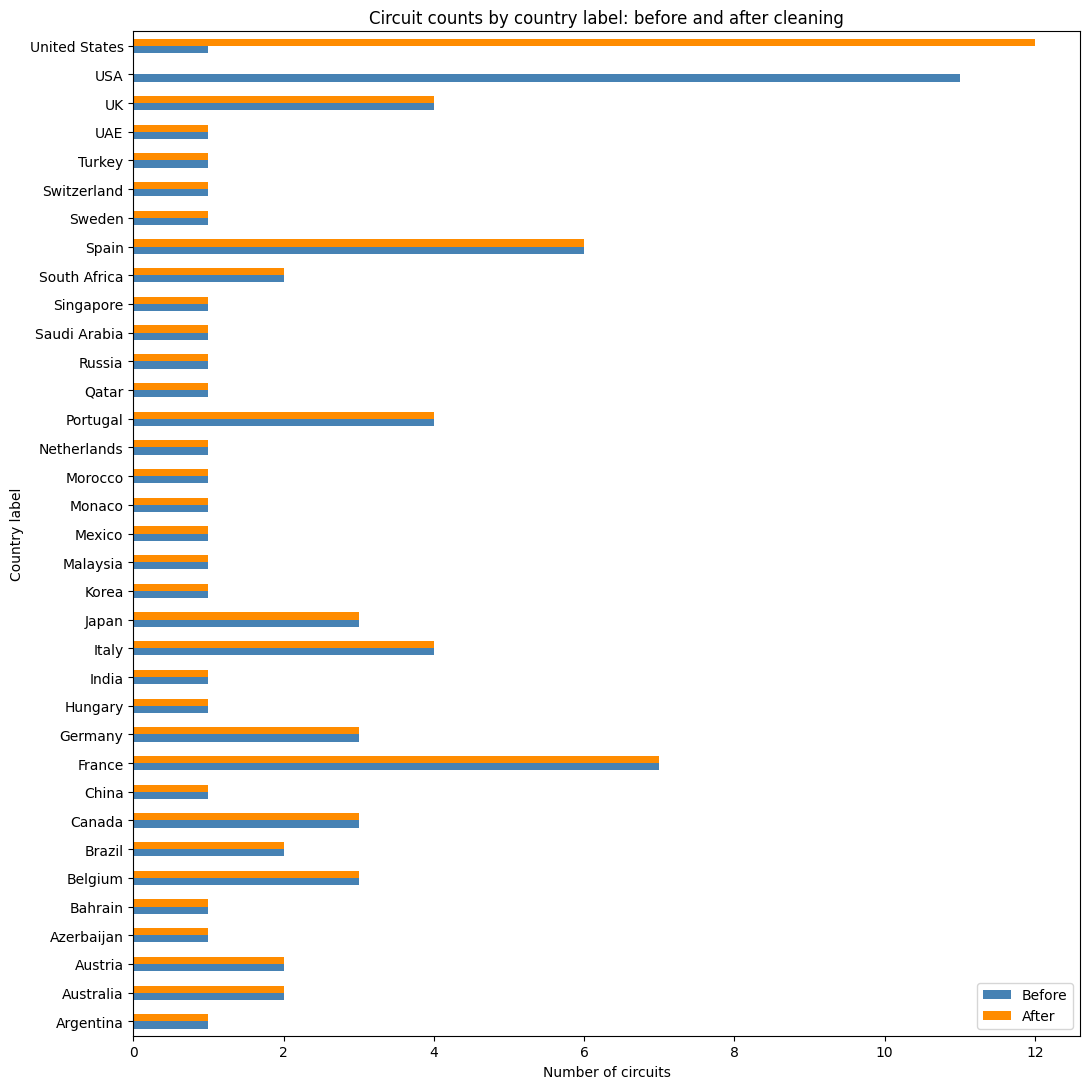

In [258]:
circuits_country_counts = pd.concat({
    "Before": circuits["country"].value_counts(),
    "After": circuits_clean["country"].value_counts()
}, axis=1).fillna(0).astype(int).sort_index()

circuits_country_counts.plot.barh(figsize=(11, 11), color=["steelblue", "darkorange"])
plt.title("Circuit counts by country label: before and after cleaning")
plt.xlabel("Number of circuits")
plt.ylabel("Country label")
plt.tight_layout()
plt.show()


In [259]:
# Compare numeric distributions and display the lowest/highest altitudes.
display(pd.concat({
    "Before": circuits[["lat", "lng", "alt"]].describe(),
    "After": circuits_clean[["lat", "lng", "alt"]].describe()
}, axis=1))

circuits_altitude_examples = pd.concat([
    circuits_clean.nsmallest(3, "alt"),
    circuits_clean.nlargest(3, "alt")
]).drop_duplicates("circuitId")
display(circuits_altitude_examples[["circuitId", "name", "country", "alt"]])


Before                               After                         
             lat         lng          alt        lat         lng          alt
count  77.000000   77.000000    77.000000  77.000000   77.000000    77.000000
mean   33.442925    1.076683   247.012987  33.442925    1.076683   247.012987
std    22.808866   65.516951   362.738469  22.808866   65.516951   362.738469
min   -37.849700 -118.189000    -7.000000 -37.849700 -118.189000    -7.000000
25%    32.777400   -9.394170    18.000000  32.777400   -9.394170    18.000000
50%    40.951700    3.930830   129.000000  40.951700    3.930830   129.000000
75%    46.958900   19.248600   332.000000  46.958900   19.248600   332.000000
max    57.265300  144.968000  2227.000000  57.265300  144.968000  2227.000000

,circuitId,name,country,alt
71,73,Baku City Circuit,Azerbaijan,-7
34,35,Korean International Circuit,Korea,0
76,79,Miami International Autodrome,United States,0
31,32,Autódromo Hermanos Rodríguez,Mexico,2227
29,30,Kyalami,South Africa,1460
35,36,Autódromo Internacional Nelson Piquet,Brazil,1126


### Step 6 — Verify the clean table and a safe merge

The checks should show 77 rows and 9 columns before and after, no missing data, no duplicate identifiers, and no races without a matching circuit. We validate a many-to-one merge: many races may use one circuit, but each race must match only one circuit row. The merge is a separate audit variable and adds no columns to `circuits_clean`.

We keep all records because the duplicate and key checks found no records that need removal. We keep the geographic numbers because these checks found no missing, nonnumeric, infinite or out-of-range coordinates. A low, negative or high altitude alone does not establish an error, so we do not replace it with an average or delete the circuit. The altitude examples are a review aid; exact geographical accuracy, including each altitude, has not been verified against independent sources.


In [260]:
circuits_after_checks = circuits_quality_audit(circuits_clean)
display(pd.DataFrame({"Before": circuits_before_checks, "After": circuits_after_checks}))

circuits_race_audit = races[["raceId", "circuitId"]].merge(
    circuits_clean[["circuitId", "name", "country"]],
    on="circuitId", how="left", validate="many_to_one", indicator=True
)
print("Races checked:", len(circuits_race_audit))
print("Unmatched races:", circuits_race_audit["_merge"].ne("both").sum())
display(circuits_race_audit.drop(columns="_merge").head())

assert circuits_after_checks.drop(["Rows", "Columns"]).eq(0).all()
assert len(circuits_clean) == len(circuits)
assert circuits_clean.columns.equals(circuits.columns)
assert circuits_after_summary.drop(columns="Data type").eq(0).all().all()
assert len(circuits_race_audit) == len(races)
assert circuits_race_audit["_merge"].eq("both").all()
pd.testing.assert_frame_equal(circuits, circuits_raw_snapshot)
pd.testing.assert_frame_equal(circuits.drop(columns="country"), circuits_clean.drop(columns="country"))
pd.testing.assert_series_equal(
    circuits_clean["country"], circuits["country"].replace({"USA": "United States"})
)
print("Passed: only country labels changed; raw data, other values, rows and columns are preserved.")
circuits_clean.info()


,Before,After
Rows,77,77
Columns,9,9
Duplicate complete rows,0,0
Missing circuit IDs,0,0
Duplicate circuit IDs,0,0
Missing circuit references,0,0
Duplicate circuit references,0,0
Missing URLs,0,0
Duplicate URLs,0,0
Missing / nonnumeric / infinite geographic values,0,0


Races checked: 1125
Unmatched races: 0


,raceId,circuitId,name,country
0,1,1,Albert Park Grand Prix Circuit,Australia
1,2,2,Sepang International Circuit,Malaysia
2,3,17,Shanghai International Circuit,China
3,4,3,Bahrain International Circuit,Bahrain
4,5,4,Circuit de Barcelona-Catalunya,Spain


Passed: only country labels changed; raw data, other values, rows and columns are preserved.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


### Circuits findings and decisions

- **Missing data:** no missing cells, `\N` placeholders or blank text were found, so no filling is needed.
- **Country labels:** 11 `USA` labels become `United States`, supported by the circuit references. The original 11 `USA` records and 1 `United States` record now form one group of 12 circuits. Before/after tables and a plot show this effect; all 77 circuit records remain.
- **Duplicates and relationships:** no repeated circuit IDs or circuit references were found. Every race matches one circuit, so no circuit or race records are removed.
- **Data types:** the geographic columns were already numeric. There are no date or duration columns to convert here.
- **Geographic values:** numeric checks and before/after summaries pass. We preserve values rather than make unsupported geographical corrections; the checks do not certify every coordinate or altitude.
- **Preservation:** `circuits_clean` has the same rows and columns as `circuits`; raw data and every non-country column are checked for equality.

This completes the circuits section's missing-value, type, duplicate, key and race-link checks. Other tables are reviewed separately.


## 3.2 constructor_results.csv

One row records a constructor result for a race. The primary key is `constructorResultsId`; `(raceId, constructorId)` should also be unique. There are no dates or durations to convert. Current-race points and status are post-race information and must not be model inputs for that same race.

### Step 1 — Inspect missing values before cleaning

This review handles the empty `status` values. The separate investigation of extra or missing team-result records will be handled later; this step removes no rows.


### 3.2.1 Constructor Results: Initial Auditing & Status Evaluation
Creating an immutable baseline of the raw `constructor_results` data. This phase audits structural missing values and cross-references driver outcomes to investigate undocumented empty `status` flags (e.g., distinguishing between standard finishes and disqualifications).

In [261]:
constructor_results_raw_snapshot = constructor_results.copy(deep=True)
print("Rows:", len(constructor_results), "| Columns:", len(constructor_results.columns))
display(constructor_results.head())
constructor_results.info()


Rows: 12625 | Columns: 5


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [262]:
constructor_results_before_summary = pd.DataFrame({
    "Data type": constructor_results.dtypes.astype(str),
    "Recognized missing": constructor_results.isna().sum(),
    "Placeholders": constructor_results.eq(r"\N").sum(),
    "Empty / blank text": constructor_results.astype("string").apply(
        lambda column: column.str.strip().eq("")
    ).sum()
})
display(constructor_results_before_summary)

# Recognize all forms of empty status without changing the raw table.
constructor_status_before = (
    constructor_results["status"].astype("string").str.strip()
    .replace({r"\N": pd.NA, "": pd.NA})
)
assert constructor_status_before.dropna().isin(["D"]).all(), "Investigate unexpected status codes."

print("Empty status records:", constructor_status_before.isna().sum())
print("Empty status (%):", round(constructor_status_before.isna().mean() * 100, 2))
display(constructor_status_before.fillna("Empty").value_counts().to_frame("Constructor-result rows"))


,Data type,Recognized missing,Placeholders,Empty / blank text
constructorResultsId,int64,0,0,0
raceId,int64,0,0,0
constructorId,int64,0,0,0
points,float64,0,0,0
status,object,0,12608,0


Empty status records: 12608
Empty status (%): 99.87


,Constructor-result rows
status,
Empty,12608
D,17


### Step 2 — Find out what an empty constructor status means

The original **Ergast Database User Guide**, by Chris Newell, defines `constructor_results.status` as **"D" for disqualified (or null)**. See the `constructor_results table` section in the [guide mirror](https://ru.scribd.com/document/729031114/f1db-user-guide).

This is a constructor disqualification flag, not a driver's race outcome. We check the related driver results below. The join uses both `raceId` and `constructorId`, so a team is compared with its drivers in the same race.

The chart counts **driver-result rows linked to blank constructor flags**. Its total differs from the constructor-row total because a constructor can have several drivers. It is a descriptive audit of the source records, not a deduplicated modeling table.


,Constructor-result rows
Driver-result match,
both,12601
left_only,7
right_only,0


,Driver-result rows
Driver outcome,
Numbered position,14969
Retired,8164
Failed to qualify,1345
Withdrew,301
Not classified,181
Driver disqualified,145
Driver excluded,9


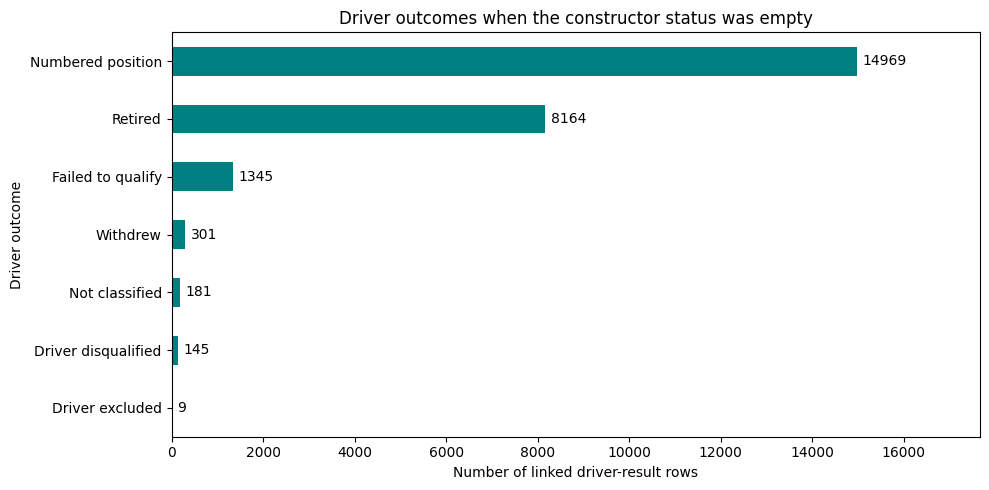

In [263]:
constructor_blank_keys = constructor_results.loc[
    constructor_status_before.isna(), ["raceId", "constructorId"]
]

# Check coverage first: a missing driver match does not prove anything about participation.
constructor_status_coverage = constructor_blank_keys.merge(
    results[["raceId", "constructorId"]].drop_duplicates(),
    on=["raceId", "constructorId"], how="left", validate="one_to_one", indicator=True
)
display(constructor_status_coverage["_merge"].value_counts().rename_axis("Driver-result match").to_frame("Constructor-result rows"))

constructor_blank_driver_results = results[
    ["raceId", "constructorId", "driverId", "positionText", "statusId"]
].merge(constructor_blank_keys, on=["raceId", "constructorId"], validate="many_to_one")

# These codes belong to driver positionText, not constructor status.
driver_outcome_names = {
    "R": "Retired", "F": "Failed to qualify", "W": "Withdrew",
    "D": "Driver disqualified", "E": "Driver excluded", "N": "Not classified"
}
constructor_blank_driver_results["Driver outcome"] = (
    constructor_blank_driver_results["positionText"].map(driver_outcome_names)
)
numbered_position = pd.to_numeric(
    constructor_blank_driver_results["positionText"], errors="coerce"
).notna()
constructor_blank_driver_results.loc[numbered_position, "Driver outcome"] = "Numbered position"
assert constructor_blank_driver_results["Driver outcome"].notna().all(), "Investigate an unfamiliar driver outcome."

constructor_blank_outcomes = constructor_blank_driver_results["Driver outcome"].value_counts()
display(constructor_blank_outcomes.to_frame("Driver-result rows"))

ax = constructor_blank_outcomes.sort_values().plot.barh(figsize=(10, 5), color="teal")
ax.bar_label(ax.containers[0], padding=4)
ax.set_xlim(0, constructor_blank_outcomes.max() * 1.18)
ax.set_title("Driver outcomes when the constructor status was empty")
ax.set_xlabel("Number of linked driver-result rows")
ax.set_ylabel("Driver outcome")
plt.tight_layout()
plt.show()


In [264]:
# Show readable examples from the most recent records in each outcome group.
constructor_status_examples = (
    constructor_blank_driver_results
    .merge(races[["raceId", "year", "name"]].rename(columns={"name": "Race"}), on="raceId", validate="many_to_one")
    .merge(constructors[["constructorId", "name"]].rename(columns={"name": "Constructor"}), on="constructorId", validate="many_to_one")
    .merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
    .merge(status.rename(columns={"status": "Driver status"}), on="statusId", validate="many_to_one")
    .sort_values(["year", "raceId"])
    .groupby("Driver outcome", sort=False).tail(1)
)
display(constructor_status_examples[
    ["raceId", "year", "Race", "Constructor", "forename", "surname", "Driver outcome", "Driver status"]
])

# Investigate the D flags separately, using the race and team reference tables.
constructor_d_evidence = (
    constructor_results.loc[constructor_status_before.eq("D").fillna(False)]
    .merge(races[["raceId", "year"]], on="raceId", validate="many_to_one")
    .merge(constructors[["constructorId", "name"]], on="constructorId", validate="many_to_one")
)
display(constructor_d_evidence.groupby(["year", "name", "status"]).size().to_frame("Constructor-result rows"))


,raceId,year,Race,Constructor,forename,surname,Driver outcome,Driver status
21891,841,2011,Australian Grand Prix,HRT,Narain,Karthikeyan,Failed to qualify,Did not qualify
20496,900,2014,Australian Grand Prix,Marussia,Jules,Bianchi,Not classified,+8 Laps
21247,944,2015,Brazilian Grand Prix,Williams,Felipe,Massa,Driver excluded,Excluded
25052,1141,2024,São Paulo Grand Prix,Aston Martin,Lance,Stroll,Withdrew,Withdrew
25053,1141,2024,São Paulo Grand Prix,Haas F1 Team,Nico,Hülkenberg,Driver disqualified,Disqualified
25110,1144,2024,Abu Dhabi Grand Prix,RB F1 Team,Liam,Lawson,Numbered position,Engine
25113,1144,2024,Abu Dhabi Grand Prix,Red Bull,Sergio,Pérez,Retired,Collision


,,,Constructor-result rows
year,name,status,
2007,McLaren,D,17


### What the evidence tells us

- Blank constructor flags coexist with numbered driver positions, retirements, failures to qualify, withdrawals and driver disqualifications. Therefore, we cannot fill blanks with `Q`, `Finished`, or a claim that no driver was disqualified.
- All 17 recorded constructor `D` flags belong to McLaren in 2007. The [official 2007 team standings](https://www.formula1.com/en/results/2007/team) show McLaren excluded with zero championship points. This supports the interpretation of the constructor flag; it does not make every driver result a disqualification.
- Seven blank constructor-result records have no matching race–constructor pair in `results`. They remain visible in the coverage count and need a separate record-consistency review. The driver-outcome chart makes no claim about those unmatched records.

### Step 3 — Assign an explicit label in the existing clean column

We use **`ND` = No constructor disqualification flag recorded**. It is our descriptive cleaning code for the source's empty value, not an original Ergast code. It does not mean qualified, finished, or independently verified as free of every penalty.

We keep existing `D` values and fill only empty flags. This is a categorical relabeling supported by the source definition, rather than estimating missing facts with a mean or median. The raw table and the other columns remain unchanged.


### 3.2.2 Constructor Results: Cleaning Pipeline & Integrity Checks
Executing transformations to standardize the dataset: replacing `\N` placeholders, casting `points` to numeric types, and mapping empty status flags to "ND" (Not Disqualified) while preserving "D" flags. Includes strict assertions to guarantee primary key uniqueness and valid foreign key mappings.

In [265]:
constructor_results_clean = constructor_results.copy(deep=True).replace(r"\N", np.nan)
constructor_results_clean["points"] = pd.to_numeric(constructor_results_clean["points"], errors="raise")

# Keep the same status column; preserve D and label empty flags as ND.
constructor_results_clean["status"] = constructor_status_before.fillna("ND")
display(constructor_results_clean.head())


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,ND
1,2,18,2,8.0,ND
2,3,18,3,9.0,ND
3,4,18,4,5.0,ND
4,5,18,5,2.0,ND


### Step 4 — Compare before and after

The missing-value comparison combines recognized nulls, literal `\N` and blank text, so the original placeholders are counted as unavailable values even before pandas recognizes them as nulls. The plots show whether the 12,608 empty flags become `ND` and whether the 17 `D` flags are preserved. These counts demonstrate the effect; the source definition and cross-table investigation above justify the label.


,Missing BEFORE,Missing AFTER,Data type BEFORE,Data type AFTER
constructorResultsId,0,0,int64,int64
raceId,0,0,int64,int64
constructorId,0,0,int64,int64
points,0,0,float64,float64
status,12608,0,object,string


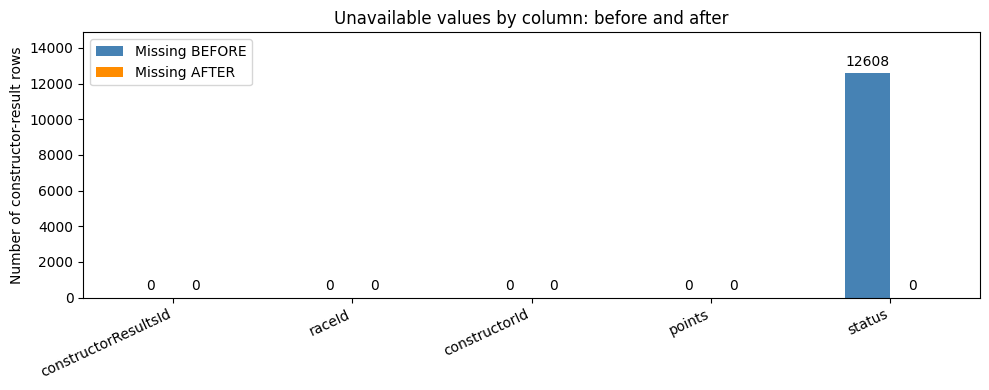

In [266]:
constructor_results_missing_before = (
    constructor_results.astype("string").apply(lambda column: column.str.strip())
    .replace({r"\N": pd.NA, "": pd.NA}).isna().sum()
)
constructor_results_comparison = pd.DataFrame({
    "Missing BEFORE": constructor_results_missing_before,
    "Missing AFTER": constructor_results_clean.isna().sum(),
    "Data type BEFORE": constructor_results.dtypes.astype(str),
    "Data type AFTER": constructor_results_clean.dtypes.astype(str)
})
display(constructor_results_comparison)

ax = constructor_results_comparison[["Missing BEFORE", "Missing AFTER"]].plot.bar(
    figsize=(10, 4), color=["steelblue", "darkorange"]
)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set_ylim(0, max(constructor_results_missing_before.max(), 1) * 1.18)
ax.set_title("Unavailable values by column: before and after")
ax.set_ylabel("Number of constructor-result rows")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


,Before,After
status,,
Empty,12608,0
ND,0,12608
D,17,17


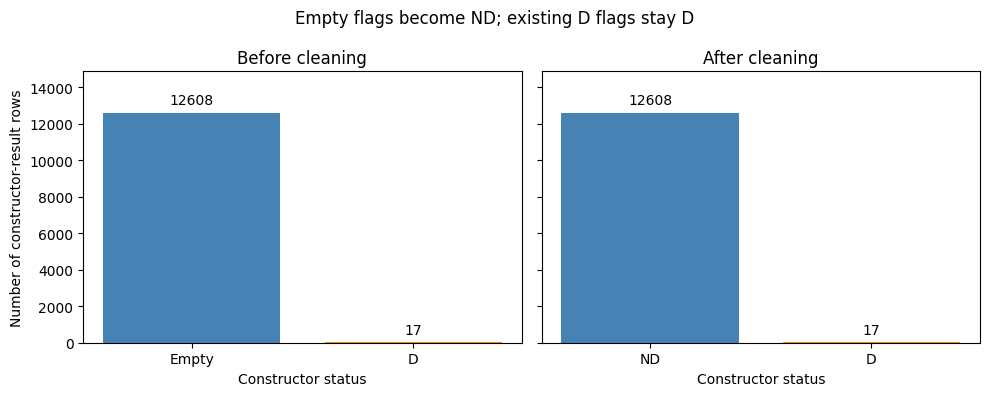

,constructorResultsId,raceId,constructorId,Status BEFORE,Status AFTER
0,1,18,1,\N,ND
1,2,18,2,\N,ND
2,3,18,3,\N,ND
3,4,18,4,\N,ND
4,5,18,5,\N,ND


In [267]:
constructor_status_counts = pd.DataFrame({
    "Before": constructor_status_before.fillna("Empty").value_counts(),
    "After": constructor_results_clean["status"].value_counts()
}).reindex(["Empty", "ND", "D"]).fillna(0).astype(int)
display(constructor_status_counts)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, stage, labels in zip(axes, ["Before", "After"], [["Empty", "D"], ["ND", "D"]]):
    counts = constructor_status_counts.loc[labels, stage]
    bars = ax.bar(counts.index, counts.values, color=["steelblue", "darkorange"])
    ax.bar_label(bars, padding=4)
    ax.set_title(stage + " cleaning")
    ax.set_ylim(0, max(constructor_status_counts.max().max(), 1) * 1.18)
    ax.set_xlabel("Constructor status")
axes[0].set_ylabel("Number of constructor-result rows")
fig.suptitle("Empty flags become ND; existing D flags stay D")
plt.tight_layout()
plt.show()

# Show the actual existing column for a few changed records.
constructor_status_changes = constructor_results.loc[
    constructor_status_before.isna(), ["constructorResultsId", "raceId", "constructorId", "status"]
].head().rename(columns={"status": "Status BEFORE"})
constructor_status_changes["Status AFTER"] = constructor_results_clean.loc[constructor_status_changes.index, "status"]
display(constructor_status_changes)


In [268]:
display(constructor_results_clean["status"].value_counts(dropna=False).to_frame("Constructor-result rows"))

# D flags only: after filling, notna() would select every row, including ND.
display(constructor_results_clean.loc[constructor_results_clean["status"].eq("D")])


,Constructor-result rows
status,
ND,12608
D,17


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


### Step 5 — Check preservation, keys and references

The checks below ensure that each original empty status becomes `ND`, each `D` remains `D`, and no rows or columns are added or removed. Primary-key and foreign-key checks are retained, but passing them alone does not resolve the separate extra/missing-record investigation.


In [269]:
# Check the record ID.
record_id = "constructorResultsId"

print("Missing constructorResultsId:",
      constructor_results_clean[record_id].isna().sum())

print("Duplicate constructorResultsId:",
      constructor_results_clean[record_id].duplicated().sum())

assert constructor_results_clean[record_id].notna().all(), \
    "Missing constructorResultsId found"

assert constructor_results_clean[record_id].is_unique, \
    "Duplicate constructorResultsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "constructorId"]

print("\nMissing race and constructor IDs:")
display(constructor_results_clean[pair_columns].isna().sum())

print("Duplicate race–constructor pairs:",
      constructor_results_clean.duplicated(pair_columns).sum())

assert constructor_results_clean[pair_columns].notna().all().all(), \
    "Missing raceId or constructorId found"

assert not constructor_results_clean.duplicated(pair_columns).any(), \
    "Duplicate race–constructor pairs found"

print("\nPassed: record IDs and race–constructor pairs are unique and non-null.")

Missing constructorResultsId: 0
Duplicate constructorResultsId: 0

Missing race and constructor IDs:


raceId           0
constructorId    0
dtype: int64

Duplicate race–constructor pairs: 0

Passed: record IDs and race–constructor pairs are unique and non-null.


In [270]:
# Find rows with missing or unknown race IDs.
invalid_races = constructor_results_clean[
    constructor_results_clean["raceId"].isna()
    | ~constructor_results_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_constructors = constructor_results_clean[
    constructor_results_clean["constructorId"].isna()
    | ~constructor_results_clean["constructorId"].isin(
        constructors["constructorId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown constructor IDs:", len(invalid_constructors))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_constructors.empty:
    display(invalid_constructors)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_constructors.empty, \
    "Some constructor IDs are missing or absent from constructors"

print("Passed: all race and constructor IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown constructor IDs: 0
Passed: all race and constructor IDs exist in their reference tables.


In [271]:
constructor_results_checks = pd.Series({
    "Rows unchanged": len(constructor_results_clean) == len(constructor_results),
    "Columns unchanged": constructor_results_clean.columns.equals(constructor_results.columns),
    "No placeholders remain": not constructor_results_clean.eq(r"\N").any().any(),
    "No duplicate complete rows": not constructor_results_clean.duplicated().any(),
    "No missing status values": constructor_results_clean["status"].notna().all(),
    "Only D and ND status labels": constructor_results_clean["status"].isin(["D", "ND"]).all(),
    "Every empty status becomes ND": constructor_results_clean.loc[constructor_status_before.isna(), "status"].eq("ND").all(),
    "Every D flag stays D": constructor_results_clean.loc[constructor_status_before.eq("D").fillna(False), "status"].eq("D").all(),
    "ND count equals original empty count": constructor_results_clean["status"].eq("ND").sum() == constructor_status_before.isna().sum(),
    "D count unchanged": constructor_results_clean["status"].eq("D").sum() == constructor_status_before.eq("D").sum(),
    "Points are numeric": pd.api.types.is_numeric_dtype(constructor_results_clean["points"]),
    "Points non-negative": constructor_results_clean["points"].dropna().ge(0).all()
})
display(constructor_results_checks.to_frame("Passed"))
assert constructor_results_checks.all(), "Investigate failed constructor-result checks."
pd.testing.assert_frame_equal(constructor_results, constructor_results_raw_snapshot)
pd.testing.assert_frame_equal(
    constructor_results.drop(columns="status"), constructor_results_clean.drop(columns="status")
)
print("Passed: raw table and all non-status columns are unchanged.")
constructor_results_clean.info()


,Passed
Rows unchanged,True
Columns unchanged,True
No placeholders remain,True
No duplicate complete rows,True
No missing status values,True
Only D and ND status labels,True
Every empty status becomes ND,True
Every D flag stays D,True
ND count equals original empty count,True
D count unchanged,True


Passed: raw table and all non-status columns are unchanged.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  string 
dtypes: float64(1), int64(3), string(1)
memory usage: 493.3 KB


### Findings for this missing-value step

The original table has **12,625 rows and 5 columns**. Its `status` contains **12,608 empty flags (99.87%)** and **17 `D` flags**. At this stage, before the separate record correction below, the clean version contains **12,608 `ND` values**, the same **17 `D` flags**, and **zero empty status values**. No rows or columns were removed or added.

The before/after graphs show the transformation; the linked-driver outcome graph explains why `Qualified` or `Finished` would be misleading. `ND` means only **No constructor disqualification flag recorded**. It is a readable representation of the source's empty flag, not newly recovered information.

The column is retained because the recorded constructor flag has meaning. Current-race constructor status is excluded from pre-race model inputs. No numerical encoding is needed in this cleaning step.

**Scope:** this completes the status missing-value treatment. The extra-record correction follows below. Missing race–constructor records remain a separate review.


### Step 6 — Investigate extra race–constructor records

The earlier checks ask whether IDs exist and whether race–constructor pairs are unique **within this table**. They do not establish whether a constructor belongs in a particular race. This step compares each `(raceId, constructorId)` with the same pair in `results`.

A missing match is a reason to investigate, not a general deletion rule. We reviewed the seven unmatched records against their existing counterparts and official race classifications. The correction below applies only to seven explicit race–constructor pairs. It never removes a constructor's whole history.


### 3.2.3 Constructor Results: Resolving Redundant Race-Team Pairs
Identifying and removing redundant constructor entries for a single race. This cross-references the `results` table and official driver rosters to prove that 7 specific redundant constructor IDs can be safely dropped without losing driver outcome data.

In [272]:
constructor_results_before_pair_fix = constructor_results_clean.copy(deep=True)
driver_race_constructor_pairs = results[["raceId", "constructorId"]].drop_duplicates()

constructor_pair_coverage_before = constructor_results_before_pair_fix.merge(
    driver_race_constructor_pairs, on=["raceId", "constructorId"],
    how="left", validate="one_to_one", indicator=True
)
constructor_unmatched_before = constructor_pair_coverage_before.loc[
    constructor_pair_coverage_before["_merge"].eq("left_only")
].drop(columns="_merge")

display(constructor_unmatched_before
    .merge(races[["raceId", "year", "name"]].rename(columns={"name": "Race"}), on="raceId")
    .merge(constructors[["constructorId", "name"]].rename(columns={"name": "Constructor"}), on="constructorId")
    [["constructorResultsId", "raceId", "year", "Race", "constructorId", "Constructor", "points"]]
    .sort_values(["year", "raceId"]))
print("Constructor-result records with no driver-result pair:", len(constructor_unmatched_before))


,constructorResultsId,raceId,year,Race,constructorId,Constructor,points
1,6483,514,1979,South African Grand Prix,34,Brabham,1.0
2,6610,522,1979,Austrian Grand Prix,34,Brabham,0.0
0,3018,124,2002,Australian Grand Prix,2,BMW Sauber,0.0
3,15123,937,2015,Belgian Grand Prix,206,Marussia,0.0
4,15165,941,2015,Russian Grand Prix,206,Marussia,0.0
5,15184,943,2015,Mexican Grand Prix,206,Marussia,0.0
6,15206,945,2015,Abu Dhabi Grand Prix,206,Marussia,0.0


Constructor-result records with no driver-result pair: 7


### Step 7 — Show the constructor identities and reference URLs

Brabham (`34`) and Brabham–Alfa Romeo (`204`) share a reference URL in the source. This supports a historical connection, but does not independently justify deleting a race result. The Sauber and Marussia pairs have different URLs, so we do not claim that a shared URL establishes their identity.

The decisive evidence is race-specific: the official classification identifies the drivers and team entry, those drivers link to one ID in `results`, and that ID already has a constructor-summary row.


In [273]:
# Each tuple is: race, redundant constructor, supported constructor.
# These are reviewed exceptions, not a general name-matching rule.
constructor_pair_corrections = pd.DataFrame([
    (514, 34, 204), (522, 34, 204), (124, 2, 15),
    (937, 206, 209), (941, 206, 209), (943, 206, 209), (945, 206, 209)
], columns=["raceId", "Remove constructorId", "Keep constructorId"])

constructor_identity_evidence = (
    constructor_pair_corrections[["Remove constructorId", "Keep constructorId"]].drop_duplicates()
    .merge(constructors[["constructorId", "name", "url"]].rename(columns={
        "constructorId": "Remove constructorId", "name": "Name of redundant entry", "url": "URL of redundant entry"
    }), on="Remove constructorId", validate="one_to_one")
    .merge(constructors[["constructorId", "name", "url"]].rename(columns={
        "constructorId": "Keep constructorId", "name": "Name of retained entry", "url": "URL of retained entry"
    }), on="Keep constructorId", validate="one_to_one")
)
constructor_identity_evidence["Same source URL?"] = (
    constructor_identity_evidence["URL of redundant entry"].eq(constructor_identity_evidence["URL of retained entry"])
)
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(constructor_identity_evidence)


,Remove constructorId,Keep constructorId,Name of redundant entry,URL of redundant entry,Name of retained entry,URL of retained entry,Same source URL?
0,34,204,Brabham,http://en.wikipedia.org/wiki/Brabham,Brabham-Alfa Romeo,http://en.wikipedia.org/wiki/Brabham,True
1,2,15,BMW Sauber,http://en.wikipedia.org/wiki/BMW_Sauber,Sauber,http://en.wikipedia.org/wiki/Sauber_Motorsport,False
2,206,209,Marussia,http://en.wikipedia.org/wiki/Marussia_F1,Manor Marussia,http://en.wikipedia.org/wiki/Manor_Motorsport,False


### Step 8 — Record the official evidence for every affected race

The following small reference table contains **manually transcribed observations from official classifications**, checked on **11 October 2026**. Its source links are retained for review. The notebook compares these observations with the local driver records; it does not scrape the websites when run.

| Dataset raceId | Race | Official team label | Official drivers | Official race classification |
|---:|---|---|---|---|
| 514 | South Africa 1979 | Brabham Alfa Romeo | Niki Lauda; Nelson Piquet | [F1 classification](https://www.formula1.com/en/results/1979/races/409/south-africa/race-result) |
| 522 | Austria 1979 | Brabham Alfa Romeo | Niki Lauda; Nelson Piquet | [F1 classification](https://www.formula1.com/en/results/1979/races/417/austria/race-result) |
| 124 | Australia 2002 | Sauber Petronas | Felipe Massa; Nick Heidfeld | [F1 classification](https://www.formula1.com/en/results/2002/races/720/australia/race-result) |
| 937 | Belgium 2015 | Marussia Ferrari | Roberto Merhi; Will Stevens | [F1 classification](https://www.formula1.com/en/results/2015/races/928/belgium/race-result) |
| 941 | Russia 2015 | Marussia Ferrari | Roberto Merhi; Will Stevens | [F1 classification](https://www.formula1.com/en/results/2015/races/932/russia/race-result) |
| 943 | Mexico 2015 | Marussia Ferrari | Alexander Rossi; Will Stevens | [F1 classification](https://www.formula1.com/en/results/2015/races/934/mexico/race-result) |
| 945 | Abu Dhabi 2015 | Marussia Ferrari | Roberto Merhi; Will Stevens | [F1 classification](https://www.formula1.com/en/results/2015/races/936/abu-dhabi/race-result) |

The official pages use their own race numbers in the URLs; these are not the Kaggle `raceId` values. We matched events by year and Grand Prix.

**Why the different names can describe the same entry here:**

- **Brabham:** the common source URL supports a connection. Both reviewed official classifications list Lauda and Piquet as Brabham Alfa Romeo, with no separate additional Brabham entry. Their local driver records use `204`.
- **Sauber:** the 2002 official classification lists Massa and Heidfeld as Sauber Petronas. Their local driver records use `15`. [F1's team history](https://www.formula1.com/en/latest/article/saubers-best-moments-and-most-memorable-liveries-in-f1.6OIgJH4jiY29sJIHNFrG1W) dates the BMW Sauber partnership to 2006, so the additional BMW Sauber summary in 2002 is unsupported.
- **Marussia:** [F1's 2015 Rossi announcement](https://www.formula1.com/en/latest/article/marussia-hand-rossi-race-debut-in-singapore.6UMXTLJHDEu5LuWC4R0Djd) calls the team Marussia while Rossi identifies it as Manor Marussia in the same article. The [FIA's 2015 classification](https://www.fia.com/events/fia-formula-one-world-championship/season-2015/2015-classifications) lists one Manor Marussia entry. The race classifications above show the same driver pairs that the local data links to `209`, rather than another separate Marussia team.

Similar names and equal points alone are not our evidence for removal. These source observations and local joins together support interpreting the seven extra summaries as redundant entries.


In [274]:
constructor_official_evidence = pd.DataFrame([
    (514, "Brabham Alfa Romeo", "Nelson Piquet; Niki Lauda"),
    (522, "Brabham Alfa Romeo", "Nelson Piquet; Niki Lauda"),
    (124, "Sauber Petronas", "Felipe Massa; Nick Heidfeld"),
    (937, "Marussia Ferrari", "Roberto Merhi; Will Stevens"),
    (941, "Marussia Ferrari", "Roberto Merhi; Will Stevens"),
    (943, "Marussia Ferrari", "Alexander Rossi; Will Stevens"),
    (945, "Marussia Ferrari", "Roberto Merhi; Will Stevens")
], columns=["raceId", "Official team", "Official drivers"])

constructor_review_drivers = (
    results[["resultId", "raceId", "constructorId", "driverId", "number", "points"]]
    .merge(constructor_pair_corrections, on="raceId", validate="many_to_one")
)
constructor_review_drivers = constructor_review_drivers.loc[
    constructor_review_drivers["constructorId"].eq(constructor_review_drivers["Keep constructorId"])
    | constructor_review_drivers["constructorId"].eq(constructor_review_drivers["Remove constructorId"])
].merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
constructor_review_drivers["Driver"] = constructor_review_drivers["forename"] + " " + constructor_review_drivers["surname"]
display(constructor_review_drivers[
    ["resultId", "raceId", "constructorId", "driverId", "Driver", "number", "points"]
].sort_values(["raceId", "driverId"]))

constructor_local_driver_names = (
    constructor_review_drivers.groupby("raceId")["Driver"]
    .agg(lambda names: "; ".join(sorted(names)))
    .rename("Drivers in local results").reset_index()
)
constructor_official_comparison = constructor_official_evidence.merge(
    constructor_local_driver_names, on="raceId", validate="one_to_one"
)
constructor_official_comparison["Drivers agree?"] = constructor_official_comparison[
    "Official drivers"
].eq(constructor_official_comparison["Drivers in local results"])
display(constructor_official_comparison)
assert constructor_official_comparison["Drivers agree?"].all()


,resultId,raceId,constructorId,driverId,Driver,number,points
1,2213,124,15,2,Nick Heidfeld,7,0.0
0,2212,124,15,13,Felipe Massa,8,0.0
3,12435,514,204,137,Nelson Piquet,6,0.0
2,12434,514,204,182,Niki Lauda,5,1.0
5,12654,522,204,137,Nelson Piquet,6,0.0
4,12650,522,204,182,Niki Lauda,5,0.0
7,22751,937,209,829,Will Stevens,28,0.0
6,22750,937,209,833,Roberto Merhi,98,0.0
9,22829,941,209,829,Will Stevens,28,0.0
8,22828,941,209,833,Roberto Merhi,98,0.0


,raceId,Official team,Official drivers,Drivers in local results,Drivers agree?
0,514,Brabham Alfa Romeo,Nelson Piquet; Niki Lauda,Nelson Piquet; Niki Lauda,True
1,522,Brabham Alfa Romeo,Nelson Piquet; Niki Lauda,Nelson Piquet; Niki Lauda,True
2,124,Sauber Petronas,Felipe Massa; Nick Heidfeld,Felipe Massa; Nick Heidfeld,True
3,937,Marussia Ferrari,Roberto Merhi; Will Stevens,Roberto Merhi; Will Stevens,True
4,941,Marussia Ferrari,Roberto Merhi; Will Stevens,Roberto Merhi; Will Stevens,True
5,943,Marussia Ferrari,Alexander Rossi; Will Stevens,Alexander Rossi; Will Stevens,True
6,945,Marussia Ferrari,Roberto Merhi; Will Stevens,Roberto Merhi; Will Stevens,True


### Step 9 — Show the existing summaries and verify the removal conditions

For every proposed removal, we check that the redundant ID has zero driver-result rows in this race, the retained ID has the verified drivers, and both summaries already exist. Equal points are shown as a consistency check, not proof of identity. Every check must pass before removing any row.


In [275]:
constructor_removal_evidence = (
    constructor_pair_corrections
    .merge(constructor_results_before_pair_fix.rename(columns={
        "constructorId": "Remove constructorId", "constructorResultsId": "Remove record ID",
        "points": "Points in removed row", "status": "Status in removed row"
    }), on=["raceId", "Remove constructorId"], validate="one_to_one")
    .merge(constructor_results_before_pair_fix.rename(columns={
        "constructorId": "Keep constructorId", "constructorResultsId": "Keep record ID",
        "points": "Points in retained row", "status": "Status in retained row"
    }), on=["raceId", "Keep constructorId"], validate="one_to_one")
)

driver_counts = results.groupby(["raceId", "constructorId"]).size().rename("Driver rows").reset_index()
constructor_removal_evidence = (
    constructor_removal_evidence
    .merge(driver_counts.rename(columns={"constructorId": "Remove constructorId", "Driver rows": "Driver rows for removed ID"}),
           on=["raceId", "Remove constructorId"], how="left", validate="one_to_one")
    .merge(driver_counts.rename(columns={"constructorId": "Keep constructorId", "Driver rows": "Driver rows for retained ID"}),
           on=["raceId", "Keep constructorId"], how="left", validate="one_to_one")
)
constructor_removal_evidence[["Driver rows for removed ID", "Driver rows for retained ID"]] = (
    constructor_removal_evidence[["Driver rows for removed ID", "Driver rows for retained ID"]].fillna(0).astype(int)
)
display(constructor_removal_evidence)

assert len(constructor_removal_evidence) == 7
assert constructor_removal_evidence["Driver rows for removed ID"].eq(0).all()
assert constructor_removal_evidence["Driver rows for retained ID"].eq(2).all()
assert constructor_removal_evidence["Points in removed row"].eq(constructor_removal_evidence["Points in retained row"]).all()
assert constructor_removal_evidence["Status in removed row"].eq(constructor_removal_evidence["Status in retained row"]).all()


,raceId,Remove constructorId,Keep constructorId,Remove record ID,Points in removed row,Status in removed row,Keep record ID,Points in retained row,Status in retained row,Driver rows for removed ID,Driver rows for retained ID
0,514,34,204,6483,1.0,ND,13898,1.0,ND,0,2
1,522,34,204,6610,0.0,ND,13899,0.0,ND,0,2
2,124,2,15,3018,0.0,ND,1108,0.0,ND,0,2
3,937,206,209,15123,0.0,ND,15124,0.0,ND,0,2
4,941,206,209,15165,0.0,ND,15164,0.0,ND,0,2
5,943,206,209,15184,0.0,ND,15196,0.0,ND,0,2
6,945,206,209,15206,0.0,ND,15207,0.0,ND,0,2


### Step 10 — Remove only the seven reviewed combinations

The filter uses **both raceId and constructorId**. We keep the removed records in `constructor_results_removed` for the audit trail. This is a separate audit table; `constructor_results_clean` keeps its original five columns. We do not rename constructor IDs or remove any record in `constructors` or `results`.


In [276]:
pairs_to_remove = pd.MultiIndex.from_frame(
    constructor_pair_corrections[["raceId", "Remove constructorId"]]
)
current_pairs = pd.MultiIndex.from_frame(
    constructor_results_before_pair_fix[["raceId", "constructorId"]]
)
remove_constructor_rows = current_pairs.isin(pairs_to_remove)

constructor_results_removed = constructor_results_before_pair_fix.loc[remove_constructor_rows].copy()
assert len(constructor_results_removed) == len(constructor_pair_corrections)

constructor_results_clean = constructor_results_before_pair_fix.loc[~remove_constructor_rows].copy()
print("Removed records (retained here for auditing):")
display(constructor_results_removed)
print("Rows before:", len(constructor_results_before_pair_fix))
print("Rows after:", len(constructor_results_clean))


Removed records (retained here for auditing):


,constructorResultsId,raceId,constructorId,points,status
3017,3018,124,2,0.0,ND
6474,6483,514,34,1.0,ND
6566,6610,522,34,0.0,ND
10624,15123,937,206,0.0,ND
10666,15165,941,206,0.0,ND
10685,15184,943,206,0.0,ND
10707,15206,945,206,0.0,ND


Rows before: 12625
Rows after: 12618


### Step 11 — Compare before and after and check the final table

The plot shows the two reviewed summaries becoming one for each affected race. It demonstrates the effect; the official classifications and joined records above explain why the specific row was removed. The second table shows that other races for IDs `34`, `2` and `206` remain in the clean data.


,raceId,Race,Before,After
513,514,1979 South African,2,1
521,522,1979 Austrian,2,1
123,124,2002 Australian,2,1
926,937,2015 Belgian,2,1
930,941,2015 Russian,2,1
932,943,2015 Mexican,2,1
934,945,2015 Abu Dhabi,2,1


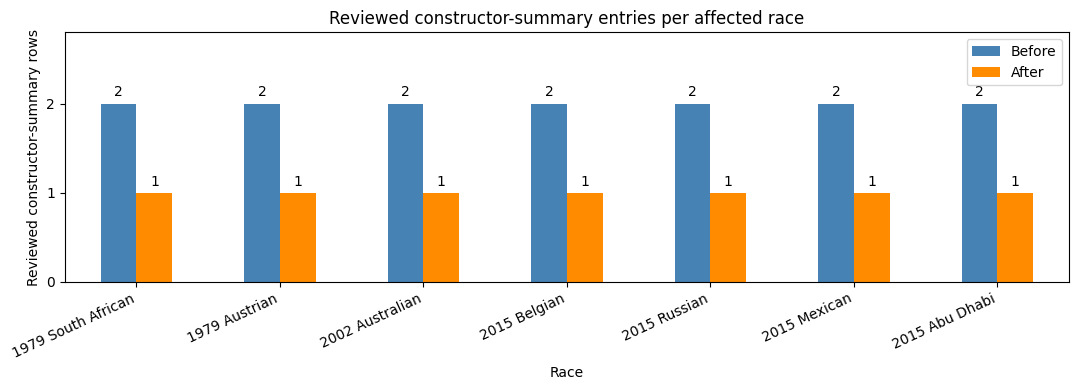

,Before,After,Removed
constructorId,,,
34,310,308,2
2,71,70,1
206,59,55,4


In [277]:
# Count only each race's two reviewed IDs, not other constructors in that race.
def reviewed_constructor_counts(table):
    reviewed = table.merge(constructor_pair_corrections, on="raceId", validate="many_to_one")
    selected = reviewed["constructorId"].eq(reviewed["Remove constructorId"]) | reviewed["constructorId"].eq(reviewed["Keep constructorId"])
    return reviewed.loc[selected].groupby("raceId").size()

constructor_affected_counts = pd.DataFrame({
    "Before": reviewed_constructor_counts(constructor_results_before_pair_fix),
    "After": reviewed_constructor_counts(constructor_results_clean)
}).loc[constructor_pair_corrections["raceId"]]
assert constructor_affected_counts["Before"].eq(2).all()
assert constructor_affected_counts["After"].eq(1).all()
constructor_affected_counts = constructor_affected_counts.merge(
    races[["raceId", "year", "name"]], left_index=True, right_on="raceId", validate="one_to_one"
)
constructor_affected_counts["Race"] = constructor_affected_counts["year"].astype(str) + " " + constructor_affected_counts["name"].str.replace(" Grand Prix", "", regex=False)
display(constructor_affected_counts[["raceId", "Race", "Before", "After"]])

ax = constructor_affected_counts.set_index("Race")[["Before", "After"]].plot.bar(
    figsize=(11, 4), color=["steelblue", "darkorange"]
)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set_ylim(0, 2.8)
ax.set_yticks([0, 1, 2])
ax.set_title("Reviewed constructor-summary entries per affected race")
ax.set_ylabel("Reviewed constructor-summary rows")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

constructor_history_counts = pd.DataFrame({
    "Before": constructor_results_before_pair_fix.groupby("constructorId").size(),
    "After": constructor_results_clean.groupby("constructorId").size()
}).loc[constructor_pair_corrections["Remove constructorId"].unique()]
constructor_history_counts["Removed"] = constructor_history_counts["Before"] - constructor_history_counts["After"]
display(constructor_history_counts)
assert constructor_history_counts["After"].gt(0).all(), "A constructor's entire history was removed."


In [278]:
constructor_pair_coverage_after = constructor_results_clean.merge(
    driver_race_constructor_pairs, on=["raceId", "constructorId"],
    how="left", validate="one_to_one", indicator=True
)
constructor_pair_fix_summary = pd.DataFrame({
    "Before pair correction": [len(constructor_results_before_pair_fix), len(constructor_results_before_pair_fix.columns),
        constructor_pair_coverage_before["_merge"].eq("left_only").sum()],
    "After pair correction": [len(constructor_results_clean), len(constructor_results_clean.columns),
        constructor_pair_coverage_after["_merge"].eq("left_only").sum()]
}, index=["Rows", "Columns", "Constructor-result pairs absent from results"])
display(constructor_pair_fix_summary)
display(constructor_results_clean["status"].value_counts().to_frame("Final constructor-result rows"))

# Prove that the seven reviewed pairs are absent and every other cleaned row is identical.
assert len(constructor_results_before_pair_fix) - len(constructor_results_clean) == 7
assert constructor_results_clean.columns.equals(constructor_results.columns)
assert not pd.MultiIndex.from_frame(constructor_results_clean[["raceId", "constructorId"]]).isin(pairs_to_remove).any()
assert constructor_pair_coverage_after["_merge"].eq("both").all()
assert constructor_results_clean["constructorResultsId"].notna().all()
assert constructor_results_clean["constructorResultsId"].is_unique
assert not constructor_results_clean.duplicated(["raceId", "constructorId"]).any()
assert constructor_results_clean["raceId"].isin(races["raceId"]).all()
assert constructor_results_clean["constructorId"].isin(constructors["constructorId"]).all()
assert constructor_results_clean["status"].isin(["D", "ND"]).all()
assert constructor_results_clean["status"].eq("D").sum() == constructor_results_before_pair_fix["status"].eq("D").sum()
pd.testing.assert_frame_equal(
    constructor_results_clean, constructor_results_before_pair_fix.loc[~remove_constructor_rows]
)
pd.testing.assert_frame_equal(constructor_results, constructor_results_raw_snapshot)
print("Passed: only the seven reviewed race-constructor rows were removed; every retained cleaned row is unchanged.")


,Before pair correction,After pair correction
Rows,12625,12618
Columns,5,5
Constructor-result pairs absent from results,7,0


,Final constructor-result rows
status,
ND,12601
D,17


Passed: only the seven reviewed race-constructor rows were removed; every retained cleaned row is unchanged.


### Findings for the extra-record correction

We removed **seven specific race–constructor records**, retaining their supported summaries. After removal, and before the reconstruction below, the table has **12,618 rows and the same 5 columns**. IDs `34`, `2` and `206` still have their other race records. The 17 `D` flags remain; `ND` now occurs in 12,601 rows because the seven removed rows were all `ND`.

All remaining constructor-result pairs match a pair in `results`. This checks only the direction **constructor_results → results**. It does not establish that every team appearing in `results` has a constructor summary. The next steps investigate the reverse direction and reconstruct only two independently reviewed summaries.

The raw CSVs and tables remain unchanged. The removed-row audit, reference URLs, official sources, driver links, retained counterparts, before/after counts and checks document the correction.


### Step 12 — Find missing summaries in the reverse direction

Now we ask: **does each race–constructor pair in `results` have a summary in `constructor_results_clean`?** This is different from checking that an ID exists somewhere in another table.

There are 410 unmatched pairs before this step. We investigate their meaning before adding anything:

| Group | Pairs | Treatment and evidence |
|---|---:|---|
| Before 1958 | 400 | No constructor-championship summary is required: [F1 explains that the championship began in 1958](https://www.formula1.com/en/latest/article/the-beginners-guide-to-the-f1-constructors-championship.66nTfWSqrUYv3bnbosPkHV). Keep the driver results; do not invent constructor summaries. |
| Indianapolis 1958 | 7 | This event did not count towards the constructors' competition, as explained by this [secondary historical source](https://www.formulaonehistory.com/seasons/1958-f1-world-championship/). Keep these as documented event exceptions. |
| HRT, Australia 2012 | 1 | Both drivers failed to qualify. [Official qualifying results](https://www.formula1.com/en/results/2012/races/10/australia/qualifying) confirm the 107% failure. Keep this as a documented non-starting entry, without assuming every non-starting team is omitted by the source. |
| BRM, France 1959; March–Alfa Romeo, Spain 1971 | 2 | The teams actually raced, and existing summaries for these constructors include other zero-point races. Review and reconstruct these two only. |

The code checks these exact groups. Any other unmatched pair stops the check so it must be investigated. This documents missing **records**, rather than filling every absence with zero.


### 3.2.4 Constructor Results: Reconstructing Missing Records & Final Validation
Auditing historical gaps in the constructor summaries. This isolates legitimate exceptions (e.g., pre-1958 rules) and manually reconstructs two verifiable missing records. Concludes with a rigorous suite of assertion tests to prove zero unintended data loss before finalizing the table.

In [279]:
constructor_results_before_reconstruction = constructor_results_clean.copy(deep=True)
constructor_missing_pairs = driver_race_constructor_pairs.merge(
    constructor_results_before_reconstruction[["raceId", "constructorId"]],
    on=["raceId", "constructorId"], how="left", validate="one_to_one", indicator=True
)
constructor_missing_pairs = constructor_missing_pairs.loc[
    constructor_missing_pairs["_merge"].eq("left_only"), ["raceId", "constructorId"]
].merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one")

constructor_missing_pairs["Reason"] = "Needs investigation"
constructor_missing_pairs.loc[constructor_missing_pairs["year"].lt(1958), "Reason"] = "Before constructors championship"
constructor_missing_pairs.loc[constructor_missing_pairs["raceId"].eq(768), "Reason"] = "Indianapolis 1958 exception"
constructor_missing_pairs.loc[
    constructor_missing_pairs["raceId"].eq(860) & constructor_missing_pairs["constructorId"].eq(164), "Reason"
] = "HRT did not qualify"

# Existing IDs for the two reviewed missing summaries.
constructor_reconstruction_pairs = pd.DataFrame([
    (759, 66), (633, 199)
], columns=["raceId", "constructorId"])
reviewed_pairs = pd.MultiIndex.from_frame(constructor_reconstruction_pairs)
missing_pairs = pd.MultiIndex.from_frame(constructor_missing_pairs[["raceId", "constructorId"]])
constructor_missing_pairs.loc[missing_pairs.isin(reviewed_pairs), "Reason"] = "Reviewed missing summary"

display(constructor_missing_pairs.groupby("Reason").size().to_frame("Missing pairs"))
assert len(constructor_missing_pairs) == 410
assert not constructor_missing_pairs["Reason"].eq("Needs investigation").any()
assert constructor_missing_pairs["Reason"].value_counts().to_dict() == {
    "Before constructors championship": 400, "Indianapolis 1958 exception": 7,
    "HRT did not qualify": 1, "Reviewed missing summary": 2
}


,Missing pairs
Reason,
Before constructors championship,400
HRT did not qualify,1
Indianapolis 1958 exception,7
Reviewed missing summary,2


### Step 13 — Show the existing IDs, drivers and earlier records

`constructorId` identifies a constructor and repeats across races. We reuse **66 for BRM** and **199 for March–Alfa Romeo**, joining to the existing `constructors` and `races` tables. We are not creating new teams.

The first table shows drivers in the two affected races. The second shows earlier constructor summaries with these same IDs. The third shows championship points immediately before and after each affected race. Unchanged season totals support zero points here, but are only a cross-check: historical scoring rules can differ from modern rules.


In [280]:
constructor_reconstruction_drivers = (
    results.merge(constructor_reconstruction_pairs, on=["raceId", "constructorId"], validate="many_to_one")
    .merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
    .merge(status, on="statusId", validate="many_to_one")
)
constructor_reconstruction_drivers["Driver"] = (
    constructor_reconstruction_drivers["forename"] + " " + constructor_reconstruction_drivers["surname"]
)
display(constructor_reconstruction_drivers[
    ["raceId", "constructorId", "resultId", "driverId", "Driver", "laps", "positionText", "points", "status"]
])
assert constructor_reconstruction_drivers.groupby("raceId").size().to_dict() == {633: 1, 759: 4}
assert constructor_reconstruction_drivers["laps"].gt(0).all()

# These are earlier races, already present in the source data.
constructor_earlier_pairs = pd.DataFrame([(758, 66), (632, 199)], columns=["raceId", "constructorId"])
display(constructor_results_before_reconstruction.merge(
    constructor_earlier_pairs, on=["raceId", "constructorId"], validate="one_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"))

constructor_standings_evidence = constructor_standings.merge(
    pd.concat([constructor_earlier_pairs, constructor_reconstruction_pairs]),
    on=["raceId", "constructorId"], validate="one_to_one"
).merge(races[["raceId", "year", "round", "name"]], on="raceId", validate="many_to_one")
display(constructor_standings_evidence[
    ["constructorId", "raceId", "year", "round", "name", "points"]
].sort_values(["constructorId", "round"]))
assert constructor_standings_evidence.groupby("constructorId")["points"].nunique().eq(1).all()


,raceId,constructorId,resultId,driverId,Driver,laps,positionText,points,status
0,759,66,18366,541,Ron Flockhart,50,6,0.0,Finished
1,759,66,18367,501,Harry Schell,47,7,0.0,+3 Laps
2,759,66,18372,475,Stirling Moss,42,D,1.0,Disqualified
3,759,66,18381,347,Jo Bonnier,6,R,0.0,Engine
4,633,199,24305,333,Andrea de Adamich,26,R,0.0,Transmission


,constructorResultsId,raceId,constructorId,points,status,year,name
0,9905,758,66,8.0,ND,1959,Dutch Grand Prix
1,11848,632,199,0.0,ND,1971,South African Grand Prix


,constructorId,raceId,year,round,name,points
2,66,758,1959,3,Dutch Grand Prix,8.0
1,66,759,1959,4,French Grand Prix,8.0
0,199,632,1971,1,South African Grand Prix,0.0
3,199,633,1971,2,Spanish Grand Prix,0.0


### Step 14 — Record the evidence and where each value comes from

These are **reconstructed clean-table rows**, not recovered original records. Official observations below were manually reviewed on **11 October 2026**; running the notebook does not download the websites.

| Race and constructor | Evidence for zero constructor points |
|---|---|
| France 1959, BRM | [Official BRM race-by-race points](https://www.formula1.com/en/results/1959/team/BRM) explicitly show France: 0. [Official race results](https://www.formula1.com/en/results/1959/races/172/france/race-result) show the four BRM drivers. Moss has a driver point despite being disqualified, so summing driver points would incorrectly give 1 for this constructor summary. We use the official constructor total instead. |
| Spain 1971, March–Alfa Romeo | [Official race results](https://www.formula1.com/en/results/1971/races/292/spain/race-result) show Andrea de Adamich, March Alfa Romeo, 26 laps, DNF and 0 points. The local records show him as this constructor's only driver in this race; its championship total stays 0. This supports reconstructing a zero-point summary. March–Ford (`200`) is a separate constructor entry and is not reused. |

| Clean column | Source or decision |
|---|---|
| `raceId` | Reuse existing event IDs from `results`, checked against `races`. |
| `constructorId` | Reuse existing IDs from `results`, checked against `constructors` and earlier summaries. |
| `points` | 0, supported by the official evidence above and local standings. |
| `status` | `ND`, our existing label for **no constructor disqualification flag recorded**. This is a documented cleaning label; we have not recovered the original missing status. Moss's driver disqualification does not establish a constructor disqualification. |
| `constructorResultsId` | Generate unique local row IDs after the largest source row ID. Original missing row IDs are unknown. These numbers identify rows; they are not new constructor IDs. |

The separate `constructor_reconstruction_audit` keeps the source URLs and provenance. The clean table keeps its same five columns.


In [281]:
# Manually reviewed evidence; points are not a general driver-points sum.
constructor_reconstruction_audit = constructor_reconstruction_pairs.merge(
    races[["raceId", "year", "name"]].rename(columns={"name": "Race"}),
    on="raceId", validate="many_to_one"
).merge(
    constructors[["constructorId", "name"]].rename(columns={"name": "Constructor"}),
    on="constructorId", validate="many_to_one"
)
constructor_reconstruction_audit["points"] = 0.0
constructor_reconstruction_audit["status"] = "ND"
constructor_reconstruction_audit["Evidence URL"] = [
    "https://www.formula1.com/en/results/1959/team/BRM",
    "https://www.formula1.com/en/results/1971/races/292/spain/race-result"
]
constructor_reconstruction_audit["Provenance"] = "Reconstructed; existing race/team IDs; supported zero points; local row ID; ND cleaning label"
constructor_reconstruction_audit["Reviewed on"] = "2026-10-11"

# Start after the maximum RAW row ID, so removed IDs are not reused either.
next_constructor_row_id = int(constructor_results["constructorResultsId"].max()) + 1
constructor_reconstruction_audit["constructorResultsId"] = range(
    next_constructor_row_id, next_constructor_row_id + len(constructor_reconstruction_audit)
)
constructor_results_reconstructed = constructor_reconstruction_audit[
    constructor_results_clean.columns
].copy().astype(constructor_results_clean.dtypes.to_dict())
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(constructor_reconstruction_audit)
print("The two rows to add, using the original five columns:")
display(constructor_results_reconstructed)


,raceId,constructorId,year,Race,Constructor,points,status,Evidence URL,Provenance,Reviewed on,constructorResultsId
0,759,66,1959,French Grand Prix,BRM,0.0,ND,https://www.formula1.com/en/results/1959/team/BRM,Reconstructed; existing race/team IDs; supported zero points; local row ID; ND cleaning label,2026-10-11,17130
1,633,199,1971,Spanish Grand Prix,March-Alfa Romeo,0.0,ND,https://www.formula1.com/en/results/1971/races/292/spain/race-result,Reconstructed; existing race/team IDs; supported zero points; local row ID; ND cleaning label,2026-10-11,17131


The two rows to add, using the original five columns:


,constructorResultsId,raceId,constructorId,points,status
0,17130,759,66,0.0,ND
1,17131,633,199,0.0,ND


### Step 15 — Add the two reviewed rows and check before and after

Only the two reviewed combinations can be added. Re-running this addition cell does not create duplicates. Existing cleaned records must remain identical. The graph shows the two reviewed missing summaries becoming zero; it does not claim that the 408 documented exceptions are errors.


,Before reconstruction,After reconstruction
Rows,12618,12620
Columns,5,5
Reviewed summaries still missing,2,0
All unmatched results pairs,410,408


,Final rows
status,
ND,12603
D,17


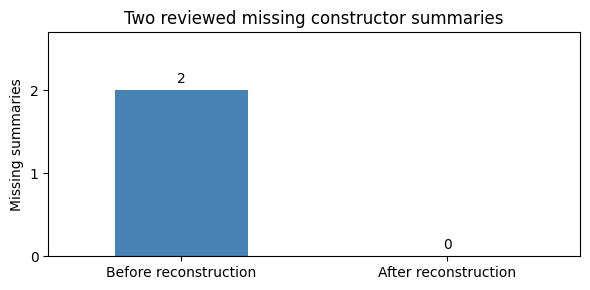

Passed: two supported summaries added, unique local row IDs, valid existing race/team IDs, original five columns, and all earlier rows preserved.


In [282]:
# Append only reviewed pairs that are not already present.
existing_pairs = pd.MultiIndex.from_frame(constructor_results_clean[["raceId", "constructorId"]])
new_pairs = pd.MultiIndex.from_frame(constructor_results_reconstructed[["raceId", "constructorId"]])
rows_to_add = constructor_results_reconstructed.loc[~new_pairs.isin(existing_pairs)]
constructor_results_clean = pd.concat([constructor_results_clean, rows_to_add], ignore_index=True)

constructor_missing_after = driver_race_constructor_pairs.merge(
    constructor_results_clean[["raceId", "constructorId"]],
    on=["raceId", "constructorId"], how="left", validate="one_to_one", indicator=True
)
constructor_missing_after = constructor_missing_after.loc[
    constructor_missing_after["_merge"].eq("left_only"), ["raceId", "constructorId"]
]
constructor_reconstruction_summary = pd.DataFrame({
    "Before reconstruction": [len(constructor_results_before_reconstruction), 5, 2, len(constructor_missing_pairs)],
    "After reconstruction": [len(constructor_results_clean), len(constructor_results_clean.columns),
        new_pairs.isin(pd.MultiIndex.from_frame(constructor_missing_after)).sum(), len(constructor_missing_after)]
}, index=["Rows", "Columns", "Reviewed summaries still missing", "All unmatched results pairs"])
display(constructor_reconstruction_summary)
display(constructor_results_clean["status"].value_counts().to_frame("Final rows"))

ax = constructor_reconstruction_summary.loc["Reviewed summaries still missing"].plot.bar(
    figsize=(6, 3), color=["steelblue", "darkorange"], rot=0
)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set_title("Two reviewed missing constructor summaries")
ax.set_ylabel("Missing summaries")
ax.set_ylim(0, 2.7)
ax.set_yticks([0, 1, 2])
plt.tight_layout()
plt.show()

assert len(constructor_results_clean) == len(constructor_results_before_reconstruction) + 2
assert len(constructor_results_clean) == 12620
assert len(constructor_missing_after) == 408
assert constructor_results_clean.columns.equals(constructor_results.columns)
assert constructor_results_clean["constructorResultsId"].is_unique
assert not constructor_results_clean.duplicated(["raceId", "constructorId"]).any()
assert constructor_results_clean["raceId"].isin(races["raceId"]).all()
assert constructor_results_clean["constructorId"].isin(constructors["constructorId"]).all()
assert constructor_results_clean.notna().all().all()
assert pd.api.types.is_numeric_dtype(constructor_results_clean["points"])
assert constructor_results_clean["status"].value_counts().to_dict() == {"ND": 12603, "D": 17}
assert not new_pairs.isin(pd.MultiIndex.from_frame(constructor_missing_after)).any()
pd.testing.assert_frame_equal(
    constructor_results_clean.iloc[:len(constructor_results_before_reconstruction)].reset_index(drop=True),
    constructor_results_before_reconstruction.reset_index(drop=True)
)
pd.testing.assert_frame_equal(
    constructor_results_clean.merge(constructor_reconstruction_pairs, on=["raceId", "constructorId"], validate="one_to_one")
        .sort_values("constructorResultsId").reset_index(drop=True),
    constructor_results_reconstructed.sort_values("constructorResultsId").reset_index(drop=True)
)
pd.testing.assert_frame_equal(constructor_results, constructor_results_raw_snapshot)
print("Passed: two supported summaries added, unique local row IDs, valid existing race/team IDs, original five columns, and all earlier rows preserved.")


### Final findings for constructor_results

The original table has 12,625 rows. We label missing constructor-status flags `ND`, remove seven specifically verified redundant summaries, and reconstruct two verified missing summaries. The final clean table has **12,620 rows and the original 5 columns**: **12,603 ND** and **17 D**.

Both reconstructed rows have zero points. Their constructor IDs already exist; only their row IDs are generated locally. The audit tables preserve the removed rows, evidence links and reconstruction provenance. The remaining 408 unmatched driver-result pairs are documented above as historical or non-starting exceptions. We do not fabricate summaries for them. All original CSVs and raw tables are preserved.


## 3.3 drivers.csv 

### 3.3.1 Drivers: Initial Auditing & Core Cleaning
Establishing the baseline snapshot, replacing `\N` sentinels with true NaNs, standardizing fragmented nationality labels (e.g., merging "Argentinian " into "Argentine"), and safely casting birth dates (`dob`) into datetime formats.

### Before-cleaning inspection

Each row represents one driver. `driverId` is the primary key.


In [283]:
print("Rows:", len(drivers))
print("Columns:", len(drivers.columns))
display(drivers.head(10))
drivers.info()


Rows: 861
Columns: 9


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen
5,6,nakajima,\N,NAK,Kazuki,Nakajima,1985-01-11,Japanese,http://en.wikipedia.org/wiki/Kazuki_Nakajima
6,7,bourdais,\N,BOU,Sébastien,Bourdais,1979-02-28,French,http://en.wikipedia.org/wiki/S%C3%A9bastien_Bo...
7,8,raikkonen,7,RAI,Kimi,Räikkönen,1979-10-17,Finnish,http://en.wikipedia.org/wiki/Kimi_R%C3%A4ikk%C...
8,9,kubica,88,KUB,Robert,Kubica,1984-12-07,Polish,http://en.wikipedia.org/wiki/Robert_Kubica
9,10,glock,\N,GLO,Timo,Glock,1982-03-18,German,http://en.wikipedia.org/wiki/Timo_Glock


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   driverId     861 non-null    int64 
 1   driverRef    861 non-null    object
 2   number       861 non-null    object
 3   code         861 non-null    object
 4   forename     861 non-null    object
 5   surname      861 non-null    object
 6   dob          861 non-null    object
 7   nationality  861 non-null    object
 8   url          861 non-null    object
dtypes: int64(1), object(8)
memory usage: 60.7+ KB


### Placeholder handling and before/after evidence


In [284]:
sentinels_before = drivers.eq(r"\N").sum()

display(
    sentinels_before.to_frame("Missing placeholders BEFORE")
)

,Missing placeholders BEFORE
driverId,0
driverRef,0
number,802
code,757
forename,0
surname,0
dob,0
nationality,0
url,0


In [285]:
drivers_raw_snapshot = drivers.copy(deep=True)
drivers_clean = drivers.copy(deep=True)
drivers_clean = drivers_clean.replace(r"\N", np.nan)


In [286]:
comparison = pd.DataFrame({
    "Placeholders BEFORE": drivers.eq(r"\N").sum(),
    "Placeholders AFTER": drivers_clean.eq(r"\N").sum(),
    "Recognized missing BEFORE": drivers.isna().sum(),
    "Recognized missing AFTER": drivers_clean.isna().sum()
})

display(comparison)

,Placeholders BEFORE,Placeholders AFTER,Recognized missing BEFORE,Recognized missing AFTER
driverId,0,0,0,0
driverRef,0,0,0,0
number,802,0,0,802
code,757,0,0,757
forename,0,0,0,0
surname,0,0,0,0
dob,0,0,0,0
nationality,0,0,0,0
url,0,0,0,0


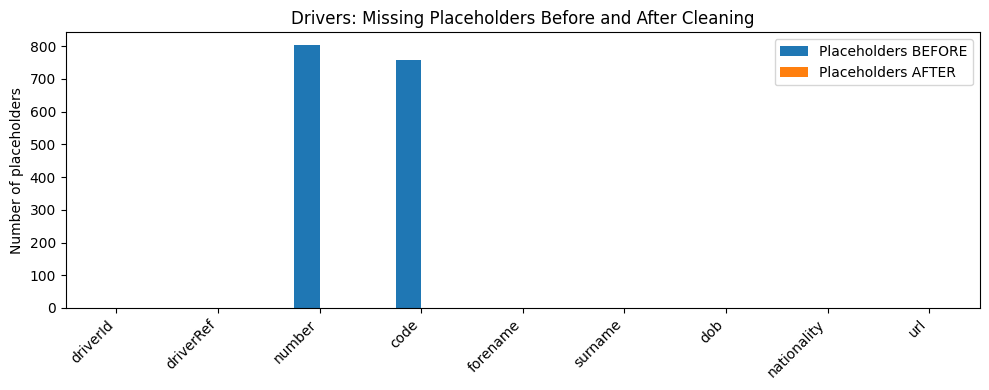

In [287]:
comparison[[
    "Placeholders BEFORE",
    "Placeholders AFTER"
]].plot.bar(figsize=(10, 4))

plt.title("Drivers: Missing Placeholders Before and After Cleaning")
plt.ylabel("Number of placeholders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The original data uses `\N` to represent missing information.
We counted these placeholders before cleaning, then replaced them with
recognized missing values in a copy. The comparison confirms that no `\N`
placeholders remain. Missing information was preserved, not guessed or filled.

### Nationality inspection and correction


In [288]:
# Show every nationality label and its count.
nationality_counts = (
    drivers_clean["nationality"]
    .value_counts(dropna=False)
    .rename_axis("Nationality")
    .reset_index(name="Number of drivers")
)

# Quotes make surrounding spaces visible.
nationality_counts["Nationality"] = (
    nationality_counts["Nationality"].map(repr)
)

with pd.option_context("display.max_rows", None):
    display(nationality_counts)

,Nationality,Number of drivers
0,'British',166
1,'American',158
2,'Italian',99
3,'French',73
4,'German',50
5,'Brazilian',32
6,'Argentine',24
7,'Belgian',23
8,'Swiss',23
9,'South African',23


In [289]:
nationality_before = drivers["nationality"].copy()

# Remove surrounding spaces.
drivers_clean["nationality"] = (
    drivers_clean["nationality"].str.strip()
)

# Use one label for the same nationality.
drivers_clean["nationality"] = (
    drivers_clean["nationality"].replace({
        "Argentinian": "Argentine"
    })
)

In [290]:
changed = (
    nationality_before.fillna("<MISSING>")
    != drivers_clean["nationality"].fillna("<MISSING>")
)

changes = drivers_clean.loc[
    changed, ["driverId", "forename", "surname"]
].copy()

# Quotes make the original trailing spaces visible.
changes["Nationality BEFORE"] = nationality_before.loc[changed].map(repr)
changes["Nationality AFTER"] = (
    drivers_clean.loc[changed, "nationality"].map(repr)
)

display(changes)
print("Rows changed:", changed.sum())

,driverId,forename,surname,Nationality BEFORE,Nationality AFTER
859,861,Franco,Colapinto,'Argentinian ','Argentine'


Rows changed: 1


,Before,After
'Argentine',24,25
'Argentinian',0,0
'Argentinian ',1,0


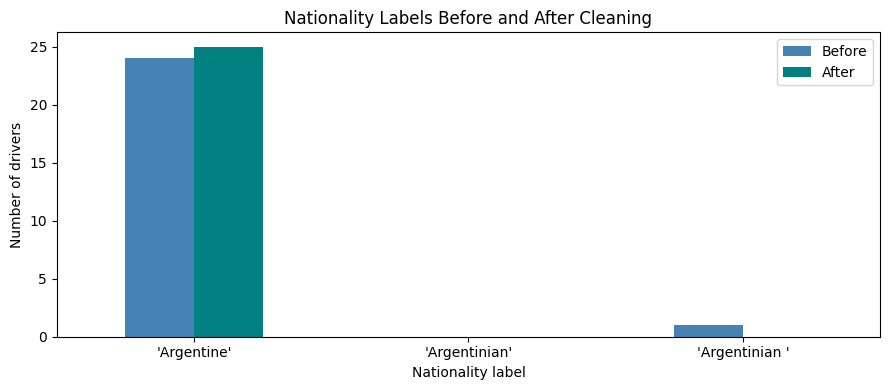

In [291]:
labels = ["Argentine", "Argentinian", "Argentinian "]

nationality_comparison = pd.DataFrame({
    "Before": nationality_before.value_counts().reindex(
        labels, fill_value=0
    ),
    "After": drivers_clean["nationality"].value_counts().reindex(
        labels, fill_value=0
    )
})

nationality_comparison.index = [repr(label) for label in labels]

display(nationality_comparison)

nationality_comparison.plot.bar(
    figsize=(9, 4),
    color=["steelblue", "teal"]
)

plt.title("Nationality Labels Before and After Cleaning")
plt.xlabel("Nationality label")
plt.ylabel("Number of drivers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Reason for nationality-label standardization

We followed the reference URLs stored in `drivers.url` and checked the explicit nationality fields, rather than inferring nationality from birthplace, team, or races entered.

| Driver record | Original `nationality` | Nationality identified by its reference |
|---|---|---|
| Franco Colapinto (`driverId = 861`) | `"Argentinian "` | Argentine |
| Gastón Mazzacane (`driverId = 60`) | `Argentine` | Argentine |

Sources supplied in the CSV: [Franco Colapinto](https://en.wikipedia.org/wiki/Franco_Colapinto) and [Gastón Mazzacane](https://en.wikipedia.org/wiki/Gast%C3%B3n_Mazzacane). Both pages identify the driver's Formula One nationality as Argentine.

Colapinto's own reference supports standardizing his label to the existing `Argentine` category. We also remove the trailing space. This prevents the same nationality being separated into two categories; the before/after counts demonstrate the effect, not the reason for the change. No driver records are merged or removed. `Argentine-Italian` remains separate because replacing it would discard information. No nationality ID or country code was inferred to exist in the original data.

Additional official corroboration, reviewed 11 October 2026: [F1’s Colapinto profile](https://www.formula1.com/en/drivers/franco-colapinto) identifies him as Argentine and explicitly connects him to fellow Argentine driver Gastón Mazzacane. This supports the existing correction without relying on similar spelling alone.


### Birth-date typing and before/after evidence


In [292]:
# Preserve values before this change.
dob_before = drivers["dob"].replace(r"\N", np.nan).copy()

converted_dob = pd.to_datetime(
    dob_before,
    format="%Y-%m-%d",
    errors="coerce"
)

# Find non-missing strings that could not be converted.
invalid_dates = dob_before.notna() & converted_dob.isna()

print("Invalid non-missing birth dates:", invalid_dates.sum())

if invalid_dates.any():
    display(
        drivers_clean.loc[
            invalid_dates,
            ["driverId", "forename", "surname", "dob"]
        ]
    )

assert not invalid_dates.any(), \
    "Investigate invalid birth dates before continuing."

drivers_clean["dob"] = converted_dob

Invalid non-missing birth dates: 0


In [293]:
display(pd.DataFrame({
    "BEFORE": dob_before.head(),
    "AFTER": drivers_clean["dob"].head()
}))

print("Type BEFORE:", dob_before.dtype)
print("Type AFTER:", drivers_clean["dob"].dtype)

print("Missing dates BEFORE:", dob_before.isna().sum())
print("Missing dates AFTER:", drivers_clean["dob"].isna().sum())

,BEFORE,AFTER
0,1985-01-07,1985-01-07
1,1977-05-10,1977-05-10
2,1985-06-27,1985-06-27
3,1981-07-29,1981-07-29
4,1981-10-19,1981-10-19


Type BEFORE: object
Type AFTER: datetime64[ns]
Missing dates BEFORE: 0
Missing dates AFTER: 0


Dates of birth were stored as text. We checked for invalid date strings
and converted valid values to datetime format. We compared missing counts
before and after to verify that conversion did not introduce new gaps.
This enables calculating each driver's age at a race once race dates are joined.

### Key and reference checks


In [294]:
print("Missing driver IDs:",
      drivers_clean["driverId"].isna().sum())

print("Duplicate driver IDs:",
      drivers_clean["driverId"].duplicated().sum())

assert drivers_clean["driverId"].notna().all(), \
    "Missing driverId found"

assert drivers_clean["driverId"].is_unique, \
    "Duplicate driverId found"

print("Passed: driverId is unique and non-null.")

Missing driver IDs: 0
Duplicate driver IDs: 0
Passed: driverId is unique and non-null.


### 3.3.2 Drivers: Relational Integrity & Missing Identifiers
Verifying that every driver referenced across all external tables (results, standings, lap times, etc.) exists in our cleaned index. This phase also audits missing driver numbers and 3-letter codes by historical era, subsequently casting driver numbers to strict `Int64` integers.

In [295]:
reference_tables = {
    "results": results,
    "qualifying": qualifying,
    "driver_standings": driver_standings,
    "lap_times": lap_times,
    "pit_stops": pit_stops,
    "sprint_results": sprint_results
}

checks = []

for name, table in reference_tables.items():
    missing = (
        table["driverId"].isna()
        | table["driverId"].eq(r"\N")
    )

    unknown = (
        ~missing
        & ~table["driverId"].isin(drivers_clean["driverId"])
    )

    checks.append({
        "Table": name,
        "Missing driver IDs": int(missing.sum()),
        "Unknown driver IDs": int(unknown.sum())
    })

    if (missing | unknown).any():
        print(f"Problem records in {name}:")
        display(table.loc[missing | unknown].head(20))

audit = pd.DataFrame(checks)
display(audit)

assert audit[["Missing driver IDs", "Unknown driver IDs"]].eq(0).all().all(), \
    "Some driver references need investigation"

print("Passed: all checked driver references exist in drivers_clean.")


,Table,Missing driver IDs,Unknown driver IDs
0,results,0,0
1,qualifying,0,0
2,driver_standings,0,0
3,lap_times,0,0
4,pit_stops,0,0
5,sprint_results,0,0


Passed: all checked driver references exist in drivers_clean.


In [296]:
final_checks = pd.Series({
    "Row count unchanged": len(drivers_clean) == len(drivers),
    "No remaining placeholders": not drivers_clean.eq(r"\N").any().any(),
    "Driver IDs non-null": drivers_clean["driverId"].notna().all(),
    "Driver IDs unique": drivers_clean["driverId"].is_unique,
    "No completely duplicated rows": not drivers_clean.duplicated().any(),
    "Birth dates have datetime type":
        pd.api.types.is_datetime64_any_dtype(drivers_clean["dob"]),
    "Birth-date missing count unchanged":
        drivers_clean["dob"].isna().sum()
        == drivers["dob"].replace(r"\N", np.nan).isna().sum()
})

display(final_checks.to_frame("Passed"))
assert final_checks.all(), "Investigate failed checks."

,Passed
Row count unchanged,True
No remaining placeholders,True
Driver IDs non-null,True
Driver IDs unique,True
No completely duplicated rows,True
Birth dates have datetime type,True
Birth-date missing count unchanged,True


### Additional audit — Understand missing numbers and codes

Each row is one driver, covering many historical eras. A missing value is not automatically a wrong record.

`number` is a driver-profile number, while `results.number` is the car number used in a particular race. [The FIA announced permanent driver numbers for 2014](https://www.fia.com/news/formula-one-regulation-changes), and [F1 explains the earlier team-based system](https://www.formula1.com/en/latest/article/from-childhood-number-plates-to-karting-titles-why-each-driver-picked-their.49DqOwhvza1RRvE2Rgi1so.49DqOwhvza1RRvE2Rgi1so). Therefore we cannot assign an old driver one permanent number by copying an arbitrary race number.

We join drivers to their first and last **recorded result years**. This is an audit of the dataset, not a claim that every result row is a race start. The table below tests whether the missing values belong to older drivers or drivers recorded from 2014 onwards.

`code` is an abbreviation, not the driver's identity key. Historical coverage is incomplete in this dataset. We do not assume an introduction year for codes or construct abbreviations from names. A missing code remains an explicitly documented source gap. Codes are not needed to link tables: `driverId` does that.


,Drivers,Missing_number,Missing_code
Recorded era,,,
Has results in 2014 or later,59,0,0
Last result before 2014,802,802,757


,driverId,forename,surname,number,code,first_recorded_year,last_recorded_year
1,2,Nick,Heidfeld,NaN,HEI,2000,2011
4,5,Heikki,Kovalainen,NaN,KOV,2007,2013
5,6,Kazuki,Nakajima,NaN,NAK,2007,2009
6,7,Sébastien,Bourdais,NaN,BOU,2008,2009
9,10,Timo,Glock,NaN,GLO,2004,2012


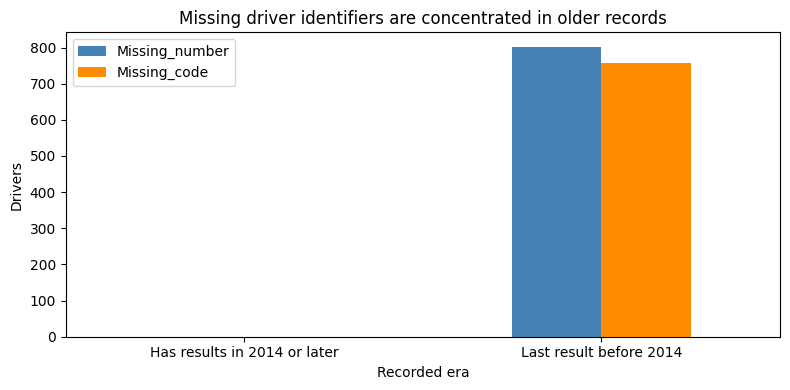

In [297]:
driver_recorded_years = (
    results[["driverId", "raceId"]]
    .merge(races[["raceId", "year"]], on="raceId", validate="many_to_one")
    .groupby("driverId")["year"].agg(first_recorded_year="min", last_recorded_year="max")
)
driver_history_audit = drivers_clean.merge(
    driver_recorded_years, on="driverId", how="left", validate="one_to_one"
)
assert driver_history_audit["last_recorded_year"].notna().all()
driver_history_audit["Recorded era"] = np.where(
    driver_history_audit["last_recorded_year"].ge(2014),
    "Has results in 2014 or later", "Last result before 2014"
)
driver_missing_by_era = driver_history_audit.groupby("Recorded era").agg(
    Drivers=("driverId", "size"),
    Missing_number=("number", lambda values: values.isna().sum()),
    Missing_code=("code", lambda values: values.isna().sum())
)
display(driver_missing_by_era)
display(driver_history_audit.loc[
    driver_history_audit["number"].isna() | driver_history_audit["code"].isna(),
    ["driverId", "forename", "surname", "number", "code", "first_recorded_year", "last_recorded_year"]
].head(5))
driver_missing_by_era[["Missing_number", "Missing_code"]].plot.bar(
    figsize=(8, 4), color=["steelblue", "darkorange"], rot=0
)
plt.title("Missing driver identifiers are concentrated in older records")
plt.ylabel("Drivers")
plt.tight_layout()
plt.show()


### Missing-value decision and number typing

| Column | Finding | Treatment and reason |
|---|---|---|
| `number` | 802 missing (93.15%); all belong to drivers with their last recorded result before 2014 | Keep a genuine missing value. Convert known numbers to nullable integer `Int64`. A median, 0 or a generated number would not identify the driver's actual number. |
| `code` | 757 missing (87.92%); all belong to drivers with their last recorded result before 2014 | Keep the original known codes and recognized missing values. Treat missing codes as historical source gaps. Do not invent official abbreviations. |
| Other columns | No missing values | Check types, text quality and joins below; no filling required. |

**These gaps have a documented treatment:** retain them in this reference table and use `driverId` for joins. `number` and `code` should not be used as numerical measurements or podium predictors merely because a model accepts them. If a later display needs a label, names and `driverId` are available. Missing historical profile data does not require dropping the driver. Filling is useful only when the replacement has a defensible meaning.

The before/after graph below shows that recognizing missing values and typing numbers does not create or fabricate information.


,Before,After
0,44,44
1,NaN,<NA>
2,6,6
3,14,14
4,NaN,<NA>


Number type before: object
Number type after: Int64


,Before (including placeholders),After (recognized missing),After missing (%)
driverId,0,0,0.00
driverRef,0,0,0.00
number,802,802,93.15
code,757,757,87.92
forename,0,0,0.00
surname,0,0,0.00
dob,0,0,0.00
nationality,0,0,0.00
url,0,0,0.00


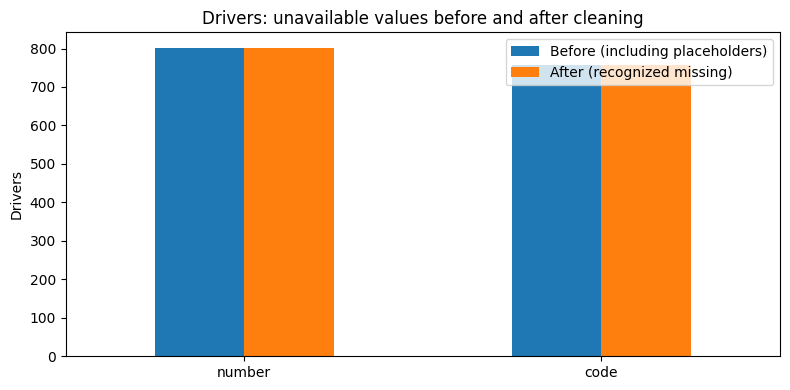

In [298]:
driver_number_before = drivers_clean["number"].copy()
driver_number_numeric = pd.to_numeric(driver_number_before, errors="coerce")
invalid_driver_numbers = driver_number_before.notna() & (
    driver_number_numeric.isna() | driver_number_numeric.mod(1).ne(0)
)
assert not invalid_driver_numbers.any(), "Investigate non-integer driver numbers."
drivers_clean["number"] = driver_number_numeric.astype("Int64")
assert drivers_clean["number"].dropna().between(1, 99).all()
display(pd.DataFrame({
    "Before": driver_number_before.head(), "After": drivers_clean["number"].head()
}))
print("Number type before:", driver_number_before.dtype)
print("Number type after:", drivers_clean["number"].dtype)

driver_missing_comparison = pd.DataFrame({
    "Before (including placeholders)": drivers.replace(r"\N", np.nan).isna().sum(),
    "After (recognized missing)": drivers_clean.isna().sum()
})
driver_missing_comparison["After missing (%)"] = drivers_clean.isna().mean().mul(100).round(2)
display(driver_missing_comparison)
driver_missing_comparison.loc[["number", "code"], [
    "Before (including placeholders)", "After (recognized missing)"
]].plot.bar(figsize=(8, 4), rot=0)
plt.title("Drivers: unavailable values before and after cleaning")
plt.ylabel("Drivers")
plt.tight_layout()
plt.show()


### Identity and text-quality checks

We check missing identifiers, full duplicate rows, duplicate `driverId`, `driverRef`, URLs and exact full names. We inspect blank text, surrounding whitespace, three-uppercase-letter code format and URL structure. These are format checks; they do not prove that every biography or URL is historically correct or accessible.

**Only `driverId` is our join key.** Codes and car numbers can repeat across different drivers and eras. Shared surnames, birthdays or nationalities also do not establish that two drivers are the same person. The repeated-code table makes this visible; we preserve these distinct drivers.


### 3.3.3 Drivers: Identity Validation & Age Auditing
Enforcing strict structural rules on text fields (URL formatting, unique `driverRef`, and 3-letter uppercase codes). Includes a cross-table temporal sanity check mapping birth dates to race dates to flag impossible ages, finishing with definitive assertion tests for the `drivers_clean` table.

In [299]:
driver_text_checks = []
for column in ["driverRef", "code", "forename", "surname", "nationality", "url"]:
    before = drivers[column].replace(r"\N", np.nan).astype("string")
    after = drivers_clean[column].astype("string")
    driver_text_checks.append({
        "Column": column,
        "Blank text before": int(before.str.strip().eq("").sum()),
        "Blank text after": int(after.str.strip().eq("").sum()),
        "Outer whitespace before": int(before.ne(before.str.strip()).sum()),
        "Outer whitespace after": int(after.ne(after.str.strip()).sum())
    })
driver_text_checks = pd.DataFrame(driver_text_checks)
display(driver_text_checks)
assert driver_text_checks[["Blank text after", "Outer whitespace after"]].eq(0).all().all()

driver_identity_checks = pd.Series({
    "No duplicate full rows": not drivers_clean.duplicated().any(),
    "IDs are positive integers": pd.api.types.is_integer_dtype(drivers_clean["driverId"]) and drivers_clean["driverId"].gt(0).all(),
    "driverRef complete and unique": drivers_clean["driverRef"].notna().all() and drivers_clean["driverRef"].is_unique,
    "URLs complete and unique": drivers_clean["url"].notna().all() and drivers_clean["url"].is_unique,
    "URLs have HTTP(S) structure": drivers_clean["url"].str.match(r"^https?://[^/\s]+/\S+$").all(),
    "No repeated exact full names": not drivers_clean.duplicated(["forename", "surname"]).any(),
    "Known codes are three uppercase letters": drivers_clean["code"].dropna().str.fullmatch(r"[A-Z]{3}").all()
})
display(driver_identity_checks.to_frame("Passed"))
assert driver_identity_checks.all()
print("Repeated codes, shown for inspection rather than deletion:")
display(drivers_clean.loc[
    drivers_clean["code"].notna() & drivers_clean["code"].duplicated(keep=False),
    ["driverId", "forename", "surname", "code"]
].sort_values(["code", "driverId"]))


,Column,Blank text before,Blank text after,Outer whitespace before,Outer whitespace after
0,driverRef,0,0,0,0
1,code,0,0,0,0
2,forename,0,0,0,0
3,surname,0,0,0,0
4,nationality,0,0,1,0
5,url,0,0,0,0


,Passed
No duplicate full rows,True
IDs are positive integers,True
driverRef complete and unique,True
URLs complete and unique,True
URLs have HTTP(S) structure,True
No repeated exact full names,True
Known codes are three uppercase letters,True


Repeated codes, shown for inspection rather than deletion:


,driverId,forename,surname,code
26,27,Christijan,Albers,ALB
846,848,Alexander,Albon,ALB
375,376,Lucien,Bianchi,BIA
823,824,Jules,Bianchi,BIA
37,38,Robert,Doornbos,DOO
860,862,Jack,Doohan,DOO
836,837,Rio,Haryanto,HAR
841,843,Brendon,Hartley,HAR
75,76,Jan,Magnussen,MAG
824,825,Kevin,Magnussen,MAG


### Birth dates and consistency with race records

Parsing dates is only the first check. We also check that each recorded event occurs after the driver's birth, across all six tables referencing drivers. We show the youngest and oldest ages in `results` for inspection. Ages use days divided by 365.2425, so they are approximate.

We do not impose today's minimum-age rules on historical records. [F1 confirms Verstappen debuted at 17](https://www.formula1.com/en/latest/article/verstappen-to-race-for-toro-rosso-in-2015.6BjluokWZBUnoCCCAHYg87). The oldest result entry below is Louis Chiron in Monaco 1958: its `positionText` and status show a failed qualification, so it must not be described as a race start. This check confirms chronological consistency, not every driver's exact biography.

We also compare known profile numbers with race-specific numbers. A number differing in an older race is not automatically an error: race numbers changed over time. We show Hamilton's earlier number as an example, and check that every known profile number occurs in at least one of that driver's recorded results.


In [300]:
driver_event_pairs = pd.concat([
    table[["driverId", "raceId"]] for table in reference_tables.values()
], ignore_index=True).drop_duplicates()
driver_date_audit = driver_event_pairs.merge(
    races[["raceId", "date"]], on="raceId", how="left", validate="many_to_one"
).merge(drivers_clean[["driverId", "dob"]], on="driverId", how="left", validate="many_to_one")
driver_date_audit["date"] = pd.to_datetime(driver_date_audit["date"], format="%Y-%m-%d", errors="raise")
assert driver_date_audit[["date", "dob"]].notna().all().all()
assert driver_date_audit["date"].ge(driver_date_audit["dob"]).all()
print("Driver–event pairs checked across all six tables:", len(driver_date_audit))

driver_age_audit = results[["driverId", "raceId", "positionText", "statusId"]].merge(
    driver_date_audit, on=["driverId", "raceId"], validate="many_to_one"
).merge(drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
driver_age_audit["Approximate age"] = (driver_age_audit["date"] - driver_age_audit["dob"]).dt.days / 365.2425
driver_age_extremes = driver_age_audit.loc[
    [driver_age_audit["Approximate age"].idxmin(), driver_age_audit["Approximate age"].idxmax()]
].merge(status, on="statusId", validate="many_to_one")
display(driver_age_extremes[["driverId", "forename", "surname", "raceId", "dob", "date", "Approximate age", "positionText", "status"]])

driver_number_audit = drivers_clean.loc[drivers_clean["number"].notna(), ["driverId", "number"]].merge(
    results[["driverId", "raceId", "number"]], on="driverId", suffixes=("_profile", "_race"), validate="one_to_many"
)
driver_number_audit["number_race"] = pd.to_numeric(driver_number_audit["number_race"], errors="coerce")
driver_number_audit["Matches profile"] = driver_number_audit["number_profile"].eq(driver_number_audit["number_race"])
assert driver_number_audit.groupby("driverId")["Matches profile"].any().all()
print("Example of an earlier race number differing from the profile number:")
display(driver_number_audit.loc[
    driver_number_audit["driverId"].eq(1) & ~driver_number_audit["Matches profile"]
].head(3))


Driver–event pairs checked across all six tables: 35332


,driverId,forename,surname,raceId,dob,date,Approximate age,positionText,status
0,830,Max,Verstappen,926,1997-09-30,2015-03-15,17.454157,R,Engine
1,589,Louis,Chiron,766,1899-08-03,1958-05-18,58.788339,F,Did not qualify


Example of an earlier race number differing from the profile number:


,driverId,number_profile,raceId,number_race,Matches profile
0,1,44,18,22,False
1,1,44,19,22,False
2,1,44,20,22,False


### Final before/after verification

The expected clean table below is rebuilt independently from the raw data using only the documented changes: recognize `\N`, standardize the reviewed nationality label, parse dates and type known numbers as nullable integers. Exact table comparison checks that no other value, row or column changed. Raw-table equality is checked separately.


In [301]:
drivers_expected = drivers.replace(r"\N", np.nan).copy(deep=True)
drivers_expected["nationality"] = drivers_expected["nationality"].str.strip().replace({"Argentinian": "Argentine"})
drivers_expected["dob"] = pd.to_datetime(drivers_expected["dob"], format="%Y-%m-%d", errors="raise")
drivers_expected["number"] = pd.to_numeric(drivers_expected["number"], errors="raise").astype("Int64")
pd.testing.assert_frame_equal(drivers_clean, drivers_expected)
pd.testing.assert_frame_equal(drivers, drivers_raw_snapshot)
assert drivers_clean.columns.equals(drivers.columns)
assert len(drivers_clean) == len(drivers) == 861
assert drivers_clean.isna().sum().to_dict() == {
    "driverId": 0, "driverRef": 0, "number": 802, "code": 757,
    "forename": 0, "surname": 0, "dob": 0, "nationality": 0, "url": 0
}
print("Passed: 861 drivers, original 9 columns, all six driver-reference checks, documented missing-value treatment, and only the specified cleaning changes.")


Passed: 861 drivers, original 9 columns, all six driver-reference checks, documented missing-value treatment, and only the specified cleaning changes.


### Drivers — Findings and limits

We retain **861 drivers and the original 9 columns**. The supported changes are `\N` → recognized missing values, one Colapinto nationality label → `Argentine` (including trimming its trailing space), `dob` → datetime, and known `number` values → nullable integers. No drivers are removed or merged.

The 802 missing numbers are historical profile gaps consistent with the pre-2014 numbering system. The 757 missing codes are documented source gaps; their individual original values have not been recovered. Neither field is needed for table joins, and we do not fabricate replacements. All other fields are complete.

The audit found no duplicate IDs, references, URLs or exact full names, no remaining blank text or outer whitespace, no invalid date strings or number/code formats, no unknown driver IDs across six related tables, and no event dated before birth. All drivers appear in `results`. Repeated codes/numbers are preserved because they are not identity keys. Historical and dual-nationality labels remain unchanged without specific contradictory evidence.

These checks establish internal consistency and explain the observed gaps. They do not claim that all 861 biographies, nationality histories or source URLs were independently verified on the internet. All raw data stays unchanged.


In [302]:
drivers_clean.info()
assert drivers_clean.columns.equals(drivers.columns), "Unexpected added or removed driver columns"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   driverId     861 non-null    int64         
 1   driverRef    861 non-null    object        
 2   number       59 non-null     Int64         
 3   code         104 non-null    object        
 4   forename     861 non-null    object        
 5   surname      861 non-null    object        
 6   dob          861 non-null    datetime64[ns]
 7   nationality  861 non-null    object        
 8   url          861 non-null    object        
dtypes: Int64(1), datetime64[ns](1), int64(1), object(6)
memory usage: 61.5+ KB


### Driver combinations — Audit across related tables

This section investigates **raw source records** before later table-specific cleaning. It creates separate audit tables, without changing any raw or cleaned data. It does not assume that a repeated driver–race pair is automatically a duplicate error.

| Table | Row meaning | Combination to investigate |
|---|---|---|
| results | Driver result/entry; historical car changes can produce several records | `(raceId, driverId)`; inspect repeated pairs and car numbers |
| qualifying | One qualifying record per driver and race | `(raceId, driverId)` |
| driver_standings | Driver's cumulative championship standing after a round | `(raceId, driverId)`; participation in that particular race is not required |
| lap_times | One recorded lap | `(raceId, driverId, lap)` |
| pit_stops | One numbered stop | `(raceId, driverId, stop)` |
| sprint_results | One sprint result per driver and event | `(raceId, driverId)` |

Repeated race–driver pairs in lap times or pit stops are expected: a driver can have many laps and stops. Their full combinations must be checked instead. Single-column record IDs, where supplied, are checked separately. Race–driver membership uses a deduplicated **lookup** from `results`; this does not delete result rows.


### 3.3.4 Drivers: Cross-Table Combinations & Constructor Conflicts
A deep-dive audit into multi-table driver combinations. This verifies repeated race-driver groupings, validates point continuations for drivers absent from specific rounds, and isolates specific constructor discrepancies (e.g., Marussia vs. Manor) between Qualifying and Race results.

In [303]:
driver_combination_keys = {
    "results": ["raceId", "driverId"],
    "qualifying": ["raceId", "driverId"],
    "driver_standings": ["raceId", "driverId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["raceId", "driverId"]
}
driver_combination_tables = {"results": results, **reference_tables}
driver_combination_snapshots = {name: table.copy(deep=True) for name, table in driver_combination_tables.items()}
drivers_clean_combination_snapshot = drivers_clean.copy(deep=True)
driver_result_pair_lookup = results[["raceId", "driverId"]].drop_duplicates()
driver_combination_duplicates = {}
driver_pairs_without_results = {}
driver_combination_rows = []

for name, key in driver_combination_keys.items():
    table = driver_combination_tables[name]
    missing_key = table[key].isna() | table[key].eq(r"\N")
    duplicated_rows = table.loc[table.duplicated(key, keep=False)].copy()
    driver_combination_duplicates[name] = duplicated_rows
    pair_check = table[["raceId", "driverId"]].drop_duplicates().merge(
        driver_result_pair_lookup, on=["raceId", "driverId"], how="left",
        validate="one_to_one", indicator=True
    )
    unmatched = pair_check.loc[pair_check["_merge"].eq("left_only"), ["raceId", "driverId"]]
    driver_pairs_without_results[name] = unmatched
    driver_combination_rows.append({
        "Table": name, "Rows": len(table), "Checked combination": " + ".join(key),
        "Rows missing key values": int(missing_key.any(axis=1).sum()),
        "Unknown driver IDs": int((~table["driverId"].isin(drivers_clean["driverId"])).sum()),
        "Unknown race IDs": int((~table["raceId"].isin(races["raceId"])).sum()),
        "Full duplicate rows": int(table.duplicated().sum()),
        "Rows in repeated combinations": len(duplicated_rows),
        "Repeated combination groups": len(duplicated_rows[key].drop_duplicates()),
        "Race-driver pairs absent from results": len(unmatched)
    })

driver_combination_summary = pd.DataFrame(driver_combination_rows).set_index("Table")
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(driver_combination_summary)
assert driver_combination_summary[["Rows missing key values", "Unknown driver IDs", "Unknown race IDs", "Full duplicate rows"]].eq(0).all().all()
assert driver_combination_summary.drop(index="results")["Repeated combination groups"].eq(0).all()
assert driver_combination_summary.drop(index="driver_standings")["Race-driver pairs absent from results"].eq(0).all()

driver_record_id_checks = []
for name, column in {"results": "resultId", "qualifying": "qualifyId",
                     "driver_standings": "driverStandingsId", "sprint_results": "resultId"}.items():
    values = driver_combination_tables[name][column]
    driver_record_id_checks.append({"Table": name, "Record ID": column,
        "Missing IDs": int((values.isna() | values.eq(r"\N")).sum()),
        "Repeated IDs": int(values.duplicated().sum())})
driver_record_id_checks = pd.DataFrame(driver_record_id_checks)
display(driver_record_id_checks)
assert driver_record_id_checks[["Missing IDs", "Repeated IDs"]].eq(0).all().all()


,Rows,Checked combination,Rows missing key values,Unknown driver IDs,Unknown race IDs,Full duplicate rows,Rows in repeated combinations,Repeated combination groups,Race-driver pairs absent from results
Table,,,,,,,,,
results,26759,raceId + driverId,0,0,0,0,176,85,0
qualifying,10494,raceId + driverId,0,0,0,0,0,0,0
driver_standings,34863,raceId + driverId,0,0,0,0,0,0,8664
lap_times,589081,raceId + driverId + lap,0,0,0,0,0,0,0
pit_stops,11371,raceId + driverId + stop,0,0,0,0,0,0,0
sprint_results,360,raceId + driverId,0,0,0,0,0,0,0


,Table,Record ID,Missing IDs,Repeated IDs
0,results,resultId,0,0
1,qualifying,qualifyId,0,0
2,driver_standings,driverStandingsId,0,0
3,sprint_results,resultId,0,0


### Repeated result pairs — Show the evidence before choosing a rule

There are **85 repeated race–driver groups involving 176 rows**, all from 1950–1978. There are no fully identical result rows. Every repeated group has different car numbers, and adding `number` to the combination distinguishes all source records. This identifies different entries; it does not independently verify every historical record.

The full group summary is shown below and the actual rows remain available in `driver_repeated_result_details`. No result is deleted here.

**Verified example:** in Britain 1957, Stirling Moss has records for cars 18 and 20. [The official race classification](https://www.formula1.com/en/results/1957/races/154/great-britain/race-result) lists his original entry and the winning shared car with Tony Brooks. [F1's Brooks history](https://www.formula1.com/en/latest/article/legendary-1950s-f1-racer-tony-brooks-passes-away-aged-90.2qu9c1Z2v0idxldQyUyfq9) confirms their shared victory. These two records are meaningful history, not two copies of one row.

This example proves that automatic deletion is unsafe; it does not prove that all 85 cases are shared drives. The existing later `results_clean` selection rule is a separate reduction to one driver–race row and still requires review when we reach `results`. It is not validated by this audit.


Rows Car_numbers                      Constructors
year raceId name                     driverId forename     surname                                                           
1950 835    Indianapolis 500         529      Tony         Bettenhausen       2      14, 17               Deidt; Kurtis Kraft
     838    French Grand Prix        627      Louis        Rosier             2      20, 26                       Talbot-Lago
     839    Italian Grand Prix       579      Juan         Fangio             2      18, 60                        Alfa Romeo
                                     647      Alberto      Ascari             2      16, 48                           Ferrari
1951 828    French Grand Prix        579      Juan         Fangio             2       24, 8                        Alfa Romeo
                                     647      Alberto      Ascari             2      14, 12                           Ferrari
                                     786      Luigi        Fagioli            2       8, 24                        Alfa Romeo
     831    Italian Grand Prix       642      Nino         Farina             2      34, 40                        Alfa Romeo
1952 817    Swiss Grand Prix         642      Nino         Farina             2      28, 32                           Ferrari
     820    French Grand Prix        501      Harry        Schell             2      18, 16                          Maserati
     823    Dutch Grand Prix         759      Jan          Flinterman         2      20, 16                          Maserati
1953 809    Indianapolis 500         509      Jim          Rathmann           2       2, 49                      Kurtis Kraft
                                     512      Johnny       Thomson            2      56, 62             Del Roy; Kurtis Kraft
                                     518      Duane        Carter             2        4, 3            Kurtis Kraft; Lesovsky
                                     520      Gene         Hartley            2      41, 98               Kurtis Kraft; Kuzma
                                     521      Chuck        Stevenson          3  97, 98, 55               Kurtis Kraft; Kuzma
                                     555      Paul         Russo              2       7, 59                      Kurtis Kraft
                                     612      Andy         Linden             3  32, 92, 55             Kurtis Kraft; Stevens
                                     702      Bob          Scott              2      29, 73              Bromme; Kurtis Kraft
     810    Dutch Grand Prix         498      José Froilán González           2      14, 16                          Maserati
     811    Belgian Grand Prix       579      Juan         Fangio             2        4, 6                          Maserati
     814    German Grand Prix        633      Luigi        Villoresi          2        4, 1                           Ferrari
                                     647      Alberto      Ascari             2        1, 4                           Ferrari
     815    Swiss Grand Prix         579      Juan         Fangio             2      32, 30                          Maserati
                                     697      Felice       Bonetto            2      30, 32                          Maserati
1954 800    Indianapolis 500         509      Jim          Rathmann           2       38, 1                      Kurtis Kraft
                                     518      Duane        Carter             2      16, 34                      Kurtis Kraft
                                     529      Tony         Bettenhausen       2      10, 16                      Kurtis Kraft
                                     556      Jimmy        Daywalt            2      19, 43             Kurtis Kraft; Nichels
                                     593      Johnnie      Parsons            2      15, 45                      Kurtis Kraft
                                     611   

Actual result rows for the verified Moss example:


,resultId,raceId,year,name,driverId,forename,surname,constructorId,number,positionOrder,points,laps,status
19,18817,780,1957,British Grand Prix,475,Stirling,Moss,118,18,12,0.0,51,Engine
167,20291,780,1957,British Grand Prix,475,Stirling,Moss,118,20,1,5.0,90,Finished


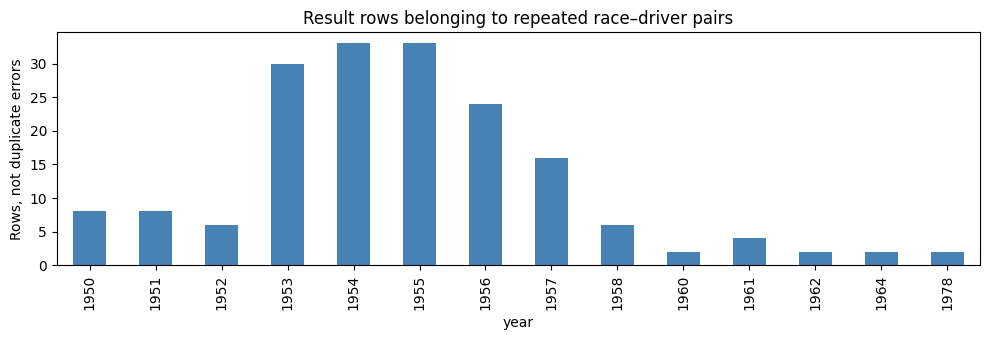

In [304]:
driver_repeated_result_details = driver_combination_duplicates["results"].merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
).merge(drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one").merge(
    constructors[["constructorId", "name"]].rename(columns={"name": "Constructor"}),
    on="constructorId", validate="many_to_one"
).merge(status, on="statusId", validate="many_to_one")
driver_repeated_result_groups = driver_repeated_result_details.groupby(
    ["year", "raceId", "name", "driverId", "forename", "surname"]
).agg(Rows=("resultId", "size"), Car_numbers=("number", lambda values: ", ".join(values.astype(str))),
      Constructors=("Constructor", lambda values: "; ".join(sorted(set(values)))))
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(driver_repeated_result_groups)
print("Actual result rows for the verified Moss example:")
display(driver_repeated_result_details.loc[
    driver_repeated_result_details["raceId"].eq(780) & driver_repeated_result_details["driverId"].eq(475),
    ["resultId", "raceId", "year", "name", "driverId", "forename", "surname", "constructorId", "number", "positionOrder", "points", "laps", "status"]
])
assert len(driver_repeated_result_groups) == 85
assert len(driver_repeated_result_details) == 176
assert not results.duplicated(["raceId", "driverId", "number"]).any()
driver_repeated_result_details.groupby("year").size().plot.bar(figsize=(10, 3.5), color="steelblue")
plt.title("Result rows belonging to repeated race–driver pairs")
plt.ylabel("Rows, not duplicate errors")
plt.tight_layout()
plt.show()


### Standings without a same-race result — Test the explanation

`driver_standings` describes the championship **after a round**, rather than who entered that race. A driver's accumulated points and wins can remain in the standings when the driver is absent.

We test this explanation for **all 8,664 unmatched pairs**: each driver already has a result in the same season at an earlier round, and every unmatched snapshot has exactly the same points and wins as that driver's preceding standings snapshot. The joined audit below shows examples and aggregate counts; all cases are retained in `driver_standings_nonparticipant_audit`.

For an external example, [Toyota's official 2008 championship archive](https://toyotagazooracing.com/archive/ms/en/season/ranking/2008/) records Super Aguri withdrawing after round four. [F1's final driver standings](https://www.formula1.com/en/results/2008/drivers) still include Sato and Davidson. Their absence from later race results therefore does not require deleting their standings rows. This supports the interpretation; matching points alone is not independent verification of every historical standing.


In [305]:
driver_standings_timeline = driver_standings.merge(
    races[["raceId", "year", "round", "name"]], on="raceId", validate="many_to_one"
).sort_values(["year", "driverId", "round"])
for column in ["points", "wins"]:
    driver_standings_timeline["Previous " + column] = driver_standings_timeline.groupby(["year", "driverId"])[column].shift()
driver_first_season_result = results[["raceId", "driverId"]].drop_duplicates().merge(
    races[["raceId", "year", "round"]], on="raceId", validate="many_to_one"
).groupby(["year", "driverId"])["round"].min().rename("First result round").reset_index()
driver_standings_nonparticipant_audit = driver_standings_timeline.merge(
    driver_pairs_without_results["driver_standings"], on=["raceId", "driverId"], validate="one_to_one"
).merge(driver_first_season_result, on=["year", "driverId"], how="left", validate="many_to_one").merge(
    drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
)
driver_standings_nonparticipant_audit["Earlier result this season"] = (
    driver_standings_nonparticipant_audit["First result round"].lt(driver_standings_nonparticipant_audit["round"])
)
driver_standings_nonparticipant_audit["Points unchanged"] = driver_standings_nonparticipant_audit["points"].eq(driver_standings_nonparticipant_audit["Previous points"])
driver_standings_nonparticipant_audit["Wins unchanged"] = driver_standings_nonparticipant_audit["wins"].eq(driver_standings_nonparticipant_audit["Previous wins"])
display(driver_standings_nonparticipant_audit[["Earlier result this season", "Points unchanged", "Wins unchanged"]].sum().to_frame("Supported pairs"))
display(driver_standings_nonparticipant_audit.loc[
    driver_standings_nonparticipant_audit["year"].eq(2008) & driver_standings_nonparticipant_audit["driverId"].isin([11, 19]),
    ["raceId", "name", "year", "round", "driverId", "forename", "surname", "points", "Previous points", "wins", "Previous wins", "First result round"]
].head(6))
assert len(driver_standings_nonparticipant_audit) == 8664
assert driver_standings_nonparticipant_audit[["Earlier result this season", "Points unchanged", "Wins unchanged"]].all().all()


,Supported pairs
Earlier result this season,8664
Points unchanged,8664
Wins unchanged,8664


,raceId,name,year,round,driverId,forename,surname,points,Previous points,wins,Previous wins,First result round
8291,22,Turkish Grand Prix,2008,5,11,Takuma,Sato,0.0,0.0,0,0.0,1
8292,23,Monaco Grand Prix,2008,6,11,Takuma,Sato,0.0,0.0,0,0.0,1
8293,24,Canadian Grand Prix,2008,7,11,Takuma,Sato,0.0,0.0,0,0.0,1
8294,25,French Grand Prix,2008,8,11,Takuma,Sato,0.0,0.0,0,0.0,1
8295,26,British Grand Prix,2008,9,11,Takuma,Sato,0.0,0.0,0,0.0,1
8296,27,German Grand Prix,2008,10,11,Takuma,Sato,0.0,0.0,0,0.0,1


### Check the constructor attached to the same driver and race

Valid race and driver IDs can still be combined with inconsistent constructor IDs. For `qualifying` and `sprint_results`, we compare `(raceId, driverId, constructorId)` with the triples in `results`. This comparison is not appropriate for lap/pit records, which have no constructor column, or standings, which may cover absent drivers.

Sprint triples all match. **Ten qualifying records across five 2015 races use `206` (Marussia) where the driver's race result uses `209` (Manor Marussia).** The full joined table below shows both record IDs, drivers, events and constructor names.

The earlier constructor-results investigation already found this naming connection. [F1's 2015 Rossi announcement](https://www.formula1.com/en/latest/article/marussia-hand-rossi-race-debut-in-singapore.6UMXTLJHDEu5LuWC4R0Djd) uses Marussia while identifying the team as Manor Marussia, and [the FIA's 2015 classification](https://www.fia.com/events/fia-formula-one-world-championship/season-2015/2015-classifications) lists one Manor Marussia entry. This supports investigating an ID inconsistency, rather than inferring a team change from the numbers alone.

**No correction is applied here.** These ten cases are saved for the qualifying review, where the official session records can be checked before changing those specific rows. The IDs are not globally merged.


In [306]:
driver_constructor_pair_summary = []
driver_constructor_pair_conflicts = {}
result_triples = results[["raceId", "driverId", "constructorId"]].drop_duplicates()
for name in ["qualifying", "sprint_results"]:
    table = driver_combination_tables[name]
    checked = table.merge(result_triples, on=["raceId", "driverId", "constructorId"],
        how="left", validate="many_to_one", indicator=True)
    conflicts = checked.loc[checked["_merge"].eq("left_only")].drop(columns="_merge")
    driver_constructor_pair_conflicts[name] = conflicts
    driver_constructor_pair_summary.append({"Table": name, "Records": len(table),
        "Constructor triples absent from results": len(conflicts)})
display(pd.DataFrame(driver_constructor_pair_summary))
conflicting_qualifying_race_results = results.merge(
    driver_constructor_pair_conflicts["qualifying"][["raceId", "driverId"]],
    on=["raceId", "driverId"], validate="many_to_one"
)
driver_qualifying_constructor_conflicts = driver_constructor_pair_conflicts["qualifying"][
    ["qualifyId", "raceId", "driverId", "constructorId"]
].rename(columns={"constructorId": "Qualifying constructorId"}).merge(
    conflicting_qualifying_race_results[["resultId", "raceId", "driverId", "constructorId"]].rename(columns={"constructorId": "Race constructorId"}),
    on=["raceId", "driverId"], validate="one_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one").merge(
    drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
)
for kind in ["Qualifying", "Race"]:
    driver_qualifying_constructor_conflicts = driver_qualifying_constructor_conflicts.merge(
        constructors[["constructorId", "name"]].rename(columns={
            "constructorId": kind + " constructorId", "name": kind + " constructor"}),
        on=kind + " constructorId", validate="many_to_one"
    )
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(driver_qualifying_constructor_conflicts)
assert len(driver_qualifying_constructor_conflicts) == 10
assert driver_qualifying_constructor_conflicts["Qualifying constructorId"].eq(206).all()
assert driver_qualifying_constructor_conflicts["Race constructorId"].eq(209).all()
assert driver_constructor_pair_conflicts["sprint_results"].empty


,Table,Records,Constructor triples absent from results
0,qualifying,10494,10
1,sprint_results,360,0


,qualifyId,raceId,driverId,Qualifying constructorId,resultId,Race constructorId,year,name,forename,surname,Qualifying constructor,Race constructor
0,6522,937,829,206,22751,209,2015,Belgian Grand Prix,Will,Stevens,Marussia,Manor Marussia
1,6523,937,833,206,22750,209,2015,Belgian Grand Prix,Roberto,Merhi,Marussia,Manor Marussia
2,6601,941,829,206,22829,209,2015,Russian Grand Prix,Will,Stevens,Marussia,Manor Marussia
3,6602,941,833,206,22828,209,2015,Russian Grand Prix,Roberto,Merhi,Marussia,Manor Marussia
4,6620,942,834,206,22848,209,2015,United States Grand Prix,Alexander,Rossi,Marussia,Manor Marussia
5,6621,942,829,206,22856,209,2015,United States Grand Prix,Will,Stevens,Marussia,Manor Marussia
6,6640,943,834,206,22871,209,2015,Mexican Grand Prix,Alexander,Rossi,Marussia,Manor Marussia
7,6641,943,829,206,22872,209,2015,Mexican Grand Prix,Will,Stevens,Marussia,Manor Marussia
8,6660,944,834,206,22894,209,2015,Brazilian Grand Prix,Alexander,Rossi,Marussia,Manor Marussia
9,6661,944,829,206,22893,209,2015,Brazilian Grand Prix,Will,Stevens,Marussia,Manor Marussia


### Combination investigation — Decisions and remaining work

| Finding | Decision |
|---|---|
| All six tables have valid driver and race references | No reference repair needed for these IDs. |
| Five related tables have unique full combinations | Preserve their records; repetitions of drivers across different laps/stops are expected. |
| 85 repeated result pairs | Keep original records. Show the verified shared-drive example; review other historical cases and the later row-selection policy when reaching `results`. |
| 8,664 standings pairs without a same-race result | Preserve cumulative snapshots, supported by the all-record chronological checks and the external withdrawal example. |
| 10 qualifying constructor conflicts | Original discovery list retained here. The source-supported correction of these 10 records is shown in the qualifying section below; this drivers audit does not alter driver records. |

Only audit tables, figures and explanations were added. A same-race match demonstrates consistency, not complete or accurate lap/pit coverage. Missing laps, stop timings and other table-specific issues still belong to those tables' reviews. This is not a claim that every historical repeated result has been individually verified.


In [307]:
for name, snapshot in driver_combination_snapshots.items():
    pd.testing.assert_frame_equal(driver_combination_tables[name], snapshot)
pd.testing.assert_frame_equal(drivers_clean, drivers_clean_combination_snapshot)
print("Passed: combination investigation preserved drivers_clean and every inspected source table.")


Passed: combination investigation preserved drivers_clean and every inspected source table.


## 3.4 lap_times.csv

### Before-cleaning inspection

Each row represents one recorded lap for a driver in a race. The key is `(raceId, driverId, lap)`; repeated driver–race pairs across laps are expected.


### 3.4.1 Lap Times: Initial Auditing & Placeholder Detection
Establishing the baseline snapshot and calculating the true volume of missing data by identifying structural NaNs alongside literal `\N` text sentinels.

In [308]:
print("Rows:", lap_times.shape[0])
print("Columns:", lap_times.shape[1])

display(lap_times.head(10))
lap_times.info()

Rows: 589081
Columns: 6


,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342
5,841,20,6,1,1:32.605,92605
6,841,20,7,1,1:32.502,92502
7,841,20,8,1,1:32.537,92537
8,841,20,9,1,1:33.240,93240
9,841,20,10,1,1:32.572,92572


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


In [309]:
missing = lap_times.isna().sum()
sentinels = lap_times.eq(r"\N").sum()

lap_inspection = pd.DataFrame({
    "Data type": lap_times.dtypes.astype(str),
    "Recognized missing": missing,
    r"\N placeholders": sentinels,
    "Total unavailable": missing + sentinels,
    "Unavailable %": (
        (missing + sentinels) / len(lap_times) * 100
    ).round(2)
})

display(lap_inspection)

,Data type,Recognized missing,\N placeholders,Total unavailable,Unavailable %
raceId,int64,0,0,0,0.0
driverId,int64,0,0,0,0.0
lap,int64,0,0,0,0.0
position,int64,0,0,0,0.0
time,object,0,0,0,0.0
milliseconds,int64,0,0,0,0.0


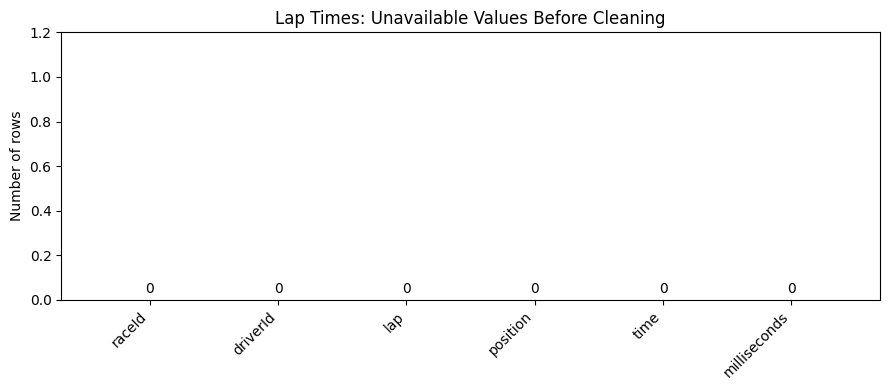

In [310]:
unavailable = missing + sentinels

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    unavailable.index,
    unavailable.values,
    color="steelblue"
)

ax.bar_label(bars, padding=3)
ax.set_title("Lap Times: Unavailable Values Before Cleaning")
ax.set_ylabel("Number of rows")
ax.set_ylim(0, max(1, unavailable.max()) * 1.2)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Convert `time` to numeric seconds

The CSV already supplies `milliseconds`. After checking its availability, divide by 1,000 and replace `time` in `lap_times_clean`. Original text stays in `lap_times`. An independent text conversion below verifies agreement; no columns are added.


### 3.4.2 Lap Times: Cleaning Pipeline & Time Conversion
Executing the core transformations: replacing text placeholders, casting `milliseconds` to strict numeric types, and standardizing the `time` column by mathematically converting milliseconds into seconds (while proving the result exactly matches the original text strings).

In [311]:
lap_times_raw_snapshot = lap_times.copy(deep=True)
lap_times_clean = lap_times.copy(deep=True)
lap_times_clean = lap_times_clean.replace(r"\N", np.nan)


In [312]:
# Verify milliseconds are available wherever the original time is present.
lap_times_clean["milliseconds"] = pd.to_numeric(lap_times_clean["milliseconds"], errors="raise")
assert not (lap_times_clean["time"].notna() & lap_times_clean["milliseconds"].isna()).any(), "A recorded time has no milliseconds."

# 1,000 milliseconds = 1 second. Replace time in the cleaned copy only.
lap_times_clean["time"] = lap_times_clean["milliseconds"] / 1000


In [313]:
# Independently compare original text with the converted time.
lap_text = lap_times["time"].replace(r"\N", np.nan).astype("string")
lap_text = lap_text.where(lap_text.str.count(":").ne(1), "0:" + lap_text)
lap_text_seconds = pd.to_timedelta(lap_text, errors="raise").dt.total_seconds()
lap_matches = np.isclose(lap_text_seconds, lap_times_clean["time"], atol=0.001, rtol=0, equal_nan=True)
print("Original time values agreeing with converted seconds:", lap_matches.sum())
assert lap_matches.all(), "Original time and milliseconds disagree."


Original time values agreeing with converted seconds: 589081


### Before/after values and types

Compare the same `time` column in the original and cleaned tables. Hour-based examples demonstrate parsing support, not that unusually long records have been verified.


In [314]:
display(pd.DataFrame({
    "time BEFORE (text)": lap_times["time"].head(10),
    "time AFTER (seconds)": lap_times_clean["time"].head(10)
}))
print("time BEFORE type:", lap_times["time"].dtype)
print("time AFTER type:", lap_times_clean["time"].dtype)
hour_examples = lap_times["time"].astype("string").str.count(":").eq(2).fillna(False)
display(pd.DataFrame({
    "time BEFORE (text)": lap_times.loc[hour_examples, "time"],
    "time AFTER (seconds)": lap_times_clean.loc[hour_examples, "time"],
    "milliseconds": lap_times_clean.loc[hour_examples, "milliseconds"]
}).head(5))


,time BEFORE (text),time AFTER (seconds)
0,1:38.109,98.109
1,1:33.006,93.006
2,1:32.713,92.713
3,1:32.803,92.803
4,1:32.342,92.342
5,1:32.605,92.605
6,1:32.502,92.502
7,1:32.537,92.537
8,1:33.240,93.240
9,1:32.572,92.572


time BEFORE type: object
time AFTER type: float64


,time BEFORE (text),time AFTER (seconds),milliseconds
7916,2:05:05.152,7505.152,7505152
7985,2:05:04.226,7504.226,7504226
8020,2:05:06.656,7506.656,7506656
8089,2:05:05.034,7505.034,7505034
8165,2:05:01.488,7501.488,7501488


The cleaned `time` column contains seconds calculated from `milliseconds / 1000`. We independently converted original text to seconds and checked agreement. This verifies conversion consistency, not underlying record accuracy. Original rows and columns are preserved; no missing values are filled.


### Key and reference checks


### 3.4.3 Lap Times: Relational Integrity & Numeric Auditing
Validating primary and foreign keys to ensure no duplicate race-driver-lap combinations exist, and that every lap maps back to a valid driver and race in the reference tables. This step also verifies the distributions of lap, position, and time features using logarithmic visualizations to expose anomalies.

In [315]:
key_columns = ["raceId", "driverId", "lap"]

print("Missing key values:")
display(lap_times_clean[key_columns].isna().sum())

print(
    "Duplicate race–driver–lap records:",
    lap_times_clean.duplicated(key_columns).sum()
)

# Display problem records, if any.
duplicates = lap_times_clean.duplicated(key_columns, keep=False)

if duplicates.any():
    display(
        lap_times_clean.loc[duplicates]
        .sort_values(key_columns)
        .head(20)
    )

assert lap_times_clean[key_columns].notna().all().all(), \
    "Missing raceId, driverId, or lap found"

assert not duplicates.any(), \
    "Repeated race–driver–lap records found"

print("Passed: race–driver–lap combinations are unique and non-null.")

Missing key values:


raceId      0
driverId    0
lap         0
dtype: int64

Duplicate race–driver–lap records: 0
Passed: race–driver–lap combinations are unique and non-null.


In [316]:
unknown_races = ~lap_times_clean["raceId"].isin(races["raceId"])
unknown_drivers = ~lap_times_clean["driverId"].isin(drivers["driverId"])

print("Rows with unknown race IDs:", unknown_races.sum())
print("Rows with unknown driver IDs:", unknown_drivers.sum())

if unknown_races.any():
    display(lap_times_clean.loc[unknown_races].head(20))

if unknown_drivers.any():
    display(lap_times_clean.loc[unknown_drivers].head(20))

assert not unknown_races.any(), \
    "Some race IDs do not exist in races"

assert not unknown_drivers.any(), \
    "Some driver IDs do not exist in drivers"

print("Passed: all race and driver IDs exist in their reference tables.")

Rows with unknown race IDs: 0
Rows with unknown driver IDs: 0
Passed: all race and driver IDs exist in their reference tables.


In [317]:
# Deduplicate only the lookup pairs, not the lap records.
result_pairs = results[["raceId", "driverId"]].drop_duplicates()

lap_pairs = (
    lap_times_clean[["raceId", "driverId"]]
    .drop_duplicates()
)

pair_check = lap_pairs.merge(
    result_pairs,
    on=["raceId", "driverId"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

unmatched_pairs = pair_check.loc[
    pair_check["_merge"].eq("left_only"),
    ["raceId", "driverId"]
]

print("Driver–race pairs absent from results:", len(unmatched_pairs))

if not unmatched_pairs.empty:
    display(unmatched_pairs.head(20))

assert unmatched_pairs.empty, \
    "Some lap records belong to driver–race pairs absent from results"

print("Passed: all lap driver–race pairs exist in results.")

Driver–race pairs absent from results: 0
Passed: all lap driver–race pairs exist in results.


The combination of raceId, driverId, and lap is unique and non-null.
All race and driver references exist, and every recorded driver–race pair
has a corresponding result record. Repeated driver–race pairs across
different laps are expected and were preserved.

### Unusual-value investigation

Long recorded durations are inspected, not automatically removed. Their cause is not established by their size alone.


In [318]:
display(
    lap_times_clean[
        ["lap", "position", "time"]
    ].describe().T
)

print("Rows with lap <= 0:",
      lap_times_clean["lap"].le(0).sum())

print("Rows with position <= 0:",
      lap_times_clean["position"].le(0).sum())

print("Rows with time <= 0:",
      lap_times_clean["time"].le(0).sum())

,count,mean,std,min,25%,50%,75%,max
lap,589081.0,30.018104,18.407126,1.000,14.000,29.000,44.00,87.000
position,589081.0,9.661951,5.528553,1.000,5.000,9.000,14.00,24.000
time,589081.0,95.799445,76.399730,55.404,82.041,90.608,101.93,7507.547


Rows with lap <= 0: 0
Rows with position <= 0: 0
Rows with time <= 0: 0


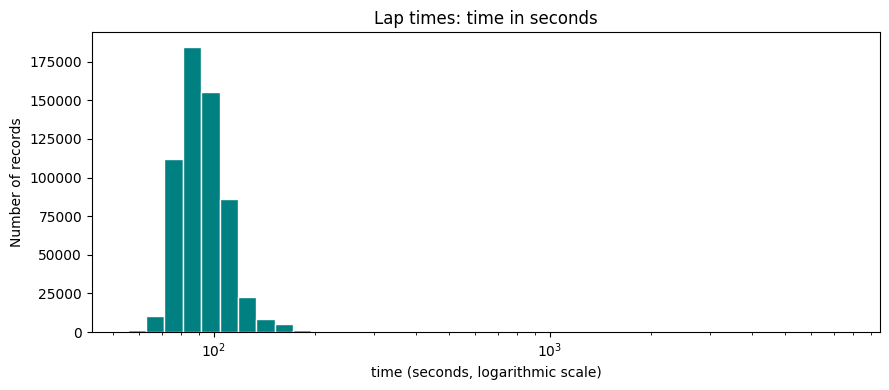

In [319]:
# Logarithmic bins show typical and unusually long durations together.
values = lap_times_clean.loc[lap_times_clean["time"] > 0, "time"].dropna()
if not values.empty:
    bins = np.geomspace(values.min(), values.max(), 40) if values.min() < values.max() else 10
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(values, bins=bins, color="teal", edgecolor="white")
    ax.set_xscale("log")
    ax.set_title("Lap times: time in seconds")
    ax.set_xlabel("time (seconds, logarithmic scale)")
    ax.set_ylabel("Number of records")
    plt.tight_layout()
    plt.show()


In [320]:
print("Largest time values — flagged for investigation, not removed:")
display(
    lap_times_clean.nlargest(10, "time")[
        ["raceId", "driverId", "lap", "position",
         "time", "milliseconds"]
    ]
)

Largest time values — flagged for investigation, not removed:


,raceId,driverId,lap,position,time,milliseconds
8372,847,2,25,4,7507.547,7507547
8020,847,13,25,3,7506.656,7506656
8426,847,808,25,5,7506.243,7506243
8621,847,155,25,2,7506.095,7506095
7916,847,20,25,1,7505.152,7505152
8089,847,17,25,7,7505.034,7505034
7985,847,4,25,8,7504.226,7504226
8495,847,814,25,6,7503.980,7503980
8876,847,37,25,9,7503.795,7503795
8234,847,18,25,11,7503.775,7503775


### Final verification


In [321]:
final_checks = pd.Series({
    "Row count unchanged":
        len(lap_times_clean) == len(lap_times),

    "No remaining placeholders":
        not lap_times_clean.eq(r"\N").any().any(),

    "Key columns non-null":
        lap_times_clean[["raceId", "driverId", "lap"]]
        .notna().all().all(),

    "Race–driver–lap key unique":
        not lap_times_clean.duplicated(
            ["raceId", "driverId", "lap"]
        ).any(),

    "time is numeric seconds":
        pd.api.types.is_numeric_dtype(
            lap_times_clean["time"]
        )
})

display(final_checks.to_frame("Passed"))

assert final_checks.all(), "Investigate failed checks."

,Passed
Row count unchanged,True
No remaining placeholders,True
Key columns non-null,True
Race–driver–lap key unique,True
time is numeric seconds,True


### Extended audit — Numeric validity and position consistency

We check positive integer lap numbers and positions, finite positive durations, missing/blank timing text and full duplicate rows. We also compare positions with the number of distinct drivers listed in that event's results. A driver listed in results is not necessarily a starter, so this is an upper-bound consistency check rather than a count of starters.

Positions describe the recorded order on a lap, not the final finishing order. A different final position is therefore expected. We check whether two drivers have the same recorded position on the same numbered lap, and show the outcome instead of assuming it passes.


### 3.4.4 Lap Times: Sequence Validation & Result Discrepancies
Running cross-table assertions to verify the logic of the timing sequences (e.g., sequences must start at lap 1, without internal gaps). This audit systematically flags discrepancies between the timing row counts in `lap_times` and the officially completed `laps` recorded in the `results` table.

In [322]:
lap_numeric_checks = pd.Series({
    "No missing values": lap_times_clean.notna().all().all(),
    "No blank original time strings": not lap_times["time"].astype("string").str.strip().eq("").any(),
    "No outer whitespace in original time": lap_times["time"].eq(lap_times["time"].str.strip()).all(),
    "No full duplicate rows": not lap_times_clean.duplicated().any(),
    "Lap numbers are positive integers": pd.api.types.is_integer_dtype(lap_times_clean["lap"]) and lap_times_clean["lap"].gt(0).all(),
    "Positions are positive integers": pd.api.types.is_integer_dtype(lap_times_clean["position"]) and lap_times_clean["position"].gt(0).all(),
    "Seconds are finite and positive": np.isfinite(lap_times_clean["time"]).all() and lap_times_clean["time"].gt(0).all(),
    "Milliseconds are positive integers": pd.api.types.is_integer_dtype(lap_times_clean["milliseconds"]) and lap_times_clean["milliseconds"].gt(0).all()
})
display(lap_numeric_checks.to_frame("Passed"))
assert lap_numeric_checks.all()
lap_event_field_size = results.groupby("raceId")["driverId"].nunique()
lap_position_checks = pd.Series({
    "Positions above event's result field size": int(lap_times_clean["position"].gt(lap_times_clean["raceId"].map(lap_event_field_size)).sum()),
    "Rows with repeated race-lap-position": int(lap_times_clean.duplicated(["raceId", "lap", "position"], keep=False).sum())
})
display(lap_position_checks.to_frame("Rows"))
assert lap_position_checks.eq(0).all()


,Passed
No missing values,True
No blank original time strings,True
No outer whitespace in original time,True
No full duplicate rows,True
Lap numbers are positive integers,True
Positions are positive integers,True
Seconds are finite and positive,True
Milliseconds are positive integers,True


,Rows
Positions above event's result field size,0
Rows with repeated race-lap-position,0


### Check lap sequences against completed laps in results

For each driver–race pair, we calculate the first lap, last lap and number of recorded rows. This distinguishes missing values **inside rows** from missing **lap records**. Every existing sequence starts at lap 1 with no internal gaps; this does not establish that it belongs to the correct driver or includes every completed lap.

We then join to `results.laps`, meaning the recorded number of completed/classified laps. The join is restricted to the relevant driver–race pairs before checking uniqueness, so unrelated historical shared drives do not multiply rows.

The complete discrepancy table below shows **90 pairs: 37 with more recorded laps and 53 with fewer**. We do not force the counts to agree: either table may have an issue, and classification conventions can differ.


In [323]:
lap_sequence_audit = lap_times_clean.groupby(["raceId", "driverId"]).agg(
    Recorded_laps=("lap", "size"), First_lap=("lap", "min"), Last_lap=("lap", "max")
).reset_index()
lap_sequence_audit["Internal missing laps"] = (
    lap_sequence_audit["Last_lap"] - lap_sequence_audit["First_lap"] + 1 - lap_sequence_audit["Recorded_laps"]
)
lap_relevant_results = results.merge(
    lap_sequence_audit[["raceId", "driverId"]], on=["raceId", "driverId"], validate="many_to_one"
)
lap_sequence_audit = lap_sequence_audit.merge(
    lap_relevant_results[["resultId", "raceId", "driverId", "laps", "positionText", "statusId"]],
    on=["raceId", "driverId"], validate="one_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one").merge(
    drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(status, on="statusId", validate="many_to_one")
lap_sequence_audit["Count difference"] = lap_sequence_audit["Recorded_laps"] - lap_sequence_audit["laps"]
assert lap_sequence_audit["First_lap"].eq(1).all()
assert lap_sequence_audit["Internal missing laps"].eq(0).all()
lap_count_discrepancies = lap_sequence_audit.loc[lap_sequence_audit["Count difference"].ne(0)].copy()
lap_count_discrepancies["Review"] = "Needs individual investigation"
lap_count_discrepancies.loc[lap_count_discrepancies["raceId"].eq(903), "Review"] = "China 2014: early flag/classified distance"
display(pd.Series({
    "Driver-race sequences checked": len(lap_sequence_audit),
    "Sequences not starting at 1": int(lap_sequence_audit["First_lap"].ne(1).sum()),
    "Sequences with internal gaps": int(lap_sequence_audit["Internal missing laps"].gt(0).sum()),
    "Recorded count greater than results.laps": int(lap_sequence_audit["Count difference"].gt(0).sum()),
    "Recorded count smaller than results.laps": int(lap_sequence_audit["Count difference"].lt(0).sum())
}).to_frame("Pairs"))
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
    display(lap_count_discrepancies[["raceId", "year", "name", "driverId", "forename", "surname", "Recorded_laps", "laps", "Count difference", "positionText", "status", "Review"]])
assert len(lap_count_discrepancies) == 90


,Pairs
Driver-race sequences checked,11041
Sequences not starting at 1,0
Sequences with internal gaps,0
Recorded count greater than results.laps,37
Recorded count smaller than results.laps,53


,raceId,year,name,driverId,forename,surname,Recorded_laps,laps,Count difference,positionText,status,Review
240,13,2009,Italian Grand Prix,17,Mark,Webber,52,0,52,R,Collision,Needs individual investigation
246,13,2009,Italian Grand Prix,67,Sébastien,Buemi,19,52,-33,13,+1 Lap,Needs individual investigation
377,20,2008,Bahrain Grand Prix,16,Adrian,Sutil,55,56,-1,19,+2 Laps,Needs individual investigation
389,21,2008,Spanish Grand Prix,7,Sébastien,Bourdais,4,7,-3,R,Collision,Needs individual investigation
452,24,2008,Canadian Grand Prix,12,Nelson,Piquet Jr.,39,43,-4,R,Brakes,Needs individual investigation
498,26,2008,British Grand Prix,21,Giancarlo,Fisichella,26,16,10,R,Spun off,Needs individual investigation
779,40,2007,Monaco Grand Prix,24,Vitantonio,Liuzzi,1,2,-1,R,Accident,Needs individual investigation
805,42,2007,United States Grand Prix,2,Nick,Heidfeld,55,56,-1,R,Transmission,Needs individual investigation
1252,63,2006,French Grand Prix,17,Mark,Webber,53,55,-2,R,Wheel rim,Needs individual investigation
1255,63,2006,French Grand Prix,22,Rubens,Barrichello,18,28,-10,R,Engine,Needs individual investigation


#### See the cross-table problem before making changes

We join `results` and `lap_times` using **both `raceId` and `driverId`**. For each driver in each race, we compare `results.laps` with the number of timing rows. The table above lists all **90 differences out of 11,041 matched pairs**. The plots below show these differences before any lap-count or driver-assignment correction.

A flag means **investigate this pair**, not **this value is wrong**. For example, a timing sequence may be incomplete, a driver ID may be wrong, or classified distance may legitimately differ from timing distance. We consult sources only after this consistency check identifies a case. Matching counts also do not prove that every timing value is correct.

The flags live in a separate audit table; we do not add columns to the clean tables.


Matched driver–race pairs: 11041
Flagged pairs: 90
Flagged percentage: 0.82


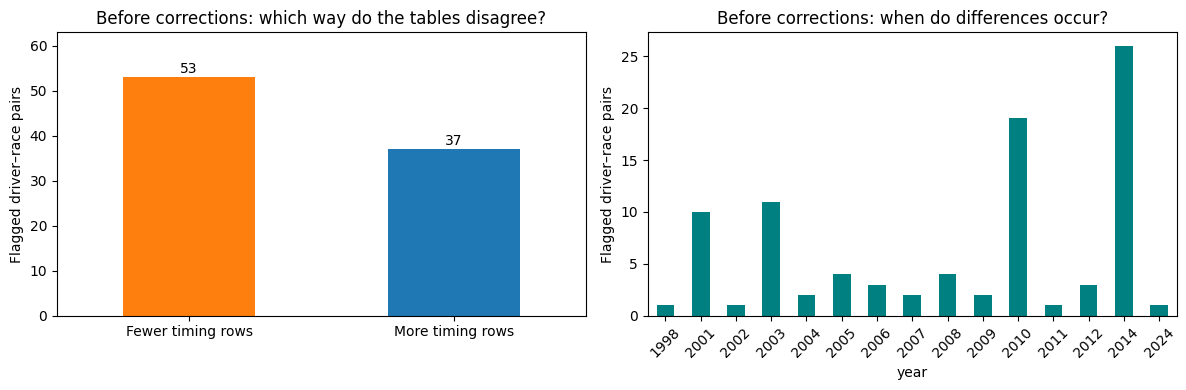

In [324]:
# Keep the original cross-table findings for the final evidence trail.
lap_consistency_flags_before = lap_count_discrepancies[[
    "raceId", "driverId", "year", "name", "forename", "surname",
    "laps", "Recorded_laps", "Count difference"
]].copy().rename(columns={"laps": "Original result laps", "Recorded_laps": "Original timing rows"})
lap_consistency_flags_before["Flag"] = "Fewer timing rows than completed laps"
lap_consistency_flags_before.loc[
    lap_consistency_flags_before["Count difference"].gt(0), "Flag"
] = "More timing rows than completed laps"
print("Matched driver–race pairs:", len(lap_sequence_audit))
print("Flagged pairs:", len(lap_consistency_flags_before))
print("Flagged percentage:", round(len(lap_consistency_flags_before) / len(lap_sequence_audit) * 100, 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
directions = pd.Series({
    "Fewer timing rows": int(lap_consistency_flags_before["Count difference"].lt(0).sum()),
    "More timing rows": int(lap_consistency_flags_before["Count difference"].gt(0).sum())
})
directions.plot.bar(ax=axes[0], color=["tab:orange", "tab:blue"], rot=0)
axes[0].set_title("Before corrections: which way do the tables disagree?")
axes[0].set_ylabel("Flagged driver–race pairs")
for i, count in enumerate(directions):
    axes[0].text(i, count + 1, str(count), ha="center")
axes[0].set_ylim(0, directions.max() + 10)
lap_consistency_flags_before.groupby("year").size().plot.bar(ax=axes[1], color="teal", rot=45)
axes[1].set_title("Before corrections: when do differences occur?")
axes[1].set_ylabel("Flagged driver–race pairs")
plt.tight_layout()
plt.show()
assert len(lap_consistency_flags_before) == 90


### Missing-record coverage — Before 1996 and within the covered period

[The Jolpica project's lap endpoint documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/laps.md), for the successor to Ergast, states that lap data starts in **1996**. Our actual local records cover 1996–2024. We do not invent timings for 1950–1995.

Within 1996–2024, every race has at least some lap records. Nevertheless, **455 result pairs have none**: 453 have `results.laps = 0`, which is consistent with having no completed lap to time. The remaining **two have positive completed-lap counts**, so they need investigation. The joined table identifies them; their missing timings cannot be reconstructed from a mean or median.

The annual graph measures the proportion of positive-lap result entries with at least one timing row. It checks coverage of drivers, not completeness or correctness of every lap.


,Entries
Result entries without lap records (1996+),455
"Of these, zero completed laps in results",453
"Of these, positive completed laps in results",2


,resultId,raceId,year,name,driverId,forename,surname,laps,positionText,status
132,2872,155,2001,Italian Grand Prix,55,Jean,Alesi,52,8,+1 Lap
256,7811,13,2009,Italian Grand Prix,153,Jaime,Alguersuari,19,R,Retired


,Positive_lap_entries,Entries_with_timing,Coverage (%)
year,,,
1996,310,310,100.00
1997,355,355,100.00
1998,329,329,100.00
1999,330,330,100.00
2000,354,354,100.00
2001,355,354,99.72
2002,341,341,100.00
2003,307,307,100.00
2004,347,347,100.00


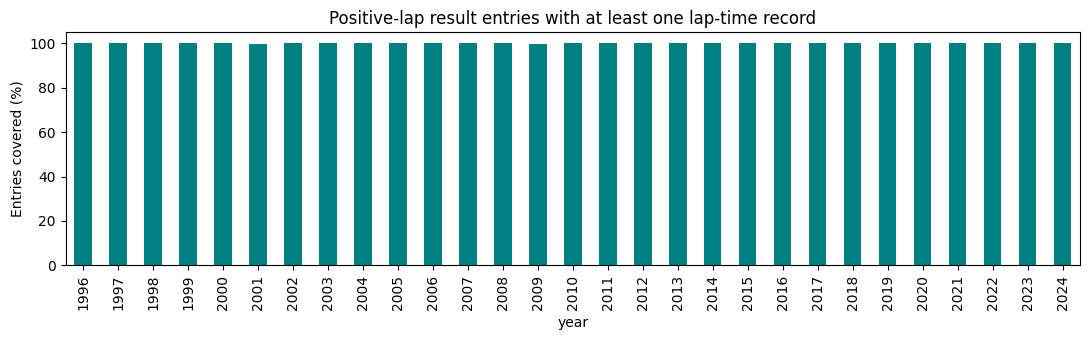

In [325]:
lap_coverage_audit = results[["resultId", "raceId", "driverId", "laps", "positionText", "statusId"]].merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
)
lap_coverage_audit = lap_coverage_audit.loc[lap_coverage_audit["year"].ge(1996)].merge(
    lap_times_clean[["raceId", "driverId"]].drop_duplicates(),
    on=["raceId", "driverId"], how="left", validate="one_to_one", indicator=True
)
lap_coverage_audit["Has lap records"] = lap_coverage_audit["_merge"].eq("both")
lap_missing_entries = lap_coverage_audit.loc[~lap_coverage_audit["Has lap records"]].drop(columns="_merge").merge(
    drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(status, on="statusId", validate="many_to_one")
lap_missing_positive_entries = lap_missing_entries.loc[lap_missing_entries["laps"].gt(0)].copy()
display(pd.Series({
    "Result entries without lap records (1996+)": len(lap_missing_entries),
    "Of these, zero completed laps in results": int(lap_missing_entries["laps"].eq(0).sum()),
    "Of these, positive completed laps in results": len(lap_missing_positive_entries)
}).to_frame("Entries"))
display(lap_missing_positive_entries[["resultId", "raceId", "year", "name", "driverId", "forename", "surname", "laps", "positionText", "status"]])
lap_annual_coverage = lap_coverage_audit.loc[lap_coverage_audit["laps"].gt(0)].groupby("year").agg(
    Positive_lap_entries=("driverId", "size"), Entries_with_timing=("Has lap records", "sum")
)
lap_annual_coverage["Coverage (%)"] = 100 * lap_annual_coverage["Entries_with_timing"] / lap_annual_coverage["Positive_lap_entries"]
display(lap_annual_coverage.round(2))
lap_annual_coverage["Coverage (%)"].plot.bar(figsize=(11, 3.5), color="teal")
plt.title("Positive-lap result entries with at least one lap-time record")
plt.ylabel("Entries covered (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()
assert len(lap_missing_entries) == 455
assert len(lap_missing_positive_entries) == 2
assert set(lap_coverage_audit["raceId"]) == set(lap_times_clean["raceId"])


### Evidence for preserving unusual timings and classified-distance differences

Sources reviewed on **11 October 2026**. Observations are manually documented; the notebook does not scrape these pages when run.

| Observation | Local evidence shown below | External evidence and decision |
|---|---|---|
| Canada 2011: timings around two hours | 23 drivers have hour-format timings at lap 25 | [F1's race history](https://www.formula1.com/en/latest/article/canada-2011-torrential-rain-a-safety-car-record-and-buttons-charge-the.1ZWPateMlCFLZ8U6KQBNXj) documents the prolonged rain stoppage. Their shared location and size are consistent with suspension time in the timing interval. Preserve; do not interpret them as continuous racing pace. |
| Britain 2014: timings around one hour | 20 drivers have hour-format timings at lap 1 or 2 | [Red Bull's race report](https://www.redbull.com/us-en/british-grand-prix-wrap-up) documents an hour-long stoppage after Räikkönen's crash. Preserve; the event explains the scale, without independently verifying every millisecond. |
| Sakhir 2020: shortest record, 55.404 seconds | Russell, driver 847, lap 80 | [Official fastest laps](https://www.formula1.com/en/results/2020/races/1060/sakhir/fastest-laps) confirms the exact driver, lap and time. Preserve. |
| China 2014: 20 driver sequences exceed classified distance by two laps | Every affected sequence differs by exactly +2 | [F1's race report](https://www.formula1.com/en/latest/article/race-hamilton-dominates-alonso-beats-red-bulls-in-china.vS3tgs1DaHdohe9z8aPTZ.vS3tgs1DaHdohe9z8aPTZ) explains that results were declared at lap 54 of 56 following the early flag. Preserve recorded timing rows and classified result laps as distinct measurements. |

Hour format is a transparent investigation category, not a threshold defining wrong data. Smaller unusual durations can have other causes, including pit stops and safety-car periods; no blanket outlier removal is applied.


### 3.4.5 Lap Times: Edge-Case Investigation & Final Validation
Manually reviewing known historical exceptions, including hour-long lap records (e.g., red flag stoppages) and the China 2014 distance discrepancy. Concludes with a rigorous suite of assertion tests confirming that only the targeted numeric conversions were applied.

Rows  Shortest_seconds  Longest_seconds
raceId year name                lap                                         
847    2011 Canadian Grand Prix 25     23          7469.869         7507.547
908    2014 British Grand Prix  1       2          3698.698         3702.636
                                2      18          3667.384         3803.459

,raceId,driverId,lap,position,time,milliseconds,year,name,forename,surname
0,1046,847,80,14,55.404,55404,2020,Sakhir Grand Prix,George,Russell


,Pairs
Review,
China 2014: early flag/classified distance,20
Needs individual investigation,70


,raceId,year,name,driverId,lap,time,milliseconds
0,847,2011,Canadian Grand Prix,18,24,136.959,136959
1,847,2011,Canadian Grand Prix,18,25,7503.775,7503775
2,847,2011,Canadian Grand Prix,18,26,141.746,141746
3,908,2014,British Grand Prix,1,1,139.816,139816
4,908,2014,British Grand Prix,1,2,3698.495,3698495
5,908,2014,British Grand Prix,1,3,100.284,100284


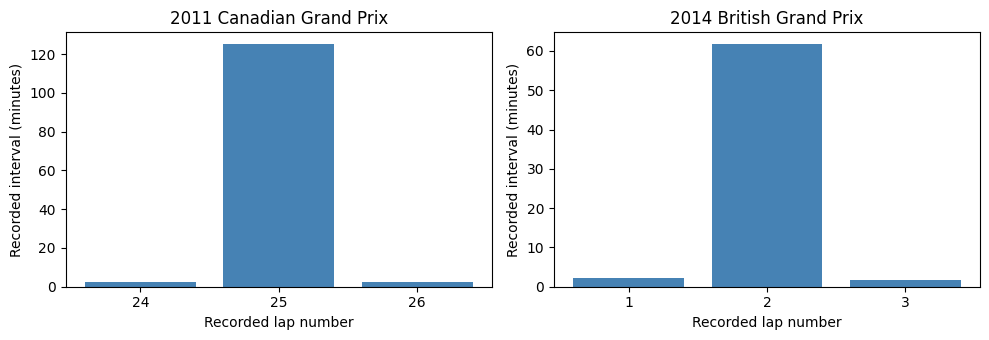

In [326]:
lap_hour_records = lap_times_clean.loc[hour_examples].merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
)
display(lap_hour_records.groupby(["raceId", "year", "name", "lap"]).agg(
    Rows=("driverId", "size"), Shortest_seconds=("time", "min"), Longest_seconds=("time", "max")
))
display(lap_times_clean.nsmallest(1, "time").merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
).merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"))
lap_china_distance_evidence = lap_count_discrepancies.loc[lap_count_discrepancies["raceId"].eq(903)]
assert len(lap_china_distance_evidence) == 20
assert lap_china_distance_evidence["Count difference"].eq(2).all()
display(lap_count_discrepancies.groupby("Review").size().to_frame("Pairs"))

# Show neighbouring recorded laps for one driver from each reviewed stoppage.
lap_stoppage_examples = lap_times_clean.loc[
    (lap_times_clean["raceId"].eq(847) & lap_times_clean["driverId"].eq(18) & lap_times_clean["lap"].between(24, 26))
    | (lap_times_clean["raceId"].eq(908) & lap_times_clean["driverId"].eq(1) & lap_times_clean["lap"].between(1, 3))
].merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
display(lap_stoppage_examples[["raceId", "year", "name", "driverId", "lap", "time", "milliseconds"]])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (race_id, group) in zip(axes, lap_stoppage_examples.groupby("raceId")):
    ax.bar(group["lap"].astype(str), group["time"] / 60, color="steelblue")
    ax.set_title(str(group["year"].iloc[0]) + " " + group["name"].iloc[0])
    ax.set_xlabel("Recorded lap number")
    ax.set_ylabel("Recorded interval (minutes)")
plt.tight_layout()
plt.show()


### Unresolved cases — Evidence for further investigation

After the 20 China cases are explained, **70 lap-count discrepancies remain unresolved**, alongside the **two positive-lap result entries with no timing rows**. These sets overlap in their possible causes; they are not 72 proven independent errors.

Two particularly clear events deserve investigation:

- **Italy 2001 (`raceId=155`):** `results` and the [official classification](https://www.formula1.com/en/results/2001/races/717/italy/race-result) give Alesi 52 laps and Trulli 0. Local lap rows instead give Trulli 52 and Alesi none. Other 2001 Alesi/Trulli count differences also appear in the full discrepancy table. This suggests possible attribution problems, but matching counts alone does not prove which driver owns each timing.
- **Italy 2009 (`raceId=13`):** `results` and the [official classification](https://www.formula1.com/en/results/2009/races/855/italy/race-result) give Buemi 52, Alguersuari 19 and Webber 0 laps. Local lap rows give Webber 52, Buemi 19 and Alguersuari none. The joined table below exposes this inconsistency. We need driver-specific timing evidence before relabeling rows.

**Treatment now:** keep the raw and cleaned timing records, save explicit audit lists, and do not invent missing lap times, swap IDs or delete records merely to make totals agree. Ask the TA whether to recover these timings from an authoritative lap chart or exclude the affected sequences from a particular lap-based analysis. Current-race timings must not be used as pre-race prediction inputs. This table's review has identified issues; it is not yet an all-clear on underlying timing accuracy.

**Stage note:** This is the audit before the source-backed corrections later in the results section. See **“Complete investigation of lap-count differences”** for the current decisions and final counts.


In [327]:
lap_attribution_evidence = results.loc[
    (results["raceId"].eq(155) & results["driverId"].isin([15, 55]))
    | (results["raceId"].eq(13) & results["driverId"].isin([17, 67, 153])),
    ["resultId", "raceId", "driverId", "laps", "positionText"]
].merge(
    lap_times_clean.groupby(["raceId", "driverId"]).size().rename("Recorded lap rows").reset_index(),
    on=["raceId", "driverId"], how="left", validate="one_to_one"
).merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one").merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
)
# Zero here describes an actual count of rows, not an imputed lap time.
lap_attribution_evidence["Recorded lap rows"] = lap_attribution_evidence["Recorded lap rows"].fillna(0).astype(int)
display(lap_attribution_evidence[["raceId", "year", "name", "driverId", "forename", "surname", "laps", "Recorded lap rows", "positionText"]])
lap_unresolved_count_discrepancies = lap_count_discrepancies.loc[lap_count_discrepancies["raceId"].ne(903)].copy()
assert len(lap_unresolved_count_discrepancies) == 70


,raceId,year,name,driverId,forename,surname,laps,Recorded lap rows,positionText
0,155,2001,Italian Grand Prix,55,Jean,Alesi,52,0,8
1,155,2001,Italian Grand Prix,15,Jarno,Trulli,0,52,R
2,13,2009,Italian Grand Prix,67,Sébastien,Buemi,52,19,13
3,13,2009,Italian Grand Prix,153,Jaime,Alguersuari,19,0,R
4,13,2009,Italian Grand Prix,17,Mark,Webber,0,52,R


### Lap times — Final preservation and before/after checks

There are **589,081 rows and the original 6 columns**. No values are missing inside the existing rows, so no filling is needed there. Missing records and attribution discrepancies are documented separately above.

The only data transformation is the existing replacement of `time` text with numeric seconds. The independent text conversion agrees with milliseconds for every row. All other values are preserved. The table below checks missing counts and types before and after; assertions also verify the full table against the documented conversion and prove the raw data stayed unchanged.

**Stage note:** This is the audit before the source-backed corrections later in the results section. See **“Complete investigation of lap-count differences”** for the current decisions and final counts.


In [328]:
lap_final_comparison = pd.DataFrame({
    "Type before": lap_times.dtypes.astype(str), "Type after": lap_times_clean.dtypes.astype(str),
    "Missing before": lap_times.replace(r"\N", np.nan).isna().sum(),
    "Missing after": lap_times_clean.isna().sum()
})
display(lap_final_comparison)
lap_expected_clean = lap_times.replace(r"\N", np.nan).copy(deep=True)
lap_expected_clean["milliseconds"] = pd.to_numeric(lap_expected_clean["milliseconds"], errors="raise")
lap_expected_clean["time"] = lap_expected_clean["milliseconds"] / 1000
pd.testing.assert_frame_equal(lap_times_clean, lap_expected_clean)
pd.testing.assert_frame_equal(lap_times, lap_times_raw_snapshot)
assert lap_times_clean.shape == lap_times.shape == (589081, 6)
assert lap_times_clean.columns.equals(lap_times.columns)
assert lap_matches.all()
print("Passed: structural, reference, numeric and conversion checks; raw data preserved. Cross-table discrepancy lists remain open for investigation.")


,Type before,Type after,Missing before,Missing after
raceId,int64,int64,0,0
driverId,int64,int64,0,0
lap,int64,int64,0,0
position,int64,int64,0,0
time,object,float64,0,0
milliseconds,int64,int64,0,0


Passed: structural, reference, numeric and conversion checks; raw data preserved. Cross-table discrepancy lists remain open for investigation.


In [329]:
lap_times_clean.info()
assert lap_times_clean.columns.equals(lap_times.columns), "Unexpected added or removed lap columns"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   raceId        589081 non-null  int64  
 1   driverId      589081 non-null  int64  
 2   lap           589081 non-null  int64  
 3   position      589081 non-null  int64  
 4   time          589081 non-null  float64
 5   milliseconds  589081 non-null  int64  
dtypes: float64(1), int64(5)
memory usage: 27.0 MB


## 3.5 pit_stops.csv

### 3.5.1 Pit Stops: Initial Auditing & Placeholder Detection
Establishing the baseline snapshot of the `pit_stops` table and visualizing the exact volume of missing data by identifying structural NaNs alongside literal `\N` text sentinels.

### Before-cleaning inspection

Each row represents one recorded pit stop. The key is `(raceId, driverId, stop)`. `time` is a clock time; `duration` is elapsed time.


In [330]:
print("Rows:", pit_stops.shape[0])
print("Columns:", pit_stops.shape[1])

display(pit_stops.head(10))
pit_stops.info()

Rows: 11371
Columns: 7


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842
5,841,22,1,13,17:24:29,23.643,23643
6,841,20,1,14,17:25:17,22.603,22603
7,841,814,1,14,17:26:03,24.863,24863
8,841,816,1,14,17:26:50,25.259,25259
9,841,67,1,15,17:27:34,25.342,25342


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


In [331]:
pit_missing = pit_stops.isna().sum()
pit_sentinels = pit_stops.eq(r"\N").sum()

pit_inspection = pd.DataFrame({
    "Data type": pit_stops.dtypes.astype(str),
    "Recognized missing": pit_missing,
    r"\N placeholders": pit_sentinels,
    "Total unavailable": pit_missing + pit_sentinels,
    "Unavailable %": (
        (pit_missing + pit_sentinels) / len(pit_stops) * 100
    ).round(2)
})

display(pit_inspection)

,Data type,Recognized missing,\N placeholders,Total unavailable,Unavailable %
raceId,int64,0,0,0,0.0
driverId,int64,0,0,0,0.0
stop,int64,0,0,0,0.0
lap,int64,0,0,0,0.0
time,object,0,0,0,0.0
duration,object,0,0,0,0.0
milliseconds,int64,0,0,0,0.0


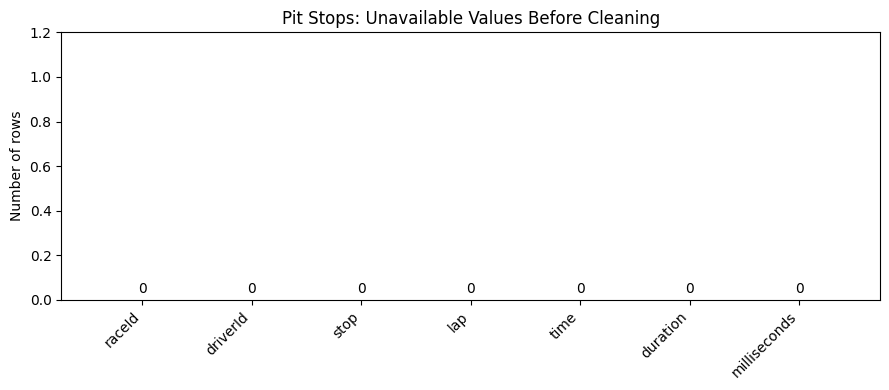

In [332]:
unavailable = pit_missing + pit_sentinels

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    unavailable.index,
    unavailable.values,
    color="steelblue"
)

ax.bar_label(bars, padding=3)
ax.set_title("Pit Stops: Unavailable Values Before Cleaning")
ax.set_ylabel("Number of rows")
ax.set_ylim(0, max(1, unavailable.max()) * 1.2)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [333]:
display(
    pit_stops.select_dtypes(include="number").describe().T
)

# Show examples of durations written with minutes.
minute_format = (
    pit_stops["duration"]
    .astype("string")
    .str.contains(":", na=False)
)

print("Durations containing a colon:", minute_format.sum())

display(
    pit_stops.loc[
        minute_format,
        ["raceId", "driverId", "stop", "lap",
         "duration", "milliseconds"]
    ].head(10)
)

,count,mean,std,min,25%,50%,75%,max
raceId,11371.0,981.194882,92.326831,841.0,895.0,971.0,1065.0,1144.0
driverId,11371.0,549.734500,383.734981,1.0,20.0,817.0,835.0,862.0
stop,11371.0,1.787969,1.521462,1.0,1.0,2.0,2.0,70.0
lap,11371.0,25.387389,14.831497,1.0,13.0,25.0,36.0,78.0
milliseconds,11371.0,85230.495559,310427.261089,12897.0,21937.5,23606.0,26544.0,3069017.0


Durations containing a colon: 517


,raceId,driverId,stop,lap,duration,milliseconds
751,853,817,1,1,16:44.718,1004718
2419,881,814,2,20,2:03.124,123124
2420,881,16,2,22,1:29.401,89401
2421,881,18,3,35,1:44.833,104833
2422,884,16,1,8,1:14.026,74026
2533,888,17,1,8,2:42.042,162042
2713,893,154,3,33,1:13.009,73009
2802,894,16,3,38,1:11.445,71445
3089,901,817,3,40,1:49.329,109329
3159,903,13,1,10,1:18.277,78277


### Placeholder handling and semantic typing


### 3.5.2 Pit Stops: Cleaning Pipeline & Time Conversions
Executing core transformations: replacing placeholders, standardizing `duration` from milliseconds into numeric seconds, and safely casting the clock `time` column into a strict pandas timedelta format (representing the time elapsed since midnight).

In [334]:
pit_stops_clean = pit_stops.copy(deep=True)

pit_stops_clean = pit_stops_clean.replace(r"\N", np.nan)

In [335]:
# Verify milliseconds are available wherever the original duration is present.
pit_stops_clean["milliseconds"] = pd.to_numeric(pit_stops_clean["milliseconds"], errors="raise")
assert not (pit_stops_clean["duration"].notna() & pit_stops_clean["milliseconds"].isna()).any(), "A recorded duration has no milliseconds."

pit_stops_clean["duration"] = pit_stops_clean["milliseconds"] / 1000


In [336]:
# Validate clock text first, then store the offset since midnight.
clock_check = pd.to_datetime(
    pit_stops_clean["time"], format="%H:%M:%S", errors="coerce"
)
invalid_clock = pit_stops_clean["time"].notna() & clock_check.isna()
print("Invalid non-missing time values:", int(invalid_clock.sum()))
assert not invalid_clock.any(), "Investigate invalid clock readings."

# Same column, pandas-native dtype; this is time since midnight, not stop duration.
pit_stops_clean["time"] = pd.to_timedelta(pit_stops_clean["time"], errors="raise").astype("timedelta64[ns]")
assert pd.api.types.is_timedelta64_dtype(pit_stops_clean["time"])
assert pit_stops_clean["time"].dropna().between(pd.Timedelta(0), pd.Timedelta(days=1), inclusive="left").all()


Invalid non-missing time values: 0


In [337]:
# Independently check both original duration formats against milliseconds.
pit_text = pit_stops["duration"].replace(r"\N", np.nan).astype("string")
pit_text = pit_text.where(pit_text.str.count(":").ne(1), "0:" + pit_text)
pit_text = pit_text.where(pit_text.str.contains(":", na=True), pit_text + "s")
pit_text_seconds = pd.to_timedelta(pit_text, errors="raise").dt.total_seconds()
pit_matches = np.isclose(pit_text_seconds, pit_stops_clean["duration"], atol=0.001, rtol=0, equal_nan=True)
print("Original duration values agreeing with converted seconds:", pit_matches.sum())
assert pit_matches.all(), "Original duration and milliseconds disagree."


Original duration values agreeing with converted seconds: 11371


### Before/after evidence


In [338]:
display(pd.DataFrame({
    "duration BEFORE (text)": pit_stops["duration"].head(10),
    "duration AFTER (seconds)": pit_stops_clean["duration"].head(10),
    "time BEFORE (text)": pit_stops["time"].head(10),
    "time AFTER (since midnight)": pit_stops_clean["time"].head(10)
}))
print("duration BEFORE type:", pit_stops["duration"].dtype)
print("duration AFTER type:", pit_stops_clean["duration"].dtype)
print("time BEFORE type:", pit_stops["time"].dtype)
print("time AFTER type:", pit_stops_clean["time"].dtype)
print("Rows BEFORE:", len(pit_stops))
print("Rows AFTER:", len(pit_stops_clean))
print("Missing duration AFTER:", pit_stops_clean["duration"].isna().sum())
print("Missing time AFTER:", pit_stops_clean["time"].isna().sum())
print("Actual non-missing value types BEFORE:", pit_stops["time"].dropna().map(type).value_counts())
print("Actual non-missing value types AFTER:", pit_stops_clean["time"].dropna().map(type).value_counts())


,duration BEFORE (text),duration AFTER (seconds),time BEFORE (text),time AFTER (since midnight)
0,26.898,26.898,17:05:23,0 days 17:05:23
1,25.021,25.021,17:05:52,0 days 17:05:52
2,23.426,23.426,17:20:48,0 days 17:20:48
3,23.251,23.251,17:22:34,0 days 17:22:34
4,23.842,23.842,17:24:10,0 days 17:24:10
5,23.643,23.643,17:24:29,0 days 17:24:29
6,22.603,22.603,17:25:17,0 days 17:25:17
7,24.863,24.863,17:26:03,0 days 17:26:03
8,25.259,25.259,17:26:50,0 days 17:26:50
9,25.342,25.342,17:27:34,0 days 17:27:34


duration BEFORE type: object
duration AFTER type: float64
time BEFORE type: object
time AFTER type: timedelta64[ns]
Rows BEFORE: 11371
Rows AFTER: 11371
Missing duration AFTER: 0
Missing time AFTER: 0
Actual non-missing value types BEFORE: time
<class 'str'>    11371
Name: count, dtype: int64
Actual non-missing value types AFTER: time
<class 'pandas._libs.tslibs.timedeltas.Timedelta'>    11371
Name: count, dtype: int64


The cleaned `duration` contains numeric elapsed seconds, independently checked against the original text. The existing `time` column has pandas dtype **`timedelta64[ns]`**, representing **time since midnight**. Example: `13:25:44` becomes `0 days 13:25:44`. This representation preserves the clock reading without assigning a calendar date or timezone. It is not elapsed race time or the duration of a stop. Raw data stays unchanged, no columns are added, and missing values remain missing (`NaT` for clock offsets). The before/after table shows values, dtype and element types.


### Meaning of the recorded duration

The [Jolpica pit-stop documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/pitstops.md) describes duration as including pit entry, exit and, where applicable, red-flag time. Therefore a large duration alone is not an error flag. We validate the existing duration representation against milliseconds, without searching individual large values for mistakes or altering them.


### 3.5.3 Pit Stops: Relational Integrity & Key Validation
Validating the composite primary key (`raceId`, `driverId`, `stop`) to ensure no duplicate records exist, and verifying that every recorded pit stop maps strictly to known entities in the `races`, `drivers`, and `results` tables.

### Key and reference checks


In [339]:
key_columns = ["raceId", "driverId", "stop"]

display(
    pit_stops_clean[key_columns]
    .isna()
    .sum()
    .to_frame("Missing key values")
)

duplicates = pit_stops_clean.duplicated(
    key_columns, keep=False
)

print("Extra duplicate key rows:",
      pit_stops_clean.duplicated(key_columns).sum())

if duplicates.any():
    display(
        pit_stops_clean.loc[duplicates]
        .sort_values(key_columns)
        .head(20)
    )

assert pit_stops_clean[key_columns].notna().all().all(), \
    "Missing key values found"

assert not duplicates.any(), \
    "Repeated race–driver–stop combinations found"

print("Passed: the key is unique and non-null.")

,Missing key values
raceId,0
driverId,0
stop,0


Extra duplicate key rows: 0
Passed: the key is unique and non-null.


In [340]:
unknown_races = ~pit_stops_clean["raceId"].isin(races["raceId"])
unknown_drivers = ~pit_stops_clean["driverId"].isin(drivers["driverId"])

print("Rows with unknown race IDs:", unknown_races.sum())
print("Rows with unknown driver IDs:", unknown_drivers.sum())

if unknown_races.any():
    display(pit_stops_clean.loc[unknown_races].head(20))

if unknown_drivers.any():
    display(pit_stops_clean.loc[unknown_drivers].head(20))

assert not unknown_races.any(), "Unknown race IDs found"
assert not unknown_drivers.any(), "Unknown driver IDs found"

print("Passed: race and driver references exist.")

Rows with unknown race IDs: 0
Rows with unknown driver IDs: 0
Passed: race and driver references exist.


In [341]:
pit_pairs = pit_stops_clean[
    ["raceId", "driverId"]
].drop_duplicates()

result_pairs = results[
    ["raceId", "driverId"]
].drop_duplicates()

pair_check = pit_pairs.merge(
    result_pairs,
    on=["raceId", "driverId"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

unmatched_pairs = pair_check.loc[
    pair_check["_merge"].eq("left_only"),
    ["raceId", "driverId"]
]

print("Driver–race pairs absent from results:", len(unmatched_pairs))

if not unmatched_pairs.empty:
    display(unmatched_pairs)

assert unmatched_pairs.empty, \
    "Some pit-stop driver–race pairs are absent from results"

print("Passed: all driver–race pairs exist in results.")

Driver–race pairs absent from results: 0
Passed: all driver–race pairs exist in results.


### Cross-table consistency audit — apply the rule to every record

**Meaning first:** `pit_stops.lap` is the lap associated with one pit stop. `results.laps` is the total number of laps the driver completed. They are different quantities, so we do **not** test equality. A stop on lap 20 and a result of 60 completed laps can agree perfectly. See the [pit-stop fields](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/pitstops.md) and [result fields](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/results.md).

**General screening rule:** join every pit-stop row to the result for the same `(raceId, driverId)`, then display all cases where the pit lap exceeds the recorded completed-lap total. This is a review trigger, not proof of an error: a lap number is not always a completed lap, and classification conventions or disqualification can require explanation. A zero total can be valid if no laps were completed; zero by itself is not an error.

We apply this rule to **all 11,371 rows**, without selecting a driver or race first. Only after displaying the exceptions do we identify the driver and consult evidence. The assertions mentioning the discovered IDs are final regression checks, not the filter that discovered them.

Other cross-table rules check that the driver and race exist separately, that the driver–race combination exists in results, and that the pit lap has a matching timing row. Matching timing rows do not prove every stop number or duration is correct. Basic type, missing-value and key checks remain separate from these cross-table rules. Unusual stop numbering and large durations are not used as case-investigation triggers in this audit.


### 3.5.4 Pit Stops: Sequence Auditing, Edge Cases & Final Validation
Running cross-table logic checks to flag impossible pit stop sequences, such as pit stop laps exceeding a driver's officially completed laps or laps decreasing in chronological order. Includes an audit of modern pit stop coverage (2011 onward), resolution of known edge cases, and final structural assertions.

,Rows / cells
Full duplicate rows,0
Blank text cells,0
Non-positive milliseconds,0
Invalid integer values: raceId,0
Invalid integer values: driverId,0
Invalid integer values: stop,0
Invalid integer values: lap,0


Pit-stop rows screened against result totals: 11371


,Flagged rows / pairs
Unknown race IDs,0
Unknown driver IDs,0
Pit pairs absent from results,0
Pit laps without timing rows,0
Pit laps beyond raw result total,3
Decreasing laps in stop order,0


,raceId,year,name,driverId,forename,surname,stop,lap,laps,status
11210,1141,2024,São Paulo Grand Prix,807,Nico,Hülkenberg,1,25,0,Disqualified
11223,1141,2024,São Paulo Grand Prix,807,Nico,Hülkenberg,2,27,0,Disqualified
11226,1141,2024,São Paulo Grand Prix,807,Nico,Hülkenberg,3,29,0,Disqualified


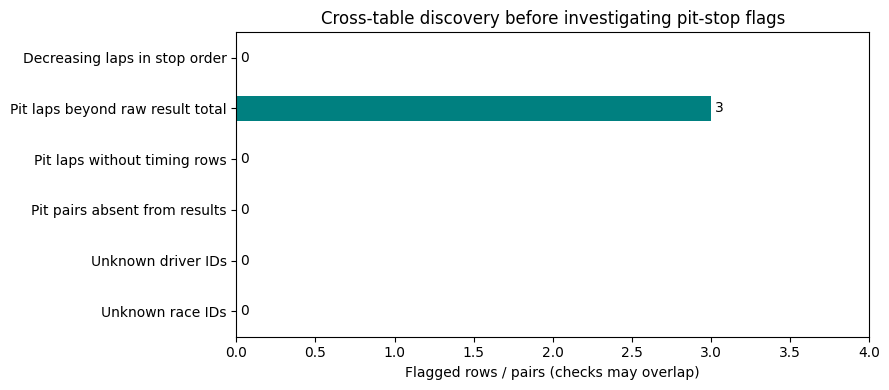

In [342]:
# Basic record checks, without changing any values.
pit_basic_checks = pd.Series({
    "Full duplicate rows": int(pit_stops.duplicated().sum()),
    "Blank text cells": int(pit_stops.select_dtypes(include="object").apply(
        lambda col: col.astype("string").str.strip().eq("").sum()).sum()),
    "Non-positive milliseconds": int(pit_stops_clean["milliseconds"].le(0).sum())
})
for col in ["raceId", "driverId", "stop", "lap"]:
    values = pd.to_numeric(pit_stops_clean[col], errors="coerce")
    pit_basic_checks["Invalid integer values: " + col] = int(
        (values.isna() | values.le(0) | values.mod(1).ne(0)).sum())
display(pit_basic_checks.to_frame("Rows / cells"))
assert pit_basic_checks.eq(0).all()

# Filter to relevant result pairs before validating: historical duplicates elsewhere
# must not multiply these joins or be silently removed.
pit_relevant_results = results.merge(pit_pairs, on=["raceId", "driverId"], validate="many_to_one")
assert not pit_relevant_results.duplicated(["raceId", "driverId"]).any()
pit_result_audit = pit_stops_clean.merge(
    pit_relevant_results[["raceId", "driverId", "laps", "statusId"]],
    on=["raceId", "driverId"], how="left", validate="many_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one").merge(
    drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(status, on="statusId", validate="many_to_one")
print("Pit-stop rows screened against result totals:", len(pit_result_audit))
assert len(pit_result_audit) == len(pit_stops_clean)
pit_result_lap_flags = pit_result_audit.loc[pit_result_audit["lap"].gt(pit_result_audit["laps"])].copy()
pit_timing_audit = pit_stops_clean.merge(
    lap_times[["raceId", "driverId", "lap"]],
    on=["raceId", "driverId", "lap"], how="left", validate="many_to_one", indicator=True
)
pit_without_timing = pit_timing_audit.loc[pit_timing_audit["_merge"].eq("left_only")]
pit_order_audit = pit_stops_clean.sort_values(["raceId", "driverId", "stop"]).copy()
pit_order_audit["Lap change"] = pit_order_audit.groupby(["raceId", "driverId"])["lap"].diff()
pit_decreasing_laps = pit_order_audit.loc[pit_order_audit["Lap change"].lt(0)]
pit_consistency_summary = pd.Series({
    "Unknown race IDs": int(unknown_races.sum()),
    "Unknown driver IDs": int(unknown_drivers.sum()),
    "Pit pairs absent from results": len(unmatched_pairs),
    "Pit laps without timing rows": len(pit_without_timing),
    "Pit laps beyond raw result total": len(pit_result_lap_flags),
    "Decreasing laps in stop order": len(pit_decreasing_laps)
})
display(pit_consistency_summary.to_frame("Flagged rows / pairs"))
display(pit_result_lap_flags[["raceId", "year", "name", "driverId", "forename", "surname", "stop", "lap", "laps", "status"]])
ax = pit_consistency_summary.plot.barh(figsize=(9, 4), color="teal")
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Cross-table discovery before investigating pit-stop flags")
ax.set_xlabel("Flagged rows / pairs (checks may overlap)")
ax.set_xlim(0, max(1, pit_consistency_summary.max()) + 1)
plt.tight_layout()
plt.show()
assert len(pit_result_lap_flags) == 3
assert set(pit_result_lap_flags["raceId"]) == {1141}
assert set(pit_result_lap_flags["driverId"]) == {807}
assert pit_without_timing.empty and pit_decreasing_laps.empty


### Describe coverage without declaring absent records wrong

There are no missing cells in the pit-stop CSV. The [source documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/pitstops.md) says pit-stop coverage begins in 2011, so earlier absence is outside its scope. For 2011 onward, we compare all result pairs with recorded pit-stop pairs and show the counts below. A result without a pit-stop row does not establish that a stop is missing. We do not flag these pairs as wrong, search individual cases, fill values, or create rows based on absence alone.


,Result_pairs,With_pit_records,Without pit records
year,,,
2011,456,429,27
2012,480,447,33
2013,418,401,17
2014,407,378,29
2015,378,347,31
2016,462,431,31
2017,400,357,43
2018,420,382,38
2019,420,409,11


,raceId,driverId,year,name
19,841,813,2011,Australian Grand Prix
44,842,39,2011,Malaysian Grand Prix
45,842,813,2011,Malaysian Grand Prix
93,844,10,2011,Turkish Grand Prix
164,847,1,2011,Canadian Grand Prix


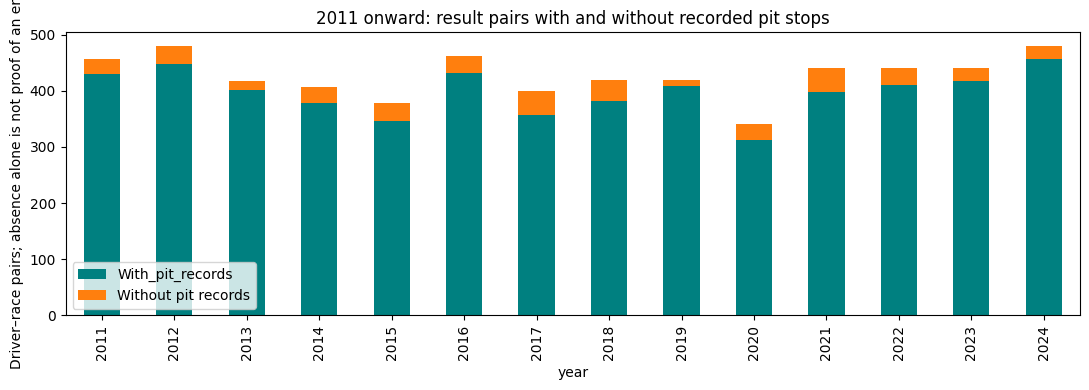

In [343]:
pit_coverage_audit = results[["raceId", "driverId"]].drop_duplicates().merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
)
pit_coverage_audit = pit_coverage_audit.loc[pit_coverage_audit["year"].ge(2011)].merge(
    pit_pairs, on=["raceId", "driverId"], how="left", validate="one_to_one", indicator=True
)
pit_coverage_audit["Has pit records"] = pit_coverage_audit["_merge"].eq("both")
pit_annual_coverage = pit_coverage_audit.groupby("year").agg(
    Result_pairs=("driverId", "size"), With_pit_records=("Has pit records", "sum")
)
pit_annual_coverage["Without pit records"] = pit_annual_coverage["Result_pairs"] - pit_annual_coverage["With_pit_records"]
display(pit_annual_coverage)
display(pit_coverage_audit.loc[~pit_coverage_audit["Has pit records"],
    ["raceId", "driverId", "year", "name"]].head(5))
pit_annual_coverage[["With_pit_records", "Without pit records"]].plot.bar(
    stacked=True, figsize=(11, 4), color=["teal", "tab:orange"]
)
plt.title("2011 onward: result pairs with and without recorded pit stops")
plt.ylabel("Driver–race pairs; absence alone is not proof of an error")
plt.tight_layout()
plt.show()


### Explain the three cross-table flags and show the decision

All three flags are Hülkenberg's stops on laps **25, 27 and 29** in São Paulo 2024, compared with the original result total of **0**. The [FIA sector analysis](https://www.fia.com/sites/default/files/2024_21_bra_f1_r0_timing_racesectoranalysis_v01.pdf), page 11, lists 30 completed laps. This is the **same case investigated in the lap-times section**, not three new independent errors. The later results correction normalizes his completed-lap total to 30 while retaining the disqualification. Disqualification is not proof of zero physical laps. The evidence supports a completed-lap normalization, rather than a claim that zero cannot occur in an official classification. No pit-stop value needs changing.

The table below compares the original result value with the source-supported completed-lap total. It is an evidence table; `results_clean` is created and corrected later in notebook order. The final verification of this audit also checks against that later clean table.


In [344]:
pit_lap_evidence = pit_result_lap_flags[["raceId", "driverId", "stop", "lap", "laps"]].copy()
pit_lap_evidence = pit_lap_evidence.rename(columns={"laps": "Raw result laps"})
pit_lap_evidence["Verified completed laps"] = 30
pit_lap_evidence["Within verified total"] = pit_lap_evidence["lap"].le(pit_lap_evidence["Verified completed laps"])
pit_lap_evidence["Decision"] = "Keep pit record; result total is handled in the results section"
display(pit_lap_evidence)
assert pit_lap_evidence["Within verified total"].all()

# Prove that this audit did not change, insert or delete any pit-stop records.
pit_expected = pit_stops.copy(deep=True).replace(r"\N", np.nan)
pit_expected["milliseconds"] = pd.to_numeric(pit_expected["milliseconds"], errors="raise")
pit_expected["duration"] = pit_expected["milliseconds"] / 1000
pit_expected["time"] = pd.to_timedelta(pit_expected["time"], errors="raise").astype("timedelta64[ns]")
pd.testing.assert_frame_equal(pit_stops_clean, pit_expected)
print("Preserved all pit-stop values and rows except the documented duration and clock typing.")


,raceId,driverId,stop,lap,Raw result laps,Verified completed laps,Within verified total,Decision
11210,1141,807,1,25,0,30,True,Keep pit record; result total is handled in th...
11223,1141,807,2,27,0,30,True,Keep pit record; result total is handled in th...
11226,1141,807,3,29,0,30,True,Keep pit record; result total is handled in th...


Preserved all pit-stop values and rows except the documented duration and clock typing.


### Pit-stop audit findings within the requested scope

All 11,371 rows and seven columns are preserved. Missing-value, key, type and reference checks pass. The cross-table rules are applied to every relevant record, not to hand-picked drivers. They find three pit-lap/recorded-result-total exceptions belonging to one driver–race case: Hülkenberg in São Paulo 2024. The FIA timing evidence supports 30 completed laps; the existing results correction handles this case, keeping disqualification unchanged. Clock readings are preserved while converting their representation from strings to pandas-native offsets since midnight; duration remains numeric seconds. No stop/lap values are changed.

The other cross-table checks pass. This does not prove that every pit-stop record is correct. Unusual stop numbering, isolated long durations and absent pit-stop pairs are not labeled as errors or used for additional individual investigations in this workflow. No missing stop rows are reconstructed, stop/lap values are not swapped, and no extra columns are added to the clean table. Current-race pit-stop data remains excluded from pre-race inputs.


In [345]:
pit_final_checks = pd.Series({
    "Row count unchanged": len(pit_stops_clean) == len(pit_stops),
    "No remaining placeholders": not pit_stops_clean.eq(r"\N").any().any(),
    "Key non-null": pit_stops_clean[["raceId", "driverId", "stop"]].notna().all().all(),
    "Key unique": not pit_stops_clean.duplicated(["raceId", "driverId", "stop"]).any(),
    "Clock values preserved": pit_stops_clean["time"].equals(
        pd.to_timedelta(pit_stops["time"].replace(r"\N", np.nan), errors="raise").astype("timedelta64[ns]")
    ),
    "Clock uses pandas timedelta dtype": pd.api.types.is_timedelta64_dtype(pit_stops_clean["time"]),
    "duration is numeric seconds": pd.api.types.is_numeric_dtype(pit_stops_clean["duration"]),
    "Duration missingness preserved": pit_stops_clean["duration"].isna().sum() == pit_stops["duration"].replace(r"\N", np.nan).isna().sum(),
    "Clock missingness preserved": pit_stops_clean["time"].isna().sum() == pit_stops["time"].replace(r"\N", np.nan).isna().sum()
})
display(pit_final_checks.to_frame("Passed"))
assert pit_final_checks.all(), "Investigate failed pit-stop checks."


,Passed
Row count unchanged,True
No remaining placeholders,True
Key non-null,True
Key unique,True
Clock values preserved,True
Clock uses pandas timedelta dtype,True
duration is numeric seconds,True
Duration missingness preserved,True
Clock missingness preserved,True


In [346]:
pit_stops_clean.info()
assert pit_stops_clean.columns.equals(pit_stops.columns), "Unexpected added or removed pit columns"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype          
---  ------        --------------  -----          
 0   raceId        11371 non-null  int64          
 1   driverId      11371 non-null  int64          
 2   stop          11371 non-null  int64          
 3   lap           11371 non-null  int64          
 4   time          11371 non-null  timedelta64[ns]
 5   duration      11371 non-null  float64        
 6   milliseconds  11371 non-null  int64          
dtypes: float64(1), int64(5), timedelta64[ns](1)
memory usage: 622.0 KB


## 3.6 constructor_standings.csv 

### 3.6.1 Constructor Standings: Initial Loading & Baseline
Loading the dataset while immediately parsing `\N` sentinels into missing values, and inspecting the initial column structure and data types.

In [347]:
constructor_standings.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [348]:
constructor_standings_clean  =  pd.read_csv(DATA_DIR / "constructor_standings.csv",na_values=[r"\N"]) 
constructor_standings_clean.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [349]:
constructor_standings_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB


### 3.6.2 Constructor Standings: Relational Integrity & Key Validation
Validating the primary index (`constructorStandingsId`) and composite keys (`raceId`, `constructorId`) for strict uniqueness. This ensures no duplicate standings exist for a single team in a single race, and verifies that every record maps correctly to the established `races` and `constructors` reference tables.

In [350]:
# Check the record ID.
record_id = "constructorStandingsId"

print("Missing constructorStandingsId:",
      constructor_standings_clean[record_id].isna().sum())

print("Duplicate constructorStandingsId:",
      constructor_standings_clean[record_id].duplicated().sum())

assert constructor_standings_clean[record_id].notna().all(), \
    "Missing constructorStandingsId found"

assert constructor_standings_clean[record_id].is_unique, \
    "Duplicate constructorStandingsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "constructorId"]

print("\nMissing race and constructor IDs:")
display(constructor_standings_clean[pair_columns].isna().sum())

print("Duplicate race–constructor pairs:",
      constructor_standings_clean.duplicated(pair_columns).sum())

assert constructor_standings_clean[pair_columns].notna().all().all(), \
    "Missing raceId or constructorId found"

assert not constructor_standings_clean.duplicated(pair_columns).any(), \
    "Duplicate race–constructor pairs found"

print("\nPassed: record IDs and race–constructor pairs are unique and non-null.")

Missing constructorStandingsId: 0
Duplicate constructorStandingsId: 0

Missing race and constructor IDs:


raceId           0
constructorId    0
dtype: int64

Duplicate race–constructor pairs: 0

Passed: record IDs and race–constructor pairs are unique and non-null.


In [351]:
# Find rows with missing or unknown race IDs.
invalid_races = constructor_standings_clean[
    constructor_standings_clean["raceId"].isna()
    | ~constructor_standings_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_constructors = constructor_standings_clean[
    constructor_standings_clean["constructorId"].isna()
    | ~constructor_standings_clean["constructorId"].isin(
        constructors["constructorId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown constructor IDs:", len(invalid_constructors))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_constructors.empty:
    display(invalid_constructors)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_constructors.empty, \
    "Some constructor IDs are missing or absent from constructors"

print("Passed: all race and constructor IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown constructor IDs: 0
Passed: all race and constructor IDs exist in their reference tables.


## 3.7 constructors.csv


### 3.7.1 Constructors: Initial Loading & Baseline
Loading the constructors dataset, automatically replacing `\N` placeholders with standard missing values during import, and reviewing the baseline column structure.

In [352]:
constructors.head()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [353]:
constructors_clean  =  pd.read_csv(DATA_DIR / "constructors.csv",na_values=[r"\N"]) 
constructors_clean.head()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [354]:
constructors_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    object
 4   url             212 non-null    object
dtypes: int64(1), object(4)
memory usage: 8.4+ KB


### 3.7.2 Constructors: Primary Key Validation
Verifying the integrity of the `constructorId` to guarantee that every team has a strictly unique, non-null identifier before it is used in cross-table relational merges.

In [355]:
# Check the record ID.
record_id = "constructorId"

print("Missing constructorId:",
      constructors_clean[record_id].isna().sum())

print("Duplicate constructorId:",
      constructors_clean[record_id].duplicated().sum())

assert constructors_clean[record_id].notna().all(), \
    "Missing constructorId found"

assert constructors_clean[record_id].is_unique, \
    "Duplicate constructorId found"


Missing constructorId: 0
Duplicate constructorId: 0


## 3.8 driver_standings.csv


### 3.8.1 Driver Standings: Initial Loading & Baseline
Loading the driver standings dataset, automatically converting `\N` sentinels into standard missing values during import, and inspecting the baseline column structure and data types.

In [356]:
driver_standings.head()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


In [357]:
driver_standings_clean  =  pd.read_csv(DATA_DIR / "driver_standings.csv",na_values=[r"\N"]) 
driver_standings_clean.head()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


In [358]:
driver_standings_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  object 
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


### 3.8.2 Driver Standings: Relational Integrity & Key Validation
Validating the primary index (`driverStandingsId`) and composite keys (`raceId`, `driverId`) for strict uniqueness. This ensures no duplicate standings exist for a single driver in a single race, and verifies that every record maps correctly to the established `races` and `drivers` reference tables.

In [359]:
# Check the record ID.
record_id = "driverStandingsId"

print("Missing driverStandingsId:",
      driver_standings_clean[record_id].isna().sum())

print("Duplicate driverStandingsId:",
      driver_standings_clean[record_id].duplicated().sum())

assert driver_standings_clean[record_id].notna().all(), \
    "Missing driverStandingsId found"

assert driver_standings_clean[record_id].is_unique, \
    "Duplicate driverStandingsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "driverId"]

print("\nMissing race and driver IDs:")
display(driver_standings_clean[pair_columns].isna().sum())

print("Duplicate race–driver pairs:",
      driver_standings_clean.duplicated(pair_columns).sum())

assert driver_standings_clean[pair_columns].notna().all().all(), \
    "Missing raceId or driverID found"

assert not driver_standings_clean.duplicated(pair_columns).any(), \
    "Duplicate race–driver pairs found"

print("\nPassed: record IDs and race–drivers pairs are unique and non-null.")

Missing driverStandingsId: 0
Duplicate driverStandingsId: 0

Missing race and driver IDs:


raceId      0
driverId    0
dtype: int64

Duplicate race–driver pairs: 0

Passed: record IDs and race–drivers pairs are unique and non-null.


In [360]:
# Find rows with missing or unknown race IDs.
invalid_races = driver_standings_clean[
    driver_standings_clean["raceId"].isna()
    | ~driver_standings_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_drivers = driver_standings_clean[
    driver_standings_clean["driverId"].isna()
    | ~driver_standings_clean["driverId"].isin(
        drivers["driverId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown drivers IDs:", len(invalid_drivers))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_drivers.empty:
    display(invalid_drivers)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_drivers.empty, \
    "Some drivers IDs are missing or absent from drivers"

print("Passed: all race and drivers IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown drivers IDs: 0
Passed: all race and drivers IDs exist in their reference tables.


## 3.9 qualifying.csv

### 3.9.1 Qualifying: Baseline Setup & Time Conversion
Loading the dataset with strict NA overrides to prevent Pandas from silently masking formatting anomalies. This phase establishes the baseline and explicitly converts the textual `q1`, `q2`, and `q3` lap times into strict numeric seconds.

In [361]:
print("shape:", qualifying.shape)
print("columns:", list(qualifying.columns))
qualifying.head()

shape: (10494, 9)
columns: ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3']


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [362]:
before = pd.DataFrame({
    "sentinel (\\N)": (qualifying == r"\N").sum(),
    "blank ('')":     (qualifying == "").sum(),
})
before["total missing"] = before.sum(axis=1)
before["% missing"] = (100 * before["total missing"] / len(qualifying)).round(2)
before

,sentinel (\N),blank (''),total missing,% missing
qualifyId,0,0,0,0.00
raceId,0,0,0,0.00
driverId,0,0,0,0.00
constructorId,0,0,0,0.00
number,0,0,0,0.00
position,0,0,0,0.00
q1,156,0,156,1.49
q2,4625,0,4625,44.07
q3,6819,0,6819,64.98


In [363]:
# Every cell kept as exact text, so we see what is really in the file
qual_txt = pd.read_csv(DATA_DIR / "qualifying.csv", dtype=str, keep_default_na=False)
# What the notebook's `qualifying` already is (default NA handling)
qual_default = pd.read_csv(DATA_DIR / "qualifying.csv")

# Cells pandas turned into NaN on its own, i.e. not the \N sentinel
hidden = qual_default.isna() & (qual_txt != r"\N")
counts = hidden.sum()
print("hidden missing cells per column:")
print(counts[counts > 0])

# What text was actually in those cells?
for col in counts[counts > 0].index:
    print(col, qual_txt.loc[hidden[col], col].map(repr).value_counts().to_dict())

# Which rows are they in?
qual_txt.loc[hidden.any(axis=1), ["qualifyId", "raceId", "q1", "q2", "q3"]]

hidden missing cells per column:
q2    22
q3    46
dtype: int64
q2 {"''": 22}
q3 {"''": 46}


,qualifyId,raceId,q1,q2,q3
10005,10063,1120,1:24.437,1:24.359,
10006,10064,1120,1:24.565,1:24.391,
10007,10065,1120,1:24.405,1:24.422,
10008,10066,1120,1:24.298,1:24.439,
10009,10067,1120,1:24.461,1:24.442,
10010,10068,1120,1:24.738,,
10011,10069,1120,1:24.764,,
10012,10070,1120,1:24.788,,
10013,10071,1120,1:25.159,,
10045,10103,1122,1:28.984,1:28.642,


In [364]:
# Before: count the exact text in the file, so nothing is hidden
before = pd.DataFrame({
    "sentinel (\\N)": (qual_txt == r"\N").sum(),
    "blank ('')":     (qual_txt == "").sum(),
})
before["total missing"] = before.sum(axis=1)
before["% missing"] = (100 * before["total missing"] / len(qual_txt)).round(2)

# Clean copy: only \N and blank count as missing, nothing else is guessed
qualifying_clean = pd.read_csv(DATA_DIR / "qualifying.csv",
                               keep_default_na=False, na_values=[r"\N", ""])

check = pd.DataFrame({"missing_before": before["total missing"],
                      "NaN_after": qualifying_clean.isnull().sum()})
check["match"] = check["missing_before"] == check["NaN_after"]
display(before); display(check)
assert check["match"].all()

,sentinel (\N),blank (''),total missing,% missing
qualifyId,0,0,0,0.00
raceId,0,0,0,0.00
driverId,0,0,0,0.00
constructorId,0,0,0,0.00
number,0,0,0,0.00
position,0,0,0,0.00
q1,156,0,156,1.49
q2,4625,22,4647,44.28
q3,6819,46,6865,65.42


,missing_before,NaN_after,match
qualifyId,0,0,True
raceId,0,0,True
driverId,0,0,True
constructorId,0,0,True
number,0,0,True
position,0,0,True
q1,156,156,True
q2,4647,4647,True
q3,6865,6865,True


In [365]:
qualifying_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10338 non-null  object
 7   q2             5847 non-null   object
 8   q3             3629 non-null   object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


In [366]:
qualifying_clean.isnull().sum()

qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4647
q3               6865
dtype: int64

In [367]:
def to_seconds(t):
    if pd.isna(t):
        return np.nan

    # Accept seconds, minutes:seconds, or hours:minutes:seconds.
    # A leading + marks a gap; its numeric value is still seconds.
    parts = str(t).strip().lstrip("+").split(":")
    if not 1 <= len(parts) <= 3:
        raise ValueError(f"Unexpected duration: {t}")

    values = [float(part) for part in parts]
    if not all(np.isfinite(value) and value >= 0 for value in values):
        raise ValueError(f"Invalid duration: {t}")
    if any(value >= 60 for value in values[1:]):
        raise ValueError(f"Invalid minutes or seconds: {t}")

    seconds = 0.0
    for value in values:
        seconds = seconds * 60 + value
    return seconds

# Replace values in the existing columns. Rerunning is safe.
for col in ["q1", "q2", "q3"]:
    qualifying_clean[col] = qualifying_clean[col].map(to_seconds)

qualifying_clean[["q1", "q2", "q3"]].head()


,q1,q2,q3
0,86.572,85.187,86.714
1,86.103,85.315,86.869
2,85.664,85.452,87.079
3,85.994,85.691,87.178
4,85.960,85.518,87.236


In [368]:
# Compare missingness with the original columns after conversion.
for col in ["q1", "q2", "q3"]:
    original_missing = qualifying[col].replace(r"\N", np.nan).isna()
    assert original_missing.equals(qualifying_clean[col].isna())
    assert pd.api.types.is_numeric_dtype(qualifying_clean[col])
    print(col, "converted to numeric seconds; missingness preserved")


q1 converted to numeric seconds; missingness preserved
q2 converted to numeric seconds; missingness preserved
q3 converted to numeric seconds; missingness preserved


### 3.9.2 Qualifying: Relational Keys & Session Logic
Validating primary and foreign keys against the race, driver, and constructor reference tables. This section also introduces an era-specific sequence audit (2006 onward) to flag impossible session combinations, such as a driver logging a Q3 time without a Q2 time.

In [369]:
n_dup = qualifying_clean.duplicated(subset=["raceId", "driverId"]).sum()
print("duplicate (raceId, driverId) pairs:", n_dup)

duplicate (raceId, driverId) pairs: 0


In [370]:
print("qualifyId unique  :", qualifying_clean["qualifyId"].is_unique)
print("qualifyId no nulls:", qualifying_clean["qualifyId"].notna().all())

qualifyId unique  : True
qualifyId no nulls: True


In [371]:
races_ids        = pd.read_csv(DATA_DIR / "races.csv", usecols=["raceId"])["raceId"]
drivers_ids      = pd.read_csv(DATA_DIR / "drivers.csv", usecols=["driverId"])["driverId"]
constructors_ids = pd.read_csv(DATA_DIR / "constructors.csv", usecols=["constructorId"])["constructorId"]

rows = []
for col, parent, ids in [("raceId", "races.raceId", races_ids),
                         ("driverId", "drivers.driverId", drivers_ids),
                         ("constructorId", "constructors.constructorId", constructors_ids)]:
    orphans = int((~qualifying_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"qualifying.{col}", "points to": parent,
                 "null values": int(qualifying_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

,foreign key,points to,null values,orphan rows,ok
0,qualifying.raceId,races.raceId,0,0,True
1,qualifying.driverId,drivers.driverId,0,0,True
2,qualifying.constructorId,constructors.constructorId,0,0,True


In [372]:
# Q1 -> Q2 -> Q3. Check recorded times, not whether a driver participated.
# Apply these comparisons only to the three-session era (2006 onward).
qualifying_session_check = qualifying_clean.merge(
    races[["raceId", "year"]], on="raceId", validate="many_to_one"
)
qualifying_session_check = qualifying_session_check.loc[qualifying_session_check["year"] >= 2006]

q2_without_q1 = qualifying_session_check["q2"].notna() & qualifying_session_check["q1"].isna()
q3_without_q2 = qualifying_session_check["q3"].notna() & qualifying_session_check["q2"].isna()
q3_without_q1 = qualifying_session_check["q3"].notna() & qualifying_session_check["q1"].isna()

qualifying_session_counts = pd.DataFrame({
    "Check": ["Q2 recorded, Q1 missing", "Q3 recorded, Q2 missing", "Q3 recorded, Q1 missing"],
    "Records to investigate": [q2_without_q1.sum(), q3_without_q2.sum(), q3_without_q1.sum()]
})
display(qualifying_session_counts)
qualifying_session_exceptions = qualifying_session_check.loc[
    q2_without_q1 | q3_without_q2 | q3_without_q1,
    ["qualifyId", "raceId", "driverId", "year", "position", "q1", "q2", "q3"]
]
if not qualifying_session_exceptions.empty:
    display(qualifying_session_exceptions)
# An exception would need investigation, not automatic filling or deletion.


,Check,Records to investigate
0,"Q2 recorded, Q1 missing",0
1,"Q3 recorded, Q2 missing",0
2,"Q3 recorded, Q1 missing",0


### Qualifying: discover problems before changing values

One row describes one driver's qualifying result in a race. `qualifyId` is the primary key; `(raceId, driverId)` should also be unique. `number` is the car number, **not** the finishing position. Qualifying `position` and race `grid` can differ after penalties, so they are not required to match.

We compare **every qualifying row** with the same race and driver in `results`. A disagreement is a reason to investigate, not proof of which table is wrong. We check official records before choosing a correction. All audit tables below are separate variables; the clean table keeps its original nine columns.

### 3.9.3 Qualifying: Cross-Table Consistency & Edge Cases
Cross-referencing qualifying records directly with race results to expose constructor-ID and car-number disagreements. This includes applying evidence-backed, manual resolutions for known historical discrepancies (such as the 2015 Marussia constructor mismatch and verified official car number corrections).

,Before correction
Qualifying pair absent from results,0
Constructor disagreements,10
Car-number disagreements,32


,qualifyId,raceId,year,name,driverId,surname,number_qualifying,number_results
0,434,38,2007,Bahrain Grand Prix,27,Albers,12,21
1,1417,104,2004,Italian Grand Prix,47,Baumgartner,20,21
2,1418,104,2004,Italian Grand Prix,46,Bruni,21,20
3,1442,125,2002,Malaysian Grand Prix,23,Schumacher,3,5
4,1655,177,1999,San Marino Grand Prix,69,Badoer,22,20
5,1668,191,1998,Australian Grand Prix,68,Takagi,20,21
6,1676,191,1998,Australian Grand Prix,44,Panis,14,11
7,1686,192,1998,Brazilian Grand Prix,44,Panis,14,11
8,1712,193,1998,Argentine Grand Prix,68,Takagi,18,21
9,1742,199,1998,British Grand Prix,23,Schumacher,9,10


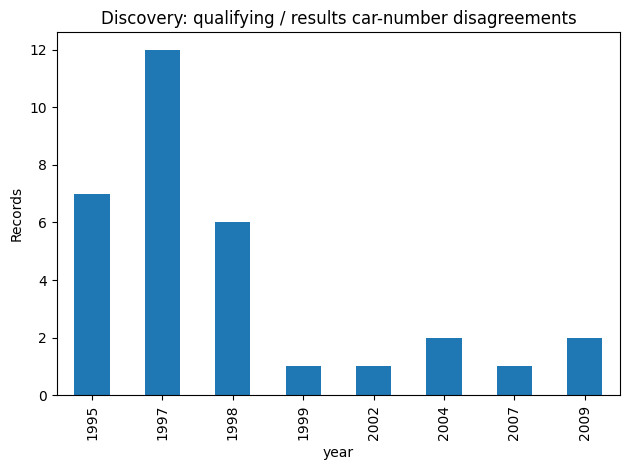

In [373]:
import hashlib
qualifying_csv_hash_before = hashlib.sha256((DATA_DIR / "qualifying.csv").read_bytes()).hexdigest()
qualifying_raw_snapshot = qualifying.copy(deep=True)
qualifying_audit_before = qualifying_clean.copy(deep=True)

# Restrict results to relevant pairs before checking join uniqueness.
# Older results elsewhere can contain shared-drive records.
qualifying_result_reference = results.merge(
    qualifying_audit_before[["raceId", "driverId"]],
    on=["raceId", "driverId"], validate="many_to_one"
)[["raceId", "driverId", "constructorId", "number"]].copy()
assert not qualifying_result_reference.duplicated(["raceId", "driverId"]).any()
qualifying_result_reference["number"] = pd.to_numeric(qualifying_result_reference["number"], errors="raise")
qualifying_cross_before = qualifying_audit_before.merge(
    qualifying_result_reference, on=["raceId", "driverId"], how="left",
    suffixes=("_qualifying", "_results"), indicator=True, validate="one_to_one"
)
qualifying_number_disagreements = qualifying_cross_before.loc[
    qualifying_cross_before["_merge"].eq("both") &
    qualifying_cross_before["number_qualifying"].ne(qualifying_cross_before["number_results"])
].merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one").merge(
    drivers[["driverId", "surname"]], on="driverId", validate="many_to_one"
)
qualifying_discovery_counts = pd.Series({
    "Qualifying pair absent from results": qualifying_cross_before["_merge"].eq("left_only").sum(),
    "Constructor disagreements": qualifying_cross_before["constructorId_qualifying"].ne(qualifying_cross_before["constructorId_results"]).sum(),
    "Car-number disagreements": len(qualifying_number_disagreements)
}, name="Before correction")
display(qualifying_discovery_counts.to_frame())
with pd.option_context("display.max_rows", None):
    display(qualifying_number_disagreements[["qualifyId", "raceId", "year", "name", "driverId", "surname", "number_qualifying", "number_results"]])
qualifying_number_disagreements.groupby("year").size().plot.bar(title="Discovery: qualifying / results car-number disagreements", ylabel="Records")
plt.tight_layout(); plt.show()


### Resolve the ten qualifying–race constructor-ID contradictions

**Discovery first:** the earlier driver-combination audit compared every qualifying `(raceId, driverId, constructorId)` against race results. It displayed ten mismatches: qualifying uses `206` (Marussia), while the same driver and race use `209` (Manor Marussia) in results. This is a cross-table identity inconsistency, not a problem with the drivers' biographies.

**Evidence:** the official F1 qualifying and race classifications for Belgium, Russia, USA, Mexico and Brazil 2015 all list the affected drivers under **Marussia Ferrari** in both sessions. The [FIA Brazil qualifying page](https://www.fia.com/events/fia-formula-one-world-championship/season-2015/qualifying-classifications-14) also names Stevens and Rossi's entrant **Manor Marussia F1 Team**. This supports the same participating team across sessions; there is no evidence here of a team change between qualifying and the race.

Official websites do not assign our database IDs. **Choosing `209` is a documented database harmonization decision:** all 36 relevant 2015 result records use `209`, and 25 other qualifying records already use `209`. The source observations below contain the driver/car identities and links for every affected event; the code checks these against the exact local records before changing anything. We do not claim `206` is an invalid constructor in every season.

**Action:** change only the ten reviewed `qualifying_clean.constructorId` cells from `206` to the existing `209`. Preserve `drivers_clean`, both constructor records, raw data and every other qualifying value. The table and plot below show ten original mismatches becoming zero.


Qualifying rows screened: 10494
Original constructor mismatches: 10


,qualifyId,raceId,driverId,Official surname,Official car number,Official qualifying team,Official race team,Qualifying source,Race source,Before constructorId,number qualifying,After constructorId,number race,surname,year,name
0,6522,937,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/928/belgium/qualifying,https://www.formula1.com/en/results/2015/races/928/belgium/race-result,206,28,209,28,Stevens,2015,Belgian Grand Prix
1,6523,937,833,Merhi,98,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/928/belgium/qualifying,https://www.formula1.com/en/results/2015/races/928/belgium/race-result,206,98,209,98,Merhi,2015,Belgian Grand Prix
2,6601,941,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/932/russia/qualifying,https://www.formula1.com/en/results/2015/races/932/russia/race-result,206,28,209,28,Stevens,2015,Russian Grand Prix
3,6602,941,833,Merhi,98,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/932/russia/qualifying,https://www.formula1.com/en/results/2015/races/932/russia/race-result,206,98,209,98,Merhi,2015,Russian Grand Prix
4,6620,942,834,Rossi,53,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/933/united-states/qualifying,https://www.formula1.com/en/results/2015/races/933/united-states/race-result,206,53,209,53,Rossi,2015,United States Grand Prix
5,6621,942,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/933/united-states/qualifying,https://www.formula1.com/en/results/2015/races/933/united-states/race-result,206,28,209,28,Stevens,2015,United States Grand Prix
6,6640,943,834,Rossi,53,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/934/mexico/qualifying,https://www.formula1.com/en/results/2015/races/934/mexico/race-result,206,53,209,53,Rossi,2015,Mexican Grand Prix
7,6641,943,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/934/mexico/qualifying,https://www.formula1.com/en/results/2015/races/934/mexico/race-result,206,28,209,28,Stevens,2015,Mexican Grand Prix
8,6660,944,834,Rossi,53,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/935/brazil/qualifying,https://www.formula1.com/en/results/2015/races/935/brazil/race-result,206,53,209,53,Rossi,2015,Brazilian Grand Prix
9,6661,944,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/935/brazil/qualifying,https://www.formula1.com/en/results/2015/races/935/brazil/race-result,206,28,209,28,Stevens,2015,Brazilian Grand Prix


,Qualifying before,Race results
constructorId,,
206,10,0
209,25,36


,Constructor-ID mismatches
Before,10
After,0


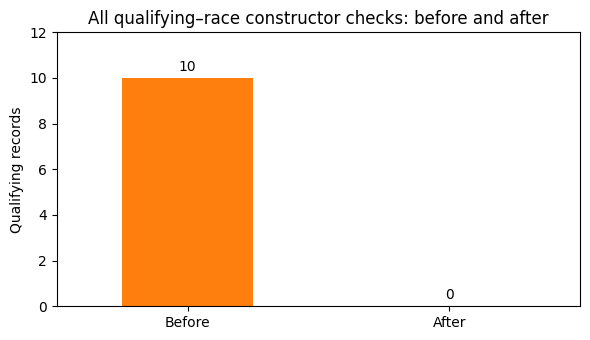

In [374]:
# Manually reviewed official observations; links make each event check reviewable.
qualifying_team_sources = {
    937: "https://www.formula1.com/en/results/2015/races/928/belgium/",
    941: "https://www.formula1.com/en/results/2015/races/932/russia/",
    942: "https://www.formula1.com/en/results/2015/races/933/united-states/",
    943: "https://www.formula1.com/en/results/2015/races/934/mexico/",
    944: "https://www.formula1.com/en/results/2015/races/935/brazil/"
}
qualifying_team_evidence = pd.DataFrame([
    (6522, 937, 829, "Stevens", 28), (6523, 937, 833, "Merhi", 98),
    (6601, 941, 829, "Stevens", 28), (6602, 941, 833, "Merhi", 98),
    (6620, 942, 834, "Rossi", 53), (6621, 942, 829, "Stevens", 28),
    (6640, 943, 834, "Rossi", 53), (6641, 943, 829, "Stevens", 28),
    (6660, 944, 834, "Rossi", 53), (6661, 944, 829, "Stevens", 28)
], columns=["qualifyId", "raceId", "driverId", "Official surname", "Official car number"])
qualifying_team_evidence["Official qualifying team"] = "Marussia Ferrari"
qualifying_team_evidence["Official race team"] = "Marussia Ferrari"
qualifying_team_evidence["Qualifying source"] = qualifying_team_evidence["raceId"].map(qualifying_team_sources) + "qualifying"
qualifying_team_evidence["Race source"] = qualifying_team_evidence["raceId"].map(qualifying_team_sources) + "race-result"

qualifying_team_before = qualifying_clean.copy(deep=True)
team_result_triples = results[["raceId", "driverId", "constructorId"]].drop_duplicates()
team_before_audit = qualifying_team_before.merge(
    team_result_triples, on=["raceId", "driverId", "constructorId"],
    how="left", validate="many_to_one", indicator=True
)
team_before_conflicts = team_before_audit.loc[team_before_audit["_merge"].eq("left_only")]
assert set(team_before_conflicts["qualifyId"]) == set(qualifying_team_evidence["qualifyId"])
print("Qualifying rows screened:", len(qualifying_team_before))
print("Original constructor mismatches:", len(team_before_conflicts))

qualifying_team_evidence = qualifying_team_evidence.merge(
    qualifying_team_before[["qualifyId", "raceId", "driverId", "constructorId", "number"]],
    on=["qualifyId", "raceId", "driverId"], validate="one_to_one"
).rename(columns={"constructorId": "Before constructorId"}).merge(
    results.merge(qualifying_team_evidence[["raceId", "driverId"]],
        on=["raceId", "driverId"], validate="many_to_one")[["raceId", "driverId", "constructorId", "number"]],
    on=["raceId", "driverId"], validate="one_to_one", suffixes=(" qualifying", " race")
).rename(columns={"constructorId": "After constructorId"}).merge(
    drivers[["driverId", "surname"]], on="driverId", validate="many_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
assert qualifying_team_evidence["Before constructorId"].eq(206).all()
assert qualifying_team_evidence["After constructorId"].eq(209).all()
assert qualifying_team_evidence["surname"].eq(qualifying_team_evidence["Official surname"]).all()
for column in ["number qualifying", "number race"]:
    assert pd.to_numeric(qualifying_team_evidence[column]).eq(qualifying_team_evidence["Official car number"]).all()
assert qualifying_team_evidence["year"].eq(2015).all()
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
    display(qualifying_team_evidence)

# Display how the database already identifies this 2015 entrant.
season_race_ids = races.loc[races["year"].eq(2015), "raceId"]
team_season_counts = pd.DataFrame({
    "Qualifying before": qualifying_team_before.loc[
        qualifying_team_before["raceId"].isin(season_race_ids) & qualifying_team_before["constructorId"].isin([206, 209]),
        "constructorId"].value_counts(),
    "Race results": results.loc[
        results["raceId"].isin(season_race_ids) & results["constructorId"].isin([206, 209]),
        "constructorId"].value_counts()
}).fillna(0).astype(int)
display(team_season_counts)
assert team_season_counts.loc[209, "Race results"] == 36
assert team_season_counts.loc[206, "Race results"] == 0

# Change only the supported IDs, never every occurrence of 206.
team_replacements = qualifying_team_evidence.set_index("qualifyId")["After constructorId"]
team_change_mask = qualifying_clean["qualifyId"].isin(team_replacements.index)
qualifying_clean.loc[team_change_mask, "constructorId"] = qualifying_clean.loc[
    team_change_mask, "qualifyId"].map(team_replacements)
team_after_audit = qualifying_clean.merge(
    team_result_triples, on=["raceId", "driverId", "constructorId"],
    how="left", validate="many_to_one", indicator=True
)
team_after_conflicts = team_after_audit.loc[team_after_audit["_merge"].eq("left_only")]
assert team_after_conflicts.empty
pd.testing.assert_frame_equal(qualifying_team_before.drop(columns="constructorId"), qualifying_clean.drop(columns="constructorId"))
assert qualifying_clean["constructorId"].ne(qualifying_team_before["constructorId"]).sum() == 10
assert qualifying_clean["constructorId"].isin(constructors["constructorId"]).all()
assert qualifying_clean["qualifyId"].is_unique
assert not qualifying_clean.duplicated(["raceId", "driverId"]).any()
team_comparison = pd.Series({"Before": len(team_before_conflicts), "After": len(team_after_conflicts)})
display(team_comparison.to_frame("Constructor-ID mismatches"))
ax = team_comparison.plot.bar(figsize=(6, 3.5), color=["tab:orange", "teal"], rot=0)
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylabel("Qualifying records")
ax.set_title("All qualifying–race constructor checks: before and after")
ax.set_ylim(0, 12)
plt.tight_layout()
plt.show()


### Verify the car numbers, then correct only confirmed disagreements

The general comparison above found **32 disagreements across 24 races**. The official F1 qualifying pages list the driver's name and car number. The source table below records the number read from each page, alongside both CSV values. All 32 official numbers agree with `results`, so only those 32 `qualifying_clean.number` cells are corrected. We do not overwrite all qualifying numbers from another table.

For example, [1998 Australian qualifying](https://www.formula1.com/en/results/1998/races/671/australia/qualifying/0) lists Takagi as **21** and Panis as **11**; our qualifying CSV records **20** and **14**. [2002 Malaysian qualifying](https://www.formula1.com/en/results/2002/races/721/malaysia/qualifying/0) lists Ralf Schumacher as **5**, while our qualifying CSV records **3**. The full source list is displayed below. The earlier ten constructor-ID corrections are retained.

,qualifyId,year,name,surname,number_qualifying,number_results,Official number,Official qualifying source
0,434,2007,Bahrain Grand Prix,Albers,12,21,21,https://www.formula1.com/en/results/2007/races/810/bahrain/qualifying
1,1417,2004,Italian Grand Prix,Baumgartner,20,21,21,https://www.formula1.com/en/results/2004/races/767/italy/qualifying
2,1418,2004,Italian Grand Prix,Bruni,21,20,20,https://www.formula1.com/en/results/2004/races/767/italy/qualifying
3,1442,2002,Malaysian Grand Prix,Schumacher,3,5,5,https://www.formula1.com/en/results/2002/races/721/malaysia/qualifying/0
4,1655,1999,San Marino Grand Prix,Badoer,22,20,20,https://www.formula1.com/en/results/1999/races/689/san-marino/qualifying
5,1668,1998,Australian Grand Prix,Takagi,20,21,21,https://www.formula1.com/en/results/1998/races/671/australia/qualifying/0
6,1676,1998,Australian Grand Prix,Panis,14,11,11,https://www.formula1.com/en/results/1998/races/671/australia/qualifying/0
7,1686,1998,Brazilian Grand Prix,Panis,14,11,11,https://www.formula1.com/en/results/1998/races/672/brazil/qualifying
8,1712,1998,Argentine Grand Prix,Takagi,18,21,21,https://www.formula1.com/en/results/1998/races/673/argentina/qualifying
9,1742,1998,British Grand Prix,Schumacher,9,10,10,https://www.formula1.com/en/results/1998/races/679/great-britain/qualifying/0


,Before,After
Qualifying pair absent from results,0,0
Constructor disagreements,10,0
Car-number disagreements,32,0


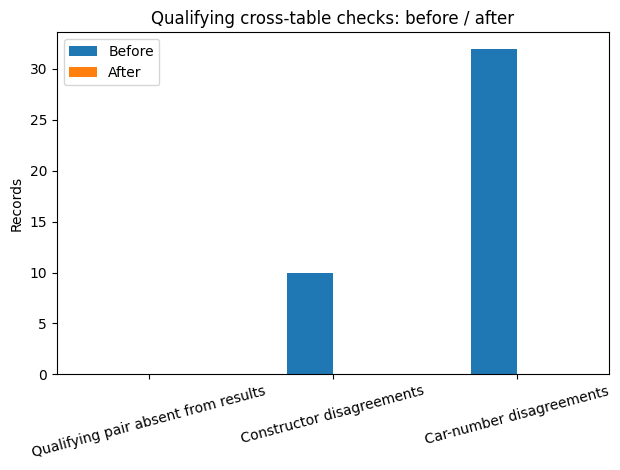

In [375]:
# These are manually checked observations from official qualifying pages.
qualifying_official_numbers = pd.DataFrame([(434, 21), (1417, 21), (1418, 20), (1442, 5), (1655, 20), (1668, 21), (1676, 11), (1686, 11), (1712, 21), (1742, 10), (1778, 18), (1910, 19), (1918, 18), (1923, 9), (1932, 19), (1937, 18), (1954, 18), (1957, 19), (1980, 18), (1981, 19), (1995, 7), (2025, 19), (2026, 18), (2212, 2), (2235, 2), (2287, 25), (2376, 4), (2438, 25), (2460, 25), (2591, 17), (3016, 6), (3045, 21)], columns=["qualifyId", "Official number"])
qualifying_number_sources = {'2': 'https://www.formula1.com/en/results/2009/races/844/malaysia/qualifying', '3': 'https://www.formula1.com/en/results/2009/races/845/china/qualifying', '38': 'https://www.formula1.com/en/results/2007/races/810/bahrain/qualifying', '104': 'https://www.formula1.com/en/results/2004/races/767/italy/qualifying', '125': 'https://www.formula1.com/en/results/2002/races/721/malaysia/qualifying/0', '177': 'https://www.formula1.com/en/results/1999/races/689/san-marino/qualifying', '191': 'https://www.formula1.com/en/results/1998/races/671/australia/qualifying/0', '192': 'https://www.formula1.com/en/results/1998/races/672/brazil/qualifying', '193': 'https://www.formula1.com/en/results/1998/races/673/argentina/qualifying', '199': 'https://www.formula1.com/en/results/1998/races/679/great-britain/qualifying/0', '201': 'https://www.formula1.com/en/results/1998/races/681/germany/qualifying', '211': 'https://www.formula1.com/en/results/1997/races/658/monaco/qualifying', '212': 'https://www.formula1.com/en/results/1997/races/659/spain/qualifying/0', '213': 'https://www.formula1.com/en/results/1997/races/660/canada/qualifying', '214': 'https://www.formula1.com/en/results/1997/races/661/france/qualifying/0', '215': 'https://www.formula1.com/en/results/1997/races/662/great-britain/qualifying/0', '216': 'https://www.formula1.com/en/results/1997/races/663/germany/qualifying', '241': 'https://www.formula1.com/en/results/1995/races/622/argentina/qualifying', '242': 'https://www.formula1.com/en/results/1995/races/623/san-marino/qualifying', '244': 'https://www.formula1.com/en/results/1995/races/625/monaco/qualifying', '247': 'https://www.formula1.com/en/results/1995/races/628/great-britain/qualifying', '250': 'https://www.formula1.com/en/results/1995/races/631/belgium/qualifying', '251': 'https://www.formula1.com/en/results/1995/races/632/italy/qualifying', '256': 'https://www.formula1.com/en/results/1995/races/637/australia/qualifying'}
qualifying_number_evidence = qualifying_number_disagreements.merge(
    qualifying_official_numbers, on="qualifyId", validate="one_to_one"
)
assert set(qualifying_number_disagreements["qualifyId"]) == set(qualifying_official_numbers["qualifyId"])
qualifying_number_evidence["Official qualifying source"] = qualifying_number_evidence["raceId"].astype(str).map(qualifying_number_sources)
assert qualifying_number_evidence["Official qualifying source"].notna().all()
assert qualifying_number_evidence["Official number"].eq(qualifying_number_evidence["number_results"]).all()
with pd.option_context("display.max_rows", None, "display.max_colwidth", 120):
    display(qualifying_number_evidence[["qualifyId", "year", "name", "surname", "number_qualifying", "number_results", "Official number", "Official qualifying source"]])

qualifying_before_number_fix = qualifying_clean.copy(deep=True)
number_corrections = qualifying_official_numbers.set_index("qualifyId")["Official number"]
number_fix_mask = qualifying_clean["qualifyId"].isin(number_corrections.index)
qualifying_clean.loc[number_fix_mask, "number"] = qualifying_clean.loc[number_fix_mask, "qualifyId"].map(number_corrections)
pd.testing.assert_frame_equal(qualifying_before_number_fix.drop(columns="number"), qualifying_clean.drop(columns="number"))
pd.testing.assert_frame_equal(qualifying_before_number_fix.loc[~number_fix_mask], qualifying_clean.loc[~number_fix_mask])
qualifying_cross_after = qualifying_clean.merge(
    qualifying_result_reference, on=["raceId", "driverId"], how="left",
    suffixes=("_qualifying", "_results"), indicator=True, validate="one_to_one"
)
qualifying_consistency_change = pd.DataFrame({
    "Before": qualifying_discovery_counts,
    "After": [qualifying_cross_after["_merge"].eq("left_only").sum(),
              qualifying_cross_after["constructorId_qualifying"].ne(qualifying_cross_after["constructorId_results"]).sum(),
              qualifying_cross_after["number_qualifying"].ne(qualifying_cross_after["number_results"]).sum()]
})
display(qualifying_consistency_change)
qualifying_consistency_change.plot.bar(title="Qualifying cross-table checks: before / after", ylabel="Records", rot=15)
plt.tight_layout(); plt.show()


### Missing qualifying times: what the checks mean

The order is **Q1 -> Q2 -> Q3**. We compare Q2 with Q1, Q3 with Q2, and Q3 with Q1 in the three-session era. The direct Q3/Q1 check is redundant when the two adjacent checks pass, but is included so all three comparisons are visible. The results table is shown earlier, before the identity corrections.

These checks look for a recorded later-session time with an earlier time missing. They do not prove participation or explain every missing value. A recorded Q1 with missing Q2/Q3, or recorded Q1/Q2 with missing Q3, is not by itself a contradiction.

`NaN` means **no recorded time**. Possible reasons include earlier elimination, no valid lap, a cancelled session, a different historical format, or incomplete coverage. We do not assign one of those reasons to an individual record without evidence. Q1/Q2/Q3 times alone cannot establish which reason applies.

Both `\N` and blank strings become `NaN`; the before/after counts below verify that no missing values were lost or introduced during conversion. Times remain numeric seconds in the existing columns. The yearly coverage table and chart show how missingness varies through history. The separate results-pair coverage table shows absent qualifying records; absence alone is not an error flag.

**Missing-data treatment remains pending discussion.** No zero, median, invented time, row removal or missing indicator is added here. Passing these consistency checks does not mean there are no missing values.


### 3.9.4 Qualifying: Missing Data Coverage & Final Validation
Visualizing missing data trends across different seasons to distinguish between true errors and expected historical sparsity (e.g., gaps in older eras). Concludes with a comprehensive suite of strict assertion tests to guarantee dataset integrity before moving forward.

,Raw sentinel,Raw blank,Clean missing,Raw type,Clean type
qualifyId,0,0,0,object,int64
raceId,0,0,0,object,int64
driverId,0,0,0,object,int64
constructorId,0,0,0,object,int64
number,0,0,0,object,int64
position,0,0,0,object,int64
q1,156,0,156,object,float64
q2,4625,22,4647,object,float64
q3,6819,46,6865,object,float64


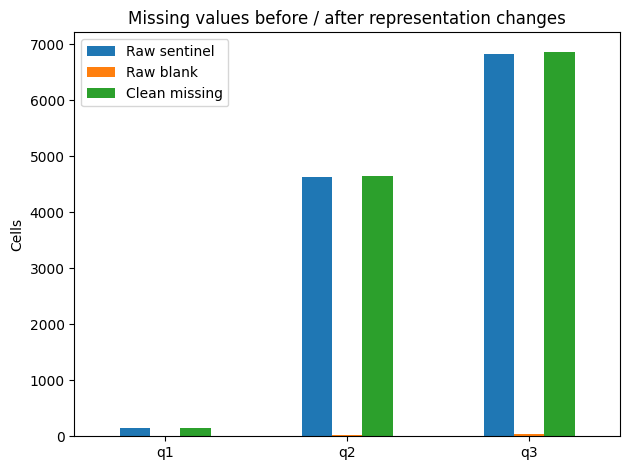

,Raw q1,Clean q1 (seconds)
0,1:26.572,86.572
1,1:26.103,86.103
2,1:25.664,85.664
3,1:25.994,85.994
4,1:25.960,85.960


,q1,q2,q3
year,,,
1994,0.26,100.00,100.00
1995,5.74,100.00,100.00
1996,2.03,100.00,100.00
1997,0.45,100.00,100.00
1998,1.31,100.00,100.00
1999,1.54,100.00,100.00
2000,0.00,100.00,100.00
2001,0.00,100.00,100.00
2002,0.00,100.00,100.00


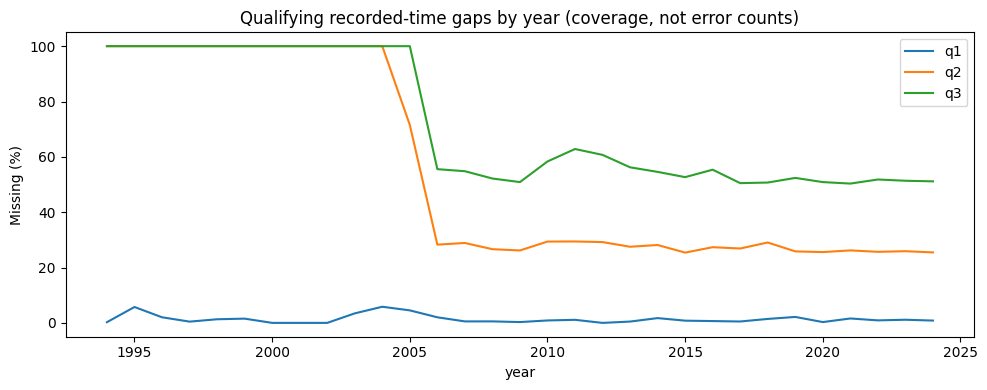

,Results pairs,Pairs without qualifying row,Missing fraction
year,,,
1950,156,156,1.000000
1951,175,175,1.000000
1952,212,212,1.000000
1953,230,230,1.000000
1954,213,213,1.000000
1955,162,162,1.000000
1956,178,178,1.000000
1957,163,163,1.000000
1958,238,238,1.000000


In [376]:
qualifying_missing_evidence = pd.DataFrame({
    "Raw sentinel": qual_txt.eq(r"\N").sum(),
    "Raw blank": qual_txt.apply(lambda col: col.str.strip().eq("").sum()),
    "Clean missing": qualifying_clean.isna().sum(),
    "Raw type": qual_txt.dtypes.astype(str),
    "Clean type": qualifying_clean.dtypes.astype(str)
})
display(qualifying_missing_evidence)
assert (qualifying_missing_evidence["Raw sentinel"] + qualifying_missing_evidence["Raw blank"]).eq(qualifying_missing_evidence["Clean missing"]).all()
qualifying_missing_evidence.loc[["q1", "q2", "q3"], ["Raw sentinel", "Raw blank", "Clean missing"]].plot.bar(title="Missing values before / after representation changes", ylabel="Cells", rot=0)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Raw q1": qual_txt["q1"].head(), "Clean q1 (seconds)": qualifying_clean["q1"].head()}))
qualifying_missing_by_year = qualifying_clean.merge(races[["raceId", "year"]], on="raceId", validate="many_to_one").groupby("year")[["q1", "q2", "q3"]].agg(lambda col: col.isna().mean() * 100)
display(qualifying_missing_by_year.round(2))
qualifying_missing_by_year.plot(title="Qualifying recorded-time gaps by year (coverage, not error counts)", ylabel="Missing (%)", figsize=(10, 4))
plt.tight_layout(); plt.show()
# Look in both directions: are some results pairs absent from qualifying?
qualifying_coverage = results[["raceId", "driverId"]].drop_duplicates().merge(
    qualifying_clean[["raceId", "driverId"]], on=["raceId", "driverId"], how="left", indicator=True, validate="one_to_one"
).merge(races[["raceId", "year"]], on="raceId", validate="many_to_one")
qualifying_coverage["Qualifying row absent"] = qualifying_coverage["_merge"].eq("left_only")
qualifying_coverage_by_year = qualifying_coverage.groupby("year")["Qualifying row absent"].agg(["size", "sum", "mean"])
qualifying_coverage_by_year.columns = ["Results pairs", "Pairs without qualifying row", "Missing fraction"]
display(qualifying_coverage_by_year)


In [377]:
qualifying_checks = []
def add_qualifying_check(check, violations):
    qualifying_checks.append({"Check": check, "Violations": int(violations), "Status": "DONE" if violations == 0 else "NEEDS INVESTIGATION"})

add_qualifying_check("Full duplicate rows", qualifying_clean.duplicated().sum())
add_qualifying_check("Duplicate primary keys", qualifying_clean["qualifyId"].duplicated().sum())
add_qualifying_check("Duplicate race / driver pairs", qualifying_clean.duplicated(["raceId", "driverId"]).sum())
add_qualifying_check("Repeated qualifying position within race (observed)", qualifying_clean.duplicated(["raceId", "position"]).sum())
required_qualifying = ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"]
add_qualifying_check("Missing required fields", qualifying_clean[required_qualifying].isna().sum().sum())
for col in required_qualifying:
    values = pd.to_numeric(qualifying_clean[col], errors="coerce")
    # Car number 0 is permitted; IDs and positions must be positive integers.
    invalid = values.isna() | ~np.isfinite(values) | values.mod(1).ne(0) | (values.lt(0) if col == "number" else values.le(0))
    add_qualifying_check(col + ": invalid integer value", invalid.sum())
for col, parent in [("raceId", races), ("driverId", drivers), ("constructorId", constructors)]:
    add_qualifying_check(col + ": missing foreign-key target", (~qualifying_clean[col].isin(parent[col])).sum())
for col in ["q1", "q2", "q3"]:
    values = qualifying_clean[col].dropna()
    add_qualifying_check(col + ": non-positive or non-finite seconds", ((values <= 0) | ~np.isfinite(values)).sum())
    assert pd.api.types.is_numeric_dtype(qualifying_clean[col])
add_qualifying_check("Remaining literal sentinels or blanks", qualifying_clean.astype(str).apply(lambda col: col.str.strip().isin([r"\N", ""])).sum().sum())
for check, count in qualifying_consistency_change["After"].items():
    add_qualifying_check(check, count)
assert list(qualifying_clean.columns) == list(qualifying.columns)
assert len(qualifying_clean) == len(qualifying)
pd.testing.assert_frame_equal(qualifying, qualifying_raw_snapshot)
assert qualifying_csv_hash_before == hashlib.sha256((DATA_DIR / "qualifying.csv").read_bytes()).hexdigest()
qualifying_final_checks = pd.DataFrame(qualifying_checks)
display(qualifying_final_checks)
assert qualifying_final_checks["Violations"].eq(0).all()
print("PASS: all rows and original nine columns retained; raw DataFrame and CSV unchanged.")


,Check,Violations,Status
0,Full duplicate rows,0,DONE
1,Duplicate primary keys,0,DONE
2,Duplicate race / driver pairs,0,DONE
3,Repeated qualifying position within race (obse...,0,DONE
4,Missing required fields,0,DONE
5,qualifyId: invalid integer value,0,DONE
6,raceId: invalid integer value,0,DONE
7,driverId: invalid integer value,0,DONE
8,constructorId: invalid integer value,0,DONE
9,number: invalid integer value,0,DONE


PASS: all rows and original nine columns retained; raw DataFrame and CSV unchanged.


### Qualifying: nine requested checks

| Requirement | Status | Evidence |
|---|---|---|
| 1. Within-table and cross-table checks | PARTIALLY DONE | General checks cover every row; all discovered team and car-number disagreements have source evidence. The three recorded-session comparisons are shown earlier. Individual missing-value causes and treatment remain incomplete. |
| 2. Evidence and visualizations | DONE | Full disagreement tables, official source links, before/after mismatch plot, missing-value representation plot, and yearly coverage evidence. |
| 3. Duplicates and required identifiers | DONE | Final check table tests full rows, primary keys, race/driver pairs, observed race/position duplicates and required fields. All pass. |
| 4. Placeholder missing values | DONE | Both sentinel and blank counts reconcile exactly to clean missing counts. |
| 5. Semantic types | DONE | Integer IDs, car numbers and positions; q1/q2/q3 numeric seconds in their existing columns. No date field in this table. |
| 6. Primary and foreign keys | DONE | Unique non-null qualifyId; raceId, driverId and constructorId reference existing parent records. |
| 7. Consistency discovery before correction | DONE | Full-table comparison shown before corrections; team disagreements 10 → 0 and car-number disagreements 32 → 0. |
| 8. Raw data unchanged | DONE | Raw DataFrame equality and CSV hash checks; only qualifying_clean is corrected. |
| 9. Objective evidence only | DONE | Corrections follow cross-table contradictions plus official qualifying records. Missing session times, historical coverage gaps, grid differences and unusual positive times are not automatically error flags. |

**Overall missing-data status: PARTIALLY DONE.** Checking placeholders and displaying missingness does not resolve missing values. Missing counts and progression results are documented; no missing-time treatment has been chosen.

**Limit:** We have not verified an individual cause for every absent qualifying row or missing session time. These remain explicitly documented coverage limitations, not invented corrections or proven errors. The audit passing does not mean the source is complete or that every value has been independently verified.

### Races table: cleaning evidence and validation

One row represents one race. `raceId` is its primary key and `(year, round)` identifies a round within a season. `circuitId` references circuits and `year` references seasons. Multiple races at the same circuit are allowed.

The flow is: inspect raw values → show type conversions → check constraints and related tables → discover schedule gaps → compare official evidence → fill 88 verified 2021 scheduled times and correct two Monaco dates → show before/after and preservation checks. All corrections affect `races_clean` only; the original rows and columns are retained.


## 3.10 races.csv

### 3.10.1 Races: Initial Auditing & Time Conversions
Establishing the baseline snapshot, quantifying raw placeholders (`\N` and blanks), and safely casting schedule columns to strict `datetime` and `timedelta` (clock offset) formats.

Raw rows / columns: (1125, 18)


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


,sentinel (\N),Blank strings,% missing
raceId,0,0,0.00
year,0,0,0.00
round,0,0,0.00
circuitId,0,0,0.00
name,0,0,0.00
date,0,0,0.00
time,731,0,64.98
url,0,0,0.00
fp1_date,1035,0,92.00
fp1_time,1057,0,93.96


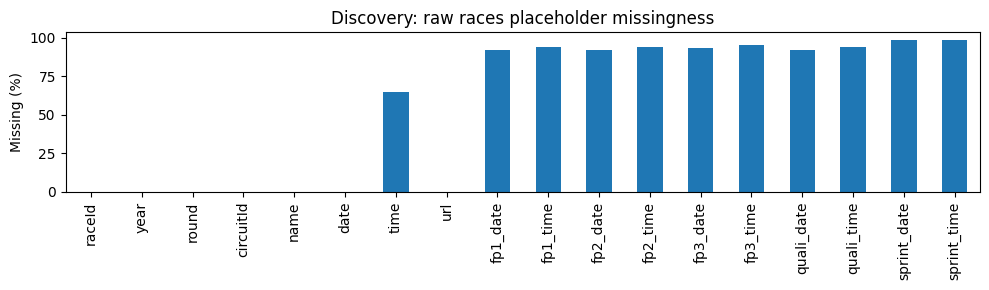

In [378]:
import hashlib
races_raw_snapshot = races.copy(deep=True)
races_csv_hash_before = hashlib.sha256((DATA_DIR / "races.csv").read_bytes()).hexdigest()
races_text = pd.read_csv(DATA_DIR / "races.csv", dtype=str, keep_default_na=False)
print("Raw rows / columns:", races.shape)
display(races.head())
before_r = pd.DataFrame({"sentinel (\\N)": races_text.eq(r"\N").sum()})
before_r["Blank strings"] = races_text.apply(lambda col: col.str.strip().eq("").sum())
before_r["% missing"] = before_r[["sentinel (\\N)", "Blank strings"]].sum(axis=1) / len(races) * 100
display(before_r.round(2))
before_r["% missing"].plot.bar(figsize=(10, 3), title="Discovery: raw races placeholder missingness", ylabel="Missing (%)")
plt.tight_layout(); plt.show()


#### 1. Show the existing cleaning before and after

Literal `\N` placeholders become proper missing values. Dates become datetime values; time-of-day columns become timedeltas measured from midnight. These clock values are not lap durations. A displayed `0 days` is normal because a time of day fits within one day.

The tables below check that conversion did not silently create missing values. A conversion failure would be displayed for investigation rather than filled or corrected by this audit.


,sentinel_before,NaN_after,match
raceId,0,0,True
year,0,0,True
round,0,0,True
circuitId,0,0,True
name,0,0,True
date,0,0,True
time,731,731,True
url,0,0,True
fp1_date,1035,1035,True
fp1_time,1057,1057,True


,Before type,After type,Missing before,Missing after,New missing from conversion
raceId,int64,int64,0,0,0
year,int64,int64,0,0,0
round,int64,int64,0,0,0
circuitId,int64,int64,0,0,0
name,object,object,0,0,0
date,object,datetime64[ns],0,0,0
time,object,timedelta64[ns],731,731,0
url,object,object,0,0,0
fp1_date,object,datetime64[ns],1035,1035,0
fp1_time,object,timedelta64[ns],1057,1057,0


,raceId,date before,date after,time before,time after,fp1_date before,fp1_date after,fp1_time before,fp1_time after
1036,1074,2022-03-20,2022-03-20,15:00:00,0 days 15:00:00,2022-03-18,2022-03-18,12:00:00,0 days 12:00:00
1058,1075,2022-03-27,2022-03-27,17:00:00,0 days 17:00:00,2022-03-25,2022-03-25,14:00:00,0 days 14:00:00
1059,1076,2022-04-10,2022-04-10,05:00:00,0 days 05:00:00,2022-04-08,2022-04-08,03:00:00,0 days 03:00:00
1060,1077,2022-04-24,2022-04-24,13:00:00,0 days 13:00:00,2022-04-22,2022-04-22,11:30:00,0 days 11:30:00
1061,1078,2022-05-08,2022-05-08,19:30:00,0 days 19:30:00,2022-05-06,2022-05-06,18:30:00,0 days 18:30:00


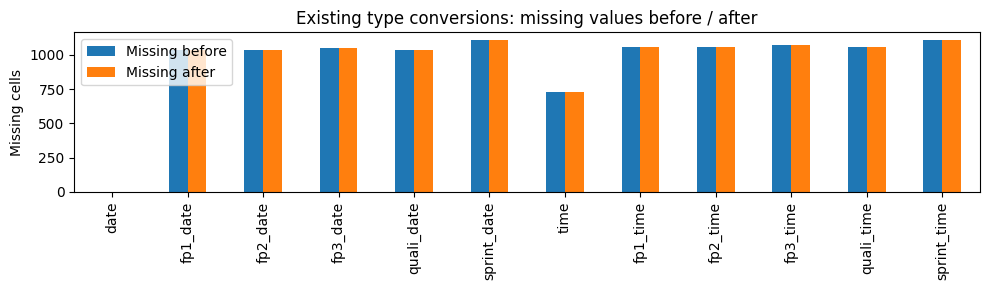

,Rows,Columns,Placeholder / missing cells
Raw,1125,18,11349
Clean,1125,18,11349


In [379]:
# Retain the existing cleaning operations and the existing column names.
races_clean = pd.read_csv(DATA_DIR / "races.csv", keep_default_na=False, na_values=[r"\N"])
races_before_types = races_clean.copy(deep=True)
check_r = pd.DataFrame({"sentinel_before": before_r["sentinel (\\N)"], "NaN_after": races_clean.isna().sum()})
check_r["match"] = check_r["sentinel_before"].eq(check_r["NaN_after"])
display(check_r)
date_cols = ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
for col in date_cols:
    races_clean[col] = pd.to_datetime(races_clean[col], errors="coerce")
time_columns = ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]
for column in time_columns:
    races_clean[column] = pd.to_timedelta(races_clean[column], errors="raise")

races_type_evidence = pd.DataFrame({
    "Before type": races_before_types.dtypes.astype(str),
    "After type": races_clean.dtypes.astype(str),
    "Missing before": races_before_types.isna().sum(),
    "Missing after": races_clean.isna().sum()
})
races_type_evidence["New missing from conversion"] = races_type_evidence["Missing after"] - races_type_evidence["Missing before"]
display(races_type_evidence)
for col in date_cols + time_columns:
    failed = races_before_types[col].notna() & races_clean[col].isna()
    if failed.any():
        print("Conversion needs investigation:", col)
        display(races_before_types.loc[failed, ["raceId", "year", "name", col]])
races_conversion_examples = pd.DataFrame({"raceId": races_clean["raceId"]})
for col in ["date", "time", "fp1_date", "fp1_time"]:
    races_conversion_examples[col + " before"] = races_before_types[col]
    races_conversion_examples[col + " after"] = races_clean[col]
example_mask = races_before_types["time"].notna() & races_before_types["fp1_time"].notna()
display(races_conversion_examples.loc[example_mask].head(5))
races_missing_comparison = races_type_evidence.loc[date_cols + time_columns, ["Missing before", "Missing after"]]
races_missing_comparison.plot.bar(figsize=(10, 3), title="Existing type conversions: missing values before / after", ylabel="Missing cells")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Rows": [len(races), len(races_clean)], "Columns": [races.shape[1], races_clean.shape[1]],
                      "Placeholder / missing cells": [int(before_r["sentinel (\\N)"].sum()), int(races_clean.isna().sum().sum())]}, index=["Raw", "Clean"]))


#### 2. Within-table constraints

We check full duplicate rows, the primary key, the season/round combination, required fields, positive integer identifiers, date/year agreement, clock ranges and round sequencing. The exception table shows any records found by each rule.

**Do not require raceId to be chronological:** it is an identifier. Race order is checked using year, round and date. Missing optional schedule values are reported separately, not automatically treated as invalid records.


### 3.10.2 Races: Data Integrity & Calendar Sequencing
Validating core structural rules (no duplicate IDs, required fields exist) and auditing the calendar logic to flag non-contiguous season rounds or dates that impossibly move backwards mid-season.

In [380]:
races_checks = []
races_exception_tables = {}
def record_races_check(label, mask):
    mask = mask.fillna(False)
    races_checks.append({"Check": label, "Records": int(mask.sum()), "Result": "PASS" if not mask.any() else "INVESTIGATE"})
    if mask.any():
        races_exception_tables[label] = races_clean.loc[mask].copy()
        print(label)
        display(races_exception_tables[label])

record_races_check("Full duplicate rows", races_clean.duplicated(keep=False))
record_races_check("Duplicate raceId", races_clean.duplicated("raceId", keep=False))
record_races_check("Duplicate year / round", races_clean.duplicated(["year", "round"], keep=False))
required_races = ["raceId", "year", "round", "circuitId", "name", "date", "url"]
record_races_check("Missing required fields", races_clean[required_races].isna().any(axis=1))
record_races_check("Blank required names / URLs", races_clean[["name", "url"]].apply(lambda col: col.str.strip().eq("")).any(axis=1))
for col in ["raceId", "year", "round", "circuitId"]:
    values = pd.to_numeric(races_clean[col], errors="coerce")
    record_races_check(col + ": invalid positive integer", values.isna() | ~np.isfinite(values) | values.le(0) | values.mod(1).ne(0))
record_races_check("Race date does not match year", races_clean["date"].notna() & races_clean["year"].ne(races_clean["date"].dt.year))
record_races_check("Literal sentinel or blank still present", races_clean.astype(str).apply(lambda col: col.str.strip().isin([r"\N", ""])).any(axis=1))
for col in time_columns:
    record_races_check(col + ": clock outside one day", races_clean[col].notna() & (races_clean[col].lt(pd.Timedelta(0)) | races_clean[col].ge(pd.Timedelta(days=1))))

rounds = races_clean.groupby("year")["round"].agg(n_races="count", first="min", last="max")
rounds["gap"] = rounds["last"] - rounds["n_races"]
races_round_exceptions = rounds.loc[rounds["first"].ne(1) | rounds["gap"].ne(0)]
print("Seasons with non-contiguous rounds:", len(races_round_exceptions))
display(races_round_exceptions)
races_in_round_order = races_clean.sort_values(["year", "round"])
races_date_reversals = races_in_round_order.loc[races_in_round_order.groupby("year")["date"].diff().lt(pd.Timedelta(0))]
print("Dates moving backwards as season rounds increase:", len(races_date_reversals))
display(races_date_reversals[["raceId", "year", "round", "name", "date"]])
display(pd.DataFrame(races_checks))


Seasons with non-contiguous rounds: 0


,n_races,first,last,gap
year,,,,


Dates moving backwards as season rounds increase: 0


,raceId,year,round,name,date


,Check,Records,Result
0,Full duplicate rows,0,PASS
1,Duplicate raceId,0,PASS
2,Duplicate year / round,0,PASS
3,Missing required fields,0,PASS
4,Blank required names / URLs,0,PASS
5,raceId: invalid positive integer,0,PASS
6,year: invalid positive integer,0,PASS
7,round: invalid positive integer,0,PASS
8,circuitId: invalid positive integer,0,PASS
9,Race date does not match year,0,PASS


#### 3. Relationships with other tables

First, check that the circuit and season referenced by each race exist. Then check race references from every related table in the opposite direction. These checks examine **all rows**, not hand-picked events.

A child row referring to a nonexistent race needs investigation. A race with no rows in a particular child table is only a coverage observation: older qualifying, timing and pit-stop data are incomplete, constructors' competition began later, and most races have no sprint. Absence does not by itself prove an error. Differences between sprint schedule coverage and sprint-result coverage are listed for review, not automatically corrected.


### 3.10.3 Races: Relational Mapping & Sprint Coverage
Verifying foreign keys against the parent reference tables, mapping child table coverage (ensuring lap times, results, etc., link to valid races), and auditing discrepancies between Sprint schedules and actual Sprint results.

In [381]:
races_fk_checks = []
for col, parent, parent_name in [("circuitId", circuits, "circuits"), ("year", seasons, "seasons")]:
    invalid = races_clean[col].notna() & ~races_clean[col].isin(parent[col])
    races_fk_checks.append({"Foreign key": col, "Parent": parent_name, "Missing identifiers": int(races_clean[col].isna().sum()), "Orphans": int(invalid.sum())})
    if invalid.any():
        display(races_clean.loc[invalid])
display(pd.DataFrame(races_fk_checks))

races_child_coverage = []
for table_name in ["results", "qualifying", "lap_times", "pit_stops", "sprint_results", "driver_standings", "constructor_standings", "constructor_results"]:
    child = globals()[table_name]
    absent_identifier = child["raceId"].isna()
    orphan = child["raceId"].notna() & ~child["raceId"].isin(races_clean["raceId"])
    races_child_coverage.append({"Table": table_name, "Missing raceId": int(absent_identifier.sum()), "Orphan rows": int(orphan.sum()),
                                 "Races with records": int(races_clean["raceId"].isin(child["raceId"]).sum()),
                                 "Races without records (coverage only)": int((~races_clean["raceId"].isin(child["raceId"])).sum())})
    if (absent_identifier | orphan).any():
        print("Reference needs investigation:", table_name)
        display(child.loc[absent_identifier | orphan])
display(pd.DataFrame(races_child_coverage))

races_sprint_coverage = races_clean[["raceId", "year", "name", "sprint_date"]].copy()
races_sprint_coverage["Has sprint results"] = races_sprint_coverage["raceId"].isin(sprint_results["raceId"])
races_sprint_coverage["Has sprint date"] = races_sprint_coverage["sprint_date"].notna()
races_sprint_coverage_review = races_sprint_coverage.loc[races_sprint_coverage["Has sprint results"].ne(races_sprint_coverage["Has sprint date"])]
print("Sprint schedule / result coverage differences to review:", len(races_sprint_coverage_review))
display(races_sprint_coverage_review)


,Foreign key,Parent,Missing identifiers,Orphans
0,circuitId,circuits,0,0
1,year,seasons,0,0


,Table,Missing raceId,Orphan rows,Races with records,Races without records (coverage only)
0,results,0,0,1125,0
1,qualifying,0,0,494,631
2,lap_times,0,0,544,581
3,pit_stops,0,0,285,840
4,sprint_results,0,0,18,1107
5,driver_standings,0,0,1125,0
6,constructor_standings,0,0,1061,64
7,constructor_results,0,0,1060,65


Sprint schedule / result coverage differences to review: 0


,raceId,year,name,sprint_date,Has sprint results,Has sprint date


#### 4. Schedule relationships and missing-value coverage

Check recorded session dates against the race date, and list clocks without corresponding dates. Also show dates whose clocks are missing; those are incomplete coverage, not proof that a session did not happen. Session dates may equal the race date, so same-day qualifying is allowed. We do not impose one modern weekend format on every historical event.

The missing-value summary covers all schedule date and clock columns. It describes the gaps; it does not fill them or claim that their individual causes have been established.


fp1: date without clock


,raceId,year,name,date,fp1_date,fp1_time
1035,1053,2021,Emilia Romagna Grand Prix,2021-04-18,2021-04-16,NaT
1037,1052,2021,Bahrain Grand Prix,2021-03-28,2021-03-26,NaT
1038,1051,2021,Qatar Grand Prix,2021-11-21,2021-11-19,NaT
1039,1054,2021,Portuguese Grand Prix,2021-05-02,2021-04-30,NaT
1040,1055,2021,Spanish Grand Prix,2021-05-09,2021-05-07,NaT
1041,1056,2021,Monaco Grand Prix,2021-05-23,2021-05-21,NaT
1042,1057,2021,Azerbaijan Grand Prix,2021-06-06,2021-06-04,NaT
1043,1058,2021,Styrian Grand Prix,2021-06-27,2021-06-25,NaT
1044,1059,2021,French Grand Prix,2021-06-20,2021-06-18,NaT
1045,1060,2021,Austrian Grand Prix,2021-07-04,2021-07-02,NaT


fp2: date without clock


,raceId,year,name,date,fp2_date,fp2_time
1035,1053,2021,Emilia Romagna Grand Prix,2021-04-18,2021-04-16,NaT
1037,1052,2021,Bahrain Grand Prix,2021-03-28,2021-03-26,NaT
1038,1051,2021,Qatar Grand Prix,2021-11-21,2021-11-19,NaT
1039,1054,2021,Portuguese Grand Prix,2021-05-02,2021-04-30,NaT
1040,1055,2021,Spanish Grand Prix,2021-05-09,2021-05-07,NaT
1041,1056,2021,Monaco Grand Prix,2021-05-23,2021-05-21,NaT
1042,1057,2021,Azerbaijan Grand Prix,2021-06-06,2021-06-04,NaT
1043,1058,2021,Styrian Grand Prix,2021-06-27,2021-06-25,NaT
1044,1059,2021,French Grand Prix,2021-06-20,2021-06-18,NaT
1045,1060,2021,Austrian Grand Prix,2021-07-04,2021-07-02,NaT


fp3: date without clock


...

,raceId,year,name,date,quali_date,quali_time
1035,1053,2021,Emilia Romagna Grand Prix,2021-04-18,2021-04-17,NaT
1037,1052,2021,Bahrain Grand Prix,2021-03-28,2021-03-27,NaT
1038,1051,2021,Qatar Grand Prix,2021-11-21,2021-11-20,NaT
1039,1054,2021,Portuguese Grand Prix,2021-05-02,2021-05-01,NaT
1040,1055,2021,Spanish Grand Prix,2021-05-09,2021-05-08,NaT
1041,1056,2021,Monaco Grand Prix,2021-05-23,2021-05-22,NaT
1042,1057,2021,Azerbaijan Grand Prix,2021-06-06,2021-06-05,NaT
1043,1058,2021,Styrian Grand Prix,2021-06-27,2021-06-26,NaT
1044,1059,2021,French Grand Prix,2021-06-20,2021-06-19,NaT
1045,1060,2021,Austrian Grand Prix,2021-07-04,2021-07-03,NaT


sprint: date without clock


,raceId,year,name,date,sprint_date,sprint_time
1046,1061,2021,British Grand Prix,2021-07-18,2021-07-17,NaT
1050,1065,2021,Italian Grand Prix,2021-09-12,2021-09-11,NaT
1055,1071,2021,São Paulo Grand Prix,2021-11-14,2021-11-13,NaT


,Session,Date after race (review),Clock without date (coverage review),Date without clock (coverage only)
0,fp1,0,0,22
1,fp2,0,0,22
2,fp3,0,0,19
3,quali,0,0,22
4,sprint,0,0,3


,Missing count,Missing (%)
date,0,0.00
fp1_date,1035,92.00
fp2_date,1035,92.00
fp3_date,1053,93.60
quali_date,1035,92.00
sprint_date,1107,98.40
time,731,64.98
fp1_time,1057,93.96
fp2_time,1057,93.96
fp3_time,1072,95.29


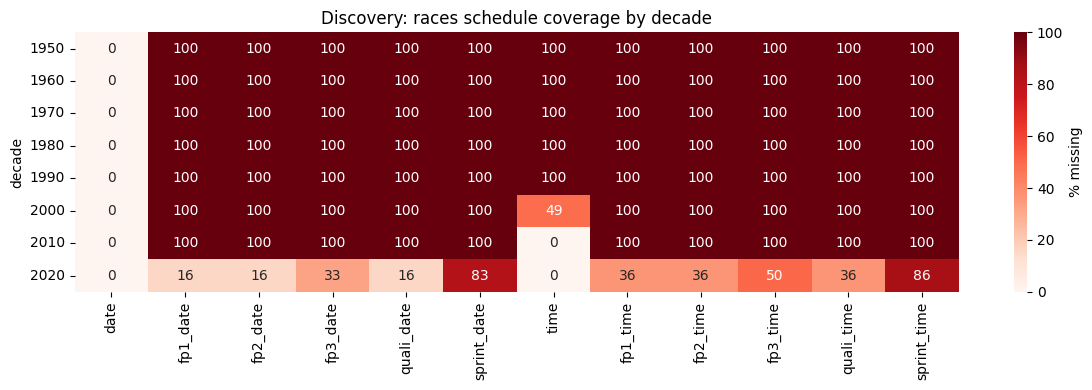

In [382]:
races_schedule_checks = []
races_schedule_review_tables = {}
for session in ["fp1", "fp2", "fp3", "quali", "sprint"]:
    date_col = session + "_date"
    time_col = session + "_time"
    after_race = races_clean[date_col].notna() & races_clean[date_col].gt(races_clean["date"])
    clock_without_date = races_clean[time_col].notna() & races_clean[date_col].isna()
    date_without_clock = races_clean[date_col].notna() & races_clean[time_col].isna()
    races_schedule_checks.append({"Session": session, "Date after race (review)": int(after_race.sum()),
                                  "Clock without date (coverage review)": int(clock_without_date.sum()),
                                  "Date without clock (coverage only)": int(date_without_clock.sum())})
    for label, mask in [("date after race", after_race), ("clock without date", clock_without_date), ("date without clock", date_without_clock)]:
        if mask.any():
            key = session + ": " + label
            races_schedule_review_tables[key] = races_clean.loc[mask, ["raceId", "year", "name", "date", date_col, time_col]].copy()
            print(key)
            display(races_schedule_review_tables[key])
display(pd.DataFrame(races_schedule_checks))
races_schedule_missing = pd.DataFrame({"Missing count": races_clean[date_cols + time_columns].isna().sum(),
                                       "Missing (%)": races_clean[date_cols + time_columns].isna().mean() * 100})
display(races_schedule_missing.round(2))
races_schedule_by_decade = races_clean.assign(decade=(races_clean["year"] // 10) * 10).groupby("decade")[date_cols + time_columns].agg(lambda col: col.isna().mean() * 100)
plt.figure(figsize=(12, 4))
sns.heatmap(races_schedule_by_decade, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.yticks(rotation=0)
plt.title("Discovery: races schedule coverage by decade")
plt.tight_layout(); plt.show()


#### 5. Recover the missing 2021 scheduled times using official evidence

**Meaning:** these fields contain scheduled session dates and start times in UTC. A scheduled time does not prove a session took place or started on time. We fill observed official schedule information, not averages or guesses.

We first check **all races and all five session pairs** for a date with no time. This discovers 88 gaps, all in 2021. Only then do we compare those gaps with official sources. The original historical gaps remain separate.

**Important exception:** Russia FP3 was cancelled. Its filled value is its **planned** start time, not an actual start. [Official cancellation report](https://www.formula1.com/en/latest/article/final-practice-session-for-the-russian-grand-prix-cancelled-due-to-heavy.5M2CsqmNkudVMRbsfu4EIT). No FP3 times are invented for Sprint weekends.


Session date exists but start time is missing: 88


,year,Session,Missing times
0,2021,fp1,22
1,2021,fp2,22
2,2021,fp3,19
3,2021,quali,22
4,2021,sprint,3


,raceId,year,name,Session,Date before,Time before
0,1053,2021,Emilia Romagna Grand Prix,fp1,2021-04-16,NaT
1,1052,2021,Bahrain Grand Prix,fp1,2021-03-26,NaT
2,1051,2021,Qatar Grand Prix,fp1,2021-11-19,NaT
3,1054,2021,Portuguese Grand Prix,fp1,2021-04-30,NaT
4,1055,2021,Spanish Grand Prix,fp1,2021-05-07,NaT
5,1056,2021,Monaco Grand Prix,fp1,2021-05-21,NaT
6,1057,2021,Azerbaijan Grand Prix,fp1,2021-06-04,NaT
7,1058,2021,Styrian Grand Prix,fp1,2021-06-25,NaT
8,1059,2021,French Grand Prix,fp1,2021-06-18,NaT
9,1060,2021,Austrian Grand Prix,fp1,2021-07-02,NaT


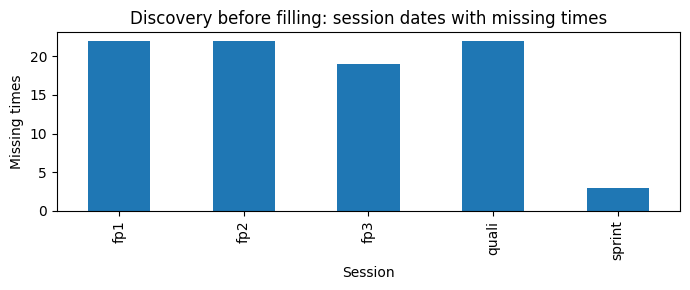

In [383]:
# Discover the gaps across the whole table before changing any values.
races_before_official_schedule = races_clean.copy(deep=True)
schedule_gaps = []
for session in ["fp1", "fp2", "fp3", "quali", "sprint"]:
    missing_time = races_clean[session + "_date"].notna() & races_clean[session + "_time"].isna()
    found = races_clean.loc[missing_time, ["raceId", "year", "name"]].copy()
    found["Session"] = session
    found["Date before"] = races_clean.loc[missing_time, session + "_date"]
    found["Time before"] = races_clean.loc[missing_time, session + "_time"]
    schedule_gaps.append(found)
schedule_gaps = pd.concat(schedule_gaps, ignore_index=True)
print("Session date exists but start time is missing:", len(schedule_gaps))
display(schedule_gaps.groupby(["year", "Session"]).size().rename("Missing times").reset_index())
with pd.option_context("display.max_rows", None):
    display(schedule_gaps)
schedule_gaps.groupby("Session").size().plot.bar(
    figsize=(7, 3), title="Discovery before filling: session dates with missing times", ylabel="Missing times")
plt.tight_layout(); plt.show()
assert len(schedule_gaps) == 88 and schedule_gaps["year"].eq(2021).all()


##### Compare each discovered gap with the official schedule

The small reference table below was transcribed from the 22 linked **official Formula 1 race pages**. The pages' structured schedule timestamps explicitly end in `Z`, meaning UTC. The code needs no internet connection when run on Kaggle.

The comparison covers all 88 gaps and also compares their existing dates. It discovers **two date disagreements**: Monaco FP1 and FP2 are recorded as 21 May, while the official schedule gives **20 May 2021**. These are corrected using the same sources, not by assuming every practice session happens on Friday.


### 3.10.5 Races: 2021 Schedule Reconstruction & Final Validation
Injecting officially verified UTC start times for the 2021 season to repair the identified schedule gaps. Concludes with a rigorous suite of assertion tests confirming that exactly 90 cells were updated without unintended data loss.

In [384]:
# Columns: race ID, official page, then the scheduled UTC start of each session.
official_2021_rows = [
    [1052, 'bahrain', '2021-03-26T11:30:00.000Z', '2021-03-26T15:00:00.000Z', '2021-03-27T12:00:00.000Z', '2021-03-27T15:00:00.000Z', None],
    [1053, 'emiliaromagna', '2021-04-16T09:00:00.000Z', '2021-04-16T12:30:00.000Z', '2021-04-17T09:00:00.000Z', '2021-04-17T12:00:00.000Z', None],
    [1054, 'portugal', '2021-04-30T10:30:00.000Z', '2021-04-30T14:00:00.000Z', '2021-05-01T11:00:00.000Z', '2021-05-01T14:00:00.000Z', None],
    [1055, 'spain', '2021-05-07T09:30:00.000Z', '2021-05-07T13:00:00.000Z', '2021-05-08T10:00:00.000Z', '2021-05-08T13:00:00.000Z', None],
    [1056, 'monaco', '2021-05-20T09:30:00.000Z', '2021-05-20T13:00:00.000Z', '2021-05-22T10:00:00.000Z', '2021-05-22T13:00:00.000Z', None],
    [1057, 'azerbaijan', '2021-06-04T08:30:00.000Z', '2021-06-04T12:00:00.000Z', '2021-06-05T09:00:00.000Z', '2021-06-05T12:00:00.000Z', None],
    [1059, 'france', '2021-06-18T09:30:00.000Z', '2021-06-18T13:00:00.000Z', '2021-06-19T10:00:00.000Z', '2021-06-19T13:00:00.000Z', None],
    [1058, 'styria', '2021-06-25T09:30:00.000Z', '2021-06-25T13:00:00.000Z', '2021-06-26T10:00:00.000Z', '2021-06-26T13:00:00.000Z', None],
    [1060, 'austria', '2021-07-02T09:30:00.000Z', '2021-07-02T13:00:00.000Z', '2021-07-03T10:00:00.000Z', '2021-07-03T13:00:00.000Z', None],
    [1061, 'great-britain', '2021-07-16T13:30:00.000Z', '2021-07-17T11:00:00.000Z', None, '2021-07-16T17:00:00.000Z', '2021-07-17T15:30:00.000Z'],
    [1062, 'hungary', '2021-07-30T09:30:00.000Z', '2021-07-30T13:00:00.000Z', '2021-07-31T10:00:00.000Z', '2021-07-31T13:00:00.000Z', None],
    [1063, 'belgium', '2021-08-27T09:30:00.000Z', '2021-08-27T13:00:00.000Z', '2021-08-28T10:00:00.000Z', '2021-08-28T13:00:00.000Z', None],
    [1064, 'netherlands', '2021-09-03T09:30:00.000Z', '2021-09-03T13:00:00.000Z', '2021-09-04T10:00:00.000Z', '2021-09-04T13:00:00.000Z', None],
    [1065, 'italy', '2021-09-10T12:30:00.000Z', '2021-09-11T10:00:00.000Z', None, '2021-09-10T16:00:00.000Z', '2021-09-11T14:30:00.000Z'],
    [1066, 'russia', '2021-09-24T08:30:00.000Z', '2021-09-24T12:00:00.000Z', '2021-09-25T09:00:00.000Z', '2021-09-25T12:00:00.000Z', None],
    [1067, 'turkey', '2021-10-08T08:30:00.000Z', '2021-10-08T12:00:00.000Z', '2021-10-09T09:00:00.000Z', '2021-10-09T12:00:00.000Z', None],
    [1069, 'united-states', '2021-10-22T16:30:00.000Z', '2021-10-22T20:00:00.000Z', '2021-10-23T18:00:00.000Z', '2021-10-23T21:00:00.000Z', None],
    [1070, 'mexico', '2021-11-05T17:30:00.000Z', '2021-11-05T21:00:00.000Z', '2021-11-06T17:00:00.000Z', '2021-11-06T20:00:00.000Z', None],
    [1071, 'brazil', '2021-11-12T15:30:00.000Z', '2021-11-13T15:00:00.000Z', None, '2021-11-12T19:00:00.000Z', '2021-11-13T19:30:00.000Z'],
    [1051, 'qatar', '2021-11-19T10:30:00.000Z', '2021-11-19T14:00:00.000Z', '2021-11-20T11:00:00.000Z', '2021-11-20T14:00:00.000Z', None],
    [1072, 'saudi-arabia', '2021-12-03T13:30:00.000Z', '2021-12-03T17:00:00.000Z', '2021-12-04T14:00:00.000Z', '2021-12-04T17:00:00.000Z', None],
    [1073, 'united-arab-emirates', '2021-12-10T09:30:00.000Z', '2021-12-10T13:00:00.000Z', '2021-12-11T10:00:00.000Z', '2021-12-11T13:00:00.000Z', None],
]
official_2021 = pd.DataFrame(official_2021_rows, columns=[
    "raceId", "page", "fp1", "fp2", "fp3", "quali", "sprint"])
official_2021["Source"] = "https://www.formula1.com/en/racing/2021/" + official_2021["page"]
official_schedule = official_2021.melt(
    id_vars=["raceId", "Source"], value_vars=["fp1", "fp2", "fp3", "quali", "sprint"],
    var_name="Session", value_name="Official start UTC").dropna(subset=["Official start UTC"])
official_schedule["Official start UTC"] = pd.to_datetime(official_schedule["Official start UTC"], utc=True)
official_schedule["Official date"] = official_schedule["Official start UTC"].dt.tz_localize(None).dt.normalize()
official_schedule["Official time UTC"] = pd.to_timedelta(official_schedule["Official start UTC"].dt.strftime("%H:%M:%S"))
official_schedule["Note"] = "Scheduled start, not actual start"
official_schedule.loc[
    official_schedule["raceId"].eq(1066) & official_schedule["Session"].eq("fp3"), "Note"
] = "CANCELLED: planned start only"

schedule_evidence = schedule_gaps.merge(official_schedule, on=["raceId", "Session"], how="left", validate="one_to_one")
assert len(schedule_evidence) == 88
assert schedule_evidence["Official start UTC"].notna().all()
schedule_evidence["Date matches"] = schedule_evidence["Date before"].eq(schedule_evidence["Official date"])
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(schedule_evidence[["raceId", "name", "Session", "Date before", "Official date", "Time before", "Official time UTC", "Note", "Source"]])
date_disagreements = schedule_evidence.loc[~schedule_evidence["Date matches"]]
print("Existing dates differing from official dates:", len(date_disagreements))
display(date_disagreements[["raceId", "name", "Session", "Date before", "Official date", "Source"]])
assert len(date_disagreements) == 2


,raceId,name,Session,Date before,Official date,Time before,Official time UTC,Note,Source
0,1053,Emilia Romagna Grand Prix,fp1,2021-04-16,2021-04-16,NaT,0 days 09:00:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/emiliaromagna
1,1052,Bahrain Grand Prix,fp1,2021-03-26,2021-03-26,NaT,0 days 11:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/bahrain
2,1051,Qatar Grand Prix,fp1,2021-11-19,2021-11-19,NaT,0 days 10:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/qatar
3,1054,Portuguese Grand Prix,fp1,2021-04-30,2021-04-30,NaT,0 days 10:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/portugal
4,1055,Spanish Grand Prix,fp1,2021-05-07,2021-05-07,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/spain
5,1056,Monaco Grand Prix,fp1,2021-05-21,2021-05-20,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/monaco
6,1057,Azerbaijan Grand Prix,fp1,2021-06-04,2021-06-04,NaT,0 days 08:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/azerbaijan
7,1058,Styrian Grand Prix,fp1,2021-06-25,2021-06-25,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/styria
8,1059,French Grand Prix,fp1,2021-06-18,2021-06-18,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/france
9,1060,Austrian Grand Prix,fp1,2021-07-02,2021-07-02,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/austria


Existing dates differing from official dates: 2


,raceId,name,Session,Date before,Official date,Source
5,1056,Monaco Grand Prix,fp1,2021-05-21,2021-05-20,https://www.formula1.com/en/racing/2021/monaco
27,1056,Monaco Grand Prix,fp2,2021-05-21,2021-05-20,https://www.formula1.com/en/racing/2021/monaco


##### Apply only the verified corrections to the clean copy

Fill the missing clock for each discovered gap. Where its date disagrees with the official date, correct that date too. The evidence tables remain separate; **no columns are added to `races_clean`**.

Only 88 time cells and two Monaco date cells should change. The raw table, older missing schedules, and sessions with no scheduled date remain unchanged.


,raceId,Race,Session,Date before,Date after,Time before,Time after UTC,Note
0,1053,Emilia Romagna Grand Prix,fp1,2021-04-16,2021-04-16,NaT,0 days 09:00:00,"Scheduled start, not actual start"
1,1052,Bahrain Grand Prix,fp1,2021-03-26,2021-03-26,NaT,0 days 11:30:00,"Scheduled start, not actual start"
2,1051,Qatar Grand Prix,fp1,2021-11-19,2021-11-19,NaT,0 days 10:30:00,"Scheduled start, not actual start"
3,1054,Portuguese Grand Prix,fp1,2021-04-30,2021-04-30,NaT,0 days 10:30:00,"Scheduled start, not actual start"
4,1055,Spanish Grand Prix,fp1,2021-05-07,2021-05-07,NaT,0 days 09:30:00,"Scheduled start, not actual start"
5,1056,Monaco Grand Prix,fp1,2021-05-21,2021-05-20,NaT,0 days 09:30:00,"Scheduled start, not actual start"
6,1057,Azerbaijan Grand Prix,fp1,2021-06-04,2021-06-04,NaT,0 days 08:30:00,"Scheduled start, not actual start"
7,1058,Styrian Grand Prix,fp1,2021-06-25,2021-06-25,NaT,0 days 09:30:00,"Scheduled start, not actual start"
8,1059,French Grand Prix,fp1,2021-06-18,2021-06-18,NaT,0 days 09:30:00,"Scheduled start, not actual start"
9,1060,Austrian Grand Prix,fp1,2021-07-02,2021-07-02,NaT,0 days 09:30:00,"Scheduled start, not actual start"


,Missing before,Missing after
Session,,
fp1,22,0
fp2,22,0
fp3,19,0
quali,22,0
sprint,3,0


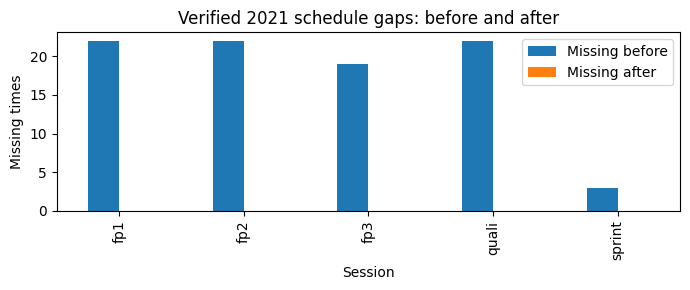

,Changed cells
fp1_date,1
fp1_time,22
fp2_date,1
fp2_time,22
fp3_time,19
quali_time,22
sprint_time,3


,Session,Check after filling,Records
0,fp1,Date after race,0
1,fp1,Time without date,0
2,fp1,Date without time,0
3,fp1,Clock outside one day,0
4,fp2,Date after race,0
5,fp2,Time without date,0
6,fp2,Date without time,0
7,fp2,Clock outside one day,0
8,fp3,Date after race,0
9,fp3,Time without date,0


PASS: 88 verified times filled; 2 Monaco dates corrected; other cells unchanged.
Russia FP3 remains documented as cancelled: its stored clock is scheduled, not actual.
Remaining missing schedule values across all years (not automatically errors):


,Still missing
date,0
fp1_date,1035
fp2_date,1035
fp3_date,1053
quali_date,1035
sprint_date,1107
time,731
fp1_time,1035
fp2_time,1035
fp3_time,1053


In [385]:
for _, record in schedule_evidence.iterrows():
    row = races_clean["raceId"].eq(record["raceId"])
    session = record["Session"]
    assert row.sum() == 1
    assert races_clean.loc[row, session + "_time"].isna().all()
    races_clean.loc[row, session + "_time"] = record["Official time UTC"]
    if not record["Date matches"]:
        races_clean.loc[row, session + "_date"] = record["Official date"]

# Show every changed session before and after.
schedule_after = []
for _, record in schedule_evidence.iterrows():
    row = races_clean.loc[races_clean["raceId"].eq(record["raceId"])].iloc[0]
    session = record["Session"]
    schedule_after.append({"raceId": record["raceId"], "Race": record["name"], "Session": session,
        "Date before": record["Date before"], "Date after": row[session + "_date"],
        "Time before": record["Time before"], "Time after UTC": row[session + "_time"], "Note": record["Note"]})
schedule_after = pd.DataFrame(schedule_after)
with pd.option_context("display.max_rows", None):
    display(schedule_after)

schedule_before_after = schedule_after.groupby("Session").agg(
    **{"Missing before": ("Time before", lambda col: col.isna().sum()),
       "Missing after": ("Time after UTC", lambda col: col.isna().sum())})
display(schedule_before_after)
schedule_before_after.plot.bar(figsize=(7, 3), title="Verified 2021 schedule gaps: before and after", ylabel="Missing times")
plt.tight_layout(); plt.show()

# Check exactly which cells changed, including missing values safely.
same_cells = races_before_official_schedule.eq(races_clean) | (races_before_official_schedule.isna() & races_clean.isna())
changed_cells = (~same_cells).sum()
display(changed_cells[changed_cells.gt(0)].rename("Changed cells").to_frame())
assert changed_cells.sum() == 90
assert changed_cells[["fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]].sum() == 88
assert changed_cells[["fp1_date", "fp2_date"]].sum() == 2
assert schedule_after["Time after UTC"].notna().all()
pd.testing.assert_frame_equal(races_clean.loc[races_clean["year"].ne(2021)], races_before_official_schedule.loc[races_clean["year"].ne(2021)])

# Repeat relevant schedule checks after the correction.
post_schedule_checks = []
for session in ["fp1", "fp2", "fp3", "quali", "sprint"]:
    dates = races_clean[session + "_date"]
    clocks = races_clean[session + "_time"]
    violations = {
        "Date after race": dates.gt(races_clean["date"]),
        "Time without date": clocks.notna() & dates.isna(),
        "Date without time": dates.notna() & clocks.isna(),
        "Clock outside one day": clocks.notna() & (clocks.lt(pd.Timedelta(0)) | clocks.ge(pd.Timedelta(days=1)))}
    for check, mask in violations.items():
        post_schedule_checks.append({"Session": session, "Check after filling": check, "Records": int(mask.sum())})
display(pd.DataFrame(post_schedule_checks))
assert all(check["Records"] == 0 for check in post_schedule_checks)
print("PASS: 88 verified times filled; 2 Monaco dates corrected; other cells unchanged.")
print("Russia FP3 remains documented as cancelled: its stored clock is scheduled, not actual.")
print("Remaining missing schedule values across all years (not automatically errors):")
display(races_clean[date_cols + time_columns].isna().sum().rename("Still missing").to_frame())


In [386]:
# Independently reconstruct the allowed changes from the raw CSV.
races_expected = pd.read_csv(DATA_DIR / "races.csv", keep_default_na=False, na_values=[r"\N"])
for col in date_cols:
    races_expected[col] = pd.to_datetime(races_expected[col], errors="coerce")
for col in time_columns:
    races_expected[col] = pd.to_timedelta(races_expected[col], errors="raise")
for _, record in official_schedule.iterrows():
    row = races_expected["raceId"].eq(record["raceId"])
    session = record["Session"]
    races_expected.loc[row, session + "_date"] = record["Official date"]
    races_expected.loc[row, session + "_time"] = record["Official time UTC"]
pd.testing.assert_frame_equal(races_clean, races_expected)
pd.testing.assert_frame_equal(races, races_raw_snapshot)
pd.testing.assert_frame_equal(races, pd.read_csv(DATA_DIR / "races.csv"))
assert races_csv_hash_before == hashlib.sha256((DATA_DIR / "races.csv").read_bytes()).hexdigest()
assert list(races_clean.columns) == list(races.columns)
assert len(races_clean) == len(races)
print("PASS: raw CSV and raw DataFrame unchanged; only verified schedule corrections added to type conversions; original rows and columns retained.")


PASS: raw CSV and raw DataFrame unchanged; only verified schedule corrections added to type conversions; original rows and columns retained.


#### 6. Status and remaining work

| Requirement | Status | Evidence |
|---|---|---|
| 1. General validation and investigation | PARTIALLY DONE | Structural and relationship checks shown. All 88 date-present/time-missing gaps investigated; older schedule coverage remains incomplete. |
| 2. Evidence and visualizations | DONE | Discovery tables/plots, official comparisons with links, date disagreements, all 88 before/after rows, and missingness comparison plot. |
| 3. Duplicates and required fields | DONE | All-row checks for full rows, raceId, year/round and required fields. |
| 4. Placeholder handling | DONE | Literal placeholders converted to proper missing values; 88 verified 2021 clocks restored. Missing does not automatically mean invalid. |
| 5. Semantic types | DONE | Datetime dates, timedelta clocks from midnight, numeric identifiers. Official timestamps explicitly UTC. |
| 6. Primary and foreign keys | DONE | Primary key, outgoing circuit/season references, and incoming race references checked. No IDs are changed by schedule correction. |
| 7. Discovery before action | DONE for shown scope | All-row gap detection precedes official comparison and correction; date mismatches are displayed first. |
| 8. Raw preservation | DONE | Raw equality and CSV hash checks; exactly 90 changed clean cells, with no rows or columns added or removed. |
| 9. Objective evidence only | DONE for shown scope | External values used only for discovered gaps and the two date contradictions revealed by their comparison. Russia FP3 explicitly identified as scheduled but cancelled. |

**Meaning of remaining missing values:** race clocks before 2005 and session schedules before 2021 have incomplete source coverage. Their exact historical values have not been recovered or guessed. For 2021–2024, the 18 missing FP3 dates coincide with Sprint-result weekends, which have no third practice. Sprint dates match the 18 races with Sprint results; other weekends have no recorded Sprint. These structurally absent sessions must not receive invented start times.

This section does not claim every historical schedule value is verified or every missing field resolved. No median filling, zero filling or record deletion was applied.


## 3.11 results.csv

### 3.11.1 Results: Race-Driver Duplicates & Shared Drives
Loading the raw `results` dataset and cross-referencing it with metadata to audit duplicate race-driver combinations. This analysis explicitly separates historical shared drives (permitted before 1958) from modern data anomalies, and flags conflicting podium outcomes for a single driver.

In [387]:
res_raw = pd.read_csv(DATA_DIR / "results.csv", keep_default_na=False, na_values=[r"\N"])
meta = (res_raw
        .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race"}), on="raceId")
        .merge(drivers[["driverId", "surname"]], on="driverId")
        .merge(constructors[["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
        .merge(status, on="statusId"))
assert len(meta) == len(res_raw)          # joins must not add or drop rows

key = ["raceId", "driverId"]
dups = meta[meta.duplicated(key, keep=False)].sort_values(key + ["resultId"])

pairs = dups.groupby(key).agg(
    year=("year", "first"),
    n_rows=("resultId", "size"),
    n_constructors=("constructorId", "nunique"),
    n_started=("grid", lambda s: int((s > 0).sum())),
    n_podium_rows=("positionOrder", lambda s: int((s <= 3).sum())),
)
pairs["era"] = np.where(pairs["year"] <= 1958, "1950-1958", "after 1958")
pairs["podium_disagree"] = (pairs["n_podium_rows"] > 0) & (pairs["n_podium_rows"] < pairs["n_rows"])

print("pairs:", len(pairs), "| extra rows:", int((pairs["n_rows"] - 1).sum()))
display(pairs.groupby("era").agg(
    pairs=("n_rows", "size"),
    same_constructor=("n_constructors", lambda s: int((s == 1).sum())),
    none_started=("n_started", lambda s: int((s == 0).sum())),
    podium_disagree=("podium_disagree", "sum")))

cols = ["resultId", "year", "race", "surname", "constructor", "grid",
        "positionOrder", "points", "laps", "status"]
print("\nPairs after 1958:")
display(dups[dups["year"] > 1958][cols])

print("\nFirst pairs where the rows disagree on podium:")
disagree = pairs[pairs["podium_disagree"]].index
display(dups.set_index(key).loc[disagree].reset_index()[["raceId"] + cols].head(20))

pairs: 85 | extra rows: 91


,pairs,same_constructor,none_started,podium_disagree
era,,,,
1950-1958,79,66,1,20
after 1958,6,3,2,1



Pairs after 1958:


,resultId,year,race,surname,constructor,grid,positionOrder,points,laps,status
13188,13189,1978,Italian Grand Prix,Ertl,ATS,0,26,0.0,0,Did not qualify
13191,13192,1978,Italian Grand Prix,Ertl,Ensign,0,29,0.0,0,Did not prequalify
17362,17363,1964,United States Grand Prix,Clark,Lotus-Climax,1,7,0.0,102,Out of fuel
24298,24304,1964,United States Grand Prix,Clark,Lotus-Climax,1,12,0.0,54,Injection
17740,17741,1962,British Grand Prix,Greene,Lotus-Climax,0,22,0.0,0,Withdrew
17743,17744,1962,British Grand Prix,Greene,Gilby,0,25,0.0,0,Withdrew
17961,17962,1961,British Grand Prix,Moss,Ferguson,20,19,0.0,56,Disqualified
17963,17964,1961,British Grand Prix,Moss,Lotus-Climax,5,21,0.0,44,Brakes
18062,18063,1961,United States Grand Prix,Gregory,Lotus-Climax,11,17,0.0,23,Gearbox
24297,24303,1961,United States Grand Prix,Gregory,Lotus-Climax,15,11,0.0,92,+8 Laps



First pairs where the rows disagree on podium:


,raceId,resultId,year,race,surname,constructor,grid,positionOrder,points,laps,status
0,746,18083,1960,Argentine Grand Prix,Moss,Cooper-Climax,1,17,0.0,40,Suspension
1,746,22372,1960,Argentine Grand Prix,Moss,Cooper-Climax,8,3,0.0,80,Finished
2,780,18817,1957,British Grand Prix,Moss,Vanwall,1,12,0.0,51,Engine
3,780,20291,1957,British Grand Prix,Moss,Vanwall,3,1,5.0,90,Finished
4,780,18806,1957,British Grand Prix,Brooks,Vanwall,3,1,4.0,90,Finished
5,780,20293,1957,British Grand Prix,Brooks,Vanwall,1,12,0.0,51,Engine
6,784,18895,1956,Argentine Grand Prix,Fangio,Ferrari,1,13,0.0,22,Fuel pump
7,784,20267,1956,Argentine Grand Prix,Fangio,Ferrari,3,1,5.0,98,Finished
8,785,18899,1956,Monaco Grand Prix,Fangio,Ferrari,1,4,1.5,99,+1 Lap
9,785,20270,1956,Monaco Grand Prix,Fangio,Ferrari,9,2,4.0,100,Finished


In [388]:
d = dups.copy()
d["grid_sort"] = d["grid"].where(d["grid"] > 0, 10_000)                 # grid 0 sorts last
best_slot = d.groupby(key)["grid_sort"].min().rename("best_slot")         # best declared start slot
credit    = (d.groupby(key)["positionOrder"].min() <= 3).rename("credit") # podium credited in any row

rules = {"lowest resultId":        ["resultId"],
         "best positionOrder":     ["positionOrder", "resultId"],
         "smallest started grid":  ["grid_sort", "resultId"]}

out = []
for name, cols in rules.items():
    kept = (d.sort_values(key + cols).drop_duplicates(key)
              .set_index(key).join(best_slot).join(credit))
    out.append({"rule": name,
                "podium rate": round((kept["positionOrder"] <= 3).mean(), 3),
                "label != credited podium": int(((kept["positionOrder"] <= 3) != kept["credit"]).sum()),
                "kept grid != best slot": int((kept["grid_sort"] != kept["best_slot"]).sum())})
pd.DataFrame(out)

,rule,podium rate,label != credited podium,kept grid != best slot
0,lowest resultId,0.071,16,27
1,best positionOrder,0.259,0,56
2,smallest started grid,0.059,17,0


### **Results table** 

### 3.11.2 Results: Initial Auditing & Time Conversions
Loading the raw `results` dataset, tracking `\N` sentinel frequencies, and casting duration columns (`fastestLapTime` and `time`) into numeric seconds. This includes a manual, evidence-backed correction for a specific total-duration discrepancy (Belgium 2024).

In [389]:
print("shape:", results.shape)
print("columns:", list(results.columns))
results.head()

shape: (26759, 18)
columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId']


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [ ]:
before_res = pd.DataFrame({"sentinel (\\N)": (results == r"\N").sum()})
before_res["% missing"] = (100 * before_res["sentinel (\\N)"] / len(results)).round(2)
before_res

In [ ]:
before_res["% missing"].plot(kind="bar", color="tab:red", figsize=(10, 3.5),
                             title="results (raw): % of values equal to \\N")
plt.ylabel("%")
plt.show()

In [ ]:
results_clean = pd.read_csv(DATA_DIR / "results.csv", keep_default_na=False, na_values=[r"\N"])
results_clean.head()

In [ ]:
check_res = pd.DataFrame({"sentinel_before": before_res["sentinel (\\N)"],
                          "NaN_after": results_clean.isnull().sum()})
check_res["match"] = check_res["sentinel_before"] == check_res["NaN_after"]
check_res

In [ ]:
# Convert the existing fastestLapTime column to numeric seconds.
n_before = results_clean["fastestLapTime"].isna().sum()
results_clean["fastestLapTime"] = results_clean["fastestLapTime"].map(to_seconds)
print("new missing values created:", results_clean["fastestLapTime"].isna().sum() - n_before)
results_clean[["fastestLapTime"]].dropna().head()


In [ ]:
# Convert the existing race time column to numeric seconds.
# Original + values are gaps; other values are total elapsed times.
# Conversion does not make gaps and total durations comparable.
time_before = results_clean["time"].copy()
results_clean["time"] = results_clean["time"].map(to_seconds)
assert time_before.notna().equals(results_clean["time"].notna())
assert pd.api.types.is_numeric_dtype(results_clean["time"])
print("Race time converted to seconds without losing populated values.")
results_clean[["time", "milliseconds"]].dropna().head(10)


### Check race duration against milliseconds before correcting anything

We check every populated **total-duration** record. The original `time` values starting with `+` are gaps, so they must not be compared directly with total elapsed `milliseconds`. For each comparable row, `time` converted to seconds and multiplied by 1,000 should equal `milliseconds`.

The table below displays all mismatches discovered by this general check, with race and driver details. It runs before the correction.


In [ ]:
# Select total times using the original strings; results_clean.time is already seconds.
original_duration_text = results.set_index("resultId")["time"]
is_total_duration = ~results_clean["resultId"].map(original_duration_text).astype("string").str.startswith("+", na=False)
duration_check = results_clean.loc[
    is_total_duration & results_clean["time"].notna() & results_clean["milliseconds"].notna(),
    ["resultId", "raceId", "driverId", "time", "milliseconds"]
].copy()
duration_check["Expected milliseconds"] = (duration_check["time"] * 1000).round().astype("int64")
duration_check["Difference (ms)"] = duration_check["milliseconds"] - duration_check["Expected milliseconds"]
duration_mismatches = duration_check.loc[duration_check["Difference (ms)"].ne(0)].copy()
duration_mismatches = duration_mismatches.merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
).merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
print("Comparable total-duration records checked:", len(duration_check))
print("Mismatches before correction:", len(duration_mismatches))
display(duration_mismatches)


### Verify the discovered mismatch using the official result

The [official Formula 1 Belgian Grand Prix 2024 result](https://www.formula1.com/en/results/2024/races/1242/belgium/race-result) lists car 63, George Russell, Mercedes, 44 laps, **1:19:57.040**, disqualified, zero points. This matches our driver, race, car and recorded time.

That duration equals **4,797,040 milliseconds**, whereas the raw CSV contains **4,797,566**. We therefore correct only `results_clean.milliseconds` for `resultId = 26564`. Russell's disqualification, position, points and other values are preserved. This is a verified disagreement between two representations of the same duration, not a flag based on an unusual value.


In [ ]:
# Fixed observation checked on the official F1 result page.
verified_duration = pd.DataFrame({
    "resultId": [26564], "raceId": [1134], "driverId": [847],
    "Official time": ["1:19:57.040"], "Official milliseconds": [4797040],
    "Source": ["https://www.formula1.com/en/results/2024/races/1242/belgium/race-result"]
})
assert set(duration_mismatches["resultId"]) == set(verified_duration["resultId"])
assert duration_mismatches["Expected milliseconds"].tolist() == verified_duration["Official milliseconds"].tolist()
results_before_duration_fix = results_clean.copy(deep=True)
for _, correction in verified_duration.iterrows():
    match = (results_clean["resultId"].eq(correction["resultId"])
             & results_clean["raceId"].eq(correction["raceId"])
             & results_clean["driverId"].eq(correction["driverId"]))
    assert match.sum() == 1
    assert results_clean.loc[match, "time"].iloc[0] == to_seconds(correction["Official time"])
    results_clean.loc[match, "milliseconds"] = correction["Official milliseconds"]

# Prove that other columns and unaffected rows were preserved.
pd.testing.assert_frame_equal(
    results_before_duration_fix.drop(columns="milliseconds"),
    results_clean.drop(columns="milliseconds")
)
unaffected = ~results_clean["resultId"].isin(verified_duration["resultId"])
pd.testing.assert_frame_equal(results_before_duration_fix.loc[unaffected], results_clean.loc[unaffected])
duration_before_after = verified_duration.merge(
    results_before_duration_fix[["resultId", "milliseconds"]].rename(columns={"milliseconds": "Before milliseconds"}),
    on="resultId", validate="one_to_one"
).merge(
    results_clean[["resultId", "milliseconds"]].rename(columns={"milliseconds": "After milliseconds"}),
    on="resultId", validate="one_to_one"
)
display(duration_before_after)

# Repeat the same full-table check after the correction.
checked_after = results_clean.set_index("resultId").loc[duration_check["resultId"], "milliseconds"].to_numpy()
remaining_duration_mismatches = int((checked_after != duration_check["Expected milliseconds"].to_numpy()).sum())
assert remaining_duration_mismatches == 0
print("Mismatches after correction:", remaining_duration_mismatches)
pd.Series({"Before correction": len(duration_mismatches), "After correction": remaining_duration_mismatches}).plot.bar(
    rot=0, color=["tab:orange", "tab:green"], figsize=(6, 3)
)
plt.ylabel("Records with disagreeing total-duration values")
plt.title("Full-table duration consistency check: before and after")
plt.tight_layout()
plt.show()


### 3.11.3 Results: Shared Drive Consolidation & Integrity Checks
Resolving multi-entry driver-race pairs (historical shared drives). The pipeline consolidates these by keeping the car with the best finishing position while summing the total points earned. Concludes with foreign key validation across all parent reference tables and a missingness heatmap by decade.

In [ ]:
print("positionOrder missing:", results_clean["positionOrder"].isna().sum(), "(must be 0)")
print("positionOrder < 1    :", (results_clean["positionOrder"] < 1).sum(), "(must be 0)")
print("grid range:", results_clean["grid"].min(), "->", results_clean["grid"].max())
print("negative points:", (results_clean["points"] < 0).sum())

In [ ]:
n_dup = results_clean.duplicated(subset=["raceId", "driverId"]).sum()
print("extra rows (same driver twice in the same race):", n_dup)

In [ ]:
dup_rows = results_clean[results_clean.duplicated(["raceId", "driverId"], keep=False)].sort_values(["raceId", "driverId", "resultId"])
print("rows involved:", len(dup_rows))
dup_rows[["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "points", "laps", "statusId"]].head(20)

In [ ]:
years = pd.read_csv(DATA_DIR / "races.csv", usecols=["raceId", "year"])
dup_plot = dup_rows.merge(years, on="raceId", how="left")     # copy for plotting only

dup_plot.groupby("year").size().plot(kind="bar", color="tab:orange", figsize=(10, 3.5),
                                     title="results (raw): rows involved in a duplicate, per season")
plt.ylabel("rows")
plt.show()

# In how many duplicated pairs did exactly one of the rows start from a real grid slot (grid > 0)?
started_per_pair = dup_rows.groupby(["raceId", "driverId"])["grid"].apply(lambda g: (g > 0).sum())
print("number of started rows per duplicated pair:")
started_per_pair.value_counts()

In [ ]:
# Summarize every original entry BEFORE selecting one car.
key = ["raceId", "driverId"]
results_before_combine = results_clean.copy(deep=True)
per_pair = (results_before_combine.groupby(key)
            .agg(total_points=("points", "sum"),
                 n_raw_rows=("resultId", "size"))
            .reset_index())

# Keep all other details from the car with the best (lowest) positionOrder.
# If positionOrder is tied, keep the smallest resultId for a repeatable choice.
kept = (results_before_combine
        .sort_values(key + ["positionOrder", "resultId"])
        .drop_duplicates(key, keep="first")
        .drop(columns="points"))
results_clean = kept.merge(per_pair, on=key, validate="one_to_one")
results_clean = results_clean.rename(columns={"total_points": "points"})
# Retained for compatibility with the existing checks below.
results_clean["positionOrder_row"] = results_clean["positionOrder"]
results_clean = results_clean.sort_values("resultId").reset_index(drop=True)

print("Rows before:", len(results_before_combine))
print("Rows after:", len(results_clean))
print("Entries combined:", len(results_before_combine) - len(results_clean))
print("Driver-race groups with multiple entries:", int(results_clean["n_raw_rows"].gt(1).sum()))


In [ ]:
assert not results_clean.duplicated(["raceId", "driverId"]).any()
print("OK: (raceId, driverId) is unique")

In [ ]:
# Check the combined result against ALL original entries.
expected = results_before_combine.groupby(key).agg(
    points=("points", "sum"),
    n_raw_rows=("resultId", "size"),
    positionOrder=("positionOrder", "min")
).sort_index()
actual = results_clean.set_index(key)[expected.columns].sort_index()
pd.testing.assert_frame_equal(actual, expected)
assert results_clean["n_raw_rows"].sum() == len(results_before_combine)

# Show every multi-entry group before and after combining it.
multiple_keys = per_pair.loc[per_pair["n_raw_rows"].gt(1), key]
show_columns = key + ["resultId", "constructorId", "number", "grid", "positionOrder", "points", "laps", "statusId"]
print("Before combining: all entries in these groups")
display(results_before_combine.merge(multiple_keys, on=key)[show_columns].sort_values(key + ["positionOrder"]))
print("After combining: best-finishing car details and summed points")
display(results_clean.loc[results_clean["n_raw_rows"].gt(1), show_columns + ["n_raw_rows"]].sort_values(key))

# Visual evidence of how the row count changes in the affected groups.
counts = pd.Series({
    "Before: car entries": int(per_pair.loc[per_pair["n_raw_rows"].gt(1), "n_raw_rows"].sum()),
    "After: driver-race rows": int(results_clean["n_raw_rows"].gt(1).sum())
})
ax = counts.plot.bar(rot=0, figsize=(7, 3), color=["tab:orange", "tab:green"])
ax.set_ylabel("Number of rows")
ax.set_title("Combining multiple car entries for the same driver and race")
plt.tight_layout()
plt.show()


In [ ]:
assert not results_clean.duplicated(key).any()
assert len(results_clean) == 26668
print("credited podium rows:", int((results_clean["positionOrder"] <= 3).sum()), "(expect 3395)")
print("rows from multi-row pairs:", int((results_clean["n_raw_rows"] > 1).sum()), "(expect 85)")

# The 18 races with 4 or 5 podium rows: do they all contain a shared pair?
pod = results_clean[results_clean["positionOrder"] <= 3].groupby("raceId").size()
odd = pod[pod != 3].index
(results_clean[results_clean["raceId"].isin(odd)]
   .groupby("raceId").agg(podium_rows=("positionOrder", lambda s: int((s <= 3).sum())),
                          shared_pairs=("n_raw_rows", lambda s: int((s > 1).sum())))
   .join(races.set_index("raceId")[["year", "name"]]).sort_values("year"))

In [ ]:
podium_per_race = (results_clean["positionOrder"] <= 3).groupby(results_clean["raceId"]).sum()
print(podium_per_race.value_counts())
print("races with != 3 podium rows:", int((podium_per_race != 3).sum()))

In [ ]:
print("resultId unique  :", results_clean["resultId"].is_unique)
print("resultId no nulls:", results_clean["resultId"].notna().all())

In [ ]:
races_ids        = pd.read_csv(DATA_DIR / "races.csv", usecols=["raceId"])["raceId"]
drivers_ids      = pd.read_csv(DATA_DIR / "drivers.csv", usecols=["driverId"])["driverId"]
constructors_ids = pd.read_csv(DATA_DIR / "constructors.csv", usecols=["constructorId"])["constructorId"]
status_ids       = pd.read_csv(DATA_DIR / "status.csv", usecols=["statusId"])["statusId"]

rows = []
for col, parent, ids in [("raceId", "races.raceId", races_ids),
                         ("driverId", "drivers.driverId", drivers_ids),
                         ("constructorId", "constructors.constructorId", constructors_ids),
                         ("statusId", "status.statusId", status_ids)]:
    orphans = int((~results_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"results.{col}", "points to": parent,
                 "null values": int(results_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

In [ ]:
import seaborn as sns

res_year = results_clean.merge(years, on="raceId", how="left")     # copy for plotting only
cols = ["number", "position", "milliseconds", "fastestLap", "rank", "fastestLapTime"]
miss_dec = (res_year.assign(decade=(res_year["year"] // 10) * 10)
                    .groupby("decade")[cols]
                    .apply(lambda d: d.isna().mean() * 100))

sns.heatmap(miss_dec, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("results (clean): % missing per column by decade")
plt.show()

In [ ]:
before_rows = pd.read_csv(DATA_DIR / "results.csv", usecols=["raceId"]).merge(years, on="raceId").groupby("year").size()
after_rows  = res_year.groupby("year").size()

plt.figure(figsize=(11, 3.5))
plt.plot(before_rows.index, before_rows.values, label="raw", alpha=0.7)
plt.plot(after_rows.index, after_rows.values, label="clean")
plt.title("Driver-race rows per season")
plt.legend()
plt.show()

In [ ]:
pd.DataFrame({
    "rows": [len(results), len(results_clean)],
    "columns": [results.shape[1], results_clean.shape[1]],
    "missing values": [int(before_res["sentinel (\\N)"].sum()), int(results_clean.isnull().sum().sum())],
    "text '\\N' left": [int(before_res["sentinel (\\N)"].sum()), 0],
    "duplicate (raceId, driverId)": [n_dup, 0],
}, index=["before", "after"])

### Combining multiple car entries for one driver in one race

A driver can have several historical entries for the same race after using more than one car. These entries are not automatically data errors. For our one-row-per-driver-per-race table, we apply this agreed rule:

- Count the original entries first and store that count in `n_raw_rows`.
- Add the points from all entries into the existing `points` column.
- Keep the other fields from the entry with the lowest (best) `positionOrder`. If tied, use the smallest `resultId` for a repeatable choice.
- Keep `positionOrder_row` for compatibility with the checks below; it equals the selected car's `positionOrder`.

The before/after tables and graph above show 176 car entries combined into 85 driver-race rows. The assertions verify the points, entry counts and best finishing order for every group. Raw `results` and CSV files keep every original entry.

The selected grid, constructor, laps and status describe the selected car. Its points now represent the driver's total across all their entries. Because selection uses the final outcome, review these historical combined rows before using their selected car details as pre-race model inputs.


In [ ]:
pd.set_option("display.width", 200)
rows = (results_clean[results_clean["raceId"].isin([826, 794]) & (results_clean["positionOrder"] <= 3)]
        .merge(drivers[["driverId", "surname"]], on="driverId")
        .merge(constructors[["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
        .merge(status, on="statusId"))
rows[["raceId", "resultId", "surname", "constructor", "number", "grid", "positionOrder",
      "positionOrder_row", "points", "laps", "status"]].sort_values(["raceId", "positionOrder"])

### 3.11.4 Results: Grid Anomalies, Indy 500 & Qualifying Verification
Investigating structural anomalies such as records with zero grid slots or zero completed laps. This isolates the Indianapolis 500 (which skews F1 statistics) and cross-references grid positions against the `qualifying` table to verify historical coverage and pit-lane starts.

In [ ]:
rc = (results_clean
      .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race"}), on="raceId")
      .merge(status, on="statusId"))
rc["grid0"] = rc["grid"] == 0
rc["laps0"] = rc["laps"] == 0

print("grid==0 rows:", int(rc["grid0"].sum()), "| laps==0 rows:", int(rc["laps0"].sum()))
display(pd.crosstab(rc["grid0"], rc["laps0"], margins=True))      # do the two overlap?

by_decade = rc.assign(decade=(rc["year"] // 10) * 10).groupby("decade").agg(
    rows=("grid", "size"), grid0_pct=("grid0", lambda s: round(100 * s.mean(), 1)),
    laps0_pct=("laps0", lambda s: round(100 * s.mean(), 1)))
display(by_decade)

print("\nTop statuses among grid==0 rows:")
display(rc.loc[rc["grid0"], "status"].value_counts().head(10))
print("positionText among grid==0 rows:", rc.loc[rc["grid0"], "positionText"].value_counts().head(8).to_dict())
print("podium rows with grid==0:", int(((rc["positionOrder"] <= 3) & rc["grid0"]).sum()))

# Indianapolis 500
indy = rc[rc["race"] == "Indianapolis 500"]
non_indy_drivers = set(rc.loc[rc["race"] != "Indianapolis 500", "driverId"])
print("\nIndy 500 races:", indy["raceId"].nunique(), "| years:", sorted(indy["year"].unique()))
print("rows:", len(indy), f"({100 * len(indy) / len(rc):.2f}% of all rows)",
      "| grid==0:", int(indy["grid0"].sum()), "| shared pairs:", int((indy["n_raw_rows"] > 1).sum()))
print("drivers appearing only in the Indy 500:",
      len(set(indy["driverId"]) - non_indy_drivers), "of", indy["driverId"].nunique())

In [ ]:
indy_ids = races.loc[races["name"] == "Indianapolis 500", "raceId"]
results_clean["is_indy500"]    = results_clean["raceId"].isin(indy_ids)
results_clean["has_grid_slot"] = results_clean["grid"] > 0

steps = [("all cleaned rows",               pd.Series(True, index=results_clean.index)),
         ("... excluding Indy 500",         ~results_clean["is_indy500"]),
         ("... and requiring a grid slot",  ~results_clean["is_indy500"] & results_clean["has_grid_slot"])]
out = []
for label, keep in steps:
    sub = results_clean[keep]
    out.append({"population": label, "rows": len(sub),
                "podium rows": int((sub["positionOrder"] <= 3).sum()),
                "podium rate": round((sub["positionOrder"] <= 3).mean(), 4)})
pd.DataFrame(out)

In [ ]:
single = results_clean[results_clean["n_raw_rows"] == 1]
pt_num = pd.to_numeric(single["positionText"], errors="coerce")
cl = single["position"].notna()

print("positionText letter codes:", single.loc[pt_num.isna(), "positionText"].value_counts().to_dict())
print("position present vs positionText numeric, disagree:", int((cl != pt_num.notna()).sum()))
both = cl & pt_num.notna()
print("position != positionText (numeric):", int((single.loc[both, "position"] != pt_num[both]).sum()))
print("position != positionOrder (classified rows):",
      int((single.loc[cl, "position"] != single.loc[cl, "positionOrder"]).sum()))
podium = single[single["positionOrder"] <= 3]
print("podium rows without numeric position 1-3:", int((~pt_num[podium.index].isin([1, 2, 3])).sum()))

In [ ]:
key = ["raceId", "driverId"]
qg = (results_clean[key + ["grid", "has_grid_slot", "is_indy500"]]
      .merge(races[["raceId", "year"]], on="raceId")
      .merge(qualifying_clean[key + ["position"]].rename(columns={"position": "q_pos"}),
             on=key, how="left", validate="one_to_one"))

# qualifying rows with no matching result row
orph = qualifying_clean.merge(results_clean[key], on=key, how="left", indicator=True)
print("qualifying rows with no result row:", int((orph["_merge"] == "left_only").sum()))

both = qg[qg["q_pos"].notna() & qg["has_grid_slot"]]
diff = both["grid"] - both["q_pos"]
print("rows with qualifying position and a grid slot:", len(both))
print("grid == qualifying position:", round(100 * (diff == 0).mean(), 1), "%")
print("grid - qualifying position, most common:", diff.value_counts().head(8).to_dict())
print("qualifying position present but no grid slot:", int((qg["q_pos"].notna() & ~qg["has_grid_slot"]).sum()))

In [ ]:
pop = qg[~qg["is_indy500"] & qg["has_grid_slot"]]
cov = pop.assign(has_q=pop["q_pos"].notna()).groupby("year")["has_q"].mean() * 100
ax = cov.plot(kind="bar", figsize=(12, 3.5), color="tab:blue",
              title="Share of modeling-population rows with a qualifying record, per season")
ax.set_ylabel("% of rows"); ax.set_xlabel("season")
plt.tight_layout(); plt.show()

In [ ]:
sres = (results_clean
        .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race"}), on="raceId")
        .merge(drivers[["driverId", "surname"]], on="driverId")
        .merge(status, on="statusId"))
single = sres[sres["n_raw_rows"] == 1]
pt_num = pd.to_numeric(single["positionText"], errors="coerce")
cl = single["position"].notna()
cols = ["resultId", "year", "race", "surname", "grid", "position", "positionText",
        "positionOrder", "points", "laps", "status"]

print("A) position vs positionText numeric disagree:")
display(single.loc[cl != pt_num.notna(), cols])
print("B) position != positionOrder on classified rows:")
display(single.loc[cl & (single["position"] != single["positionOrder"]), cols])
print("C) podium rows without numeric position 1-3:")
display(single.loc[(single["positionOrder"] <= 3) & ~pt_num.isin([1, 2, 3]), cols])

# Qualified but no grid slot
qn = (qg[qg["q_pos"].notna() & ~qg["has_grid_slot"]][key + ["year"]]
      .merge(results_clean[key + ["laps", "statusId"]], on=key)
      .merge(status, on="statusId"))
print("\nqualified but no grid slot:", len(qn), "| completed laps:", int((qn["laps"] > 0).sum()))
display(qn["status"].value_counts().head(8))
display(qn["year"].value_counts().sort_index())

### 3.11.5 Results: Defining the Final Modeling Population
Finalizing the explicit criteria for inclusion in the predictive model. This establishes the `in_population` flag by excluding the Indy 500 and requiring a valid grid slot, while explicitly accommodating known edge cases (drivers who officially raced starting from the pit lane).

In [ ]:
results_clean["grid0_raced"] = (results_clean["grid"] == 0) & (results_clean["laps"] > 0)
results_clean["in_population"] = (~results_clean["is_indy500"]
                                  & (results_clean["has_grid_slot"] | results_clean["grid0_raced"]))

print("grid0_raced rows:", int(results_clean["grid0_raced"].sum()), "(expect 72)")
print(results_clean[results_clean["grid0_raced"]].merge(races[["raceId", "year"]], on="raceId")["year"]
      .value_counts().sort_index().to_dict())

pop = results_clean[results_clean["in_population"]]
print("population rows:", len(pop), "(expect 24724) | podium rows:",
      int((pop["positionOrder"] <= 3).sum()), "(expect 3359) | rate:",
      round((pop["positionOrder"] <= 3).mean(), 4))

# Shared verified corrections — preserved after the Kareem import

These source-backed lap/result corrections were retained from the existing notebook. The imported Kareem analysis above runs before these corrections. Its printed population counts therefore describe that earlier stage.


### Correct 41 verified completed-lap totals

The lap-times audit above compares against **raw `results`**. Its 90 differences are a before-cleaning investigation list, not 90 errors in lap times.

We checked official Formula 1 classifications. In **41 driver–race records**, the official completed-lap total differs from `results.laps` and agrees with the number of timing rows. For example, Barrichello completed **18 laps** in France 2006, while our raw results say **28**. The [official classification](https://www.formula1.com/en/results/2006/races/800/france/race-result) supports changing 28 to 18.

The evidence table below records each original value, the manually checked official value, and its source URL (reviewed 12 October 2026). Running this notebook does not download the sources. We replace only `laps` in `results_clean`; raw tables and CSV files stay unchanged. We do not calculate the replacement from the timing count alone.


In [ ]:
# Manually checked official completed-lap totals.
# Columns: race, driver reference, original laps, official laps.
verified_lap_totals = pd.DataFrame([
    (20, 'sutil', 56, 55),
    (24, 'piquet_jr', 43, 39),
    (26, 'fisichella', 16, 26),
    (40, 'liuzzi', 2, 1),
    (42, 'heidfeld', 56, 55),
    (63, 'webber', 55, 53),
    (63, 'barrichello', 28, 18),
    (71, 'friesacher', 55, 53),
    (82, 'raikkonen', 32, 35),
    (89, 'albers', 50, 51),
    (89, 'michael_schumacher', 20, 22),
    (98, 'heidfeld', 40, 43),
    (99, 'bruni', 66, 65),
    (110, 'barrichello', 47, 46),
    (110, 'button', 33, 32),
    (110, 'verstappen', 31, 30),
    (110, 'michael_schumacher', 27, 26),
    (110, 'montoya', 25, 24),
    (110, 'pizzonia', 25, 24),
    (110, 'panis', 18, 17),
    (110, 'firman', 18, 17),
    (110, 'wilson', 16, 15),
    (115, 'pizzonia', 64, 66),
    (117, 'button', 23, 21),
    (138, 'mcnish', 12, 13),
    (154, 'marques', 31, 32),
    (196, 'frentzen', 5, 9),
    (344, 'glock', 55, 50),
    (344, 'trulli', 47, 42),
    (344, 'rosa', 31, 30),
    (344, 'bruno_senna', 14, 13),
    (842, 'sutil', 55, 56),
    (866, 'pic', 69, 67),
    (876, 'rosa', 43, 42),
    (876, 'perez', 21, 20),
    (910, 'gutierrez', 33, 32),
    (910, 'kobayashi', 26, 24),
    (910, 'perez', 23, 22),
    (910, 'hulkenberg', 16, 14),
    (910, 'grosjean', 11, 10),
    (910, 'ericsson', 8, 7),
], columns=["raceId", "driverRef", "Raw laps", "Official laps"])

lap_result_sources = {
    20: "https://www.formula1.com/en/results/2008/races/827/bahrain/race-result",
    24: "https://www.formula1.com/en/results/2008/races/831/canada/race-result",
    26: "https://www.formula1.com/en/results/2008/races/833/great-britain/race-result",
    40: "https://www.formula1.com/en/results/2007/races/812/monaco/race-result",
    42: "https://www.formula1.com/en/results/2007/races/814/united-states/race-result",
    63: "https://www.formula1.com/en/results/2006/races/800/france/race-result",
    71: "https://www.formula1.com/en/results/2005/races/771/australia/race-result",
    82: "https://www.formula1.com/en/results/2005/races/782/germany/race-result",
    89: "https://www.formula1.com/en/results/2005/races/789/china/race-result",
    98: "https://www.formula1.com/en/results/2004/races/761/united-states/race-result",
    99: "https://www.formula1.com/en/results/2004/races/762/france/race-result",
    110: "https://www.formula1.com/en/results/2003/races/739/brazil/race-result",
    115: "https://www.formula1.com/en/results/2003/races/744/canada/race-result",
    117: "https://www.formula1.com/en/results/2003/races/746/france/race-result",
    138: "https://www.formula1.com/en/results/2002/races/734/italy/race-result",
    154: "https://www.formula1.com/en/results/2001/races/716/belgium/race-result",
    196: "https://www.formula1.com/en/results/1998/races/676/monaco/race-result",
    344: "https://www.formula1.com/en/results/2010/races/867/canada/race-result",
    842: "https://www.formula1.com/en/results/2011/races/29/malaysia/race-result",
    866: "https://www.formula1.com/en/results/2012/races/16/canada/race-result",
    876: "https://www.formula1.com/en/results/2012/races/24/india/race-result",
    910: "https://www.formula1.com/en/results/2014/races/908/hungary/race-result",
}
verified_lap_totals["Source"] = verified_lap_totals["raceId"].map(lap_result_sources)
verified_lap_totals = verified_lap_totals.merge(
    drivers[["driverId", "driverRef", "forename", "surname"]],
    on="driverRef", validate="many_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
assert len(verified_lap_totals) == 41
assert not verified_lap_totals.duplicated(["raceId", "driverId"]).any()
assert verified_lap_totals["Source"].notna().all()

# Show independent timing counts alongside the official observations.
verified_lap_totals = verified_lap_totals.merge(
    lap_times.groupby(["raceId", "driverId"]).size().rename("Timing rows").reset_index(),
    on=["raceId", "driverId"], validate="one_to_one"
)
assert len(verified_lap_totals) == 41
assert verified_lap_totals["Timing rows"].eq(verified_lap_totals["Official laps"]).all()
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(verified_lap_totals[["raceId", "year", "name", "driverId", "forename", "surname",
                                "Raw laps", "Timing rows", "Official laps", "Source"]])


In [ ]:
# Keep a snapshot so we can prove what changed.
results_before_lap_fix = results_clean.copy(deep=True)
raw_laps_for_check = results[["raceId", "driverId", "laps"]].merge(
    verified_lap_totals, on=["raceId", "driverId"], validate="many_to_one"
)
assert len(raw_laps_for_check) == 41
assert raw_laps_for_check["laps"].eq(raw_laps_for_check["Raw laps"]).all()

for _, correction in verified_lap_totals.iterrows():
    match = (results_clean["raceId"].eq(correction["raceId"])
             & results_clean["driverId"].eq(correction["driverId"]))
    assert match.sum() == 1
    # Accept the corrected value too, so rerunning this cell is safe.
    assert results_clean.loc[match, "laps"].isin(
        [correction["Raw laps"], correction["Official laps"]]
    ).all()
    results_clean.loc[match, "laps"] = correction["Official laps"]

results_lap_corrections = verified_lap_totals.merge(
    results_clean[["raceId", "driverId", "laps"]].rename(columns={"laps": "Clean laps"}),
    on=["raceId", "driverId"], validate="one_to_one"
)
assert len(results_lap_corrections) == 41
assert results_lap_corrections["Clean laps"].eq(results_lap_corrections["Official laps"]).all()
pd.testing.assert_frame_equal(
    results_before_lap_fix.drop(columns="laps"), results_clean.drop(columns="laps")
)
reviewed_pairs = pd.MultiIndex.from_frame(verified_lap_totals[["raceId", "driverId"]])
all_pairs = pd.MultiIndex.from_frame(results_clean[["raceId", "driverId"]])
pd.testing.assert_series_equal(
    results_before_lap_fix.loc[~all_pairs.isin(reviewed_pairs), "laps"],
    results_clean.loc[~all_pairs.isin(reviewed_pairs), "laps"]
)
assert results_clean.shape == results_before_lap_fix.shape
assert results_clean.columns.equals(results_before_lap_fix.columns)
assert set(results.columns).issubset(results_clean.columns)
with pd.option_context("display.max_rows", None):
    display(results_lap_corrections[["raceId", "year", "name", "forename", "surname",
                                    "Raw laps", "Clean laps", "Official laps"]])
print("Verified: 41 corrected lap totals; same rows and columns; all other values preserved.")


In [ ]:
# Plot only the 41 reviewed records, against the official values.
wrong_before = results_lap_corrections["Raw laps"].ne(results_lap_corrections["Official laps"]).sum()
wrong_after = results_lap_corrections["Clean laps"].ne(results_lap_corrections["Official laps"]).sum()
ax = pd.Series({"Before correction": wrong_before, "After correction": wrong_after}).plot(
    kind="bar", color=["tab:orange", "tab:green"], figsize=(6, 3.5), rot=0
)
ax.set_title("Reviewed records with lap totals different from the official result")
ax.set_ylabel("Driver–race records")
ax.set_ylim(0, 46)
for i, count in enumerate([wrong_before, wrong_after]):
    ax.text(i, count + 1, str(count), ha="center")
plt.tight_layout()
plt.show()

# Compare the same covered driver–race pairs after the correction.
results_lap_check_after = results_clean[["raceId", "driverId", "laps"]].merge(
    lap_times.groupby(["raceId", "driverId"]).size().rename("Timing rows").reset_index(),
    on=["raceId", "driverId"], validate="one_to_one"
)
remaining_lap_count_differences = results_lap_check_after.loc[
    results_lap_check_after["laps"].ne(results_lap_check_after["Timing rows"])
].copy()
assert len(remaining_lap_count_differences) == 49
print("Raw comparison: 90 differences. Clean comparison: 49 differences remain.")


### Position after the first 41 corrections

- **Fixed:** 41 verified completed-lap totals in the existing `results_clean.laps` column. No result rows, timing rows, driver IDs, positions, points or statuses were changed by this correction.
- **20 China 2014 differences:** explained by the early finishing flag and classified race distance. Preserve them.
- **11 suspected driver-assignment differences:** investigate lap charts before changing driver IDs. Similar counts alone do not prove who owns each time.
- **16 timing-coverage differences:** official classifications confirm more completed laps than the local timing rows. The cause and exact missing timings still need investigation; do not invent durations.
- **1 Brazil 2024 difference:** Hülkenberg was disqualified; the [FIA timing document, page 11](https://www.fia.com/sites/default/files/2024_21_bra_f1_r0_timing_racesectoranalysis_v01.pdf) records 30 laps. The zero in raw results must not be read as proof that he did not start. Preserve it pending a separate policy for disqualified-result lap totals.
- **1 unresolved difference:** Monteiro, Germany 2006. Obtain stronger evidence before changing its lap total.

These remaining groups total **49 differences**. The two positive-lap result entries with no timing rows (Alesi, Italy 2001; Alguersuari, Italy 2009) are still open separately; they are not part of the original 90 matched-pair differences. The earlier `lap_unresolved_count_discrepancies` variable is a **pre-correction raw-data investigation list**. Use `remaining_lap_count_differences` for the updated count.

This is an intermediate summary. The investigation below checks the remaining cases and updates these decisions.


### Complete investigation of lap-count differences

#### 1. Check that we are comparing the same information

The [Jolpica results documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/results.md), for the successor to Ergast, defines `laps` as **the laps this driver completed**. The [lap-data documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/laps.md) describes individual numbered laps and timing records.

A driver can complete 18 laps and stop during lap 19. We compare **completed-lap totals**, not the lap mentioned in a retirement report. A timing-row count is a consistency check, not automatically a replacement value. In China 2014, classified distance differs from recorded timing distance; that exception must remain.

The first 41 official observations above were rechecked against the actual classification rows on **12 October 2026**. Driver, race year, event and completed-lap total were matched. The timing counts also agree with those observations. This verifies the corrected totals, not every individual timing value.

The notebook contains fixed source observations so it runs on Kaggle without downloading websites. The audit compares local data programmatically with these observations. Source URLs let the reviewer inspect each reference.

#### 2. Test the suspected 2001 driver mix-up using every recorded lap time

Across Hungary, Belgium, Italy, USA and Japan 2001, Alesi and Trulli have incorrect timing assignments. We used the contemporary **Atlas F1 lap-time charts**, whose footer attributes the raw timing data to the FIA. This is a historical mirror of FIA timing, not a current FIA-hosted document.

We extracted the full sequences under each driver's name, excluding the chart's `999:999` no-time markers. **All 449 local lap durations match the other driver's chart sequence exactly, at the same lap number.** This is much stronger than two totals happening to match. Official F1 classifications also confirm the drivers' completed-lap totals.

We correct `driverId` only in these nine existing timing groups. The lap number, position, time and milliseconds stay attached to the same record. No timing rows are created or deleted. In Italy, the 52 rows wrongly labelled Trulli become Alesi's rows; Trulli completed zero laps.


In [ ]:
# Fixed source observations: milliseconds for each numbered lap in the chart.
# Key is "raceId:correct driverId"; list order means laps 1, 2, 3, ...
source_2001_lap_times = {
  "153:15": [
    88062,
    81259,
    80808,
    80721,
    80641,
    80669,
    80825,
    80963,
    80521,
    80390,
    80327,
    80445,
    80783,
    80500,
    80478,
    80404,
    80711,
    80703,
    80640,
    80772,
    80326,
    80568,
    80980,
    81357,
    81640,
    80973,
    81188,
    81409,
    84940,
    107893,
    79020,
    79183,
    81284,
    80190,
    80540,
    81740,
    80209,
    80349,
    80767,
    79926,
    80161,
    80598,
    82339,
    80467,
    80521,
    80400,
    80658,
    83166,
    102836,
    78536,
    78868,
    79278,
    79631
  ],
  "153:55": [
    93615,
    82648,
    82280,
    81930,
    82166,
    82385,
    82604,
    83457,
    83995,
    81971,
    80868,
    81538,
    80556,
    80767,
    80793,
    79889,
    80002,
    79997,
    80765,
    80227,
    80245,
    80353,
    80520,
    80247,
    80048,
    80633,
    80103,
    80030,
    80519,
    83983,
    103982,
    79134,
    79755,
    80100,
    80510,
    81280,
    83273,
    81360,
    80540,
    81057,
    80787,
    79899,
    79918,
    81767,
    80495,
    79741,
    79464,
    79334,
    79398,
    79533,
    82884,
    103773,
    79615,
    80597,
    80289,
    80129,
    80929,
    80361,
    80442,
    80269,
    80383,
    80969,
    81242,
    81158,
    80029,
    81078,
    80005,
    80197,
    81346,
    82231,
    80769,
    83101,
    79516,
    80385,
    79903
  ],
  "154:15": [
    120736,
    113632,
    112353,
    111828,
    111975,
    119456,
    128586,
    112413,
    112280,
    112542,
    112569,
    113158,
    113114,
    113276,
    113331,
    113503,
    113358,
    115251,
    120483,
    133434,
    113108,
    112938,
    113358,
    113413,
    113406,
    113484,
    113689,
    113637,
    113718,
    113667,
    113991
  ],
  "154:55": [
    121334,
    113747,
    114139,
    112253,
    111996,
    112228,
    119357,
    129677,
    112839,
    112881,
    112617,
    112957,
    112855,
    113522,
    113163,
    113533,
    113452,
    115720,
    113871,
    120103,
    130376,
    113455,
    113252,
    113307,
    113434,
    113704,
    113848,
    113927,
    114271,
    113991,
    113843,
    117769,
    114642,
    114207,
    114246,
    114170
  ],
  "155:55": [
    99178,
    89227,
    90216,
    88093,
    88740,
    88098,
    88923,
    88158,
    88098,
    88669,
    88837,
    88901,
    88540,
    88515,
    88048,
    87452,
    86943,
    86614,
    86928,
    87031,
    87052,
    90147,
    110198,
    87733,
    86865,
    86619,
    86934,
    86365,
    87313,
    87282,
    87401,
    90892,
    113358,
    89027,
    87709,
    88788,
    86969,
    87587,
    87696,
    87702,
    87655,
    87567,
    87472,
    89903,
    87722,
    87858,
    87515,
    89449,
    87490,
    87119,
    86802,
    87289
  ],
  "156:15": [
    85958,
    78819,
    77643,
    77167,
    77384,
    77577,
    77372,
    77366,
    77634,
    77364,
    76637,
    76601,
    76920,
    76837,
    76906,
    76756,
    76573,
    76510,
    76345,
    76348,
    76069,
    76130,
    76116,
    76118,
    75970,
    76190,
    75831,
    75958,
    75731,
    75936,
    75881,
    75862,
    76438,
    76338,
    76124,
    76396,
    76689,
    76559,
    106857,
    80539,
    76179,
    76746,
    76429,
    76516,
    76671,
    76579,
    76747,
    76626,
    76638,
    76480,
    76653,
    76462,
    76562,
    76522,
    76187,
    75820,
    75737,
    75497,
    75515,
    75547,
    75571,
    76144,
    75199,
    75230,
    75514,
    75310,
    75474,
    75370,
    75486,
    75665,
    75824,
    76463,
    78451
  ],
  "156:55": [
    88292,
    78146,
    77809,
    77359,
    77414,
    77582,
    77525,
    77547,
    78029,
    78070,
    77867,
    77818,
    77425,
    76993,
    77293,
    76890,
    77593,
    76754,
    76498,
    76329,
    76465,
    76336,
    76074,
    76284,
    76104,
    76359,
    76065,
    76067,
    76044,
    75902,
    76195,
    76137,
    76127,
    75911,
    75813,
    75949,
    106504,
    80841,
    76860,
    77063,
    77245,
    78067,
    77443,
    77330,
    77137,
    78086,
    77471,
    77371,
    77629,
    78235,
    77003,
    76931,
    77094,
    76852,
    76610,
    76437,
    76188,
    76053,
    75920,
    76054,
    77983,
    78177,
    76084,
    75843,
    76098,
    75754,
    75659,
    76173,
    79537,
    76278,
    76064,
    75732
  ],
  "157:15": [
    107817,
    100144,
    100382,
    99786,
    99691,
    99890,
    99639,
    99547,
    99507,
    99472,
    99303,
    99597,
    100121,
    100087,
    99982,
    104222,
    123182,
    99785,
    99752,
    99796,
    99671,
    100103,
    100293,
    101160,
    100209,
    99965,
    99406,
    98857,
    98936,
    99073,
    99126,
    99141,
    103197,
    123685,
    99491,
    100557,
    100305,
    100804,
    100363,
    100195,
    100206,
    100368,
    100364,
    101452,
    100440,
    100027,
    102301,
    100285,
    101506,
    99871,
    100305,
    100452
  ],
  "157:55": [
    109511,
    101046,
    101495,
    100225,
    100347
  ]
}

# Each mapping applies only to this race, not to the driver's other races.
lap_driver_corrections = pd.DataFrame([
    (153, 15, 55),
    (153, 55, 15),
    (154, 15, 55),
    (154, 55, 15),
    (155, 15, 55),
    (156, 15, 55),
    (156, 55, 15),
    (157, 15, 55),
    (157, 55, 15),
], columns=["raceId", "Old driverId", "New driverId"])
lap_chart_rounds = {153: 13, 154: 14, 155: 15, 156: 16, 157: 17}
lap_identity_checks = []
lap_identity_samples = []
for _, correction in lap_driver_corrections.iterrows():
    race_id = int(correction["raceId"])
    old_id = int(correction["Old driverId"])
    new_id = int(correction["New driverId"])
    local = lap_times.loc[
        lap_times["raceId"].eq(race_id) & lap_times["driverId"].eq(old_id)
    ].sort_values("lap")
    source_times = source_2001_lap_times[f"{race_id}:{new_id}"]
    assert local["lap"].tolist() == list(range(1, len(source_times) + 1))
    every_time_matches = local["milliseconds"].tolist() == source_times
    assert every_time_matches
    source_url = f"https://www.atlasf1.com/2001/laptimes.html?raceid={lap_chart_rounds[race_id]}"
    lap_identity_checks.append({
        "raceId": race_id, "Old driverId": old_id, "New driverId": new_id,
        "Compared laps": len(local), "Every time matches": every_time_matches,
        "Source": source_url
    })
    for lap_number in [1, 2, len(source_times)]:
        lap_identity_samples.append({
            "raceId": race_id, "Old driverId": old_id, "New driverId": new_id,
            "lap": lap_number,
            "Local seconds": local.loc[local["lap"].eq(lap_number), "milliseconds"].iloc[0] / 1000,
            "Chart seconds": source_times[lap_number - 1] / 1000
        })
lap_identity_checks = pd.DataFrame(lap_identity_checks)
lap_identity_samples = pd.DataFrame(lap_identity_samples)
assert lap_identity_checks["Compared laps"].sum() == 449
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(lap_identity_checks)
    display(lap_identity_samples)


In [ ]:
# Use the original IDs as the mask so swaps cannot overwrite each other.
# This also makes rerunning the correction safe.
assert lap_times_clean.index.equals(lap_times.index)
lap_times_before_identity_fix = lap_times.copy(deep=True)
lap_times_before_identity_fix["time"] = lap_times_before_identity_fix["milliseconds"] / 1000
for _, correction in lap_driver_corrections.iterrows():
    match = (lap_times["raceId"].eq(correction["raceId"])
             & lap_times["driverId"].eq(correction["Old driverId"]))
    lap_times_clean.loc[match, "driverId"] = int(correction["New driverId"])

pd.testing.assert_frame_equal(
    lap_times_before_identity_fix.drop(columns="driverId"),
    lap_times_clean.drop(columns="driverId")
)
assert lap_times_clean.shape == lap_times.shape == (589081, 6)
assert lap_times_clean.columns.equals(lap_times.columns)
assert lap_times_clean["driverId"].ne(lap_times["driverId"]).sum() == 449
assert not lap_times_clean.duplicated(["raceId", "driverId", "lap"]).any()

# Show all affected driver-race totals, including Alesi's previously absent group.
identity_pairs = pd.concat([
    lap_driver_corrections[["raceId", "Old driverId"]].rename(columns={"Old driverId": "driverId"}),
    lap_driver_corrections[["raceId", "New driverId"]].rename(columns={"New driverId": "driverId"})
]).drop_duplicates()
lap_identity_before_after = identity_pairs.merge(
    lap_times.groupby(["raceId", "driverId"]).size().rename("Rows before").reset_index(),
    on=["raceId", "driverId"], how="left", validate="one_to_one"
).merge(
    lap_times_clean.groupby(["raceId", "driverId"]).size().rename("Rows after").reset_index(),
    on=["raceId", "driverId"], how="left", validate="one_to_one"
).merge(results_clean[["raceId", "driverId", "laps"]], on=["raceId", "driverId"], validate="one_to_one")
# Zero represents a count of existing records, not a filled timing value.
lap_identity_before_after[["Rows before", "Rows after"]] = (
    lap_identity_before_after[["Rows before", "Rows after"]].fillna(0).astype(int)
)
lap_identity_before_after = lap_identity_before_after.merge(
    drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
assert lap_identity_before_after["Rows after"].eq(lap_identity_before_after["laps"]).all()
display(lap_identity_before_after[["raceId", "year", "name", "forename", "surname", "Rows before", "Rows after", "laps"]])


#### 3. Hülkenberg, Brazil 2024: a disqualified driver still completed laps

The [FIA sector analysis, page 11](https://www.fia.com/sites/default/files/2024_21_bra_f1_r0_timing_racesectoranalysis_v01.pdf) lists car 27, Nico Hülkenberg, with laps 1–30. All **29 duration values for laps 2–30** exactly match our timing records. The first lap is shown as a clock time in this document, so we do not claim to independently verify its duration from that field.

The [FIA decision, document 75](https://www.fia.com/sites/default/files/decision-document/2024%20S%C3%A3o%20Paulo%20Grand%20Prix%20-%20Infringement%20-%20Car%2027%20-%20Physical%20assistance.pdf) confirms disqualification for receiving outside assistance. Disqualification removes the valid race result; it does not mean the driver never raced.

**Decision:** use **30 observed completed laps** in `results_clean.laps`, consistent with the completed-lap definition. Keep the disqualification status, finishing position, points and all timing rows unchanged. This is an explicit normalization of an exceptional zero in the source, not a claim that the official final classification awards him 30 classified laps. China 2014 remains a separately documented classified-distance exception.


In [ ]:
hulk_source_milliseconds = [87576, 87180, 87959, 85532, 85155, 85526, 84701, 84425, 85084, 85005, 84372, 84796, 84910, 84845, 85646, 84397, 85094, 84415, 84354, 83764, 84062, 84583, 84756, 90410, 106643, 230215, 168684, 127542, 174656]
hulk_timing_check = lap_times_clean.loc[
    lap_times_clean["raceId"].eq(1141) & lap_times_clean["driverId"].eq(807)
    & lap_times_clean["lap"].between(2, 30), ["lap", "milliseconds"]
].sort_values("lap").copy()
hulk_timing_check["FIA milliseconds"] = hulk_source_milliseconds
assert hulk_timing_check["lap"].tolist() == list(range(2, 31))
assert hulk_timing_check["milliseconds"].eq(hulk_timing_check["FIA milliseconds"]).all()
display(hulk_timing_check)

hulk_match = results_clean["raceId"].eq(1141) & results_clean["driverId"].eq(807)
assert hulk_match.sum() == 1
hulk_other_values = results_clean.loc[hulk_match].drop(columns="laps").copy()
assert results_clean.loc[hulk_match, "laps"].isin([0, 30]).all()
results_clean.loc[hulk_match, "laps"] = 30
pd.testing.assert_frame_equal(hulk_other_values, results_clean.loc[hulk_match].drop(columns="laps"))
hulk_before_after = pd.DataFrame({
    "Table version": ["Raw", "Clean"], "Completed laps": [0, 30],
    "Timing rows": [30, 30], "Status": ["Disqualified", "Disqualified"]
})
display(hulk_before_after)


#### 4. Investigate all 16 incomplete timing sequences

For each affected driver and race, the official F1 classification confirms `results.laps`, but fewer rows exist in `lap_times`. The table below also compares the **official fastest-lap number and exact time** with the same duration in our local table.

- In **8 sequences**, the official fastest-lap time exists at a different local lap number. Example: Petrov, Monaco 2010, official lap 60 at 76.405 seconds appears locally at lap 59. Therefore, the issue includes lap numbering; it is not safe to append missing rows at the end.
- Bourdais, Spain 2008, has no local row matching his official fastest time of 85.999 seconds at lap 6.
- In the other 7 sequences, the checked fastest-lap observation matches its local number. This confirms that one observation, not the complete sequence.

**Decision:** preserve the 16 sequences in `lap_times_clean`, record every affected pair below, and exclude them from the optional `lap_times_analysis_ready` view. Do not fill times with a mean/median or shift all lap numbers from one anchor. Recovering them requires a full authoritative lap chart; the exact missing timings and the cause of the incomplete extraction remain unknown. These timings are not inputs to the existing pre-race modeling table.


In [ ]:
# Fixed observations transcribed from the official classifications and fastest-lap tables.
# The local matching-lap field is recalculated below, not assumed.
timing_coverage_evidence = pd.DataFrame([{'raceId': 21, 'driverId': 7, 'Official laps': 7, 'Official fastest lap': 6, 'Official fastest time': '1:25.999', 'Source': 'https://www.formula1.com/en/results/2008/races/828/spain/fastest-laps'}, {'raceId': 339, 'driverId': 5, 'Official laps': 46, 'Official fastest lap': 44, 'Official fastest time': '1:42.701', 'Source': 'https://www.formula1.com/en/results/2010/races/862/malaysia/fastest-laps'}, {'raceId': 342, 'driverId': 808, 'Official laps': 73, 'Official fastest lap': 60, 'Official fastest time': '1:16.405', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 812, 'Official laps': 70, 'Official fastest lap': 69, 'Official fastest time': '1:19.553', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 15, 'Official laps': 70, 'Official fastest lap': 69, 'Official fastest time': '1:19.340', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 5, 'Official laps': 58, 'Official fastest lap': 57, 'Official fastest time': '1:18.401', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 811, 'Official laps': 58, 'Official fastest lap': 58, 'Official fastest time': '1:20.130', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 810, 'Official laps': 25, 'Official fastest lap': 19, 'Official fastest time': '1:22.255', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 348, 'driverId': 18, 'Official laps': 69, 'Official fastest lap': 61, 'Official fastest time': '1:24.205', 'Source': 'https://www.formula1.com/en/results/2010/races/871/hungary/fastest-laps'}, {'raceId': 349, 'driverId': 807, 'Official laps': 43, 'Official fastest lap': 28, 'Official fastest time': '1:51.864', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 20, 'Official laps': 43, 'Official fastest lap': 22, 'Official fastest time': '1:50.868', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 5, 'Official laps': 43, 'Official fastest lap': 23, 'Official fastest time': '1:55.797', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 810, 'Official laps': 43, 'Official fastest lap': 25, 'Official fastest time': '1:55.705', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 10, 'Official laps': 43, 'Official fastest lap': 31, 'Official fastest time': '1:55.268', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 15, 'Official laps': 43, 'Official fastest lap': 24, 'Official fastest time': '1:55.103', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 29, 'Official laps': 42, 'Official fastest lap': 31, 'Official fastest time': '1:55.484', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}])
coverage_details = []
for _, observation in timing_coverage_evidence.iterrows():
    local = lap_times_clean.loc[
        lap_times_clean["raceId"].eq(observation["raceId"])
        & lap_times_clean["driverId"].eq(observation["driverId"])
    ]
    official_seconds = to_seconds(observation["Official fastest time"])
    matches = local.loc[local["milliseconds"].eq(round(official_seconds * 1000)), "lap"]
    coverage_details.append({
        **observation.to_dict(), "Timing rows": len(local),
        "Unrepresented lap count": int(observation["Official laps"]) - len(local),
        "Local matching lap": ", ".join(matches.astype(str)),
        "Finding": "Fastest time absent" if matches.empty else
                   "Fastest lap number differs" if not matches.eq(observation["Official fastest lap"]).any() else
                   "Fastest lap matches; coverage incomplete",
        "Classification source": observation["Source"].replace("fastest-laps", "race-result")
    })
timing_coverage_evidence = pd.DataFrame(coverage_details).merge(
    drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
assert len(timing_coverage_evidence) == 16
assert timing_coverage_evidence["Unrepresented lap count"].gt(0).all()
assert timing_coverage_evidence["Finding"].eq("Fastest lap number differs").sum() == 8
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(timing_coverage_evidence[["raceId", "year", "name", "forename", "surname", "Official laps", "Timing rows",
        "Unrepresented lap count", "Official fastest lap", "Official fastest time", "Local matching lap", "Finding", "Source", "Classification source"]])


#### 5. Italy 2009: stronger evidence, but no complete sequence verification

The [official classification](https://www.formula1.com/en/results/2009/races/855/italy/race-result) records Buemi with 52 laps, Alguersuari with 19, and Webber with zero. The [official fastest-lap table](https://www.formula1.com/en/results/2009/races/855/italy/fastest-laps) gives:

| Actual driver | Official fastest lap | Exact time | Local sequence carrying it |
|---|---:|---:|---|
| Buemi | 50 | 85.564 seconds | Webber, 52 rows |
| Alguersuari | 17 | 87.846 seconds | Buemi, 19 rows |

The matching driver-specific time, lap number and completed-lap count strongly support an identity problem. However, we have not independently compared the full sequences with an authoritative chart. **Preserve the original IDs for now and exclude these two existing groups from `lap_times_analysis_ready`.** Alguersuari's missing group remains explicitly linked to this investigation, not treated as an unrelated missing driver.


In [ ]:
italy_2009_evidence = pd.DataFrame([
    (13, 17, "Webber", "Buemi", 52, 50, 85564),
    (13, 67, "Buemi", "Alguersuari", 19, 17, 87846)
], columns=["raceId", "Local driverId", "Local driver", "Official driver", "Official laps", "Official fastest lap", "Official milliseconds"])
italy_2009_details = []
for _, observation in italy_2009_evidence.iterrows():
    local = lap_times_clean.loc[
        lap_times_clean["raceId"].eq(13) & lap_times_clean["driverId"].eq(observation["Local driverId"])
    ]
    match = local.loc[local["lap"].eq(observation["Official fastest lap"])]
    assert len(match) == 1
    assert match["milliseconds"].iloc[0] == observation["Official milliseconds"]
    assert len(local) == observation["Official laps"]
    italy_2009_details.append({**observation.to_dict(), "Local rows": len(local),
                               "Local milliseconds at this lap": match["milliseconds"].iloc[0],
                               "Action": "Preserve; full-chart verification still needed"})
italy_2009_evidence = pd.DataFrame(italy_2009_details)
display(italy_2009_evidence)


#### 6. Monteiro, Germany 2006: separate evidence strength from confidence

Our raw result says 66 laps, while 65 timing rows exist. The [Toyota F1 official race-result archive](https://toyotagazooracing.com/archive/ms/public/en/gp/12_germany/result/race.html) confirms disqualification but leaves the lap total blank. The [Grandprix.com contemporary classification](https://www.grandprix.com/races/german-gp-2006-race-results.html) and [GP Racing Stats](https://gpracingstats.com/seasons/2006-world-championship/2006-german-grand-prix/) both report 65.

**Decision:** 65 is supported by the local timings and two historical publications, but we do not call it an officially verified total. Keep 66 unchanged in `results_clean` and keep the disqualification. Include the pair in the distance/sequence review list and exclude it from the optional analysis-ready timing view until primary numeric evidence is found. The sources could share an upstream record, so agreement alone is not proof of independence.

#### 7. China 2014: preserve a verified difference in meaning

The [official classification note](https://www.formula1.com/en/results/2014/races/901/china/race-result) says the result was declared at lap 54 of 56 after the early chequered flag. Our 20 finishing-driver timing sequences exceed their classified totals by two. **Keep both measurements.** Removing the extra timings or increasing classified laps would erase valid information.


In [ ]:
monteiro_review = pd.DataFrame({
    "raceId": [64], "driverId": [33], "Raw/clean result laps": [66],
    "Timing rows": [int((lap_times_clean["raceId"].eq(64) & lap_times_clean["driverId"].eq(33)).sum())],
    "Historical publications report": [65],
    "Official archive": ["Disqualified; numeric lap total blank"],
    "Decision": ["Preserve pending primary numeric evidence"]
})
display(monteiro_review)

# A separate review list: no flags or helper columns are added to the clean table.
lap_timing_review_pairs = pd.concat([
    timing_coverage_evidence[["raceId", "driverId"]].assign(Reason="Incomplete coverage / lap numbering needs full chart"),
    pd.DataFrame({"raceId": [13, 13], "driverId": [17, 67],
                  "Reason": ["Suspected identity issue; full chart needed"] * 2}),
    pd.DataFrame({"raceId": [64], "driverId": [33],
                  "Reason": ["Completed-lap count not primarily verified"]})
], ignore_index=True)
assert len(lap_timing_review_pairs) == 19
review_index = pd.MultiIndex.from_frame(lap_timing_review_pairs[["raceId", "driverId"]])
timing_index = pd.MultiIndex.from_frame(lap_times_clean[["raceId", "driverId"]])
lap_times_analysis_ready = lap_times_clean.loc[~timing_index.isin(review_index)].copy()
print("Clean timing rows retained:", len(lap_times_clean))
print("Rows held out from the optional analysis view:", len(lap_times_clean) - len(lap_times_analysis_ready))
print("Analysis-view rows:", len(lap_times_analysis_ready))
print("The existing model does not use lap_times; this view does not change its inputs.")


#### 8. Final before-and-after checks

The graph below follows the same cross-table check through each stage. It does not prove correctness by itself; the source comparisons above justify each action.

After correcting 41 totals, nine timing assignments, and Hülkenberg's completed-lap total, **39 count differences remain**: 20 explained China cases and 19 explicitly reviewed cases (16 incomplete sequences, two Italy 2009 groups, and Monteiro). Alesi's previously missing timing group is recovered by reassignment; Alguersuari's is still open.

The optional analysis view holds out entire unresolved sequences instead of fabricating lap times. The clean tables preserve their original columns. This is an explicit handling policy and a documented limitation, not a claim that the remaining data has been recovered. Positions/points/statuses used for the podium target were not changed by these corrections.


In [ ]:
final_lap_pair_counts = lap_times_clean.groupby(["raceId", "driverId"]).size().rename("Timing rows").reset_index()
final_lap_audit = results_clean[["raceId", "driverId", "laps"]].merge(
    final_lap_pair_counts, on=["raceId", "driverId"], validate="one_to_one"
)
final_lap_differences = final_lap_audit.loc[final_lap_audit["laps"].ne(final_lap_audit["Timing rows"])].copy()
final_lap_differences = final_lap_differences.merge(
    lap_timing_review_pairs, on=["raceId", "driverId"], how="left", validate="one_to_one"
)
final_lap_differences.loc[final_lap_differences["raceId"].eq(903), "Reason"] = "China 2014: recorded versus classified distance"
assert len(final_lap_differences) == 39
assert final_lap_differences["Reason"].notna().all()
assert final_lap_differences["raceId"].eq(903).sum() == 20
remaining_lap_count_differences = final_lap_differences.copy()

final_positive_laps_without_timings = results_clean.loc[results_clean["raceId"].isin(
    races.loc[races["year"].ge(1996), "raceId"]
) & results_clean["laps"].gt(0)].merge(
    final_lap_pair_counts, on=["raceId", "driverId"], how="left", validate="one_to_one"
)
final_positive_laps_without_timings = final_positive_laps_without_timings.loc[
    final_positive_laps_without_timings["Timing rows"].isna()
]
assert final_positive_laps_without_timings[["raceId", "driverId"]].values.tolist() == [[13, 153]]

lap_resolution_summary = pd.Series({
    "41 corrected result totals": 41,
    "9 corrected timing assignments": 9,
    "1 normalized disqualified lap total": 1,
    "20 explained China differences": 20,
    "19 open cases with review policy": 19
}, name="Original discrepancy cases").to_frame()
assert lap_resolution_summary.iloc[:, 0].sum() == 90
display(lap_resolution_summary)
display(final_positive_laps_without_timings[["raceId", "driverId", "laps"]])
with pd.option_context("display.max_rows", None):
    display(final_lap_differences)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stages = pd.Series({"Raw": 90, "After 41 totals": 49, "After full review": len(final_lap_differences)})
stages.plot(kind="bar", ax=axes[0], color=["tab:orange", "tab:blue", "tab:green"], rot=15)
axes[0].set_title("Cross-table count differences by cleaning stage")
axes[0].set_ylabel("Driver–race pairs")
for i, value in enumerate(stages): axes[0].text(i, value + 1, str(value), ha="center")
pd.Series({"Explained; preserve": 20, "Open; review policy": 19}).plot(
    kind="bar", ax=axes[1], color=["tab:green", "tab:orange"], rot=15
)
axes[1].set_title("Why 39 differences remain")
axes[1].set_ylabel("Driver–race pairs")
axes[1].set_ylim(0, 25)
plt.tight_layout()
plt.show()

# Prove the final result changes are limited to the reviewed laps column.
raw_comparison = results_clean.merge(
    results[["resultId", "laps"]].rename(columns={"laps": "Raw laps"}),
    on="resultId", validate="one_to_one"
)
final_results_lap_changes = raw_comparison.loc[raw_comparison["laps"].ne(raw_comparison["Raw laps"])].copy()
assert len(final_results_lap_changes) == 42
print("Final checks: 42 result lap totals changed; 449 timing driver IDs changed.")
print("No timing rows added/deleted; timing durations unchanged; one positive-lap timing group still missing.")


#### Follow each original flag to its decision

The next table connects **every original cross-table count difference** to its investigation and decision. It shows the original two counts, the source used, and whether we corrected, explained, or preserved the case for further review. The graph before the corrections shows how we discovered the cases; this table shows what happened to each one.

The two positive-lap entries with no timing group were found by a separate **left join** from `results` to `lap_times`. They are listed separately because they are not part of the 90 matched-pair differences. Alesi's group is recovered by the verified 2001 reassignment. Alguersuari's missing group is linked to the Italy 2009 identity investigation and remains unresolved. We do not count these as two extra independent causes.

**What is finished:** the consistency checks, the evidence tables, the supported corrections, and the before/after checks. **What remains unresolved:** the 19 reviewed timing/count cases, including the Italy 2009 assignment problem. They remain visible in the clean data and are held out of the optional timing-analysis view. Recovering exact missing timings or changing uncertain assignments requires stronger source evidence; we do not invent values to make the tables agree.


In [ ]:
# One decision for each original count flag; corrections must originate in that list.
lap_case_decisions = []
for _, row in verified_lap_totals.iterrows():
    lap_case_decisions.append({"raceId": row["raceId"], "driverId": row["driverId"],
        "Decision": "Correct result laps", "Outcome": "Corrected", "Evidence source": row["Source"]})
for _, row in lap_identity_checks.iterrows():
    lap_case_decisions.append({"raceId": row["raceId"], "driverId": row["Old driverId"],
        "Decision": "Reassign timing group to driverId " + str(int(row["New driverId"])),
        "Outcome": "Corrected", "Evidence source": row["Source"]})
hulk_pair = results.loc[
    results["driverId"].eq(807) & results["raceId"].isin(races.loc[
        races["year"].eq(2024) & races["name"].eq("São Paulo Grand Prix"), "raceId"]),
    ["raceId", "driverId"]
]
assert len(hulk_pair) == 1
lap_case_decisions.append({**hulk_pair.iloc[0].to_dict(),
    "Decision": "Normalize completed laps to 30; keep disqualification", "Outcome": "Corrected",
    "Evidence source": "https://www.fia.com/sites/default/files/2024_21_bra_f1_r0_timing_racesectoranalysis_v01.pdf"})
for _, row in lap_consistency_flags_before.loc[lap_consistency_flags_before["raceId"].eq(903)].iterrows():
    lap_case_decisions.append({"raceId": row["raceId"], "driverId": row["driverId"],
        "Decision": "Keep recorded and classified distances", "Outcome": "Explained; preserved",
        "Evidence source": "https://www.formula1.com/en/results/2014/races/901/china/race-result"})
for _, row in timing_coverage_evidence.iterrows():
    lap_case_decisions.append({"raceId": row["raceId"], "driverId": row["driverId"],
        "Decision": "Preserve; full timing chart needed", "Outcome": "Open; held out of timing analysis",
        "Evidence source": row["Source"] + " | " + row["Classification source"]})
for driver_id in [17, 67]:
    lap_case_decisions.append({"raceId": 13, "driverId": driver_id,
        "Decision": "Preserve suspected wrong assignment; full chart needed",
        "Outcome": "Open; held out of timing analysis",
        "Evidence source": "https://www.formula1.com/en/results/2009/races/855/italy/fastest-laps"})
lap_case_decisions.append({"raceId": 64, "driverId": 33,
    "Decision": "Preserve 66; primary numeric lap evidence needed",
    "Outcome": "Open; held out of timing analysis",
    "Evidence source": "https://toyotagazooracing.com/archive/ms/public/en/gp/12_germany/result/race.html | https://www.grandprix.com/races/german-gp-2006-race-results.html"})
lap_case_decisions = pd.DataFrame(lap_case_decisions)
assert len(lap_case_decisions) == 90
assert not lap_case_decisions.duplicated(["raceId", "driverId"]).any()
assert set(map(tuple, lap_case_decisions[["raceId", "driverId"]].values)) == set(
    map(tuple, lap_consistency_flags_before[["raceId", "driverId"]].values))
lap_consistency_case_log = lap_consistency_flags_before.merge(
    lap_case_decisions, on=["raceId", "driverId"], validate="one_to_one"
)
display(lap_consistency_case_log.groupby("Outcome").size().to_frame("Original flags"))
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
    display(lap_consistency_case_log)

lap_missing_group_case_log = lap_missing_positive_entries[[
    "raceId", "driverId", "year", "name", "forename", "surname", "laps"
]].copy()
lap_missing_group_case_log["Finding"] = "Completed laps in results, but no timing group"
lap_missing_group_case_log["Decision"] = lap_missing_group_case_log["raceId"].map({
    155: "Recovered Alesi timings through full-chart verified reassignment",
    13: "Still missing; linked to the Italy 2009 assignment investigation"
})
assert lap_missing_group_case_log["Decision"].notna().all()
display(lap_missing_group_case_log)


In [ ]:
# Keep the imported helper flags consistent after the verified lap correction.
results_clean["grid0_raced"] = results_clean["grid"].eq(0) & results_clean["laps"].gt(0)
results_clean["in_population"] = ~results_clean["is_indy500"] & (results_clean["has_grid_slot"] | results_clean["grid0_raced"])


## 3.12 seasons.csv

### 3.12.0 Initial Loading & Baseline
Loading the seasons dataset, automatically parsing `\N` sentinels into standard missing values, and verifying the baseline structural integrity.

In [ ]:
seasons_clean = pd.read_csv(DATA_DIR / "seasons.csv",na_values=[r"\N"]) 

In [ ]:
seasons_clean.head()

In [ ]:
seasons_clean.isnull().sum()

In [ ]:
seasons_clean.value_counts()

## 3.13 sprint_results.csv

### 3.13.1 Baseline Loading & Time Conversions
Importing the sprint results, mapping missing placeholders, and defining a conversion function to transform textual durations (`time` and `fastestLapTime`) into strict numeric seconds.

In [ ]:
sprint_results_clean =  pd.read_csv(DATA_DIR / "sprint_results.csv",na_values=[r"\N"])


In [ ]:
sprint_results.isnull().sum()

In [ ]:
sprint_results_clean.isnull().sum()

In [ ]:
sprint_results_clean.info()

In [ ]:
sprint_results.head()

In [ ]:
sprint_results_clean.head()

In [ ]:
def time_to_seconds(x):
    if pd.isna(x):
        return np.nan
    parts = str(x).strip().lstrip("+").split(":")
    if not 1 <= len(parts) <= 3:
        raise ValueError(f"Unexpected duration: {x}")
    values = [float(part) for part in parts]
    if not all(np.isfinite(v) and v >= 0 for v in values) or any(v >= 60 for v in values[1:]):
        raise ValueError(f"Invalid duration: {x}")
    seconds = 0.0
    for value in values:
        seconds = seconds * 60 + value
    return seconds


In [ ]:
# Keep time in one column and convert its values to numeric seconds.
# Winner: total duration. Other populated records: gap to the winner.
# These meanings must not be mixed when analyzing the column.
sprint_time_before = sprint_results_clean["time"].copy()
sprint_is_gap = sprint_time_before.astype("string").str.startswith("+", na=False)
# Check the total/gap pattern only before the first conversion.
if not pd.api.types.is_numeric_dtype(sprint_time_before):
    assert sprint_results_clean.loc[sprint_time_before.notna() & ~sprint_is_gap, "positionOrder"].eq(1).all()
sprint_results_clean["time"] = pd.to_numeric(sprint_time_before.map(time_to_seconds), errors="raise")
display(sprint_results_clean[["positionOrder", "time"]].head(10))


In [ ]:
# Store lap duration in the existing column, in seconds.
sprint_lap_time_before = sprint_results_clean["fastestLapTime"].copy()
sprint_results_clean["fastestLapTime"] = pd.to_numeric(
    sprint_lap_time_before.map(time_to_seconds), errors="raise")
display(sprint_results_clean[["fastestLapTime"]].head(10))


In [ ]:
# Check that populated values survived conversion.
assert sprint_time_before.notna().equals(sprint_results_clean["time"].notna())
assert sprint_lap_time_before.notna().equals(sprint_results_clean["fastestLapTime"].notna())
print("Sprint time and fastestLapTime converted without losing populated values.")


### 3.13.2 Duplication Auditing
Checking the composite key (`raceId`, `driverId`) to ensure no driver is incorrectly recorded twice in the same sprint event.

In [ ]:
sprint_results_clean.info()

In [ ]:
sprint_results_clean.duplicated(
    subset=["raceId", "driverId"]
).sum()

In [ ]:
duplicates = sprint_results_clean[
    sprint_results_clean.duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
]

duplicates

### 3.13.3 Foreign Key Validation & Referential Integrity

In [ ]:
# Map each foreign key to its referenced table and primary key
foreign_keys = {
    'resultId': (results_clean, 'resultId'),
    'raceId': (races_clean, 'raceId'),
    'driverId': (drivers_clean, 'driverId'),
    'constructorId': (constructors_clean, 'constructorId')
}

for fk, (reference_table, pk) in foreign_keys.items():
    # Values in the sprint table
    fk_values = sprint_results_clean[fk]

    # Values available in the referenced table
    pk_values = reference_table[pk]

    # Find foreign keys that do not exist in the referenced table
    invalid = fk_values.notna() & ~fk_values.isin(pk_values)

    print(f'\n--- {fk} -> {pk} ---')
    print(f'Total rows: {len(sprint_results_clean)}')
    print(f'Invalid foreign keys: {invalid.sum()}')
    print(f'Valid foreign keys: {(fk_values.notna() & ~invalid).sum()}')
    print(f'Missing foreign keys: {fk_values.isna().sum()}')

    if invalid.any():
        print('Invalid values:')
        print(fk_values[invalid].unique())
    else:
        print('All non-null foreign keys reference existing records.')

In [ ]:
for fk, (reference_table, pk) in foreign_keys.items():
    duplicate_count = reference_table[pk].duplicated().sum()

    print(f'{pk}: {duplicate_count} duplicate values')

    if duplicate_count > 0:
        print(reference_table.loc[
            reference_table[pk].duplicated(keep=False),
            [pk]
        ].sort_values(pk).drop_duplicates())

### 3.13.4 Feature Distribution Analysis

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    'position',
    'time',
    'milliseconds',
    'fastestLap',
    'fastestLapTime'
]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for col, ax in zip(columns, axes):
    sns.histplot(
        data=sprint_results_clean,
        x=col,
        bins=20,
        kde=True,
        ax=ax
    )
    ax.set_title(f'Distribution of {col}')
    ax.set_ylabel('Frequency')

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

## 3.14 status.csv

### 3.14.0 Initial Loading & Key Validation
Loading the final reference table, converting placeholders, and guaranteeing that the primary key (`statusId`) contains no duplicate entries.

In [ ]:
status.info()

In [ ]:
status_clean = pd.read_csv(DATA_DIR / "status.csv",na_values=[r"\N"]) 

### Duration units in the cleaned tables

Conversions replace values in the existing columns; raw tables and CSV files retain their original values. `qualifying_clean.q1/q2/q3`, `results_clean.fastestLapTime` and `sprint_results_clean.fastestLapTime` are numeric **seconds**. `races_clean.time` is a pandas duration since midnight representing the scheduled time of day, not race duration.

`sprint_results_clean.time` is numeric seconds with the original field's meaning preserved: the winner's total duration, and other populated records' gaps to the winner. The conversion checks this pattern against `positionOrder`. Do not compare or average totals and gaps together. For a total sprint-duration analysis, use the existing `milliseconds` column where available, divided by 1000. Missing values remain missing. Run the notebook from the top so earlier loads recreate clean copies before conversion.
`results_clean.time` is also numeric seconds. In the original `results.time`, a leading `+` identifies a gap, while an unprefixed value is a total elapsed time. Removing the text prefix during conversion does not change that meaning: do not average totals and gaps together. Refer to the unchanged raw `results.time` using `resultId` when distinguishing them. Use `milliseconds / 1000` where available for total-duration comparisons; retain its missing values. No new columns are added.


In [ ]:
status.isnull().sum()

In [ ]:
status.duplicated(subset=["statusId"]).sum()

### Remaining audit work
This merge preserves the supplied inspections; it does not claim Objective 1 is complete for all tables. Add missing key checks, references, and before/after evidence before submission.


## 3.15? Post-Cleaning Pipeline Validation
Aggregating the fully cleaned tables into a centralized dictionary to run a final, global verification pass against the raw data baseline.

### 3.15.1 Global Structural & Relational Auditing
Executing dataset-wide profiles and relational key checks (`pk_check`, `fk_check`) to prove that the cleaning pipeline successfully resolved missing data and orphaned foreign keys without dropping expected rows.

In [ ]:
clean = {
    "circuits": circuits_clean, "constructor_results": constructor_results_clean,
    "constructor_standings": constructor_standings_clean, "constructors": constructors_clean,
    "driver_standings": driver_standings_clean, "drivers": drivers_clean,
    "lap_times": lap_times_clean, "pit_stops": pit_stops_clean,
    "qualifying": qualifying_clean, "races": races_clean, "results": results_clean,
    "seasons": seasons_clean, "sprint_results": sprint_results_clean, "status": status_clean,
}

after_profile = table_profile(clean)
after_pk = pk_check(clean)
after_fk = fk_check(clean)

display(before_profile.join(after_profile, lsuffix="_before", rsuffix="_after"))
display(before_pk.join(after_pk, lsuffix="_before", rsuffix="_after"))
display(pd.DataFrame({"orphans_before": before_fk, "orphans_after": after_fk}))


In [ ]:
results_clean

### 4.2 Target Class & Feature Sanity (Post-Cleaning)
Re-plotting the core metrics (Podium vs. Non-Podium balance, grid starting positions, and field sizes) on the cleaned dataset. This confirms that historical duplicates were safely eradicated and that the structural transformations did not skew the target distributions required for the machine learning model.

In [ ]:
# 3) Target balance, grid==0, field size, and duplicate driver-race rows by season (AFTER cleaning)
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
res["positionOrder"] = pd.to_numeric(res["positionOrder"], errors="coerce")
res["grid"] = pd.to_numeric(res["grid"], errors="coerce")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
(res["positionOrder"] <= 3).value_counts(normalize=True).plot(
    kind="bar", ax=axes[0], title="Podium vs not (clean)")
res["grid"].plot(kind="hist", bins=30, ax=axes[1], title="Grid (0 = no slot) (clean)")
res.groupby(["year", "raceId"]).size().groupby("year").mean().plot(
    ax=axes[2], title="Average starters per race (clean)")

dup = res[res.duplicated(["raceId", "driverId"], keep=False)]
if dup.empty:
    axes[3].text(0.5, 0.5, "No duplicates after cleaning", ha="center", va="center", fontsize=12)
    axes[3].set_title("Duplicate (raceId, driverId) rows (clean)")
    axes[3].set_xticks([]); axes[3].set_yticks([])
else:
    dup.groupby("year").size().plot(kind="bar", ax=axes[3], title="Duplicate (raceId, driverId) rows (clean)")

plt.tight_layout(); plt.show()

# 4. Data Engineering Questions

## 4.1 Question 1:

**Which circuits convert a front-row start into a podium most often, and does thatranking change after the 2014 hybrid era? Distinguish qualifying position from grid(which can differ due to penalties).**


In [ ]:
circuits_clean.info()

In [ ]:
races_clean.info()

In [ ]:
# Select the columns needed for Question 1.
q1_results = results_clean[
    ["raceId", "driverId", "grid", "positionOrder"]
]
q1_races = races_clean[["raceId", "circuitId", "year"]]
q1_circuits = circuits_clean[["circuitId", "name"]]

# Add the circuit ID and year to each driver–race record.
q1 = q1_results.merge(q1_races, on="raceId", how="left")

# Add the circuit name.
q1 = q1.merge(q1_circuits, on="circuitId", how="left")
q1 = q1.rename(columns={"name": "circuit_name"})

q1.head()

In [ ]:
assert not q1.duplicated(["raceId", "driverId"]).any()

In [ ]:
front_row = q1[q1["grid"].isin([1, 2])].copy()

In [ ]:
front_row["podium"] = front_row["positionOrder"] <= 3

In [ ]:
front_row["period"] = "Before 2014"

front_row.loc[
    front_row["year"] >= 2014, "period"
] = "2014 onward"

In [ ]:
race_summary = (
    front_row.groupby(["raceId", "circuitId", "circuit_name", "period"])
    .agg(
        front_row_drivers=("driverId", "size"),
        podium_drivers=("podium", "sum")
    )
    .reset_index()
)

# Keep races with both front-row driver records.
race_summary = race_summary[
    race_summary["front_row_drivers"] == 2
].copy()

race_summary["both_on_podium"] = (
    race_summary["podium_drivers"] == 2
)

In [ ]:
q1.info()

In [ ]:
q1["raceId"].nunique()

In [ ]:
q1

In [ ]:
circuit_counts = (
    race_summary.groupby(["circuitId", "circuit_name", "period"])
    .agg(
        successful_races=("both_on_podium", "sum"),
        eligible_races=("raceId", "size")
    )
    .reset_index()
)

circuit_counts = circuit_counts.sort_values(
    ["period", "successful_races"],
    ascending=[True, False]
)

display(circuit_counts)

In [ ]:
circuit_counts.eligible_races.sum()

In [ ]:
print("All races:", q1["raceId"].nunique())

print(
    "Races with at least one front-row record:",
    front_row["raceId"].nunique()
)

print(
    "Races with both front-row records:",
    race_summary["raceId"].nunique()
)

In [ ]:
for period in ["Before 2014", "2014 onward"]:
    counts = circuit_counts[
        circuit_counts["period"] == period
    ].sort_values("successful_races")

    counts.plot.barh(
        x="circuit_name",
        y="successful_races",
        figsize=(10, 8),
        legend=False
    )

    plt.xlabel("Races where both front-row drivers reached the podium")
    plt.ylabel("Circuit")
    plt.title(period)
    plt.tight_layout()
    plt.show()

## 4.2 Question 2:


**Do drivers podium more often when racing at a circuit in their home country thanelsewhere, after controlling for starting position (i.e., comparing drivers whostarted from similar grid positions, so the effect isn’t just because home drivershappen to qualify better)?**


### Question 2 — Home country and podiums, controlling for grid

**Question:** Do drivers finish on the podium more often in their home country than elsewhere, when comparing similar starting positions?

Example: if home drivers usually start first and away drivers usually start tenth, a higher home podium rate could simply reflect better starting positions. We therefore compare **home and away records at the same grid position**, then combine those comparisons using the same weights for both groups.

One record is one driver in one Grand Prix. `grid` is the actual starting-grid position, not the qualifying position. `positionOrder` is the final ordering; values 1–3 identify podium places. `nationality` identifies the driver's represented country, and `circuits.country` identifies where the circuit is located. Home means these countries match; it does not mean the driver's residence or the race's title.


In [ ]:
# Step 1: join the four tables.
q2 = results_clean[["raceId", "driverId", "grid", "positionOrder", "laps", "positionText"]].copy()
q2 = q2.merge(races_clean[["raceId", "circuitId", "year"]], on="raceId", how="left", validate="many_to_one")
q2 = q2.merge(circuits_clean[["circuitId", "country"]], on="circuitId", how="left", validate="many_to_one")
q2 = q2.merge(drivers_clean[["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one")
q2 = q2.rename(columns={"country": "circuit_country", "nationality": "driver_nationality"})
assert not q2.duplicated(["raceId", "driverId"]).any()


#### Define home without guessing from missing mappings

Nationality words and country names differ: `British` maps to `UK`, for example. Dual nationalities match either listed country. Every observed nationality is mapped explicitly; an unknown label triggers a check instead of silently becoming away. A mapped country with no circuit in this dataset has only away records. Historical `East German` and `Rhodesian` labels retain their historical countries.

This uses the country and nationality labels standardized earlier in the notebook, including USA/United States and Argentine/Argentinian.


In [ ]:
# Step 2: map nationality to country, then label home and away.
nat_to_countries = {
    "American": {"United States"},
    "American-Italian": {"United States", "Italy"},
    "Argentine": {"Argentina"},
    "Argentine-Italian": {"Argentina", "Italy"},
    "Australian": {"Australia"},
    "Austrian": {"Austria"},
    "Belgian": {"Belgium"},
    "Brazilian": {"Brazil"},
    "British": {"UK"},
    "Canadian": {"Canada"},
    "Chinese": {"China"},
    "Dutch": {"Netherlands"},
    "French": {"France"},
    "German": {"Germany"},
    "Hungarian": {"Hungary"},
    "Indian": {"India"},
    "Italian": {"Italy"},
    "Japanese": {"Japan"},
    "Malaysian": {"Malaysia"},
    "Mexican": {"Mexico"},
    "Monegasque": {"Monaco"},
    "Portuguese": {"Portugal"},
    "Russian": {"Russia"},
    "South African": {"South Africa"},
    "Spanish": {"Spain"},
    "Swedish": {"Sweden"},
    "Swiss": {"Switzerland"},
    "Finnish": {"Finland"},
    "Polish": {"Poland"},
    "Colombian": {"Colombia"},
    "Irish": {"Ireland"},
    "Danish": {"Denmark"},
    "Czech": {"Czech Republic"},
    "Venezuelan": {"Venezuela"},
    "New Zealander": {"New Zealand"},
    "Chilean": {"Chile"},
    "Liechtensteiner": {"Liechtenstein"},
    "Rhodesian": {"Rhodesia"},
    "Uruguayan": {"Uruguay"},
    "Thai": {"Thailand"},
    "East German": {"East Germany"},
    "Indonesian": {"Indonesia"},
}

assert q2[["driver_nationality", "circuit_country"]].notna().all().all()
unknown = set(q2["driver_nationality"]) - set(nat_to_countries)
assert not unknown, f"Add mappings for: {unknown}"
q2["home_countries"] = q2["driver_nationality"].map(nat_to_countries)
q2["is_home"] = [country in homes for country, homes in zip(q2["circuit_country"], q2["home_countries"])]
q2["podium"] = q2["positionOrder"].between(1, 3)


#### Select records with a comparable starting position

Grid 0 is not a numbered grid slot: it can represent a pit-lane start or an unavailable starting position. Those records cannot be compared at an exact positive grid position, so they are excluded **for this analysis**, not declared non-starts. Missing grids are excluded for the same reason. Zero completed laps alone does not exclude a driver.

We also remove zero-lap withdrawal/non-qualification records and the five verified non-start exceptions documented in Question 3. The participation screen is not a complete historical incident audit; some older result labels can remain ambiguous. The analysis covers all seasons available in the cleaned results. We do not invent missing grids or nationalities.


In [ ]:
# Step 3: remove known non-starts and records without a positive grid slot.
no_start = q2["laps"].eq(0) & q2["positionText"].isin(["W", "F"])
confirmed_no_starts = [(971, 838), (978, 835), (983, 8), (1075, 852), (1112, 852)]
for race_id, driver_id in confirmed_no_starts:
    no_start = no_start | (q2["raceId"].eq(race_id) & q2["driverId"].eq(driver_id))

print("Known non-start records excluded:", no_start.sum())
print("Other records without a positive grid excluded:", ((~no_start) & ~q2["grid"].gt(0)).sum())
q2 = q2.loc[~no_start & q2["grid"].gt(0)].copy()
assert q2["positionOrder"].notna().all()
print("Eligible driver-race records:", len(q2))


In [ ]:
# Step 4: show the raw rates, then compare the same exact grid positions.
overall = q2.groupby("is_home")["podium"].agg(records="size", podiums="sum", rate="mean")
overall.index = overall.index.map({False: "Away", True: "Home"})
overall["podium_rate_pct"] = 100 * overall["rate"]
display(overall[["records", "podiums", "podium_rate_pct"]].round(2))

by_grid = q2.groupby(["grid", "is_home"])["podium"].agg(records="size", podiums="sum", rate="mean")
rate_by_grid = by_grid["rate"].unstack("is_home").rename(columns={False: "Away", True: "Home"})
counts_by_grid = by_grid["records"].unstack("is_home").rename(columns={False: "Away", True: "Home"})

# Compare only grid positions with BOTH home and away observations.
shared_rates = rate_by_grid.dropna(subset=["Away", "Home"])
shared_counts = counts_by_grid.loc[shared_rates.index]
assert not shared_rates.empty
print("Records outside shared grid positions:", len(q2) - int(shared_counts.sum().sum()))
display((100 * shared_rates).round(2))
display(shared_counts.astype(int))


#### Combine the comparisons fairly

We give home and away the **same distribution of grid positions**. Each grid position's weight is its share of the combined records at the shared positions.

For example, if the combined records are 60% grid 1 and 40% grid 2, both the home rate and away rate are calculated as `0.6 × grid-1 rate + 0.4 × grid-2 rate`. This prevents one group receiving an advantage simply because more of its records start near the front.

This is a descriptive adjustment for grid position. Driver ability, constructor strength and season are not controlled, so any difference is an association rather than proof that racing at home causes more podiums. Small home counts at some grid positions should also be considered.


In [ ]:
# Step 5: use the same grid weights for home and away.
grid_counts = shared_counts.sum(axis=1)
weights = grid_counts / grid_counts.sum()
adjusted_pct = 100 * shared_rates.mul(weights, axis=0).sum()
assert np.isclose(weights.sum(), 1)
display(adjusted_pct.rename("Grid-adjusted podium rate (%)").round(2))

difference = adjusted_pct["Home"] - adjusted_pct["Away"]
print(f"After adjusting for grid: Home = {adjusted_pct['Home']:.2f}%, Away = {adjusted_pct['Away']:.2f}%.")
print(f"Home minus away = {difference:.2f} percentage points.")
if difference > 0:
    print("Home records have a higher podium rate after this grid adjustment.")
else:
    print("Home records do not have a higher podium rate after this grid adjustment.")
print("This comparison does not establish a causal home advantage.")


In [ ]:
# Step 6: plot podium rates for the same grid positions.
import matplotlib.pyplot as plt
ax = (100 * shared_rates).plot(marker="o", figsize=(10, 5))
ax.set_xlabel("Actual starting-grid position")
ax.set_ylabel("Podium rate (%)")
ax.set_title("Home versus away: compare the same starting-grid position")
ax.set_xticks(shared_rates.index)
ax.legend(title="Race location")
plt.tight_layout()
plt.show()


#### Answer

In the available data, the unadjusted podium rates are **11.55% at home** and **13.86% away**. After giving both groups the same distribution of starting-grid positions, the rates are **13.43% home** and **13.67% away**, a home-minus-away difference of **-0.24 percentage points**.

Thus, this grid-adjusted comparison does not show a higher podium rate at home. It applies to records with positive, shared grid positions and does not establish a causal effect or statistical significance. The per-grid counts above show the support behind each comparison.


## 4.3 Question 3:


**Which constructors have the highest mechanical-retirement rate in 2014–2021 vs.2022–2024?**


### Question 3 — Mechanical-retirement rates

**Question:** Which constructors have the highest mechanical-retirement rate in 2014–2021 and in 2022–2024?

A mechanical retirement means a car **started the race**, then stopped because a component failed. A failure before the start is not a retirement from a race start. Collision damage, driver errors and rule-related exclusions are not mechanical retirements.

**Rate = mechanical retirements ÷ car starts × 100.** For example, 5 mechanical retirements from 100 starts gives 5%. One row represents one driver in one race, so two cars from the same constructor can contribute two starts.

We join `results` to `races` for the year, `constructors` for the team name, and `status` for the recorded reason. `laps` means completed race laps; zero laps can still mean the driver started and stopped during lap 1. `positionText` is a classification code, not the grid position. We therefore do not use `grid > 0` or `laps > 0` as the start rule.


In [ ]:
# Step 1: join the four tables.
q3 = results_clean[["raceId", "driverId", "constructorId", "statusId", "laps", "positionText"]].copy()
q3 = q3.merge(races_clean[["raceId", "year"]], on="raceId", how="left", validate="many_to_one")
q3 = q3.merge(constructors_clean[["constructorId", "name"]], on="constructorId", how="left", validate="many_to_one")
q3 = q3.merge(status_clean[["statusId", "status"]], on="statusId", how="left", validate="many_to_one")
q3 = q3.rename(columns={"name": "constructor_name"})

# Step 2: keep the requested years and label the two periods.
q3 = q3[q3["year"].between(2014, 2024)].copy()
q3["period"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")
assert not q3.duplicated(["raceId", "driverId"]).any()
assert q3[["year", "constructor_name", "status", "laps", "positionText"]].notna().all().all()
print("Races in each period:")
print(q3.groupby("period")["raceId"].nunique())


#### Identify starts before counting retirements

In these years, zero-lap records coded `W` (withdrawn) or `F` (failed to qualify) are excluded. A withdrawal **after completing laps stays in the denominator**, because that car started. Other zero-lap records are retained unless a report confirms no start.

Five records have a retirement code despite no physical race start. The following reports justify excluding them; the IDs below are from our CSVs, not the website's race IDs.

| raceId | driverId | Driver / race | Evidence |
|---|---|---|---|
| 971 | 838 | Vandoorne, Bahrain 2017 | [F1: unable to take the start](https://www.formula1.com/en/results/2017/drivers/STOVAN01/stoffel-vandoorne) |
| 978 | 835 | Palmer, Britain 2017 | [FIA: formation-lap failure](https://www.fia.com/news/f1-hamilton-takes-record-equalling-fifth-british-gp-win-ferraris-hopes-are-punctured) |
| 983 | 8 | Räikkönen, Malaysia 2017 | [F1: failed to take the start](https://www.formula1.com/en/latest/article/raikkonen-fails-to-take-the-start-in-malaysia.7AZSUN9JKgG4A8M0MWeawo) |
| 1075 | 852 | Tsunoda, Saudi Arabia 2022 | [F1: failed to start](https://www.formula1.com/en/results/2022/races/1125/saudiarabia/race-result) |
| 1112 | 852 | Tsunoda, Italy 2023 | [FIA: engine failed on formation lap](https://www.fia.com/news/f1-max-verstappen-takes-record-10th-consecutive-victory-monza-win-ahead-sergio-perez-and-carlos) |

These are analysis exclusions; the original result records are preserved.


In [ ]:
# Step 3: remove non-starts, including the five verified exceptions.
no_start = q3["laps"].eq(0) & q3["positionText"].isin(["W", "F"])
confirmed_no_starts = [(971, 838), (978, 835), (983, 8), (1075, 852), (1112, 852)]
for race_id, driver_id in confirmed_no_starts:
    no_start = no_start | (q3["raceId"].eq(race_id) & q3["driverId"].eq(driver_id))

print("Excluded non-start records:", no_start.sum())
display(q3.loc[no_start, ["raceId", "driverId", "constructor_name", "laps", "positionText", "status"]])
q3_starts = q3.loc[~no_start].copy()
print("Car starts retained:", len(q3_starts))


#### Decide which reasons are mechanical

The main count uses component-failure labels. Accident, collision, spun off, disqualification and other non-mechanical reasons are excluded from the numerator, but actual starts remain in the denominator.

A component label alone does not always establish the cause. We exclude three verified collision-related records from the mechanical count: [Leclerc, Hungary 2018](https://www.formula1.com/en/latest/article/report-hamilton-leads-vettel-home-for-hungarian-victory.26kdOp8SakiE6Ua0wOUmuA), [Hartley, Italy 2018](https://www.formula1.com/en/latest/article/hamilton-snatches-victory-from-raikkonen-in-dramatic-italian-grand-prix.3bTryOzt5SeoQskWeGqkQY.3bTryOzt5SeoQskWeGqkQY), and [Albon, Japan 2022](https://www.williamsf1.com/articles/a14db4ea-5572-45e6-a186-1675c747c810/remembering-our-point-scoring-2022-japanese-gp).

Vague labels such as `Retired`, `Technical` and `Vibrations`, and tyre/wheel/bodywork labels, are treated as uncertain. We also show a sensitivity scenario that counts these uncertain cases as mechanical. This scenario tests the classification choice; it does not prove their causes. Remaining component-labelled cases are a status-based estimate, not a complete incident-by-incident audit.


In [ ]:
# Step 4: label mechanical and uncertain cases.
mechanical_statuses = {
    "Engine", "Brakes", "Power Unit", "Gearbox", "Suspension", "Hydraulics",
    "Electrical", "Power loss", "Oil leak", "Overheating", "Water pressure",
    "Mechanical", "Turbo", "Exhaust", "Fuel pressure", "Battery", "ERS",
    "Electronics", "Water leak", "Radiator", "Transmission", "Oil pressure",
    "Steering", "Fuel leak", "Clutch", "Throttle", "Driveshaft", "Fuel system",
    "Drivetrain", "Brake duct", "Spark plugs", "Cooling system", "Water pump",
    "Fuel pump", "Differential"
}
uncertain_statuses = {
    "Wheel", "Wheel nut", "Tyre", "Puncture", "Undertray", "Seat", "Retired",
    "Technical", "Vibrations", "Front wing", "Rear wing", "Damage", "Debris"
}
q3_starts["is_mechanical"] = q3_starts["status"].isin(mechanical_statuses)
q3_starts["is_uncertain"] = q3_starts["status"].isin(uncertain_statuses)

# These cars started, but the reports identify contact as the cause.
collision_cases = [(1000, 844), (1002, 843), (1092, 848)]
for race_id, driver_id in collision_cases:
    collision = q3_starts["raceId"].eq(race_id) & q3_starts["driverId"].eq(driver_id)
    q3_starts.loc[collision, ["is_mechanical", "is_uncertain"]] = False

# Display the labels so the classification is reviewable.
display(q3_starts.groupby(["status", "is_mechanical", "is_uncertain"]).size().reset_index(name="records"))


In [ ]:
# Step 5: count car starts and retirements for every constructor.
rates = q3_starts.groupby(["period", "constructorId", "constructor_name"]).agg(
    starts=("driverId", "size"),
    mechanical_retirements=("is_mechanical", "sum"),
    uncertain_cases=("is_uncertain", "sum")
).reset_index()

rates["mechanical_rate_pct"] = 100 * rates["mechanical_retirements"] / rates["starts"]
rates["scenario_rate_pct"] = 100 * (rates["mechanical_retirements"] + rates["uncertain_cases"]) / rates["starts"]
rates["main_rank"] = rates.groupby("period")["mechanical_rate_pct"].rank(ascending=False, method="min")
rates["scenario_rank"] = rates.groupby("period")["scenario_rate_pct"].rank(ascending=False, method="min")

for period in ["2014-2021", "2022-2024"]:
    print("\n", period)
    display(rates[rates["period"] == period].sort_values("mechanical_rate_pct", ascending=False).round(2))

assert rates["starts"].sum() == len(q3_starts)
assert (rates["mechanical_retirements"] + rates["uncertain_cases"] <= rates["starts"]).all()


#### Read the ranking and compare the periods

`starts` counts cars that started; `mechanical_retirements` counts the qualifying failures. The main ranking uses the **percentage**, not the number of failures. `scenario_rank` shows what happens if uncertain cases are included.

All constructors are shown, including those with few starts. A small denominator can produce an unstable rate; use the displayed counts when interpreting it. We keep each `constructorId` as its own identity rather than silently combining team rebrands. The comparison below therefore includes only IDs present in both periods. A change is measured in **percentage points**.

No status/lap values are imputed. The checks above require complete fields used in this analysis. The periods are inclusive calendar seasons, and this uses Grand Prix results, not sprint results. Different eras have different exposure, so we divide by starts rather than comparing raw counts. This is retrospective Part 2 analysis: outcome fields used here would not be valid same-race pre-race model features.


In [ ]:
# Step 6: compare constructors that appear in both periods.
comparison = rates.pivot(index=["constructorId", "constructor_name"], columns="period", values="mechanical_rate_pct").dropna()
comparison["change_percentage_points"] = comparison["2022-2024"] - comparison["2014-2021"]
display(comparison.round(2))

# Generate the written answer directly from the calculated rates.
for period in ["2014-2021", "2022-2024"]:
    period_rates = rates[rates["period"] == period]
    leaders = period_rates[period_rates["mechanical_rate_pct"] == period_rates["mechanical_rate_pct"].max()]
    for _, team in leaders.iterrows():
        print(f"{period}: {team['constructor_name']} has the highest main rate: "
              f"{team['mechanical_retirements']} / {team['starts']} starts = "
              f"{team['mechanical_rate_pct']:.2f}%.")
    print("Constructors whose rank changes in the uncertainty scenario:",
          int((period_rates["main_rank"] != period_rates["scenario_rank"]).sum()))


In [ ]:
# Step 7: visualize the main rates; labels show failures / starts.
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
for ax, period in zip(axes, ["2014-2021", "2022-2024"]):
    data = rates[rates["period"] == period].sort_values("mechanical_rate_pct")
    bars = ax.barh(data["constructor_name"], data["mechanical_rate_pct"])
    labels = [f"{failures}/{starts}" for failures, starts in zip(data["mechanical_retirements"], data["starts"])]
    ax.bar_label(bars, labels=labels, padding=3)
    ax.set_title(period)
    ax.set_xlabel("Mechanical retirements (% of car starts)")
    ax.set_xlim(0, rates["mechanical_rate_pct"].max() * 1.3)
fig.suptitle("Constructor mechanical-retirement rates (status-based estimate)")
plt.tight_layout()
plt.show()


#### Answer and limits

Under the main status-based definition, **Caterham** has the highest rate in **2014–2021: 7 mechanical retirements / 33 starts = 21.21%**. Lotus F1 is next (13/75 = 17.33%), followed by Toro Rosso (38/242 = 15.70%). Caterham's result is based on relatively few starts, so it should be interpreted cautiously.

In **2022–2024, Alfa Romeo** leads with **10/88 = 11.36%**, followed by Alpine F1 Team (14/135 = 10.37%) and AlphaTauri (4/86 = 4.65%). These are comparisons of the constructor identities in each period, not a claim that Caterham and Alfa Romeo are the same team.

The leaders stay the same in the uncertainty scenario, but other ranks change: for example, RB F1 Team moves from eighth to second in 2022–2024 if all its uncertain cases are treated as mechanical. Therefore, report the main ranking together with the uncertainty table rather than claiming that every position is definitive.


# 5. Feature Selection & Engineering 

In [ ]:
circuits_clean.info()

In [ ]:
has_practice = races_clean[
    ["fp1_date", "fp2_date", "fp3_date"]
].notna().any(axis=1)

race_ids = races_clean.loc[has_practice, "raceId"].head(5)

with pd.option_context("display.max_columns", None):
    print("Before cleaning:")
    display(races[races["raceId"].isin(race_ids)])

    print("After cleaning:")
    display(races_clean[races_clean["raceId"].isin(race_ids)])

In [ ]:
table_names = [
    "circuits", "constructor_results", "constructor_standings",
    "constructors", "driver_standings", "drivers",
    "lap_times", "pit_stops", "qualifying", "races",
    "seasons", "sprint_results", "status", "results"
]

missing_summary = []

for name in table_names:
    table = globals().get(name + "_clean")

    if table is None:
        print(f"Skipped {name}_clean: table is not loaded.")
        continue

    for column in table.columns:
        missing_summary.append({
            "Table": name,
            "Column": column,
            "Missing count": table[column].isna().sum(),
            "Missing (%)": table[column].isna().mean() * 100
        })

if missing_summary:
    missing_summary = pd.DataFrame(missing_summary)

    with pd.option_context("display.max_rows", None):
        display(
            missing_summary
            .sort_values("Missing (%)", ascending=False)
            .round(2)
        )

In [ ]:
df_races_clean = races_clean.copy()

pd.set_option('display.max_rows', None)
nulls_by_year = df_races_clean.drop(columns='year').isna().groupby(df_races_clean["year"]).sum()
print(nulls_by_year)

# Null percentage per year (easier to compare across seasons with different race counts)
null_pct = (df_races_clean.drop(columns="year").isna().groupby(df_races_clean["year"]).mean() * 100).round(1)
print(null_pct)

In [ ]:
pd.set_option('display.max_rows', None)

# 1. Start from the results table (not drivers_clean)
df_results = results_clean.copy()

# 2. Bring in year from races using raceId
df_results = df_results.merge(
    races_clean[["raceId", "year"]],
    on="raceId",
    how="left"
)

# 3. Null counts per year
cols = [c for c in df_results.columns if c != "year"]

nulls_by_year = df_results[cols].isna().groupby(df_results["year"]).sum()
print(nulls_by_year)

# 4. Null percentage per year
null_pct = (df_results[cols].isna().groupby(df_results["year"]).mean() * 100).round(1)
print(null_pct)

In [ ]:
import pandas as pd

pd.set_option('display.max_rows', None)

# 1. Copy the qualifying table
df_quali = qualifying_clean.copy()

# 2. Bring in year from races using raceId
df_quali = df_quali.merge(
    races_clean[["raceId", "year"]],
    on="raceId",
    how="left"
)

# 3. Null counts per year
cols = [c for c in df_quali.columns if c != "year"]

nulls_by_year = df_quali[cols].isna().groupby(df_quali["year"]).sum()
print(nulls_by_year)

# 4. Null percentage per year
null_pct = (df_quali[cols].isna().groupby(df_quali["year"]).mean() * 100).round(1)
print(null_pct)

In [ ]:
import pandas as pd

pd.set_option('display.max_rows', None)

# 1. Copy the sprint results table
df_sprint = sprint_results_clean.copy()

# 2. Bring in year from races using raceId
df_sprint = df_sprint.merge(
    races_clean[["raceId", "year"]],
    on="raceId",
    how="left"
)

# 3. Null counts per year
cols = [c for c in df_sprint.columns if c != "year"]

nulls_by_year = df_sprint[cols].isna().groupby(df_sprint["year"]).sum()
print(nulls_by_year)

# 4. Null percentage per year
null_pct = (df_sprint[cols].isna().groupby(df_sprint["year"]).mean() * 100).round(1)
print(null_pct)

## 5.1 Building the model 

In [ ]:
"""
Full candidate modeling table + correlation heatmaps for feature selection.

Grain  : one row per (raceId, driverId)          Target: podium (positionOrder <= 3)
Cutoff : after qualifying, before the race starts

Every feature is either (a) known from the grid/qualifying/schedule, or
(b) built from STRICTLY EARLIER races (shift(1) / merge_asof with no exact match).
Current-race points, laps, time, fastest lap, rank, status, position(Text) are never features.

Paste into your notebook (or `from modeling_table_full import *`). It needs the objects your
notebook already has: results_clean, races_clean, circuits_clean, drivers_clean, qualifying_clean,
driver_standings_clean, constructor_standings_clean, status_clean, sprint_results_clean,
and nat_to_countries (the nationality -> {countries} dict from Question 2).
"""


ERA_BINS = [1949, 1957, 1965, 1976, 1988, 1994, 2008, 2013, 2021, 2100]
ERA_LABELS = ["1950-57", "1958-65", "1966-76", "1977-88", "1989-94",
              "1995-2008", "2009-13", "2014-21 hybrid", "2022+ ground-effect"]


# ----------------------------------------------------------------------------- helpers
def _past_roll(df, by, col, n, how="mean"):
    """Rolling stat over the previous n rows of `col` within `by` groups (current row excluded).
    df must already be sorted chronologically inside each group."""
    def f(s):
        r = s.shift(1).rolling(n, min_periods=1)
        return r.mean() if how == "mean" else r.sum()
    return df.groupby(by)[col].transform(f)


def _standings_before(df, standings, races, entity, prefix):
    """Latest standings strictly BEFORE this race, same season."""
    s = standings.merge(races[["raceId", "race_idx", "year"]], on="raceId", how="inner")
    s = s[["year", entity, "race_idx", "points", "position", "wins"]].rename(columns={
        "race_idx": "std_idx", "points": f"{prefix}_pts_before",
        "position": f"{prefix}_pos_before", "wins": f"{prefix}_wins_before"})
    s = s.sort_values("std_idx")
    left = df[["raceId", entity, "year", "race_idx"]].sort_values("race_idx")
    out = pd.merge_asof(left, s, left_on="race_idx", right_on="std_idx",
                        by=["year", entity], allow_exact_matches=False, direction="backward")
    cols = [f"{prefix}_pts_before", f"{prefix}_pos_before", f"{prefix}_wins_before"]
    return out[["raceId", entity] + cols].drop_duplicates(["raceId", entity])


# ----------------------------------------------------------------------------- build
def build_full_modeling_table(results, races, circuits, drivers, qualifying,
                            driver_standings, constructor_standings, status,
                            sprint_results, nat_to_countries, only_population=True):
    # ---- 1. grain, target
    r = results.loc[results["in_population"]] if only_population else results
    df = r[["raceId", "driverId", "constructorId", "number", "grid",
            "positionOrder", "points", "statusId"]].copy()
    assert not df.duplicated(["raceId", "driverId"]).any()
    df = df.rename(columns={"number": "car_number"})
    df["podium"] = (df["positionOrder"] <= 3).astype(int)                      # TARGET

    # temporary post-race columns: used ONLY to build past-race features, dropped at the end
    st = status.set_index("statusId")["status"].astype(str)
    s_txt = df["statusId"].map(st)
    df["_finished"] = (s_txt.eq("Finished") | s_txt.str.startswith("+")).astype(int)
    df["_win"] = (df["positionOrder"] == 1).astype(int)
    df["_points"] = df["points"]
    df = df.drop(columns=["points", "statusId"])

    # ---- 2. race / season / circuit context with all session dates & times
    rc = races[[
        "raceId", "year", "round", "circuitId", "date", "time", 
        "fp1_date", "fp1_time", 
        "fp2_date", "fp2_time", 
        "fp3_date", "fp3_time", 
        "quali_date", "quali_time", 
        "sprint_date", "sprint_time"
    ]].copy()
    
    rc = rc.sort_values(["date", "raceId"]).reset_index(drop=True)
    rc["race_idx"] = np.arange(len(rc))                    # chronological order for all "past only" logic
    rc["is_sprint_weekend"] = rc["sprint_date"].notna().astype(int)
    
    # Convert timedelta times into decimal hours for modeling
    rc["race_start_hour"] = rc["time"].dt.total_seconds() / 3600
    rc["fp1_start_hour"] = rc["fp1_time"].dt.total_seconds() / 3600
    rc["fp2_start_hour"] = rc["fp2_time"].dt.total_seconds() / 3600
    rc["fp3_start_hour"] = rc["fp3_time"].dt.total_seconds() / 3600
    rc["quali_start_hour"] = rc["quali_time"].dt.total_seconds() / 3600
    rc["sprint_start_hour"] = rc["sprint_time"].dt.total_seconds() / 3600
    
    # Calendar & season progression features
    rc["race_month"] = rc["date"].dt.month
    rc["season_rounds"] = rc.groupby("year")["round"].transform("max")
    rc["round_pct"] = rc["round"] / rc["season_rounds"]
    df = df.merge(rc.drop(columns=["time", "sprint_date"]), on="raceId", how="left", validate="m:1")


    circ = circuits[["circuitId","circuitRef","name","location", "country", "lat", "lng", "alt"]].rename(
        columns={"country": "circuit_country", "lat": "circuit_lat",
                 "lng": "circuit_lng", "alt": "circuit_alt"})
    df = df.merge(circ, on="circuitId", how="left", validate="m:1")


    drv = drivers[["driverId", "dob", "nationality"]].rename(columns={"nationality": "driver_nationality"})
    df = df.merge(drv, on="driverId", how="left", validate="m:1")
    df["driver_age"] = (df["date"] - df["dob"]).dt.days / 365.25

    unknown = set(df["driver_nationality"].dropna()) - set(nat_to_countries)
    assert not unknown, f"Add nationality mappings for: {unknown}"
    df["is_home"] = [int(c in nat_to_countries[n]) for n, c in
                     zip(df["driver_nationality"], df["circuit_country"])]

    # ---- 3. grid
    df["field_size"] = df.groupby("raceId")["driverId"].transform("size")
    df["pit_lane_start"] = (df["grid"] == 0).astype(int)
    df["grid_filled"] = np.where(df["grid"] == 0, df["field_size"] + 1, df["grid"])   # pit lane = back
    df["grid_pct"] = df["grid_filled"] / df["field_size"]
    df["front_row_grid"] = (df["grid_filled"] <= 2).astype(int)
    df["top3_grid"] = (df["grid_filled"] <= 3).astype(int)
    df["top10_grid"] = (df["grid_filled"] <= 10).astype(int)
    # teammate comparison (both grids are known before the race)
    n_team = df.groupby(["raceId", "constructorId"])["driverId"].transform("size")
    sum_team = df.groupby(["raceId", "constructorId"])["grid_filled"].transform("sum")
    df["teammate_grid"] = ((sum_team - df["grid_filled"]) / (n_team - 1)).where(n_team > 1)
    df["grid_vs_teammate"] = df["grid_filled"] - df["teammate_grid"]

    # ---- 4. qualifying (Raw features + parallel _filled counterparts for comparison)
    q = (qualifying[["raceId", "driverId", "position", "q1", "q2", "q3"]]
         .rename(columns={"position": "quali_pos"}).drop_duplicates(["raceId", "driverId"]))
    df = df.merge(q, on=["raceId", "driverId"], how="left", validate="1:1")
    
    # --- Raw Qualifying Features (with NaNs) ---
    df["quali_missing"] = df["quali_pos"].isna().astype(int)
    df["quali_pos_pct"] = df["quali_pos"] / df.groupby("raceId")["quali_pos"].transform("max")
    df["front_row_quali"] = (df["quali_pos"] <= 2).astype(float).where(df["quali_pos"].notna())
    df["grid_minus_quali"] = (df["grid"] - df["quali_pos"]).where(df["grid"] > 0)
    for s in ("q1", "q2", "q3"):
        df[f"{s}_gap_to_best"] = df[s] / df.groupby("raceId")[s].transform("min") - 1
    for s in ("q2", "q3"):
        exists = df.groupby("raceId")[s].transform("count") > 0
        df[f"reached_{s}"] = df[s].notna().astype(float).where(exists)

    # --- Filled Qualifying Features (Companions for comparison) ---
    df["quali_pos_filled"] = df["quali_pos"].fillna(df["grid_filled"])
    df["quali_pos_pct_filled"] = df["quali_pos_filled"] / df.groupby("raceId")["quali_pos_filled"].transform("max")
    df["front_row_quali_filled"] = (df["quali_pos_filled"] <= 2).astype(float)
    df["grid_minus_quali_filled"] = (df["grid"] - df["quali_pos_filled"]).where(df["grid"] > 0).fillna(0)
    for s in ("q1", "q2", "q3"):
        df[f"{s}_gap_to_best_filled"] = df[f"{s}_gap_to_best"].fillna(0.20)
    for s in ("q2", "q3"):
        df[f"reached_{s}_filled"] = df[f"reached_{s}"].fillna(0)

    df = df.rename(columns={"q1": "q1_time", "q2": "q2_time", "q3": "q3_time"})

    """"
    # ---- 5. past-only driver form
    ...
    """

    # ---- 8. standings before this race
    dst = _standings_before(df, driver_standings, rc, "driverId", "drv")
    cst = _standings_before(df, constructor_standings, rc, "constructorId", "con")
    df = df.merge(dst, on=["raceId", "driverId"], how="left", validate="1:1")
    df = df.merge(cst, on=["raceId", "constructorId"], how="left", validate="m:1")
    for c in ["drv_pts_before", "drv_wins_before", "con_pts_before", "con_wins_before"]:
        df[c] = df[c].fillna(0)                             # no earlier standing this season
    rounds_before = (df["round"] - 1).clip(lower=1)
    df["drv_pts_per_race"] = df["drv_pts_before"] / rounds_before
    df["con_pts_per_race"] = df["con_pts_before"] / rounds_before
    df["drv_pts_gap_to_leader"] = df.groupby("raceId")["drv_pts_before"].transform("max") - df["drv_pts_before"]
    df["con_pts_gap_to_leader"] = df.groupby("raceId")["con_pts_before"].transform("max") - df["con_pts_before"]

    # ---- 9. sprint weekend (Raw + Filled companion)
    sp = (sprint_results[["raceId", "driverId", "positionOrder", "grid"]]
          .rename(columns={"positionOrder": "sprint_finish_pos", "grid": "sprint_grid"})
          .drop_duplicates(["raceId", "driverId"]))
    df = df.merge(sp, on=["raceId", "driverId"], how="left", validate="1:1")
    df["sprint_finish_pos_filled"] = df["sprint_finish_pos"].fillna(0)
    df["sprint_grid_filled"] = df["sprint_grid"].fillna(0)

    # ---- 10. split, final ordering, leakage guard
    df["split"] = np.select([df["year"] <= 2019, df["year"].between(2020, 2021)],
                            ["train", "val"], default="test")
    df = df.drop(columns=[c for c in df.columns if c.startswith("_")] + ["dob"])
    df = df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)

    id_cols = ["raceId", "driverId", "constructorId", "circuitId", "date", "split"]
    eda_only = ["positionOrder"]                            # post-race: only for EDA / target
    target = ["podium"]
    feature_cols = [c for c in df.columns if c not in id_cols + eda_only + target]
    assert not df.duplicated(["raceId", "driverId"]).any()
    banned = {"points", "laps", "time", "milliseconds", "fastestLap", "rank", "fastestLapTime",
              "fastestLapSpeed", "statusId", "position", "positionText", "positionOrder",
              "finished", "win"}
    assert not (banned & set(feature_cols)), "post-race column leaked into features"
    df = df[id_cols + feature_cols + eda_only + target]
    print(f"Full table: {len(df):,} rows | {len(feature_cols)} candidate features "
          f"| podium rate {df['podium'].mean():.3f}")
    print(df.groupby("split")["podium"].agg(rows="size", podium_rate="mean").round(3))
    return df, feature_cols


# ----------------------------------------------------------------------------- heatmaps (Fixed)
def _numeric_features(table, feature_cols):
    # Select numeric and bool columns, and explicitly exclude any lingering datetimes or timedeltas
    num = table[feature_cols].select_dtypes(include=[np.number, "bool"])
    num = num.select_dtypes(exclude=["datetime", "timedelta", "datetime64", "timedelta64"])
    return num.loc[:, num.nunique() > 1]          # drop constants / all-NaN


def plot_feature_heatmaps(table, feature_cols, target="podium", method="spearman", fit_split="train"):
    """
    Displays correlation with target, missing %, era stability heatmaps, 
    and returns a clean summary DataFrame with target correlation and missing percentage.
    """
    data = table[table["split"] == fit_split]
    X = _numeric_features(data, feature_cols)
    y = data[target].astype(float)

    # 1) Correlation with target & missingness calculation
    r_target = X.apply(lambda c: c.corr(y, method=method)).dropna()
    order = r_target.abs().sort_values(ascending=False).index
    miss = (X.isna().mean() * 100)[order]

    # 2) Side-by-side heatmaps (Correlation & Missing %)
    fig, ax = plt.subplots(1, 2, figsize=(8, max(5, 0.25 * len(order))), sharey=True,
                           gridspec_kw={"width_ratios": [1, 1]})
                           
    sns.heatmap(r_target[order].to_frame(f"{method} r"), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, cbar=False, ax=ax[0])
    ax[0].set_title(f"Correlation with {target} (train)")
    
    sns.heatmap(miss.to_frame("missing %"), annot=True, fmt=".0f", cmap="Blues",
                vmin=0, vmax=100, cbar=False, ax=ax[1])
    ax[1].set_title("Missing % (train)")
    
    plt.tight_layout()
    plt.show()

    # 3) Does the signal hold across eras / year bands?
    bands = {"1950-95": (1950, 1995), "1996-2013": (1996, 2013), "2014-19": (2014, 2019)}
    era_r = {}
    for name, (a, b) in bands.items():
        d = data[data["year"].between(a, b)]
        if not d.empty:
            Xd = X.loc[d.index]
            era_r[name] = Xd.apply(lambda c: c.corr(d[target].astype(float), method=method)
                                   if c.notna().sum() > 50 and c.nunique() > 1 else np.nan)
    if era_r:
        era_df = pd.DataFrame(era_r).loc[order]
        plt.figure(figsize=(6, max(5, 0.25 * len(order))))
        sns.heatmap(era_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=True)
        plt.title(f"Correlation with {target} by Era / Years (train)")
        plt.tight_layout()
        plt.show()
        
    # 4) Build clean summary DataFrame (Redundancy check removed)
    summary = pd.DataFrame({
        "r_with_target": r_target[order].round(3),
        "missing_pct": miss.round(1)
    })
    return summary



# ----------------------------------------------------------------------------- usage
modeling_full, CANDIDATES = build_full_modeling_table(
     results_clean, races_clean, circuits_clean, drivers_clean, qualifying_clean,
     driver_standings_clean, constructor_standings_clean, status_clean,
     sprint_results_clean, nat_to_countries)
summary = plot_feature_heatmaps(modeling_full, CANDIDATES)
pd.set_option('display.max_rows', None)
display(summary)